# Notebook documenting Peru Uchannel Magnetostratigraphy

Santa Carina (SC) az strike/dip: 223/0  
SC lat/long: -3.356737, -71.786768  
Tamshiyacu (TAM) az strike/dip: 229/0    
TAM lat long: -4.011723, -73.153822  
GAD based on iquitos: (-)8.18° W  ± 0.32°  changing by  0.21° W per year using model WMMHR-2025 at 3.7619° S, 73.2628° W  

## Demag Groups

where left if the topmost section and right is lower depth

Group 1: TAM 1 2 3B  
Group 2: TAM 3A 4 5E 5D 5C  
Group 3: TAM 5B 5A 6 7  
Group 4: SC 1C 1B 1A 2 3C  
Group 5: SC 3B 3A 4D 4C 4B 4A  
Group 6: SC 5 6 7C 7B 7A  
Group 7: SC 8  

In [19]:
groups = {
    'Group 1': ['TAM 1', 'TAM 2', 'TAM 3B'],
    'Group 2': ['TAM 3A', 'TAM 4', 'TAM 5E', 'TAM 5D', 'TAM 5C'],
    'Group 3': ['TAM 5B', 'TAM 5A', 'TAM 6', 'TAM 7'],
    'Group 4': ['SC 1C', 'SC 1B', 'SC 1A', 'SC 2', 'SC 3C'],
    'Group 5': ['SC 3B', 'SC 3A', 'SC 4D', 'SC 4C', 'SC 4B', 'SC 4A'],
    'Group 6': ['SC 5', 'SC 6', 'SC 7C', 'SC 7B', 'SC 7A'],
    'Group 7': ['SC 8']
}

print("Groups defined:", ', '.join(groups.keys()))

Groups defined: Group 1, Group 2, Group 3, Group 4, Group 5, Group 6, Group 7


## Core Lengths


In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# SC Data
SC_cores = ["SC 1C", "SC 1B", "SC 1A", "SC 2", "SC 3C", "SC 3B", "SC 3A", "SC 4D", "SC 4C", "SC 4B", 
            "SC 4A", "SC 5", "SC 6", "SC 7C", "SC 7B", "SC 7A", "SC 8"]
SC_lengths_cm = [18.5, 13, 8, 50, 34, 27.5, 20, 24, 16, 26.5, 22.5, 23, 50, 14, 13.5, 13, 50]
SC_foam_above = [1, 2.5, 4, 7.5, 1.2, 1.5, 3.6, 4.5, .25, 1.5, .5, 2.5, 3, 2, 1, 1.5, 15]
SC_foam_below = [1, 5, 4, 15.5, 3.5, 3, 2.5, 7, .5, 2, .25, 3.5, 2, 1.5, 1.5, 2, 8]

# Calculate SC Length Minus Foam
SC_length_minus_foam = [length - above - below for length, above, below in zip(SC_lengths_cm, SC_foam_above, SC_foam_below)]

# TAM Data
TAM_cores = ["TAM 1", "TAM 2", "TAM 3B", "TAM 3A", "TAM 4", "TAM 5E", "TAM 5D", "TAM 5C", "TAM 5B", 
             "TAM 5A", "TAM 6", "TAM 7"]
TAM_lengths_cm = [75, 50.5, 13.6, 36, 74, 12, 11, 10, 8.5, 7.8, 50, 49]
TAM_foam_above = [9, 12.3, 4.5, 0, 10, 2.5, 3, 1.5, 2.5, 2, 2.1, 1] 
TAM_foam_below = [9.2, 7.5, 0, 0, 7, 2.1, 2, 1.5, 2.3, 1.5, 2.5, .5]

# Calculate TAM Length Minus Foam
TAM_length_minus_foam = [length - above - below for length, above, below in zip(TAM_lengths_cm, TAM_foam_above, TAM_foam_below)]

# Create DataFrame for SC
df_SC = pd.DataFrame({
    "Core": SC_cores,
    "Length_cm": SC_lengths_cm,
    "Foam Above": SC_foam_above,
    "Foam Below": SC_foam_below,
    "Length Minus Foam": SC_length_minus_foam
})

# Create DataFrame for TAM
df_TAM = pd.DataFrame({
    "Core": TAM_cores,
    "Length_cm": TAM_lengths_cm,
    "Foam Above": TAM_foam_above,
    "Foam Below": TAM_foam_below,
    "Length Minus Foam": TAM_length_minus_foam
})

# Combine DataFrames for plotting
df_SC['Type'] = 'SC'
df_TAM['Type'] = 'TAM'

# Concatenate DataFrames
df_combined = pd.concat([df_SC, df_TAM], ignore_index=True)

print(df_combined)



      Core  Length_cm  Foam Above  Foam Below  Length Minus Foam Type
0    SC 1C       18.5        1.00        1.00              16.50   SC
1    SC 1B       13.0        2.50        5.00               5.50   SC
2    SC 1A        8.0        4.00        4.00               0.00   SC
3     SC 2       50.0        7.50       15.50              27.00   SC
4    SC 3C       34.0        1.20        3.50              29.30   SC
5    SC 3B       27.5        1.50        3.00              23.00   SC
6    SC 3A       20.0        3.60        2.50              13.90   SC
7    SC 4D       24.0        4.50        7.00              12.50   SC
8    SC 4C       16.0        0.25        0.50              15.25   SC
9    SC 4B       26.5        1.50        2.00              23.00   SC
10   SC 4A       22.5        0.50        0.25              21.75   SC
11    SC 5       23.0        2.50        3.50              17.00   SC
12    SC 6       50.0        3.00        2.00              45.00   SC
13   SC 7C       14.

### SC core lengths

In [21]:
print(df_SC)

     Core  Length_cm  Foam Above  Foam Below  Length Minus Foam Type
0   SC 1C       18.5        1.00        1.00              16.50   SC
1   SC 1B       13.0        2.50        5.00               5.50   SC
2   SC 1A        8.0        4.00        4.00               0.00   SC
3    SC 2       50.0        7.50       15.50              27.00   SC
4   SC 3C       34.0        1.20        3.50              29.30   SC
5   SC 3B       27.5        1.50        3.00              23.00   SC
6   SC 3A       20.0        3.60        2.50              13.90   SC
7   SC 4D       24.0        4.50        7.00              12.50   SC
8   SC 4C       16.0        0.25        0.50              15.25   SC
9   SC 4B       26.5        1.50        2.00              23.00   SC
10  SC 4A       22.5        0.50        0.25              21.75   SC
11   SC 5       23.0        2.50        3.50              17.00   SC
12   SC 6       50.0        3.00        2.00              45.00   SC
13  SC 7C       14.0        2.00  

### TAM core lengths

In [22]:
print(df_TAM)

      Core  Length_cm  Foam Above  Foam Below  Length Minus Foam Type
0    TAM 1       75.0         9.0         9.2               56.8  TAM
1    TAM 2       50.5        12.3         7.5               30.7  TAM
2   TAM 3B       13.6         4.5         0.0                9.1  TAM
3   TAM 3A       36.0         0.0         0.0               36.0  TAM
4    TAM 4       74.0        10.0         7.0               57.0  TAM
5   TAM 5E       12.0         2.5         2.1                7.4  TAM
6   TAM 5D       11.0         3.0         2.0                6.0  TAM
7   TAM 5C       10.0         1.5         1.5                7.0  TAM
8   TAM 5B        8.5         2.5         2.3                3.7  TAM
9   TAM 5A        7.8         2.0         1.5                4.3  TAM
10   TAM 6       50.0         2.1         2.5               45.4  TAM
11   TAM 7       49.0         1.0         0.5               47.5  TAM


### Total Lengths

In [23]:


# calculate totals per group using df_combined (includes SC + TAM)
rows = []
for gname, cores_list in groups.items():
    sel = df_combined[df_combined['Core'].isin(cores_list)]
    total_len = sel['Length_cm'].sum()
    total_minus = sel['Length Minus Foam'].sum()
    found = ', '.join(sel['Core'].tolist())
    missing = ', '.join([c for c in cores_list if c not in sel['Core'].values])
    rows.append({
        'Group': gname,
        'Total Length_cm (with foam)': total_len,
        'Total Length Minus Foam': total_minus,
        'Found cores': found,
        'Missing cores': missing
    })

df_group_totals = pd.DataFrame(rows)
print("Per-group totals (all groups):")
print(df_group_totals)

# absolute total of all cores in the notebook (SC + TAM) using df_combined
total_all_with = df_combined['Length_cm'].sum()
total_all_minus = df_combined['Length Minus Foam'].sum()
print("\nAbsolute total of all cores (with foam):", round(total_all_with, 2))
print("Absolute total of all cores (minus foam):", round(total_all_minus, 2))

Per-group totals (all groups):
     Group  Total Length_cm (with foam)  Total Length Minus Foam  \
0  Group 1                        139.1                     96.6   
1  Group 2                        143.0                    113.4   
2  Group 3                        115.3                    100.9   
3  Group 4                        123.5                     78.3   
4  Group 5                        136.5                    109.4   
5  Group 6                        113.5                     93.0   
6  Group 7                         50.0                     27.0   

                                Found cores Missing cores  
0                      TAM 1, TAM 2, TAM 3B                
1     TAM 3A, TAM 4, TAM 5E, TAM 5D, TAM 5C                
2              TAM 5B, TAM 5A, TAM 6, TAM 7                
3          SC 1C, SC 1B, SC 1A, SC 2, SC 3C                
4  SC 3B, SC 3A, SC 4D, SC 4C, SC 4B, SC 4A                
5           SC 5, SC 6, SC 7C, SC 7B, SC 7A                
6   

### Core Positions

In [24]:
# Calculate viable x-coordinates for each group
viable_positions = {}

for group_name, core_list in groups.items():
    # Get the cores for this group from df_combined
    group_cores = df_combined[df_combined['Core'].isin(core_list)].copy()
    
    # Sort cores in the order they appear in the group definition
    group_cores['order'] = group_cores['Core'].apply(lambda x: core_list.index(x))
    group_cores = group_cores.sort_values('order')
    
    # Calculate x positions
    x_start = 0
    ranges = []
    
    for idx, row in group_cores.iterrows():
        foam_above = row['Foam Above']
        foam_below = row['Foam Below']
        total_length = row['Length_cm']
        
        # Viable core starts after foam above
        viable_start = x_start + foam_above
        # Viable core ends before foam below
        viable_end = x_start + total_length - foam_below
        
        # Only add if there's viable core (start < end)
        if viable_start < viable_end:
            ranges.append([viable_start, viable_end])
        
        # Update x_start for next core
        x_start += total_length
    
    viable_positions[group_name] = ranges

# Display results
print("Viable x-coordinates for each group:\n")
for group_name in groups.keys():
    print(f"{group_name}:")
    for i, (start, end) in enumerate(viable_positions[group_name]):
        print(f"  x=[{start:.1f}, {end:.1f}]")
    print()

# Verify Group 1 matches your expected values
print("=" * 60)
print("Verification for Group 1:")
print("Expected: x=[9,65.8], x=[87.3,118], x=[130,139.1]")
print(f"Calculated: ", end="")
for start, end in viable_positions['Group 1']:
    print(f"x=[{start:.1f},{end:.1f}]", end=" ")
print()

Viable x-coordinates for each group:

Group 1:
  x=[9.0, 65.8]
  x=[87.3, 118.0]
  x=[130.0, 139.1]

Group 2:
  x=[0.0, 36.0]
  x=[46.0, 103.0]
  x=[112.5, 119.9]
  x=[125.0, 131.0]
  x=[134.5, 141.5]

Group 3:
  x=[2.5, 6.2]
  x=[10.5, 14.8]
  x=[18.4, 63.8]
  x=[67.3, 114.8]

Group 4:
  x=[1.0, 17.5]
  x=[21.0, 26.5]
  x=[47.0, 74.0]
  x=[90.7, 120.0]

Group 5:
  x=[1.5, 24.5]
  x=[31.1, 45.0]
  x=[52.0, 64.5]
  x=[71.8, 87.0]
  x=[89.0, 112.0]
  x=[114.5, 136.2]

Group 6:
  x=[2.5, 19.5]
  x=[26.0, 71.0]
  x=[75.0, 85.5]
  x=[88.0, 99.0]
  x=[102.0, 111.5]

Group 7:
  x=[15.0, 42.0]

Verification for Group 1:
Expected: x=[9,65.8], x=[87.3,118], x=[130,139.1]
Calculated: x=[9.0,65.8] x=[87.3,118.0] x=[130.0,139.1] 


Group 1: TAM 1 2 3B  
Group 2: TAM 3A 4 5E 5D 5C  
Group 3: TAM 5B 5A 6 7  
Group 4: SC 1C 1B 1A 2 3C  
Group 5: SC 3B 3A 4D 4C 4B 4A  
Group 6: SC 5 6 7C 7B 7A  
Group 7: SC 8

## Notes

### 1/19/26 - DEMAG

After NRM and AF 10 mT demag of Group 1 TAM_1_2_3B mostly lignite gave poor results and low intensity with a jumping inc and dec we decided to do coarse demag steps: 0, 10, 20, 25, 30, 35, 40, 50, 70, 90, 100 for the remaining groups. Steps are reduces to 5 mT near magnetite demag, with higher steps being for hematite. Geothite/greigite shoulder should make a V shape and should show a decrease in intensity with demagnetization followed by an upward jump between 30-60 mT.

12 steps AF demag
t = 240 mins /60 mins
t = 4 hrs

Group 1 NRM and 10 mT run are not promising. Samples are super weak and demag was stopped. Likely will finish Group 2 AF demag up to 100 mT today and start XRF tomorrow at 9am with Kara.

Group 2, which is demaging VERY nicely. Demag'd group 2 up to 40 mT and stopping to create a new protocol of the above steps. Demag up to 100 mT has been successful with some orthogonal plots showing vectors pointing to the origin!!!

Deepa will send a matlab script and walkthrough for data processing

data starts and ends together - ad hoc sign that sample has good behavior  
<B>possible 180 rotation in XY of sample TAM 5C</b>

Tomorrow check and impart ARM behavior after we do Group 3 demag (based on its behavior) and measure susceptibility of Group 2

<B>check for sulfides in XRF geotheite or griegite in section 110-125 cm of Group 2 - TAM 5E</b>  
normalized remnance increased starting 700 emu/70 mT

one of the data in group 2 seems to be rotated

### 1/20/26 - XRF

Today we are running Group 1 in the fine scale XRF Itrax Core Scanner using the following settings:  

Voltage: 30 Kv/55 mV  
10s scan per spot - for lighter elements up the time to 30s (Isaac typical time)  
3mm steps = 3000 um  
No xrays, we will use the CT scan for imagery instead  

This is the order of operations:
1. surface scan first to understand topography
2. Scan every 3mm  
    start: 117 mm, end: 678 mm  
    start: 898 mm, end: 1219 mm  
    start: 1322 mm, end: 1413 mm  

XRF is EDS i believe and will return counts which can then be calibrated on Clarie's XRF  
$40/hr * XXX hrs = COST  
Cost is also based on resolution  
Step size will be coarsest 3mm resolution for Group 1  

look here for estimated costs: /Users/nicolasanderson/Documents/GitHub/Peru/Anderson_CoreProcessingCostCalculator.xlsx  

Group 1 done  
Group 2 done  
Group 3 done  
Group 4  
Group 5 
Group 6  done
Group 7  done

Group 1: TAM 1 2 3B  
Group 2: TAM 3A 4 5E 5D 5C  
Group 3: TAM 5B 5A 6 7  
Group 4: SC 1C 1B 1A 2 3C  
Group 5: SC 3B 3A 4D 4C 4B 4A  
Group 6: SC 5 6 7C 7B 7A  
Group 7: SC 8

better analyze XRF modelling software and correct


### 1/20/26 - DEMAG

Group 3 accidentally run at 50 mT on x axis, steps 0-50 skipped. Will rerun from NRM and proceed with AF demag as usual up to 100 mT. Intensity can likely be reconstruct4ed but inclinations are still near equatorial and declinations seem to be good. A possible reversal seen in core 7?

reconstruction can be madfe using coervivity and minerology - can be interpreted from XRF possibly

NRM and 100 mT results after potential 50 mT demag suggest that Y axis was demaged and not X. 

JOE: check IODP 202 site 1237   valparaiso to panama check if miocene sediments are present

link: https://iodp.tamu.edu/publications/202_IR/chap_08/chap_08.htm  
magnetic chrons C5B - C7  
220-300 m depth (mcd) is core 1237 is 15-25 Ma micoene  
chapter 8 - figure 38 = age model  depths calculated from this figure
figure 27 - NRM  
figure 29 - inclination  

Korte holocene record paper can be used to understand changes in geosecular variation between 2 location seperated at distance. - use signal processing to better understand

<B>side note: core 4 of Group 2 may have been run upside down with the top to the left. check data and flip if need be.</b>

<B>Plans for Thursday 1/22: </b>
Thursday CT scan  
coffin Prep after finishing NRM  
deepa takes samples to vet med  
start around 1030a  - Magruder Hall, 700 SW 30th St, Corvallis, OR 97331
no xrf overnight  

<B>tam 6 possible sulfides at 19 - 62 cm</b>

interesting periodicity in the intensity is not reflected in the directional data which would make it geomagnetic. this suggests a possible environmental effect. period seems jsut the results of seperate cuts FML
full width at half maximum is 7.5 cm that we are averaging over. 

something to note: are we confident there are no ash layers... maybe xrf can reveal. i think the predominant wind direction didnt allow ash preservation east of the andies but good preservation on the margin. also could have been nazca ridge erupting and not the andes

<B><U>ONE INCLINATION REVERSAL HAS BEEN FOUND IN MIDDLE OF GROUP 5 IN CORE 4B @ 90 CM!!</B></U>  
double check core has no issues  

more change seen in y relative to x. is this expected for new equatorial zones? 

running group 5 accidentally but doesnt matter  

Group 1 done  
Group 2 done  
Group 3 done  
Group 4  
Group 5 running now completed by EOD  
Group 6  
Group 7  

Group 1: TAM 1 2 3B  
Group 2: TAM 3A 4 5E 5D 5C  
Group 3: TAM 5B 5A 6 7  
Group 4: SC 1C 1B 1A 2 3C  
Group 5: SC 3B 3A 4D 4C 4B 4A  
Group 6: SC 5 6 7C 7B 7A  
Group 7: SC 8

### 10/21/26 - DEMAG

yesterdays last 1000 mT step was good and data looks good and nearly totally demaged  
cleaned and did tray measurement  
starting with demag of Group 4 beginning of SC series. 

for 10 mT inc stating lower thn GAD at -8 and all inclinations are reversed polarity but degree of reversed-ness is changing - could be indicative of finding another reversal or the core is upside down lol GROUP 4!!!

put off data processing for tomorrow to complete most cores

Group 1, 2, 3, 5 are complete
Group 4 running now
Group 6 and 7 will finish today

Group 1: TAM 1 2 3B  
Group 2: TAM 3A 4 5E 5D 5C  
Group 3: TAM 5B 5A 6 7  
Group 4: SC 1C 1B 1A 2 3C  
Group 5: SC 3B 3A 4D 4C 4B 4A  
Group 6: SC 5 6 7C 7B 7A  
Group 7: SC 8

look closely at group 4 SC 1C 1B 1A. what are the lithologies? can you explain the 90º south measurement> block rotated in box? broken pieces?  

11:36 am - Group 4 is over halfway done at 40 mT. heading out to eugene for the car swap at 1pm with expected return at 330p. 4 steps left
12:28 pm - doing last group 4 1000 mT run

12:57 pm group 4 complete  

starting Group 6 1:00 PM  


### 10/21/26 - SUSCEPTIBLITY

Typical 150cm run is 20 mins  
resolution of 1 cm  
measurement period = 5s over interval  
10 cm lead and tail  
typically do 3 runs and average for statistics but one run is enough for baseline  

Group 1 resistivity shows the lignite is potentially super paramagnetic??. Resistivity is 10-5 but intensity was on order of 10-6, 10-7. compare and confirm

Group 1 too long so has to be run as TAM 3B and TAM 2 together with TAM 1 run seperately  

Run order:  
1. TAM 3B 2  9:00 am
2. TAM 1  9:30 am
3. Group 2 9:45 am - TAM 3A
4. Group 3 10:15 am
5. TAM 3B 3A - mistake was made switching TAM 3B and 3A so they are being rerun again as a unit. Delete original 3B and 3A data and replace with this  11 am
6.  Group 4 - done on magnetometer - READY TO MEASURE 12:58 PM - measuring 1:02 PM - done
7.  Group 5 - on xrf @ 4:46 pm
8.  Group 6 - waiting for magnetometer first - on magnetometer 12:59 PM - measuring now 4:36 pm - done
9.  Group 6 SC7C is too fat for the susceptibility sensor hole, so we are running seperately. a gap was left in group 6 data where SC7C was. - done 5:20 pm
10.  Group 7 - waiting for magnetometer first - on magnetometer 4:46 pm

Group 1: TAM 1 2 3B  
Group 2: TAM 3A 4 5E 5D 5C  
Group 3: TAM 5B 5A 6 7  
Group 4: SC 1C 1B 1A 2 3C  
Group 5: SC 3B 3A 4D 4C 4B 4A  
Group 6: SC 5 6 7C (fat) 7B 7A  
Group 7: SC 8


### 10/21/26 - XRF

Group 1, 2, 6 and 7 are complete  
Group 5 is running now - complete 1:00 PM  
Group 4 is done  
Group 3 is last - almost done  

Group 3: TAM 5B 5A 6 7
Group 4: SC 1C 1B 1A 2 3C  



## FINAL STEPS for Thursday 1/22/26

collect xrf raw data  

finish final demag group 7  
finish suscepability group 7  
try running SC7C tomorrow for suscepibility  

finish ct core prep  

data processing



### 10/22/26 - - gathering files and checking to ensure all runs were complete

all magnetometer and sus measurements are done. last run SC8 was measured rotated 90º clock wise. what does that mean for the data? dhould be about to determine from core SC7 to make inclinations align

lets check on isaac's last xrf run

also i really want ct scan so we may have to return on saturday to pick up samples. mailing will destory them

ALL GROUPS COMPLETE ON ALL SYSTEMS with samples packages for 2mm CT scans

chance that sample SC1A was run backwards in the XRf. chacking images to confirm



## Data Processing in Matlab

### cleaned data and generate ucheck files, uint, udir and export pca nd vgp plots
Group 1: TAM 1 2 3B - done  
Group 2: TAM 3A 4 5E 5D 5C - done    
Group 3: TAM 5B 5A 6 7  - done  
Group 4: SC 1C 1B 1A 2 3C  
Group 5: SC 3B 3A 4D 4C 4B 4A  
Group 6: SC 5 6 7C (fat) 7B 7A  
Group 7: SC 8

mad values < 5
linear pca


### Matlab data export

In [25]:
"""
Recalculate PCA & VGP from DIR files with corrections
══════════════════════════════════════════════════════
Fixes:
  1. PCA range: use only high-AF steps (TREAT >= 300, i.e., ≥30 mT)
     to exclude overprint-dominated low-AF steps
  2. Geographic correction: rotate core declination by site azimuth
     (was missing in original MATLAB processing — CDECL=GDECL in DIR files)
  3. IGRF declination correction: -8.18° (WMMHR-2025 at site location)
  4. VGP: correct site coordinates per site
     (TAM files had lat/long swapped; both used SC coords)

Site parameters:
  TAM (Tamshiyacu):  Lat -4.011723°, Lon -73.153822°, Azimuth 229°
  SC  (Santa Carina): Lat -3.356737°, Lon -71.786768°, Azimuth 223°
"""
import numpy as np
import pandas as pd
import os
import glob as globmod

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/2025_Amazon_Miocene_Magnetostratigraphy/OSU_uchannel_magnetometer_NRM_data'
DIR_DIR = os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir')

# ── Site parameters ───────────────────────────────────────────────────
SITE_PARAMS = {
    'TAM': {'lat': -4.011723, 'lon': -73.153822, 'azimuth': 229.0},
    'SC':  {'lat': -3.356737, 'lon': -71.786768, 'azimuth': 223.0},
}
IGRF_DECLINATION = -8.18  # degrees (west = negative)

MIN_TREAT = 300  # minimum AF step for PCA (in 0.1 mT units = 30 mT)


# ── Read DIR file ────────────────────────────────────────────────────
def read_dir_file(filepath):
    """Read a .NRM.dir file and return DataFrame with all demag steps."""
    rows = []
    with open(filepath) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('-') or line.startswith('POSITION') or '(' in line:
                continue
            parts = line.split()
            if len(parts) >= 8:
                try:
                    pos = float(parts[0])
                    treat = int(parts[1])
                    j = float(parts[4])
                    cdecl = float(parts[5])
                    cincl = float(parts[6])
                    rows.append({
                        'position': pos, 'treat': treat,
                        'J': j, 'Decl': cdecl, 'Incl': cincl
                    })
                except (ValueError, IndexError):
                    continue
    return pd.DataFrame(rows)


# ── PCA: fit line through demagnetization data ───────────────────────
def dir_to_cart(dec_deg, inc_deg, intensity):
    """Convert (Dec, Inc, J) to Cartesian (x, y, z)."""
    dec = np.deg2rad(dec_deg)
    inc = np.deg2rad(inc_deg)
    x = intensity * np.cos(inc) * np.cos(dec)
    y = intensity * np.cos(inc) * np.sin(dec)
    z = intensity * np.sin(inc)
    return x, y, z


def cart_to_dir(x, y, z):
    """Convert Cartesian (x, y, z) to (Dec, Inc) in degrees."""
    dec = np.rad2deg(np.arctan2(y, x)) % 360
    h = np.sqrt(x**2 + y**2)
    inc = np.rad2deg(np.arctan2(z, h))
    return dec, inc


def compute_pca(decs, incs, intensities, anchored=False):
    """
    Principal Component Analysis for paleomagnetic directions.
    Returns (Dec, Inc, MAD) of the best-fit line direction.
    """
    xs, ys, zs = dir_to_cart(decs, incs, intensities)
    data = np.column_stack([xs, ys, zs])

    if anchored:
        # SVD on raw data (line through origin)
        centered = data
    else:
        # SVD on mean-centered data (free-floating line)
        centroid = data.mean(axis=0)
        centered = data - centroid

    if len(centered) < 2:
        # Single point — just return its direction
        dec, inc = cart_to_dir(data[0, 0], data[0, 1], data[0, 2])
        return dec, inc, 90.0  # MAD=90 = no constraint

    U, S, Vt = np.linalg.svd(centered, full_matrices=False)
    # First principal component (maximum variance direction)
    v1 = Vt[0]

    # Ensure consistent orientation (point toward mean direction)
    mean_dir = data.mean(axis=0)
    if np.dot(v1, mean_dir) < 0:
        v1 = -v1

    dec, inc = cart_to_dir(v1[0], v1[1], v1[2])

    # MAD: Maximum Angular Deviation
    if len(S) >= 2:
        # For a line fit: MAD = arctan(sqrt(λ2 + λ3) / λ1)
        s2 = S[1]**2 if len(S) > 1 else 0
        s3 = S[2]**2 if len(S) > 2 else 0
        mad = np.rad2deg(np.arctan2(np.sqrt(s2 + s3), S[0]))
    else:
        mad = 0.0

    return dec, inc, mad


# ── VGP calculation ──────────────────────────────────────────────────
def compute_vgp(dec_deg, inc_deg, site_lat, site_lon):
    """
    Compute Virtual Geomagnetic Pole from direction and site location.
    Standard paleomagnetic VGP formula (Butler, 1992).
    Returns (VGP_Lat, VGP_Lon) in degrees.
    """
    D = np.deg2rad(dec_deg)
    I = np.deg2rad(inc_deg)
    phi_s = np.deg2rad(site_lat)
    lam_s = np.deg2rad(site_lon)

    # Magnetic colatitude
    p = np.arctan2(2.0, np.tan(I))  # always positive

    # VGP latitude
    sin_phi_p = np.sin(phi_s) * np.cos(p) + np.cos(phi_s) * np.sin(p) * np.cos(D)
    phi_p = np.arcsin(np.clip(sin_phi_p, -1, 1))

    # VGP longitude
    beta = np.arcsin(np.clip(np.sin(p) * np.sin(D) / np.cos(phi_p), -1, 1))

    if np.cos(p) >= np.sin(phi_s) * np.sin(phi_p):
        lam_p = lam_s + beta
    else:
        lam_p = lam_s + np.pi - beta

    # Normalize longitude to [-180, 180]
    lam_p_deg = np.rad2deg(lam_p)
    if lam_p_deg > 180:
        lam_p_deg -= 360
    elif lam_p_deg < -180:
        lam_p_deg += 360

    return np.rad2deg(phi_p), lam_p_deg


# ══════════════════════════════════════════════════════════════════════
#  PROCESS ALL DIR FILES
# ══════════════════════════════════════════════════════════════════════
dir_files = sorted(globmod.glob(os.path.join(DIR_DIR, '*.NRM.dir')))

corrected_pca = {}   # sample_id → DataFrame
corrected_vgp = {}   # sample_id → DataFrame

print("=" * 80)
print("RECALCULATING PCA (TREAT >= 300 = 30+ mT) & VGP WITH CORRECTED COORDINATES")
print("=" * 80)

for dir_path in dir_files:
    fname = os.path.basename(dir_path)
    sample_id = fname.replace('.NRM.dir', '')

    # Determine site
    if sample_id.startswith('TAM'):
        site = 'TAM'
    elif sample_id.startswith('SC'):
        site = 'SC'
    else:
        print(f"  Skipping unknown site: {fname}")
        continue

    params = SITE_PARAMS[site]
    print(f"\n{'─'*60}")
    print(f"  {sample_id}  (Site: {site})")
    print(f"  Lat: {params['lat']:.6f}°  Lon: {params['lon']:.6f}°  Az: {params['azimuth']:.0f}°")

    dir_df = read_dir_file(dir_path)
    if dir_df.empty:
        print(f"  WARNING: No data in DIR file")
        continue

    positions = sorted(dir_df['position'].unique())
    print(f"  Positions: {len(positions)} ({positions[0]:.0f}–{positions[-1]:.0f} cm)")

    pca_rows = []
    vgp_rows = []

    for pos in positions:
        pos_data = dir_df[dir_df['position'] == pos].copy()

        # Select only high-AF steps (TREAT >= 300 = 30+ mT)
        high_af = pos_data[pos_data['treat'] >= MIN_TREAT]

        if len(high_af) < 2:
            # Fall back to all steps except NRM if not enough high-AF
            high_af = pos_data[pos_data['treat'] > 0]

        if len(high_af) < 1:
            continue

        if len(high_af) == 1:
            # Single step — use its direction directly (no PCA possible)
            row = high_af.iloc[0]
            dec_pca, inc_pca, mad = row['Decl'], row['Incl'], 90.0
        else:

            # Compute PCA (free-floating, not anchored)
            dec_pca, inc_pca, mad = compute_pca(
                high_af['Decl'].values,
                high_af['Incl'].values,
                high_af['J'].values,
                anchored=False
            )

        # Apply geographic correction:
        #   True Dec = Core Dec + Azimuth + IGRF_Declination
        dec_geographic = (dec_pca + params['azimuth'] + IGRF_DECLINATION) % 360

        # PCA result (in geographic/true coordinates)
        pca_rows.append({
            'position': pos,
            'Decl': dec_geographic,
            'Decl_core': dec_pca,
            'Incl': inc_pca,
            'MAD': mad,
            'n_steps': len(high_af),
            'treat_min': high_af['treat'].min(),
            'treat_max': high_af['treat'].max(),
        })

        # Compute VGP with correct site coordinates
        vgp_lat, vgp_lon = compute_vgp(
            dec_geographic, inc_pca,
            params['lat'], params['lon']
        )

        vgp_rows.append({
            'Position(cm)': pos,
            'Site_Lat.': params['lat'],
            'Site_Long.': params['lon'],
            'VGP_Lat.': vgp_lat,
            'VGP_Long.': vgp_lon,
            'Dec.Corr.': IGRF_DECLINATION,
            'Azimuth': params['azimuth'],
        })

    pca_df = pd.DataFrame(pca_rows)
    vgp_df = pd.DataFrame(vgp_rows)

    corrected_pca[sample_id] = pca_df
    corrected_vgp[sample_id] = vgp_df

    # Summary
    if not vgp_df.empty:
        print(f"  PCA: {len(pca_df)} positions, TREAT {MIN_TREAT}–{int(high_af['treat'].max())}")
        print(f"  Mean MAD: {pca_df['MAD'].mean():.1f}° (±{pca_df['MAD'].std():.1f}°)")
        print(f"  VGP Lat range: {vgp_df['VGP_Lat.'].min():.1f}° to {vgp_df['VGP_Lat.'].max():.1f}°")
        print(f"  VGP Lon range: {vgp_df['VGP_Long.'].min():.1f}° to {vgp_df['VGP_Long.'].max():.1f}°")

        # Polarity check
        n_normal = (vgp_df['VGP_Lat.'] > 60).sum()
        n_reversed = (vgp_df['VGP_Lat.'] < -60).sum()
        n_trans = len(vgp_df) - n_normal - n_reversed
        print(f"  Polarity: {n_normal} Normal (VGP>60°), {n_reversed} Reversed (VGP<-60°), "
              f"{n_trans} Transitional")

# ── Save corrected files to disk ──────────────────────────────────────
PCA_OUT_DIR = os.path.join(DIR_DIR, 'pca_corrected')
VGP_OUT_DIR = os.path.join(DIR_DIR, 'vgp_corrected')
os.makedirs(PCA_OUT_DIR, exist_ok=True)
os.makedirs(VGP_OUT_DIR, exist_ok=True)

for sample_id, pca_df in corrected_pca.items():
    out_path = os.path.join(PCA_OUT_DIR, f'PCA - {sample_id} (300-1000).txt')
    pca_df.to_csv(out_path, sep='\t', index=False)

for sample_id, vgp_df in corrected_vgp.items():
    out_path = os.path.join(VGP_OUT_DIR, f'VGP - {sample_id}.txt')
    vgp_df.to_csv(out_path, sep='\t', index=False)

print(f"\n{'='*80}")
print(f"Corrected PCA files saved to: {PCA_OUT_DIR}")
print(f"Corrected VGP files saved to: {VGP_OUT_DIR}")
print(f"{'='*80}")

# ── Store in global dicts for downstream cells ────────────────────────
# These can be accessed by subsequent cells without reading files
print("\nVariables available for downstream cells:")
print("  corrected_pca[sample_id] → DataFrame with columns: position, Decl, Decl_core, Incl, MAD, n_steps")
print("  corrected_vgp[sample_id] → DataFrame with columns: Position(cm), Site_Lat., Site_Long., VGP_Lat., VGP_Long.")
print(f"  Sample IDs: {list(corrected_pca.keys())}")


RECALCULATING PCA (TREAT >= 300 = 30+ mT) & VGP WITH CORRECTED COORDINATES

────────────────────────────────────────────────────────────
  SC_1C_1B_1A_2_3C_NRM_01212026  (Site: SC)
  Lat: -3.356737°  Lon: -71.786768°  Az: 223°
  Positions: 126 (0–125 cm)
  PCA: 126 positions, TREAT 300–1000
  Mean MAD: 14.3° (±7.8°)
  VGP Lat range: -79.2° to 87.8°
  VGP Lon range: -178.4° to 179.2°
  Polarity: 35 Normal (VGP>60°), 24 Reversed (VGP<-60°), 67 Transitional

────────────────────────────────────────────────────────────
  SC_3B_3A_4D_4C_4B_4A_NRM_01202026  (Site: SC)
  Lat: -3.356737°  Lon: -71.786768°  Az: 223°
  Positions: 139 (0–138 cm)
  PCA: 139 positions, TREAT 300–1000
  Mean MAD: 8.1° (±6.0°)
  VGP Lat range: -56.2° to 84.0°
  VGP Lon range: -179.7° to 178.8°
  Polarity: 39 Normal (VGP>60°), 0 Reversed (VGP<-60°), 100 Transitional

────────────────────────────────────────────────────────────
  SC_5_6_7C_7B_7A_NRM_01212026  (Site: SC)
  Lat: -3.356737°  Lon: -71.786768°  Az: 223°
  P

In [26]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
import os
from pathlib import Path

# Define the base directory
BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/2025_Amazon_Miocene_Magnetostratigraphy/OSU_uchannel_magnetometer_NRM_data'

# Define sample groups with their file identifiers
SAMPLE_GROUPS = {
    'Group_1_TAM_1_2_3B': 'TAM_1_2_3B_NRM_01192026',
    'Group_2_TAM_3A_4_5E_5D_5C': 'TAM_3A_4_5E_5D_5C_NRM_01192026',
    'Group_3_TAM_5B_5A_6_7': 'TAM_5B_5A_6_7_NRM_01202026',
    'Group_4_SC_1C_1B_1A_2_3C': 'SC_1C_1B_1A_2_3C_NRM_01212026',
    'Group_5_SC_3B_3A_4D_4C_4B_4A': 'SC_3B_3A_4D_4C_4B_4A_NRM_01202026',
    'Group_6_SC_5_6_7C_7B_7A': 'SC_5_6_7C_7B_7A_NRM_01212026',
    'Group_7_SC_8': 'SC_8_NRM_01212026'
}


def get_file_paths(sample_id):
    """
    Construct file paths for a given sample ID.
    """
    dir_file = os.path.join(BASE_DIR, 'dir', f'{sample_id}.NRM.dir')
    int_file = os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int')
    pca_file = os.path.join(BASE_DIR, 'dir', 'pca', f'PCA - {sample_id} (300-1000).txt')
    vgp_file = os.path.join(BASE_DIR, 'dir', 'vgp', f'VGP - {sample_id}.txt')
    
    return {
        'dir': dir_file,
        'int': int_file,
        'pca': pca_file,
        'vgp': vgp_file
    }


def read_dir_file(filepath):
    """
    Read the .dir file and extract declination and inclination data.
    """
    if not os.path.exists(filepath):
        print(f"Warning: DIR file not found: {filepath}")
        return None
    
    data = []
    with open(filepath, 'r') as f:
        lines = f.readlines()
        
    # Find where data starts
    data_start = 0
    for i, line in enumerate(lines):
        if 'POSITION' in line and 'TREAT' in line:
            data_start = i + 2
            break
    
    # Parse data lines
    for line in lines[data_start:]:
        if line.strip():
            parts = line.split()
            if len(parts) >= 7:
                try:
                    position = float(parts[0])
                    treat = int(parts[1])
                    j = float(parts[4])
                    dec = float(parts[5])
                    inc = float(parts[6])
                    data.append({
                        'position': position,
                        'treatment': treat,
                        'intensity': j,
                        'dec': dec,
                        'inc': inc
                    })
                except ValueError:
                    continue
    
    return pd.DataFrame(data) if data else None


def read_int_file(filepath):
    """
    Read the .int file which contains intensity measurements.
    """
    if not os.path.exists(filepath):
        print(f"Warning: INT file not found: {filepath}")
        return None
    
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position' in df.columns:
            df = df.rename(columns={'Position': 'position'})
        return df
    except Exception as e:
        print(f"Error reading INT file: {e}")
        return None


def read_pca_file(filepath):
    """
    Read the PCA file which contains MAD values.
    """
    if not os.path.exists(filepath):
        print(f"Warning: PCA file not found: {filepath}")
        return None
    
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position(cm)' in df.columns:
            df = df.rename(columns={'Position(cm)': 'position'})
        return df
    except Exception as e:
        print(f"Error reading PCA file: {e}")
        return None


def read_vgp_file(filepath):
    """
    Read the VGP file which contains Virtual Geomagnetic Pole positions.
    """
    if not os.path.exists(filepath):
        print(f"Warning: VGP file not found: {filepath}")
        return None
    
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        return df
    except Exception as e:
        print(f"Error reading VGP file: {e}")
        return None


def plot_inc_dec(pca_df, ax, group_name):
    """
    Plot Inclination and Declination on the same plot with dual y-axes.
    """
    ax2 = ax.twinx()
    
    # Plot inclination on left y-axis
    line1 = ax.plot(pca_df['position'], pca_df['Incl'], 
                    'b-o', markersize=3, linewidth=1.5, label='Inclination')
    ax.set_xlabel('Position (cm)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Inclination (°)', fontsize=11, fontweight='bold', color='b')
    ax.tick_params(axis='y', labelcolor='b')
    ax.grid(True, alpha=0.3)
    
    # Plot declination on right y-axis
    line2 = ax2.plot(pca_df['position'], pca_df['Decl'], 
                     'r-s', markersize=3, linewidth=1.5, label='Declination')
    ax2.set_ylabel('Declination (°)', fontsize=11, fontweight='bold', color='r')
    ax2.tick_params(axis='y', labelcolor='r')
    
    # Add title
    ax.set_title(f'Inclination and Declination vs Position\n{group_name}', 
                 fontsize=12, fontweight='bold', pad=10)
    
    # Add legend
    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax.legend(lines, labels, loc='upper right', framealpha=0.9, fontsize=9)
    
    # Set reasonable y-limits
    ax.set_ylim([-90, 90])
    ax2.set_ylim([0, 360])
    
    return ax


def plot_mad_intensity(pca_df, int_df, ax, group_name):
    """
    Plot MAD and Intensity (300 mT) on the same plot with dual y-axes.
    """
    ax2 = ax.twinx()
    
    # Plot MAD on left y-axis
    line1 = ax.plot(pca_df['position'], pca_df['MAD'], 
                    'g-o', markersize=3, linewidth=1.5, label='MAD')
    ax.set_xlabel('Position (cm)', fontsize=11, fontweight='bold')
    ax.set_ylabel('MAD (°)', fontsize=11, fontweight='bold', color='g')
    ax.tick_params(axis='y', labelcolor='g')
    ax.grid(True, alpha=0.3)
    
    # Plot Intensity at 300 mT on right y-axis
    if int_df is not None and 'Int 300' in int_df.columns:
        int_300 = pd.to_numeric(int_df['Int 300'], errors='coerce')
        line2 = ax2.plot(int_df['position'], int_300, 
                        'm-^', markersize=3, linewidth=1.5, label='Intensity (300 mT)')
        ax2.set_ylabel('Intensity at 300 mT (A/m)', fontsize=11, fontweight='bold', color='m')
        ax2.tick_params(axis='y', labelcolor='m')
        ax2.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    
    # Add title
    ax.set_title(f'MAD and Intensity (300 mT) vs Position\n{group_name}', 
                 fontsize=12, fontweight='bold', pad=10)
    
    # Add legend
    lines = line1 + line2 if int_df is not None else line1
    labels = [l.get_label() for l in lines]
    ax.legend(lines, labels, loc='upper right', framealpha=0.9, fontsize=9)
    
    return ax


def plot_vgp_mollweide(vgp_df, ax, group_name):
    """
    Plot VGP positions on a Mollweide projection map.
    """
    # Create the projection using matplotlib's built-in Mollweide
    ax = plt.subplot(ax.get_subplotspec(), projection='mollweide')
    
    # Get VGP data
    positions = vgp_df['Position(cm)'].values
    vgp_lons = vgp_df['VGP_Long.'].values
    vgp_lats = vgp_df['VGP_Lat.'].values
    
    # Convert to radians for mollweide projection
    vgp_lons_rad = np.deg2rad(vgp_lons)
    vgp_lats_rad = np.deg2rad(vgp_lats)
    
    # Create a scatter plot with color gradient
    scatter = ax.scatter(vgp_lons_rad, vgp_lats_rad, 
                        c=positions, cmap='viridis', 
                        s=40, alpha=0.7, 
                        edgecolors='black', linewidth=0.5,
                        zorder=5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, orientation='horizontal', 
                       pad=0.08, shrink=0.8)
    cbar.set_label('Position (cm)', fontsize=9, fontweight='bold')
    
    # Add gridlines
    ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
    
    # Mark the site location
    site_key = 'TAM' if 'TAM' in group_name else 'SC'
    site_lon = SITE_COORDS[site_key]['lon'] if 'SITE_COORDS' in dir() else vgp_df['Site_Long.'].iloc[0]
    site_lat = SITE_COORDS[site_key]['lat'] if 'SITE_COORDS' in dir() else vgp_df['Site_Lat.'].iloc[0]
    site_lon_rad = np.deg2rad(site_lon)
    site_lat_rad = np.deg2rad(site_lat)
    ax.plot(site_lon_rad, site_lat_rad, 'r*', markersize=18, 
           label=f'Site ({site_lat:.2f}°, {site_lon:.2f}°)',
           zorder=10, markeredgecolor='white', markeredgewidth=1.5)
    
    # Set labels
    ax.set_xlabel('Longitude', fontsize=10, fontweight='bold')
    ax.set_ylabel('Latitude', fontsize=10, fontweight='bold')
    
    # Add title
    ax.set_title(f'Virtual Geomagnetic Pole (VGP) Positions\n{group_name}', 
                 fontsize=12, fontweight='bold', pad=15)
    
    # Add legend
    ax.legend(loc='lower left', fontsize=8, framealpha=0.9)
    
    return ax


def process_sample_group(group_name, sample_id, output_dir='paleomag_plots'):
    """
    Process a single sample group and generate all plots.
    """
    print(f"\n{'='*60}")
    print(f"Processing: {group_name}")
    print(f"Sample ID: {sample_id}")
    print(f"{'='*60}")
    
    # Get file paths
    file_paths = get_file_paths(sample_id)
    
    # Read all data files
    pca_df = read_pca_file(file_paths['pca'])
    int_df = read_int_file(file_paths['int'])
    vgp_df = read_vgp_file(file_paths['vgp'])
    
    # Check if we have the minimum required data
    if pca_df is None:
        print(f"ERROR: Cannot process {group_name} - PCA file missing or invalid")
        return False
    
    if vgp_df is None:
        print(f"ERROR: Cannot process {group_name} - VGP file missing or invalid")
        return False
    
    print(f"PCA data: {len(pca_df)} points")
    if int_df is not None:
        print(f"Intensity data: {len(int_df)} points")
    print(f"VGP data: {len(vgp_df)} points")
    
    # Create figure with three subplots
    fig = plt.figure(figsize=(16, 12))
    gs = gridspec.GridSpec(3, 1, height_ratios=[1, 1, 1.2], hspace=0.35)
    
    # Plot 1: Inc and Dec
    ax1 = fig.add_subplot(gs[0])
    plot_inc_dec(pca_df, ax1, group_name)
    
    # Plot 2: MAD and Intensity
    ax2 = fig.add_subplot(gs[1])
    plot_mad_intensity(pca_df, int_df, ax2, group_name)
    
    # Plot 3: VGP Mollweide
    ax3 = fig.add_subplot(gs[2])
    plot_vgp_mollweide(vgp_df, ax3, group_name)
    
    # Add overall title
    fig.suptitle(f'Paleomagnetic Analysis: {group_name}', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    # Adjust layout
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    
    # Create output directory if it doesn't exist
    os.makedirs(output_dir, exist_ok=True)
    
    # Save figure
    safe_name = group_name.replace(' ', '_').replace(':', '')
    output_file = os.path.join(output_dir, f'{safe_name}.png')
    plt.savefig(output_file, dpi=300, bbox_inches='tight')
    print(f"\nPlot saved to: {output_file}")
    
    # Also save as PDF
    output_pdf = os.path.join(output_dir, f'{safe_name}.pdf')
    plt.savefig(output_pdf, bbox_inches='tight')
    print(f"Plot saved to: {output_pdf}")
    
    plt.close(fig)
    
    # Print statistics
    print("\n=== Data Statistics ===")
    print(f"Inclination range: {pca_df['Incl'].min():.2f}° to {pca_df['Incl'].max():.2f}°")
    print(f"Declination range: {pca_df['Decl'].min():.2f}° to {pca_df['Decl'].max():.2f}°")
    print(f"MAD range: {pca_df['MAD'].min():.2f}° to {pca_df['MAD'].max():.2f}°")
    print(f"Mean MAD: {pca_df['MAD'].mean():.2f}° (±{pca_df['MAD'].std():.2f}°)")
    print(f"VGP Latitude range: {vgp_df['VGP_Lat.'].min():.2f}° to {vgp_df['VGP_Lat.'].max():.2f}°")
    print(f"VGP Longitude range: {vgp_df['VGP_Long.'].min():.2f}° to {vgp_df['VGP_Long.'].max():.2f}°")
    
    return True


def main():
    """
    Main function to process all sample groups.
    """
    print("="*60)
    print("BATCH PALEOMAGNETIC DATA VISUALIZATION")
    print("="*60)
    
    output_dir = 'paleomag_plots'
    successful = []
    failed = []
    
    # Process each sample group
    for group_name, sample_id in SAMPLE_GROUPS.items():
        try:
            success = process_sample_group(group_name, sample_id, output_dir)
            if success:
                successful.append(group_name)
            else:
                failed.append(group_name)
        except Exception as e:
            print(f"\nERROR processing {group_name}: {str(e)}")
            failed.append(group_name)
    
    # Print summary
    print("\n" + "="*60)
    print("PROCESSING SUMMARY")
    print("="*60)
    print(f"\nSuccessfully processed: {len(successful)}/{len(SAMPLE_GROUPS)} groups")
    if successful:
        print("\nSuccessful groups:")
        for group in successful:
            print(f"  ✓ {group}")
    
    if failed:
        print("\nFailed groups:")
        for group in failed:
            print(f"  ✗ {group}")
    
    print(f"\nAll plots saved to: {os.path.abspath(output_dir)}/")
    print("\nBatch processing complete!")


if __name__ == "__main__":
    main()

BATCH PALEOMAGNETIC DATA VISUALIZATION

Processing: Group_1_TAM_1_2_3B
Sample ID: TAM_1_2_3B_NRM_01192026
ERROR: Cannot process Group_1_TAM_1_2_3B - PCA file missing or invalid

Processing: Group_2_TAM_3A_4_5E_5D_5C
Sample ID: TAM_3A_4_5E_5D_5C_NRM_01192026
ERROR: Cannot process Group_2_TAM_3A_4_5E_5D_5C - PCA file missing or invalid

Processing: Group_3_TAM_5B_5A_6_7
Sample ID: TAM_5B_5A_6_7_NRM_01202026
ERROR: Cannot process Group_3_TAM_5B_5A_6_7 - PCA file missing or invalid

Processing: Group_4_SC_1C_1B_1A_2_3C
Sample ID: SC_1C_1B_1A_2_3C_NRM_01212026
ERROR: Cannot process Group_4_SC_1C_1B_1A_2_3C - PCA file missing or invalid

Processing: Group_5_SC_3B_3A_4D_4C_4B_4A
Sample ID: SC_3B_3A_4D_4C_4B_4A_NRM_01202026
ERROR: Cannot process Group_5_SC_3B_3A_4D_4C_4B_4A - PCA file missing or invalid

Processing: Group_6_SC_5_6_7C_7B_7A
Sample ID: SC_5_6_7C_7B_7A_NRM_01212026
ERROR: Cannot process Group_6_SC_5_6_7C_7B_7A - PCA file missing or invalid

Processing: Group_7_SC_8
Sample ID: SC_

In [26]:
"""
Paleomagnetic Data Visualization for Jupyter Notebook
Simply copy and paste this into your notebook cells
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
import os

# Configure matplotlib for inline display
%matplotlib inline

# ============================================================================
# CONFIGURATION - Update these paths to match your system
# ============================================================================

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/2025_Amazon_Miocene_Magnetostratigraphy/OSU_uchannel_magnetometer_NRM_data'

# Define sample groups
SAMPLE_GROUPS = {
    'Group 1: TAM 1 2 3B': 'TAM_1_2_3B_NRM_01192026',
    'Group 2: TAM 3A 4 5E 5D 5C': 'TAM_3A_4_5E_5D_5C_NRM_01192026',
    'Group 3: TAM 5B 5A 6 7': 'TAM_5B_5A_6_7_NRM_01202026',
    'Group 4: SC 1C 1B 1A 2 3C': 'SC_1C_1B_1A_2_3C_NRM_01212026',
    'Group 5: SC 3B 3A 4D 4C 4B 4A': 'SC_3B_3A_4D_4C_4B_4A_NRM_01202026',
    'Group 6: SC 5 6 7C 7B 7A': 'SC_5_6_7C_7B_7A_NRM_01212026',
    'Group 7: SC 8': 'SC_8_NRM_01212026'
}

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_file_paths(sample_id):
    """Get all file paths for a sample."""
    return {
        'pca': os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt'),
        'int': os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int'),
        'vgp': os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'vgp_corrected', f'VGP - {sample_id}.txt')
    }

def read_pca_file(filepath):
    """Read PCA file."""
    df = pd.read_csv(filepath, sep='\t')
    df.columns = df.columns.str.strip()
    if 'Position(cm)' in df.columns:
        df = df.rename(columns={'Position(cm)': 'position'})
    return df

def read_int_file(filepath):
    """Read intensity file."""
    df = pd.read_csv(filepath, sep='\t')
    df.columns = df.columns.str.strip()
    if 'Position' in df.columns:
        df = df.rename(columns={'Position': 'position'})
    return df

def read_vgp_file(filepath):
    """Read VGP file."""
    df = pd.read_csv(filepath, sep='\t')
    df.columns = df.columns.str.strip()
    return df

# ============================================================================
# PLOTTING FUNCTION
# ============================================================================

def plot_paleomag_data(group_name, sample_id, vgp_override=None):
    """
    Generate all 3 plots for a sample group.
    
    Parameters:
    -----------
    group_name : str
        Name of the group for plot titles
    sample_id : str
        Sample identifier for finding files
    vgp_override : pd.DataFrame or None
        If provided, use this DataFrame for VGP plot instead of reading from file.
        Must contain 'Position(cm)', 'VGP_Lat.', 'VGP_Long.' columns.
    """
    
    # Get file paths
    paths = get_file_paths(sample_id)
    
    # Read data
    try:
        pca_df = read_pca_file(paths['pca'])
        int_df = read_int_file(paths['int'])
        if vgp_override is not None and len(vgp_override) > 0:
            vgp_df = vgp_override
            vgp_source = '40-50-70 filtered + rotated Az'
        else:
            vgp_df = read_vgp_file(paths['vgp'])
            vgp_source = 'original PCA file'
    except Exception as e:
        print(f"Error reading files for {group_name}: {e}")
        return
    
    # Create figure
    fig = plt.figure(figsize=(16, 12))
    gs = gridspec.GridSpec(3, 1, height_ratios=[1, 1, 1.2], hspace=0.35)
    
    # ========================================================================
    # PLOT 1: Inclination and Declination
    # ========================================================================
    ax1 = fig.add_subplot(gs[0])
    ax1_right = ax1.twinx()
    
    # Inclination (left y-axis)
    ax1.plot(pca_df['position'], pca_df['Incl'], 'b-o', markersize=3, 
             linewidth=1.5, label='Inclination')
    ax1.set_xlabel('Position (cm)', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Inclination (°)', fontsize=11, fontweight='bold', color='b')
    ax1.tick_params(axis='y', labelcolor='b')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim([-90, 90])
    
    # Declination (right y-axis)
    ax1_right.plot(pca_df['position'], pca_df['Decl'], 'r-s', markersize=3,
                   linewidth=1.5, label='Declination')
    ax1_right.set_ylabel('Declination (°)', fontsize=11, fontweight='bold', color='r')
    ax1_right.tick_params(axis='y', labelcolor='r')
    ax1_right.set_ylim([0, 360])
    
    ax1.set_title(f'Inclination and Declination vs Position\n{group_name}', 
                  fontsize=12, fontweight='bold', pad=10)
    
    # Legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_right.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', 
               framealpha=0.9, fontsize=9)
    
    # ========================================================================
    # PLOT 2: MAD and Intensity
    # ========================================================================
    ax2 = fig.add_subplot(gs[1])
    ax2_right = ax2.twinx()
    
    # MAD (left y-axis)
    ax2.plot(pca_df['position'], pca_df['MAD'], 'g-o', markersize=3,
             linewidth=1.5, label='MAD')
    ax2.set_xlabel('Position (cm)', fontsize=11, fontweight='bold')
    ax2.set_ylabel('MAD (°)', fontsize=11, fontweight='bold', color='g')
    ax2.tick_params(axis='y', labelcolor='g')
    ax2.grid(True, alpha=0.3)
    
    # Intensity at 300 mT (right y-axis)
    if 'Int 300' in int_df.columns:
        int_300 = pd.to_numeric(int_df['Int 300'], errors='coerce')
        ax2_right.plot(int_df['position'], int_300, 'm-^', markersize=3,
                       linewidth=1.5, label='Intensity (300 mT)')
        ax2_right.set_ylabel('Intensity at 300 mT (A/m)', fontsize=11, 
                             fontweight='bold', color='m')
        ax2_right.tick_params(axis='y', labelcolor='m')
        ax2_right.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    
    ax2.set_title(f'MAD and Intensity (300 mT) vs Position\n{group_name}', 
                  fontsize=12, fontweight='bold', pad=10)
    
    # Legend
    lines1, labels1 = ax2.get_legend_handles_labels()
    lines2, labels2 = ax2_right.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right',
               framealpha=0.9, fontsize=9)
    
    # ========================================================================
    # PLOT 3: VGP Mollweide Projection
    # ========================================================================
    ax3 = plt.subplot(gs[2], projection='mollweide')
    
    # Get VGP data
    positions = vgp_df['Position(cm)'].values
    vgp_lons = np.deg2rad(vgp_df['VGP_Long.'].values)
    vgp_lats = np.deg2rad(vgp_df['VGP_Lat.'].values)
    
    # Plot VGPs
    cmap_name = 'inferno' if vgp_override is not None else 'viridis'
    scatter = ax3.scatter(vgp_lons, vgp_lats, c=positions, cmap=cmap_name,
                         s=40, alpha=0.7, edgecolors='black', linewidth=0.5,
                         zorder=5)
    
    # Colorbar
    cbar = plt.colorbar(scatter, ax=ax3, orientation='horizontal',
                       pad=0.08, shrink=0.8)
    cbar.set_label('Position (cm)', fontsize=9, fontweight='bold')
    
    # Site location
    site_key = 'TAM' if 'TAM' in group_name else 'SC'
    site_lon = np.deg2rad(SITE_COORDS[site_key]['lon'] if 'SITE_COORDS' in dir() else vgp_df['Site_Long.'].iloc[0])
    site_lat = np.deg2rad(SITE_COORDS[site_key]['lat'] if 'SITE_COORDS' in dir() else vgp_df['Site_Lat.'].iloc[0])
    ax3.plot(site_lon, site_lat, 'r*', markersize=18, zorder=10,
            markeredgecolor='white', markeredgewidth=1.5,
            label=f'Site ({np.rad2deg(site_lat):.2f}°, {np.rad2deg(site_lon):.2f}°)')
    
    ax3.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
    ax3.set_xlabel('Longitude', fontsize=10, fontweight='bold')
    ax3.set_ylabel('Latitude', fontsize=10, fontweight='bold')

    # Dipole stats in title
    lats_deg = vgp_df['VGP_Lat.'].values
    n_dip = np.sum(np.abs(lats_deg) >= 60)
    pct_dip = 100 * n_dip / len(lats_deg) if len(lats_deg) else 0
    ax3.set_title(f'VGP Positions — {vgp_source}\n{group_name}  |  '
                  f'{len(lats_deg)} VGPs, {n_dip} dipole-aligned ({pct_dip:.0f}%)',
                 fontsize=12, fontweight='bold', pad=15)
    ax3.legend(loc='lower left', fontsize=8, framealpha=0.9)
    
    # ========================================================================
    # Overall title and display
    # ========================================================================
    fig.suptitle(f'Paleomagnetic Analysis: {group_name}', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()
    
    # Print statistics
    print(f"\n{'='*60}")
    print(f"Statistics for {group_name} (VGP source: {vgp_source})")
    print(f"{'='*60}")
    print(f"Inclination range: {pca_df['Incl'].min():.2f}° to {pca_df['Incl'].max():.2f}°")
    print(f"Declination range: {pca_df['Decl'].min():.2f}° to {pca_df['Decl'].max():.2f}°")
    print(f"MAD range: {pca_df['MAD'].min():.2f}° to {pca_df['MAD'].max():.2f}°")
    print(f"Mean MAD: {pca_df['MAD'].mean():.2f}° (±{pca_df['MAD'].std():.2f}°)")
    print(f"VGP Lat range: {vgp_df['VGP_Lat.'].min():.2f}° to {vgp_df['VGP_Lat.'].max():.2f}°")
    print(f"VGP Lon range: {vgp_df['VGP_Long.'].min():.2f}° to {vgp_df['VGP_Long.'].max():.2f}°")

# ============================================================================
# USAGE EXAMPLES
# ============================================================================

# Example 1: Plot a single group
# plot_paleomag_data('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026')

# Example 2: Plot all groups
# for group_name, sample_id in SAMPLE_GROUPS.items():
#     plot_paleomag_data(group_name, sample_id)

# Example 3: Plot specific groups
# plot_paleomag_data('Group 1: TAM 1 2 3B', 'TAM_1_2_3B_NRM_01192026')
# plot_paleomag_data('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026')

### best working multiplot generator

In [27]:
import numpy as np
import pandas as pd
from matplotlib import gridspec
import os
from scipy.interpolate import PchipInterpolator

"""
Paleomagnetic Data Visualization for Jupyter Notebook
Plots Inc/Dec, MAD/Intensity, Susceptibility, and VGP for each group.
- Susceptibility data overlaid where available
- VGP site coordinates fixed (TAM files had lat/long swapped)
"""

import matplotlib.pyplot as plt

# Configure matplotlib for inline display
%matplotlib inline

# ============================================================================
# CONFIGURATION
# ============================================================================

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/2025_Amazon_Miocene_Magnetostratigraphy/OSU_uchannel_magnetometer_NRM_data'
SUS_DIR = '/Users/nicolasanderson/Library/Mobile Documents/com~apple~CloudDocs/Caltech Projects/Peru/OSU_susceptiblity_data'

# Correct site coordinates per site (TAM was swapped in original VGP files)
SITE_COORDS = {
    'TAM': {'lat': -4.011723, 'lon': -73.153822, 'azimuth': 229.0},
    'SC':  {'lat': -3.356737, 'lon': -71.786768, 'azimuth': 223.0},
}
IGRF_DEC = -8.18  # degrees

# Define sample groups (magnetometer group name → sample file ID)
SAMPLE_GROUPS = {
    'Group 1: TAM 1 2 3B': 'TAM_1_2_3B_NRM_01192026',
    'Group 2: TAM 3A 4 5E 5D 5C': 'TAM_3A_4_5E_5D_5C_NRM_01192026',
    'Group 3: TAM 5B 5A 6 7': 'TAM_5B_5A_6_7_NRM_01202026',
    'Group 4: SC 1C 1B 1A 2 3C': 'SC_1C_1B_1A_2_3C_NRM_01212026',
    'Group 5: SC 3B 3A 4D 4C 4B 4A': 'SC_3B_3A_4D_4C_4B_4A_NRM_01202026',
    'Group 6: SC 5 6 7C 7B 7A': 'SC_5_6_7C_7B_7A_NRM_01212026',
    'Group 7: SC 8': 'SC_8_NRM_01212026'
}

# Susceptibility file mapping to magnetometer groups.
# Susceptibility was measured in different tray configurations than the magnetometer.
# Each entry can list multiple sus segments to concatenate (for groups spanning
# multiple sus files). Each segment has:
#   'file': susceptibility filename
#   'offset': value added to raw sus position to align with mag group position
#   'clip_min_raw'/'clip_max_raw': optional raw-position bounds to keep
SUS_FILES = {
    'Group 1: TAM 1 2 3B': {
        'segments': [
            {   # TAM 1: sus file covers just TAM 1; aligns directly with mag pos 0-75
                'file': 'TAM_1_run1_5sec_1it_01212026',
                'offset': 10,  # +10 cm cross-corr correction
                'clip_max_raw': 76,  # core is 75 cm; clip trailing sensor response
            },
            # TAM 2 susceptibility is in TAM_3A_2 file (TAM 3A=0-36, TAM 2=36-86.5)
            # In mag Group 1, TAM 2 starts at pos 75
            # So: mag_pos = sus_raw - 36 + 75 = sus_raw + 39
            {
                'file': 'TAM_3A_2_run1_5sec_1it_01212026',
                'offset': 49,  # 39 + 10 cm cross-corr correction
                'clip_min_raw': 36,   # TAM 2 starts at raw pos 36 in this file
                'clip_max_raw': 87,   # TAM 2 is ~50.5 cm
            },
            # TAM 3B susceptibility is in TAM_3B_3A file (TAM 3B=0-13.6, TAM 3A=13.6-49.6)
            # In mag Group 1, TAM 3B starts at pos 125.5
            # So: mag_pos = sus_raw + 125.5
            {
                'file': 'TAM_3B_3A_run1_5sec_1it_01212026',
                'offset': 135.5,  # 125.5 + 10 cm cross-corr correction
                'clip_max_raw': 14,   # TAM 3B is ~13.6 cm
            },
        ],
        'note': 'Combined from 3 sus files'
    },
    'Group 2: TAM 3A 4 5E 5D 5C': {
        'segments': [
            # TAM 3A susceptibility from TAM_3A_2 file (TAM 3A = raw pos 0-36)
            # In mag Group 2, TAM 3A starts at pos 0 → offset = 0
            {
                'file': 'TAM_3A_2_run1_5sec_1it_01212026',
                'offset': 1,  # +1 cm cross-corr correction
                'clip_max_raw': 36,  # Only TAM 3A portion
            },
            # TAM 4 + 5E/5D/5C from TAM_3B_4_5E_5D_5C file
            # TAM 4 starts at raw pos 13.6 in this file, at mag pos 36
            # offset = 36 - 13.6 = 22.4
            {
                'file': 'TAM_3B_4_5E_5D_5C_run1_5sec_1it_01212026',
                'offset': 23.4,  # 22.4 + 1 cm cross-corr correction
                'clip_min_raw': 13.6,  # Skip TAM 3B prefix
            },
        ],
        'note': 'TAM 3A from separate file + TAM 4/5E/5D/5C shifted'
    },
    'Group 3: TAM 5B 5A 6 7': {
        'segments': [
            {
                'file': 'TAM_5B_5A_6_7_run1_5sec_1it_01212026',
                'offset': 0,
            },
        ],
        'note': 'Direct match'
    },
    'Group 4: SC 1C 1B 1A 2 3C': {
        'segments': [
            {
                'file': 'SC-1C_1B_1A_2_3C_run1_5sec_1it_01212026',
                'offset': 0.5,  # +0.5 cm cross-corr correction
            },
        ],
        'note': 'Direct match'
    },
    # Group 5: No susceptibility file available
    'Group 6: SC 5 6 7C 7B 7A': {
        'segments': [
            {
                'file': 'SC_5_6_7C_7B_7A_run1_5sec_1it_01212026',
                'offset': 0.5,  # +0.5 cm cross-corr correction
            },
        ],
        'note': 'Direct match'
    },
    'Group 7: SC 8': {
        'segments': [
            {
                'file': 'SC_8_run1_5sec_1it_01222026',
                'offset': 1,  # +1 cm cross-corr correction
            },
        ],
        'note': 'Direct match'
    },
}

# ============================================================================

# Core layout per magnetometer group: (name, total_length_cm, foam_above_cm, foam_below_cm)
# Used to compute foam zones for grey overlay shading on plots.
GROUP_CORES = {
    'Group 1: TAM 1 2 3B': [
        ('TAM 1', 75, 15, 9.2),
        ('TAM 2', 50.5, 18, 7.5),
        ('TAM 3B', 13.6, 4.5, 0),
    ],
    'Group 2: TAM 3A 4 5E 5D 5C': [
        ('TAM 3A', 36, 0, 0),
        ('TAM 4', 74, 10, 7),
        ('TAM 5E', 12, 2.5, 2.1),
        ('TAM 5D', 11, 3, 2),
        ('TAM 5C', 10, 1.5, 1.5),
    ],
    'Group 3: TAM 5B 5A 6 7': [
        ('TAM 5B', 8.5, 2.5, 2.3),
        ('TAM 5A', 7.8, 2, 1.5),
        ('TAM 6', 50, 2.1, 2.5),
        ('TAM 7', 49, 1, 0.5),
    ],
    'Group 4: SC 1C 1B 1A 2 3C': [
        ('SC 1C', 18.5, 1, 1),
        ('SC 1B', 13, 2.5, 5),
        ('SC 1A', 8, 4, 4),
        ('SC 2', 50, 7.5, 15.5),
        ('SC 3C', 34, 1.2, 3.5),
    ],
    'Group 5: SC 3B 3A 4D 4C 4B 4A': [
        ('SC 3B', 27.5, 1.5, 3),
        ('SC 3A', 20, 3.6, 2.5),
        ('SC 4D', 24, 4.5, 7),
        ('SC 4C', 16, 0.25, 0.5),
        ('SC 4B', 26.5, 1.5, 2),
        ('SC 4A', 22.5, 0.5, 0.25),
    ],
    'Group 6: SC 5 6 7C 7B 7A': [
        ('SC 5', 23, 2.5, 3.5),
        ('SC 6', 50, 3, 2),
        ('SC 7C', 14, 2, 1.5),
        ('SC 7B', 13.5, 1, 1.5),
        ('SC 7A', 13, 1.5, 2),
    ],
    'Group 7: SC 8': [
        ('SC 8', 50, 15, 8),
    ],
}
# HELPER FUNCTIONS
# ============================================================================

def get_file_paths(sample_id):
    """Get all file paths for a sample."""
    pca_corrected = os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'pca_corrected', f'PCA - {sample_id} (300-1000).txt')
    pca_original = os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt')
    # Use corrected PCA if it exists and is non-empty, otherwise fall back to original
    if os.path.exists(pca_corrected) and os.path.getsize(pca_corrected) > 10:
        pca_path = pca_corrected
    else:
        pca_path = pca_original
    vgp_corrected = os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'vgp_corrected', f'VGP - {sample_id}.txt')
    vgp_original = os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'vgp', f'VGP - {sample_id}.txt')
    if os.path.exists(vgp_corrected) and os.path.getsize(vgp_corrected) > 10:
        vgp_path = vgp_corrected
    else:
        vgp_path = vgp_original
    return {
        'pca': pca_path,
        'int': os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int'),
        'vgp': vgp_path
    }


def get_foam_zones(group_name):
    """Compute foam position ranges for a group.
    Returns list of (start, end) tuples where foam is present."""
    if group_name not in GROUP_CORES:
        return []
    cores = GROUP_CORES[group_name]
    foam_zones = []
    x_start = 0
    for name, length, foam_above, foam_below in cores:
        if foam_above > 0:
            foam_zones.append((x_start, x_start + foam_above))
        if foam_below > 0:
            foam_zones.append((x_start + length - foam_below, x_start + length))
        x_start += length
    # Merge overlapping/adjacent zones (foam_below + foam_above between cores)
    if not foam_zones:
        return []
    foam_zones.sort()
    merged = [foam_zones[0]]
    for start, end in foam_zones[1:]:
        if start <= merged[-1][1]:
            merged[-1] = (merged[-1][0], max(merged[-1][1], end))
        else:
            merged.append((start, end))
    return merged

def add_foam_shading(ax, foam_zones, label_first=True):
    """Add light grey vertical spans for foam zones to an axis."""
    for i, (start, end) in enumerate(foam_zones):
        ax.axvspan(start, end, alpha=0.15, color='grey',
                   label='Foam' if (i == 0 and label_first) else None)

def add_core_labels(ax, group_name):
    """Add a secondary top x-axis showing core name labels."""
    if group_name not in GROUP_CORES:
        return
    cores = GROUP_CORES[group_name]
    ax_top = ax.twiny()
    ax_top.set_xlim(ax.get_xlim())
    tick_positions = []
    tick_labels = []
    x_start = 0
    for name, length, foam_above, foam_below in cores:
        # Place label at center of the viable core (between foam)
        core_mid = x_start + foam_above + (length - foam_above - foam_below) / 2
        tick_positions.append(core_mid)
        # Shorten label: 'TAM 1' -> 'TAM 1', 'SC 1C' -> 'SC 1C'
        tick_labels.append(name)
        x_start += length
    ax_top.set_xticks(tick_positions)
    ax_top.set_xticklabels(tick_labels, fontsize=8, fontweight='bold', rotation=45, ha='left')
    ax_top.tick_params(axis='x', length=0, pad=2)
def add_mad_shading(ax, pca_df, threshold=20):
    """Add light red shading where MAD exceeds threshold."""
    positions = pca_df['position'].values
    mad_vals = pca_df['MAD'].values
    labeled = False
    in_bad = False
    start = None
    for i in range(len(positions)):
        if mad_vals[i] > threshold and not in_bad:
            start = positions[i]
            in_bad = True
        elif mad_vals[i] <= threshold and in_bad:
            lbl = 'MAD > 20\u00b0' if not labeled else None
            ax.axvspan(start, positions[i], alpha=0.12, color='red', label=lbl)
            labeled = True
            in_bad = False
    # Close final zone if still open
    if in_bad:
        lbl = 'MAD > 20\u00b0' if not labeled else None
        ax.axvspan(start, positions[-1], alpha=0.12, color='red', label=lbl)


def is_in_foam(pos, foam_zones):
    """Check if a position falls within any foam zone."""
    for start, end in foam_zones:
        if start <= pos <= end:
            return True
    return False


def read_pca_file(filepath):
    """Read PCA file."""
    df = pd.read_csv(filepath, sep='\t')
    df.columns = df.columns.str.strip()
    if 'Position(cm)' in df.columns:
        df = df.rename(columns={'Position(cm)': 'position'})
    return df

def read_int_file(filepath):
    """Read intensity file."""
    df = pd.read_csv(filepath, sep='\t')
    df.columns = df.columns.str.strip()
    if 'Position' in df.columns:
        df = df.rename(columns={'Position': 'position'})
    return df

def read_vgp_file(filepath):
    """Read VGP file."""
    if not os.path.exists(filepath):
        return None
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        return df
    except:
        return None

def read_sus_file_raw(filepath):
    """Read only the first (RAW DATA) section of a susceptibility file.
    These files have two sections: RAW DATA and D.C. DATA (drift-corrected).
    We read only the first section to avoid duplicates."""
    if not os.path.exists(filepath):
        return None
    try:
        with open(filepath, 'r') as f:
            lines = f.readlines()

        # Find the first data section (after first POSITION header)
        data_start = None
        data_end = len(lines)
        for i, line in enumerate(lines):
            if 'POSITION' in line and data_start is None:
                # Data starts 2 lines after the header (skip blank line)
                data_start = i + 2
            elif 'D.C. DATA' in line or (data_start is not None and 'POSITION' in line and i > data_start):
                data_end = i
                break

        if data_start is None:
            return None

        rows = []
        for line in lines[data_start:data_end]:
            parts = line.split()
            if len(parts) >= 3:
                try:
                    pos = float(parts[1])
                    si = float(parts[2])
                    rows.append({'position': pos, 'SI': si})
                except ValueError:
                    continue

        return pd.DataFrame(rows) if rows else None
    except:
        return None

def load_susceptibility(group_name):
    """Load and combine susceptibility data for a magnetometer group.
    Handles multiple file segments with offsets and clipping."""
    if group_name not in SUS_FILES:
        return None

    config = SUS_FILES[group_name]
    segments = config.get('segments', [])
    all_dfs = []

    for seg in segments:
        filepath = os.path.join(SUS_DIR, seg['file'])
        df = read_sus_file_raw(filepath)
        if df is None or len(df) == 0:
            continue

        # Clip raw positions
        if 'clip_min_raw' in seg:
            df = df[df['position'] >= seg['clip_min_raw']].copy()
        if 'clip_max_raw' in seg:
            df = df[df['position'] <= seg['clip_max_raw']].copy()

        # Apply offset
        offset = seg.get('offset', 0)
        if offset != 0:
            df['position'] = df['position'] + offset

        all_dfs.append(df)

    if not all_dfs:
        return None

    combined = pd.concat(all_dfs, ignore_index=True)
    combined = combined.sort_values('position').reset_index(drop=True)
    return combined

# ============================================================================
# PLOTTING FUNCTION
# ============================================================================

def plot_paleomag_data(group_name, sample_id, vgp_override=None):
    """
    Generate plots for a sample group:
      1. Inclination & Declination vs Position
      2. MAD & Intensity (300 mT) vs Position
      3. Magnetic Susceptibility vs Position (if available)
      4. VGP Mollweide Projection (if available)
    """

    # Get file paths and read data
    paths = get_file_paths(sample_id)

    try:
        pca_df = read_pca_file(paths['pca'])
        int_df = read_int_file(paths['int'])
        vgp_df = read_vgp_file(paths['vgp'])
    except Exception as e:
        print(f"Error reading files for {group_name}: {e}")
        return

    # Override VGP with rotated data if provided
    vgp_source = "original"
    if vgp_override is not None and len(vgp_override) > 0:
        vgp_df = vgp_override
        vgp_source = "40-50-70 filtered + rotated Az"
    # Read susceptibility data
    sus_df = load_susceptibility(group_name)

    # Determine which plots to show
    skip_vgp = 'Group 1' in group_name or vgp_df is None or len(vgp_df) < 5
    has_sus = sus_df is not None and len(sus_df) > 0

    # Compute foam zones for grey shading
    foam_zones = get_foam_zones(group_name)

    # Determine subplot count and height ratios
    n_plots = 2
    ratios = [1, 1]
    if has_sus:
        n_plots += 1
        ratios.append(0.7)
    if not skip_vgp:
        n_plots += 1
        ratios.append(1.2)

    fig_height = sum(ratios) * 4.0 + 1.5
    fig = plt.figure(figsize=(16, fig_height))
    gs = gridspec.GridSpec(n_plots, 1, height_ratios=ratios, hspace=0.65)
    plot_idx = 0

    # ====================================================================
    # PLOT 1: Inclination and Declination
    # ====================================================================
    ax1 = fig.add_subplot(gs[plot_idx])
    ax1_right = ax1.twinx()

    ax1.plot(pca_df['position'], pca_df['Incl'], 'b-o', markersize=3,
             linewidth=1.5, label='Inclination')
    ax1.set_xlabel('Position (cm)', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Inclination (\u00b0)', fontsize=11, fontweight='bold', color='b')
    ax1.tick_params(axis='y', labelcolor='b')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim([-90, 90])
    ax1.axhline(y=0, color='gray', linewidth=0.8, linestyle='--', alpha=0.5)

    ax1_right.plot(pca_df['position'], pca_df['Decl'], 'r-s', markersize=3,
                   linewidth=1.5, label='Declination')
    ax1_right.set_ylabel('Declination (\u00b0)', fontsize=11, fontweight='bold', color='r')
    ax1_right.tick_params(axis='y', labelcolor='r')
    ax1_right.set_ylim([0, 360])

    ax1.set_title(f'Inclination and Declination vs Position\n{group_name}',
                  fontsize=12, fontweight='bold', pad=10)
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_right.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right',
               framealpha=0.9, fontsize=9)
    plot_idx += 1
    add_foam_shading(ax1, foam_zones, label_first=True)
    add_mad_shading(ax1, pca_df)
    add_core_labels(ax1, group_name)

    # ====================================================================
    # PLOT 2: MAD and Intensity
    # ====================================================================
    ax2 = fig.add_subplot(gs[plot_idx])
    ax2_right = ax2.twinx()

    ax2.plot(pca_df['position'], pca_df['MAD'], 'g-o', markersize=3,
             linewidth=1.5, label='MAD')
    ax2.set_xlabel('Position (cm)', fontsize=11, fontweight='bold')
    ax2.set_ylabel('MAD (\u00b0)', fontsize=11, fontweight='bold', color='g')
    ax2.tick_params(axis='y', labelcolor='g')
    ax2.grid(True, alpha=0.3)

    if 'Int 300' in int_df.columns:
        int_300 = pd.to_numeric(int_df['Int 300'], errors='coerce')
        ax2_right.plot(int_df['position'], int_300, 'm-^', markersize=3,
                       linewidth=1.5, label='Intensity (300 mT)')
        ax2_right.set_ylabel('Intensity at 300 mT (A/m)', fontsize=11,
                             fontweight='bold', color='m')
        ax2_right.tick_params(axis='y', labelcolor='m')
        ax2_right.ticklabel_format(style='scientific', axis='y', scilimits=(0, 0))

    ax2.set_title(f'MAD and Intensity (300 mT) vs Position\n{group_name}',
                  fontsize=12, fontweight='bold', pad=10)
    lines1, labels1 = ax2.get_legend_handles_labels()
    lines2, labels2 = ax2_right.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right',
               framealpha=0.9, fontsize=9)
    plot_idx += 1
    add_foam_shading(ax2, foam_zones, label_first=False)
    add_mad_shading(ax2, pca_df)

    # ====================================================================
    # PLOT 3: Magnetic Susceptibility
    # ====================================================================
    if has_sus:
        ax3 = fig.add_subplot(gs[plot_idx])

        # Filter to positive positions (negative = lead-in before core)
        sus_plot = sus_df[sus_df['position'] >= 0].copy()

        ax3.fill_between(sus_plot['position'], sus_plot['SI'], alpha=0.3, color='darkorange')
        ax3.plot(sus_plot['position'], sus_plot['SI'], '-', color='darkorange',
                 linewidth=1.5, label='Susceptibility (SI)')
        ax3.set_xlabel('Position (cm)', fontsize=11, fontweight='bold')
        ax3.set_ylabel('Susceptibility (SI)', fontsize=11, fontweight='bold',
                       color='darkorange')
        ax3.tick_params(axis='y', labelcolor='darkorange')
        ax3.ticklabel_format(style='scientific', axis='y', scilimits=(0, 0))
        ax3.grid(True, alpha=0.3)
        ax3.axhline(y=0, color='gray', linewidth=0.8, linestyle='--', alpha=0.5)

        # Match x-axis range to the PCA plot
        ax3.set_xlim(ax1.get_xlim())

        sus_note = SUS_FILES.get(group_name, {}).get('note', '')
        ax3.set_title(f'Magnetic Susceptibility vs Position\n{group_name}'
                      + (f'  ({sus_note})' if sus_note else ''),
                      fontsize=12, fontweight='bold', pad=10)
        ax3.legend(loc='upper right', framealpha=0.9, fontsize=9)
        add_foam_shading(ax3, foam_zones, label_first=False)
        add_mad_shading(ax3, pca_df)
        plot_idx += 1
    else:
        if group_name not in SUS_FILES:
            print(f"Note: No susceptibility file available for {group_name}")

    # ====================================================================
    # PLOT 4: VGP Mollweide Projection
    # ====================================================================
    if not skip_vgp:
        ax4 = plt.subplot(gs[plot_idx], projection='mollweide')

        # Filter out VGP points in foam zones
        vgp_mask = np.array([not is_in_foam(p, foam_zones) for p in vgp_df['Position(cm)'].values])
        vgp_filtered = vgp_df[vgp_mask].copy()
        positions = vgp_filtered['Position(cm)'].values
        vgp_lons = np.deg2rad(vgp_filtered['VGP_Long.'].values)
        vgp_lats = np.deg2rad(vgp_filtered['VGP_Lat.'].values)

        # Create discrete colormap with step=2
        pos_min = int(np.floor(positions.min()))
        pos_max = int(np.ceil(positions.max()))
        bounds = np.arange(pos_min, pos_max + 2, 2)
        n_bins = len(bounds) - 1
        cmap = plt.cm.get_cmap('viridis', n_bins)
        norm = plt.matplotlib.colors.BoundaryNorm(bounds, cmap.N)

        scatter = ax4.scatter(vgp_lons, vgp_lats, c=positions, cmap=cmap, norm=norm,
                              s=40, alpha=0.7, edgecolors='black', linewidth=0.5,
                              zorder=5)

        cbar = plt.colorbar(scatter, ax=ax4, orientation='horizontal',
                            pad=0.08, shrink=0.8, spacing='uniform', ticks=bounds[::5])
        cbar.set_label('Position (cm)', fontsize=9, fontweight='bold')

        # Use correct per-site coordinates
        site_key = 'TAM' if 'TAM' in group_name else 'SC'
        s_lat = SITE_COORDS[site_key]['lat']
        s_lon = SITE_COORDS[site_key]['lon']
        site_lon_rad = np.deg2rad(s_lon)
        site_lat_rad = np.deg2rad(s_lat)
        ax4.plot(site_lon_rad, site_lat_rad, 'r*', markersize=18, zorder=10,
                 markeredgecolor='white', markeredgewidth=1.5,
                 label=f'Site ({s_lat:.4f}\u00b0, {s_lon:.4f}\u00b0)')

        ax4.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
        ax4.set_xlabel('Longitude', fontsize=10, fontweight='bold')
        ax4.set_ylabel('Latitude', fontsize=10, fontweight='bold')
        ax4.set_title(f'Virtual Geomagnetic Pole (VGP) Positions\n{group_name}',
                      fontsize=12, fontweight='bold', pad=15)
        ax4.legend(loc='lower left', fontsize=8, framealpha=0.9)
    else:
        if vgp_df is None or len(vgp_df) < 5:
            print(f"Note: VGP plot skipped for {group_name} (insufficient data)")

    # ====================================================================
    # Display
    # ====================================================================
    fig.suptitle(f'Paleomagnetic Analysis: {group_name}',
                 fontsize=16, fontweight='bold', y=1.0)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

    # Print statistics
    print(f"\n{'='*60}")
    print(f"Statistics for {group_name}")
    print(f"{'='*60}")
    print(f"Inclination range: {pca_df['Incl'].min():.2f}\u00b0 to {pca_df['Incl'].max():.2f}\u00b0")
    print(f"Declination range: {pca_df['Decl'].min():.2f}\u00b0 to {pca_df['Decl'].max():.2f}\u00b0")
    print(f"MAD range: {pca_df['MAD'].min():.2f}\u00b0 to {pca_df['MAD'].max():.2f}\u00b0")
    print(f"Mean MAD: {pca_df['MAD'].mean():.2f}\u00b0 (\u00b1{pca_df['MAD'].std():.2f}\u00b0)")
    if has_sus:
        sus_valid = sus_df[sus_df['position'] >= 0]
        print(f"Susceptibility range: {sus_valid['SI'].min():.2e} to {sus_valid['SI'].max():.2e} SI")
    if not skip_vgp:
        print(f"VGP Lat range: {vgp_df['VGP_Lat.'].min():.2f}\u00b0 to {vgp_df['VGP_Lat.'].max():.2f}\u00b0")
        print(f"VGP Lon range: {vgp_df['VGP_Long.'].min():.2f}\u00b0 to {vgp_df['VGP_Long.'].max():.2f}\u00b0")
        # Corrected VGP files now have correct per-site coordinates



def plot_filtered_directions(group_name, sample_id):
    """
    Plot inclination and declination with foam sections and high-MAD zones
    replaced by linear interpolation. Shows 'cleaned' directional data.
    """
    paths = get_file_paths(sample_id)
    try:
        # Try corrected PCA first, fall back to file
        use_corrected = False
        try:
            if sample_id in corrected_pca and len(corrected_pca[sample_id]) > 0:
                pca_df = corrected_pca[sample_id].copy()
                use_corrected = True
        except NameError:
            pass
        if not use_corrected:
            pca_df = read_pca_file(paths['pca'])
        # Normalize column names
        if 'Position(cm)' in pca_df.columns:
            pca_df = pca_df.rename(columns={'Position(cm)': 'position'})
    except Exception as e:
        print(f"Error reading PCA for {group_name}: {e}")
        import traceback; traceback.print_exc()
        return

    foam_zones = get_foam_zones(group_name)

    positions = pca_df['position'].values.copy()
    inc = pca_df['Incl'].values.copy().astype(float)
    dec = pca_df['Decl'].values.copy().astype(float)
    mad = pca_df['MAD'].values.copy().astype(float)

    # Build mask: True = keep, False = interpolate (foam sections only)
    keep = np.ones(len(positions), dtype=bool)
    for i, pos in enumerate(positions):
        if is_in_foam(pos, foam_zones):
            keep[i] = False

    # Interpolate over masked positions
    if keep.sum() >= 4:  # PCHIP needs at least 4 points
        pchip_inc = PchipInterpolator(positions[keep], inc[keep])
        inc_interp = pchip_inc(positions)
        # Clamp inclination to physical bounds
        inc_interp = np.clip(inc_interp, -90, 90)
        # Declination: PCHIP on unit vectors to handle 0/360 wraparound
        dec_rad = np.deg2rad(dec[keep])
        pchip_dx = PchipInterpolator(positions[keep], np.cos(dec_rad))
        pchip_dy = PchipInterpolator(positions[keep], np.sin(dec_rad))
        dec_interp = np.rad2deg(np.arctan2(pchip_dy(positions), pchip_dx(positions))) % 360
    else:
        print(f"Not enough valid points for {group_name}")
        return

    # Plot
    fig, (ax_inc, ax_dec) = plt.subplots(2, 1, figsize=(16, 8),
                                          gridspec_kw={'hspace': 0.45})

    # --- Inclination ---
    # Original (faded)
    ax_inc.plot(positions, inc, '-', color='lightblue', linewidth=1, alpha=0.5)
    # Filtered/interpolated
    ax_inc.plot(positions, inc_interp, 'b-o', markersize=2.5, linewidth=1.5,
               label='Inclination (filtered)', zorder=3)
    # Mark interpolated zones with dashed overlay
    interp_mask = ~keep
    if interp_mask.any():
        ax_inc.plot(positions[interp_mask], inc_interp[interp_mask],
                    'b--', linewidth=1.5, alpha=0.6, label='Interpolated')
    ax_inc.axhline(y=0, color='gray', linewidth=0.8, linestyle='--', alpha=0.5)
    ax_inc.axhline(y=-8, color='green', linewidth=0.8, linestyle=':', alpha=0.5,
                   label='GAD expected (\u00b18\u00b0)')
    ax_inc.axhline(y=8, color='green', linewidth=0.8, linestyle=':', alpha=0.5)
    ax_inc.set_ylim([-90, 90])
    ax_inc.set_ylabel('Inclination (\u00b0)', fontsize=11, fontweight='bold')
    ax_inc.set_xlabel('Position (cm)', fontsize=11, fontweight='bold')
    ax_inc.grid(True, alpha=0.3)
    add_foam_shading(ax_inc, foam_zones)
    add_core_labels(ax_inc, group_name)
    ax_inc.legend(loc='upper right', framealpha=0.9, fontsize=9)
    ax_inc.set_title(f'Filtered Inclination — {group_name}\n'
                     f'(foam sections interpolated with PCHIP)',
                     fontsize=12, fontweight='bold', pad=10)

    # --- Declination ---
    ax_dec.plot(positions, dec, '-', color='lightsalmon', linewidth=1, alpha=0.5)
    ax_dec.plot(positions, dec_interp, 'r-s', markersize=2.5, linewidth=1.5,
               label='Declination (filtered)', zorder=3)
    if interp_mask.any():
        ax_dec.plot(positions[interp_mask], dec_interp[interp_mask],
                    'r--', linewidth=1.5, alpha=0.6, label='Interpolated')
    ax_dec.set_ylim([0, 360])
    ax_dec.set_ylabel('Declination (\u00b0)', fontsize=11, fontweight='bold')
    ax_dec.set_xlabel('Position (cm)', fontsize=11, fontweight='bold')
    ax_dec.grid(True, alpha=0.3)
    add_foam_shading(ax_dec, foam_zones, label_first=False)
    ax_dec.legend(loc='upper right', framealpha=0.9, fontsize=9)
    ax_dec.set_title(f'Filtered Declination — {group_name}',
                     fontsize=12, fontweight='bold', pad=10)

    plt.tight_layout()
    plt.show()

    # Summary
    n_total = len(positions)
    n_kept = keep.sum()
    print(f"{group_name}: {n_kept}/{n_total} points kept, "
          f"{n_total - n_kept} interpolated (foam sections)")



## PCA Fit Quality: Zijderveld Diagrams, Stereonets & Intensity Decay

#Three-column demagnetization summary for every 10th position across all measurement groups:
#- **Column 1 — Zijderveld diagram**: Filled circles = N vs E (horizontal), open circles = Up vs E (vertical). 
#Both traces end at origin. NRM excluded. Red dashed line = PCA best-fit (≥30 mT).
#- **Column 2 — Equal-area stereonet**: Lower hemisphere filled, upper hemisphere open. Zoomed to data extent.
#- **Column 3 — J/J₀ intensity decay**: Normalized moment vs demagnetization step.

#TAM Group 1 (only NRM + 12.5 mT) is excluded — insufficient demagnetization steps.

Group 2: TAM 3A 4 5E 5D 5C: 144 total, 111 non-foam, 33 in foam, 144 hand-picked PCA  [Az=229.0° + IGRF=-8.18° = geo_rot=220.82°]


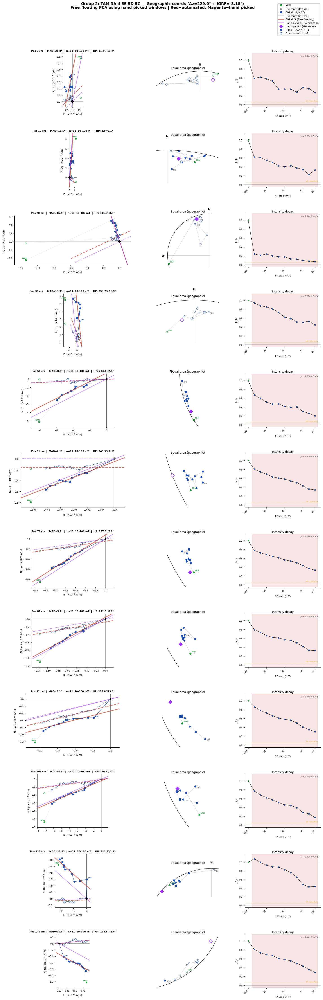

Group 2: TAM 3A 4 5E 5D 5C: 12 specimens plotted

Group 3: TAM 5B 5A 6 7: 118 total, 102 non-foam, 16 in foam, 118 hand-picked PCA  [Az=229.0° + IGRF=-8.18° = geo_rot=220.82°]


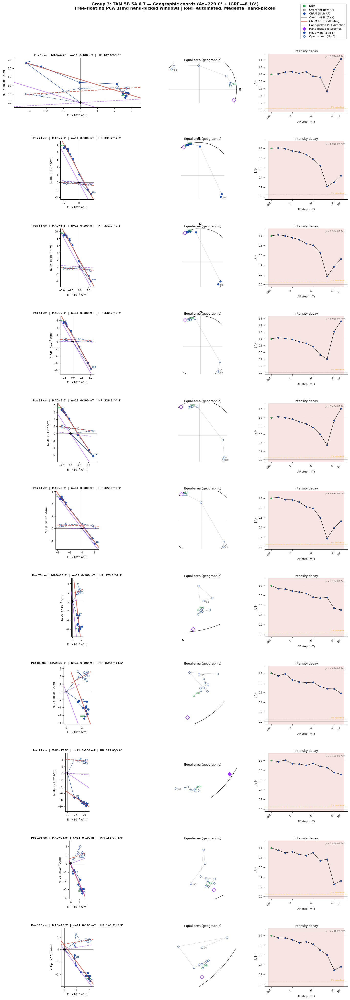

Group 3: TAM 5B 5A 6 7: 11 specimens plotted

Group 1: SC 1C 1B 1A 2 3C: 126 total, 78 non-foam, 48 in foam, 126 hand-picked PCA  [Az=223.0° + IGRF=-8.18° = geo_rot=214.82°]


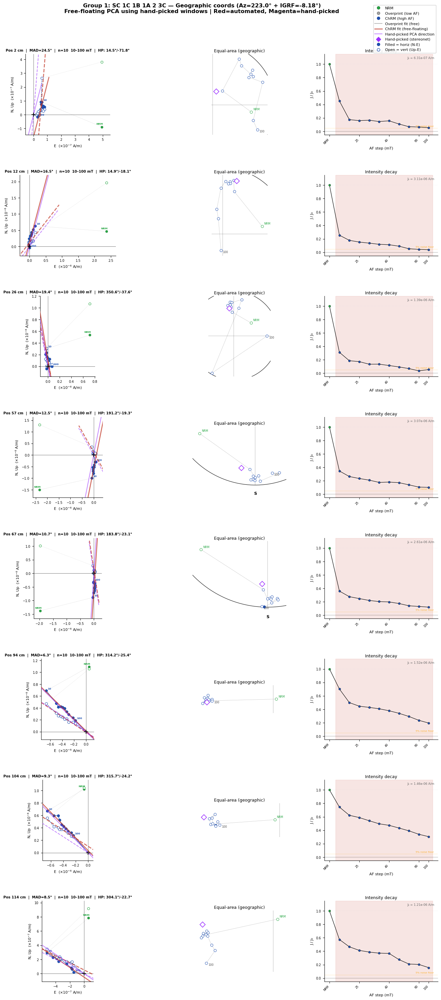

Group 1: SC 1C 1B 1A 2 3C: 8 specimens plotted

Group 2: SC 3B 3A 4D 4C 4B 4A: 139 total, 113 non-foam, 26 in foam, 139 hand-picked PCA  [Az=223.0° + IGRF=-8.18° = geo_rot=214.82°]


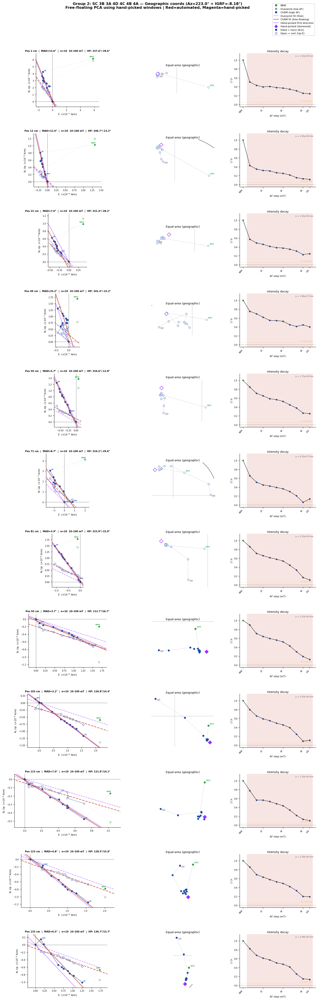

Group 2: SC 3B 3A 4D 4C 4B 4A: 12 specimens plotted

Group 3: SC 5 6 7C 7B 7A: 117 total, 94 non-foam, 23 in foam, 117 hand-picked PCA  [Az=223.0° + IGRF=-8.18° = geo_rot=214.82°]


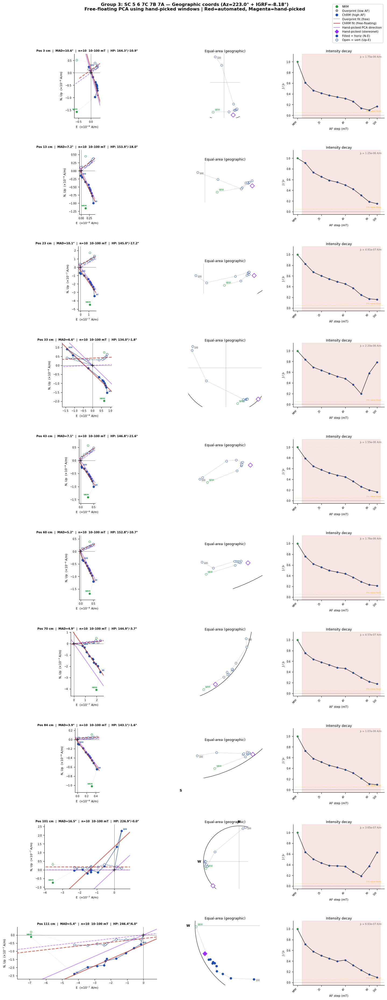

Group 3: SC 5 6 7C 7B 7A: 10 specimens plotted

Group 4: SC 8: 51 total, 27 non-foam, 24 in foam, 51 hand-picked PCA  [Az=223.0° + IGRF=-8.18° = geo_rot=214.82°]


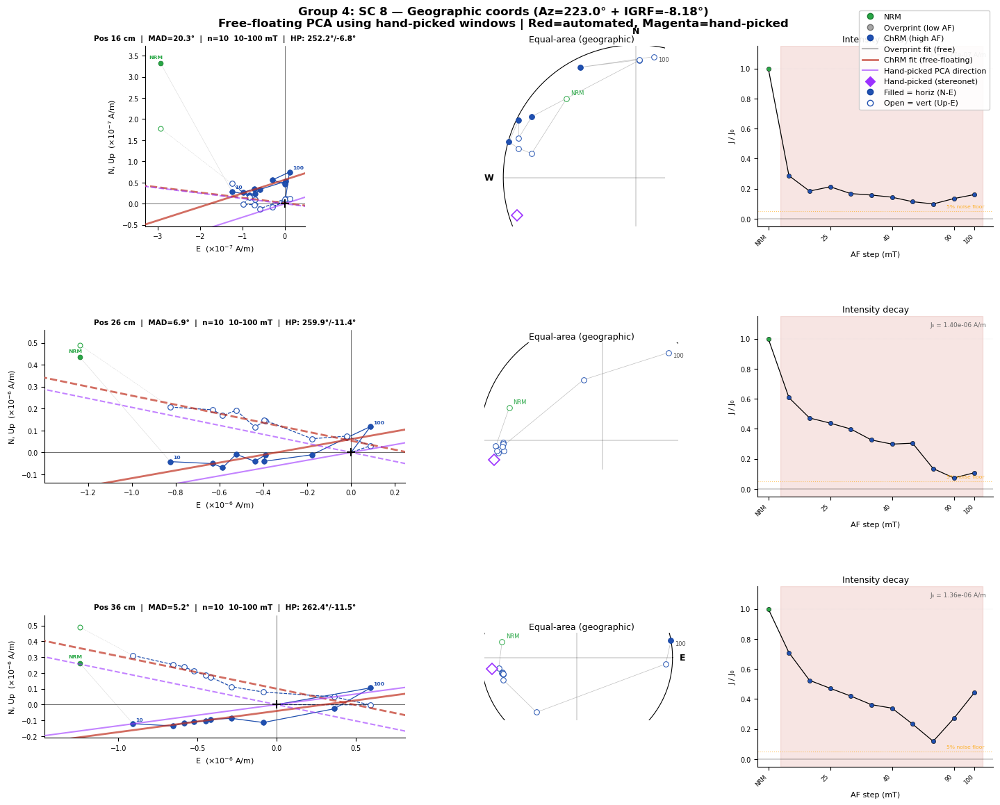

Group 4: SC 8: 3 specimens plotted



In [28]:
"""
Zijderveld diagrams, equal-area stereonets, and J/J₀ intensity decay
with free-floating PCA fits using hand-picked demagnetization windows.
Automated fit (red) vs hand-picked direction (magenta) for comparison.
All directions in GEOGRAPHIC coordinates (core Dec + Azimuth + IGRF).
"""
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from collections import defaultdict
import os

# ── Configuration ─────────────────────────────────────────────────────
BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/2025_Amazon_Miocene_Magnetostratigraphy'
DIR_DIR_Z = os.path.join(BASE_DIR, 'OSU_uchannel_magnetometer_NRM_data',
                         'ucheck_spike_removed', 'dir')
PCA_DIR_Z = os.path.join(DIR_DIR_Z, 'pca')
NOISE_FLOOR = 0.05      # 5% of NRM
MIN_STEPS = 3
STEP_EVERY = 10          # plot every Nth position
IGRF_DEC = -8.18         # IGRF declination correction

# Site azimuths for geographic correction
SITE_AZ = {'TAM': 229.0, 'SC': 223.0}

# ── Foam zones per group ─────────────────────────────────────────────
GROUP_CORES_Z = {
    'Group 2: TAM 3A 4 5E 5D 5C': [
        ('TAM 3A', 36, 0, 0), ('TAM 4', 74, 10, 7),
        ('TAM 5E', 12, 2.5, 2.1), ('TAM 5D', 11, 3, 2), ('TAM 5C', 10, 1.5, 1.5),
    ],
    'Group 3: TAM 5B 5A 6 7': [
        ('TAM 5B', 8.5, 2.5, 2.3), ('TAM 5A', 7.8, 2, 1.5),
        ('TAM 6', 50, 2.1, 2.5), ('TAM 7', 49, 1, 0.5),
    ],
    'Group 1: SC 1C 1B 1A 2 3C': [
        ('SC 1C', 18.5, 1, 1), ('SC 1B', 13, 2.5, 5),
        ('SC 1A', 8, 4, 4), ('SC 2', 50, 7.5, 15.5), ('SC 3C', 34, 1.2, 3.5),
    ],
    'Group 2: SC 3B 3A 4D 4C 4B 4A': [
        ('SC 3B', 27.5, 1.5, 3), ('SC 3A', 9, 3.6, 2.5),
        ('SC 4D', 6.5, 4.5, 7), ('SC 4C', 17, 0.25, 0.5),
        ('SC 4B', 25.2, 1.5, 2), ('SC 4A', 54, 0.5, 3.5),
    ],
    'Group 3: SC 5 6 7C 7B 7A': [
        ('SC 5', 47.5, 2.5, 3.5), ('SC 6', 25, 3, 2),
        ('SC 7C', 14.5, 1.5, 1.5), ('SC 7B', 10, 2, 1.5), ('SC 7A', 20, 1, 2),
    ],
    'Group 4: SC 8': [
        ('SC 8', 51, 15, 8),
    ],
}

def get_foam_zones_z(group_name):
    cores = GROUP_CORES_Z.get(group_name, [])
    if not cores:
        return []
    foam_zones = []
    x_start = 0
    for name, length, foam_above, foam_below in cores:
        if foam_above > 0:
            foam_zones.append((x_start, x_start + foam_above))
        if foam_below > 0:
            foam_zones.append((x_start + length - foam_below, x_start + length))
        x_start += length
    if not foam_zones:
        return []
    foam_zones.sort()
    merged = [foam_zones[0]]
    for start, end in foam_zones[1:]:
        if start <= merged[-1][1] + 0.5:
            merged[-1] = (merged[-1][0], max(merged[-1][1], end))
        else:
            merged.append((start, end))
    return merged

def is_in_foam_z(pos, foam_zones):
    for start, end in foam_zones:
        if start <= pos <= end:
            return True
    return False

# DIR files and their site keys
DIR_FILES_Z = {
    'Group 2: TAM 3A 4 5E 5D 5C':   ('TAM_3A_4_5E_5D_5C_NRM_01192026.NRM.dir', 'TAM'),
    'Group 3: TAM 5B 5A 6 7':        ('TAM_5B_5A_6_7_NRM_01202026.NRM.dir', 'TAM'),
    'Group 1: SC 1C 1B 1A 2 3C':     ('SC_1C_1B_1A_2_3C_NRM_01212026.NRM.dir', 'SC'),
    'Group 2: SC 3B 3A 4D 4C 4B 4A': ('SC_3B_3A_4D_4C_4B_4A_NRM_01202026.NRM.dir', 'SC'),
    'Group 3: SC 5 6 7C 7B 7A':      ('SC_5_6_7C_7B_7A_NRM_01212026.NRM.dir', 'SC'),
    'Group 4: SC 8':                  ('SC_8_NRM_01212026.NRM.dir', 'SC'),
}

# ── Read hand-picked PCA files ───────────────────────────────────────
def read_handpicked_pca(sample_id):
    """Read hand-picked PCA file → dict of position → {Decl, Incl, MAD, Demag_Start, Demag_End}.
    Decl/Incl are in raw core-frame coordinates (no corrections applied)."""
    pca_file = os.path.join(PCA_DIR_Z, f'PCA - {sample_id} (100-1000).txt')
    if not os.path.exists(pca_file):
        return {}
    hp = {}
    with open(pca_file) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('Sample'):
                continue
            parts = line.split()
            if len(parts) >= 8:
                try:
                    pos = float(parts[1])
                    hp[pos] = {
                        'Decl': float(parts[2]),
                        'Incl': float(parts[3]),
                        'MAD': float(parts[4]),
                        'Demag_Start': int(parts[5]),
                        'Demag_End': int(parts[6]),
                    }
                except (ValueError, IndexError):
                    continue
    return hp


def read_dir_z(filepath, geo_rot=0.0):
    """Read DIR file → dict of position → list of step dicts.
    geo_rot (azimuth + IGRF) is added to declinations for geographic coords."""
    pos_steps = defaultdict(list)
    with open(filepath) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('-') or line.startswith('POSITION') or '(' in line:
                continue
            parts = line.split()
            if len(parts) >= 8:
                try:
                    pos_steps[float(parts[0])].append({
                        'treat': int(parts[1]),
                        'J': float(parts[4]),
                        'Decl': (float(parts[5]) + geo_rot) % 360,
                        'Incl': float(parts[6]),
                    })
                except (ValueError, IndexError):
                    continue
    return pos_steps


def dir2cart(dec, inc, R=1.0):
    d, i = np.radians(dec), np.radians(inc)
    return R * np.cos(i) * np.cos(d), R * np.cos(i) * np.sin(d), R * np.sin(i)


def equal_area_xy(dec, inc):
    d = np.radians(np.asarray(dec, float))
    i = np.radians(np.asarray(inc, float))
    R = np.sqrt(2.0) * np.sin((np.pi / 2 - np.abs(i)) / 2.0)
    return R * np.sin(d), R * np.cos(d)


def despine(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def pca_free(xs, ys, zs):
    """Free-floating PCA → (centroid, unit_vector, MAD)."""
    data = np.column_stack([xs, ys, zs])
    centroid = data.mean(axis=0)
    centered = data - centroid
    U, S, Vt = np.linalg.svd(centered, full_matrices=False)
    v1 = Vt[0]
    if np.dot(v1, centroid) < 0:
        v1 = -v1
    s2 = S[1]**2 if len(S) > 1 else 0
    s3 = S[2]**2 if len(S) > 2 else 0
    mad = np.rad2deg(np.arctan2(np.sqrt(s2 + s3), S[0]))
    return centroid, v1, mad


def get_chrm_indices(treats, demag_start, demag_end):
    """Get indices for ChRM window matching hand-picked Demag_Start/End."""
    mask = (treats >= demag_start) & (treats <= demag_end)
    return np.where(mask)[0]


# ── Zijderveld diagram ───────────────────────────────────────────────
def plot_zij(ax, steps, position, hp_info=None, geo_rot=0.0):
    """Zijderveld with free-floating PCA fit (red) using hand-picked window.
    Magenta line = hand-picked PCA direction for comparison.
    geo_rot is applied to hand-picked Decl (which is in raw core-frame)."""
    steps = sorted(steps, key=lambda s: s['treat'])
    treats = np.array([s['treat'] for s in steps])
    js     = np.array([s['J'] for s in steps])
    decs   = np.array([s['Decl'] for s in steps])  # already geographic
    incs   = np.array([s['Incl'] for s in steps])

    cart = np.array([dir2cart(d, i, m) for d, i, m in zip(decs, incs, js)])
    N_arr, E_arr, D_arr = cart[:, 0], cart[:, 1], cart[:, 2]

    maxval = max(np.max(np.abs(E_arr)), np.max(np.abs(N_arr)),
                 np.max(np.abs(D_arr)), 1e-20)
    exp = int(np.floor(np.log10(maxval)))
    scl = 10 ** (-exp)
    Es, Ns, Ds = E_arr * scl, N_arr * scl, D_arr * scl

    # Determine ChRM window from hand-picked data
    chrm_mask = np.zeros(len(steps), dtype=bool)
    chrm_mad = 90.0
    demag_start, demag_end = 100, 1000
    if hp_info is not None:
        demag_start = hp_info['Demag_Start']
        demag_end = hp_info['Demag_End']
    chrm_idxs = get_chrm_indices(treats, demag_start, demag_end)
    if len(chrm_idxs) >= MIN_STEPS:
        chrm_mask[chrm_idxs] = True

    nrm_mask = treats == 0
    overprint_mask = ~chrm_mask & ~nrm_mask

    # Full trace
    ax.plot(np.append(Es, 0.0), np.append(Ns, 0.0), '-', color='0.85', lw=0.4, zorder=0)
    ax.plot(np.append(Es, 0.0), np.append(-Ds, 0.0), '--', color='0.85', lw=0.4, zorder=0)

    # NRM (green)
    if nrm_mask.any():
        ax.plot(Es[nrm_mask], Ns[nrm_mask], 'o', ms=5, mfc='#28a745',
                mec='#1a7a30', mew=0.5, zorder=3)
        ax.plot(Es[nrm_mask], -Ds[nrm_mask], 'o', ms=5, mfc='white',
                mec='#28a745', mew=0.8, zorder=3)
        ax.annotate('NRM', (Es[nrm_mask][0], Ns[nrm_mask][0]),
                    fontsize=5.5, color='#28a745', fontweight='bold',
                    xytext=(-12, 5), textcoords='offset points')

    # Overprint (grey)
    if overprint_mask.any():
        oi = np.where(overprint_mask)[0]
        ax.plot(Es[oi], Ns[oi], 'o', ms=4.5, mfc='0.65', mec='0.45', mew=0.5, zorder=2)
        ax.plot(Es[oi], -Ds[oi], 'o', ms=4.5, mfc='white', mec='0.55', mew=0.7, zorder=2)
        op_with_nrm = np.sort(np.concatenate([np.where(nrm_mask)[0], oi]))
        ax.plot(Es[op_with_nrm], Ns[op_with_nrm], '-', color='0.7', lw=0.7, zorder=1)
        ax.plot(Es[op_with_nrm], -Ds[op_with_nrm], '--', color='0.7', lw=0.7, zorder=1)

    # ChRM (blue)
    if chrm_mask.any():
        ci = np.where(chrm_mask)[0]
        ax.plot(np.append(Es[ci], 0.0), np.append(Ns[ci], 0.0), '-',
                color='#2050B0', lw=0.9, zorder=1)
        ax.plot(Es[ci], Ns[ci], 'o', ms=5.5, mfc='#2050B0', mec='#1040A0', mew=0.5, zorder=3)
        ax.plot(np.append(Es[ci], 0.0), np.append(-Ds[ci], 0.0), '--',
                color='#2050B0', lw=0.9, zorder=1)
        ax.plot(Es[ci], -Ds[ci], 'o', ms=5.5, mfc='white', mec='#2050B0', mew=0.8, zorder=3)

    ax.plot(0, 0, '+', ms=8, mew=1.5, color='k', zorder=5)

    # Overprint fit (grey, free-floating)
    overprint_plus_nrm = np.where(overprint_mask | nrm_mask)[0]
    if len(overprint_plus_nrm) >= 2:
        centroid, v1, _ = pca_free(
            N_arr[overprint_plus_nrm], E_arr[overprint_plus_nrm], D_arr[overprint_plus_nrm])
        t_rng = np.linspace(-1.5 * maxval, 1.5 * maxval, 2)
        pca_pts = centroid[:, None] + v1[:, None] * t_rng[None, :]
        ax.plot(pca_pts[1] * scl, pca_pts[0] * scl, '-',
                color='0.55', lw=1.5, alpha=0.6, zorder=4)
        ax.plot(pca_pts[1] * scl, -pca_pts[2] * scl, '--',
                color='0.55', lw=1.5, alpha=0.6, zorder=4)

    # ChRM fit (red, free-floating) using hand-picked window
    if len(chrm_idxs) >= MIN_STEPS:
        centroid, v1, chrm_mad = pca_free(
            N_arr[chrm_idxs], E_arr[chrm_idxs], D_arr[chrm_idxs])
        t_rng = np.linspace(-1.5 * maxval, 1.5 * maxval, 2)
        pca_pts = centroid[:, None] + v1[:, None] * t_rng[None, :]
        ax.plot(pca_pts[1] * scl, pca_pts[0] * scl, '-',
                color='#C03020', lw=2.0, alpha=0.7, zorder=4)
        ax.plot(pca_pts[1] * scl, -pca_pts[2] * scl, '--',
                color='#C03020', lw=2.0, alpha=0.7, zorder=4)

    # Hand-picked PCA direction (magenta)
    # Hand-picked Decl is core-frame → add full geo_rot (azimuth + IGRF)
    if hp_info is not None:
        hp_dec_geo = hp_info['Decl'] + geo_rot
        hp_inc = hp_info['Incl']
        hp_n, hp_e, hp_d = dir2cart(hp_dec_geo, hp_inc, 1.0)
        t_rng = np.linspace(-1.5 * maxval, 1.5 * maxval, 2)
        ax.plot([hp_e * t_rng[0] * scl, hp_e * t_rng[1] * scl],
                [hp_n * t_rng[0] * scl, hp_n * t_rng[1] * scl],
                '-', color='#9B30FF', lw=1.5, alpha=0.6, zorder=4)
        ax.plot([hp_e * t_rng[0] * scl, hp_e * t_rng[1] * scl],
                [-hp_d * t_rng[0] * scl, -hp_d * t_rng[1] * scl],
                '--', color='#9B30FF', lw=1.5, alpha=0.6, zorder=4)

    # Step labels
    if chrm_mask.any():
        ci = np.where(chrm_mask)[0]
        for k in [ci[0], ci[-1]]:
            af_mt = treats[k] / 10
            ax.annotate(f'{af_mt:.0f}', (Es[k], Ns[k]),
                        fontsize=5.5, color='#2050B0', fontweight='bold',
                        xytext=(3, 3), textcoords='offset points')

    # Crop to data extent (include origin + all points + padding)
    all_x = np.concatenate([Es, [0.0]])
    all_y = np.concatenate([Ns, -Ds, [0.0]])
    pad_frac = 0.12
    x_range = max(np.ptp(all_x), 0.1)
    y_range = max(np.ptp(all_y), 0.1)
    ax.set_xlim(np.min(all_x) - pad_frac * x_range, np.max(all_x) + pad_frac * x_range)
    ax.set_ylim(np.min(all_y) - pad_frac * y_range, np.max(all_y) + pad_frac * y_range)

    ax.axhline(0, color='k', lw=0.4)
    ax.axvline(0, color='k', lw=0.4)
    ax.set_aspect('equal')
    ax.tick_params(labelsize=7)
    ax.set_xlabel(f'E  (×10$^{{{exp}}}$ A/m)', fontsize=8)
    ax.set_ylabel(f'N, Up  (×10$^{{{exp}}}$ A/m)', fontsize=8)
    despine(ax)

    n_chrm = int(chrm_mask.sum())
    treat_info = f'{demag_start/10:.0f}–{demag_end/10:.0f} mT'
    hp_tag = ''
    if hp_info is not None:
        hp_dec_disp = (hp_info['Decl'] + geo_rot) % 360
        hp_tag = f'  |  HP: {hp_dec_disp:.1f}°/{hp_info["Incl"]:.1f}°'
    ax.set_title(f'Pos {position:.0f} cm  |  MAD={chrm_mad:.1f}°  |  '
                 f'n={n_chrm}  {treat_info}{hp_tag}',
                 fontsize=7.5, fontweight='bold', pad=6)
    return chrm_mad


# ── Equal-area stereonet ──────────────────────────────────────────────
def plot_eqa(ax, steps, hp_info=None, geo_rot=0.0):
    """Stereonet with hand-picked direction (magenta diamond) overlay."""
    steps = sorted(steps, key=lambda s: s['treat'])
    treats = np.array([s['treat'] for s in steps])
    decs = np.array([s['Decl'] for s in steps])
    incs = np.array([s['Incl'] for s in steps])
    x, y = equal_area_xy(decs, incs)

    demag_start, demag_end = 100, 1000
    if hp_info is not None:
        demag_start = hp_info['Demag_Start']
        demag_end = hp_info['Demag_End']
    chrm_idxs = get_chrm_indices(treats, demag_start, demag_end)
    chrm_mask = np.zeros(len(steps), dtype=bool)
    if len(chrm_idxs) >= MIN_STEPS:
        chrm_mask[chrm_idxs] = True

    pad = 0.08
    xmin, xmax = np.min(x) - pad, np.max(x) + pad
    ymin, ymax = np.min(y) - pad, np.max(y) + pad

    theta = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(theta), np.sin(theta), 'k-', lw=0.8)
    ax.plot([-1, 1], [0, 0], 'k-', lw=0.2)
    ax.plot([0, 0], [-1, 1], 'k-', lw=0.2)
    ax.plot(x, y, '-', color='0.75', lw=0.5, zorder=1)

    for k in range(len(steps)):
        is_lower = incs[k] >= 0
        if treats[k] == 0:
            fc = '#28a745' if is_lower else 'white'
            ec = '#1a7a30' if is_lower else '#28a745'
        elif chrm_mask[k]:
            fc = '#2050B0' if is_lower else 'white'
            ec = '#1040A0' if is_lower else '#2050B0'
        else:
            fc = '0.7' if is_lower else 'white'
            ec = '0.5'
        ax.plot(x[k], y[k], 'o', ms=5.5, mfc=fc, mec=ec, mew=0.7, zorder=3)

    if len(steps) > 0:
        ax.annotate('NRM', (x[0], y[0]), fontsize=6, color='#28a745',
                    xytext=(4, 4), textcoords='offset points')
        ax.annotate(f'{treats[-1]/10:.0f}', (x[-1], y[-1]), fontsize=6,
                    color='0.3', xytext=(4, -5), textcoords='offset points')

    # Hand-picked direction (magenta diamond)
    if hp_info is not None:
        hp_dec_geo = hp_info['Decl'] + geo_rot
        hp_inc = hp_info['Incl']
        hx, hy = equal_area_xy(hp_dec_geo, hp_inc)
        is_lower = hp_inc >= 0
        fc_hp = '#9B30FF' if is_lower else 'white'
        ax.plot(hx, hy, 'D', ms=8, mfc=fc_hp, mec='#9B30FF', mew=1.2, zorder=5)
        xmin = min(xmin, float(hx) - pad)
        xmax = max(xmax, float(hx) + pad)
        ymin = min(ymin, float(hy) - pad)
        ymax = max(ymax, float(hy) + pad)

    for lbl, (px, py, ha, va) in {'N': (0, 1.07, 'center', 'bottom'),
                                   'S': (0, -1.07, 'center', 'top'),
                                   'E': (1.07, 0, 'left', 'center'),
                                   'W': (-1.07, 0, 'right', 'center')}.items():
        if xmin - 0.1 <= px <= xmax + 0.1 and ymin - 0.1 <= py <= ymax + 0.1:
            ax.text(px, py, lbl, ha=ha, va=va, fontsize=9, fontweight='bold')

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title('Equal-area (geographic)', fontsize=9, pad=4)


# ── J/J₀ intensity decay ─────────────────────────────────────────────
def plot_jj0(ax, steps, hp_info=None):
    """J/J₀ with ChRM window highlighted."""
    steps = sorted(steps, key=lambda s: s['treat'])
    treats = np.array([s['treat'] for s in steps])
    moms = np.array([s['J'] for s in steps])
    j0 = moms[0] if moms[0] > 0 else 1e-20
    jjo = moms / j0
    xs = np.arange(len(steps))

    demag_start, demag_end = 100, 1000
    if hp_info is not None:
        demag_start = hp_info['Demag_Start']
        demag_end = hp_info['Demag_End']
    chrm_idxs = get_chrm_indices(treats, demag_start, demag_end)

    if len(chrm_idxs) >= MIN_STEPS:
        ax.axvspan(chrm_idxs[0] - 0.4, chrm_idxs[-1] + 0.4,
                   alpha=0.12, color='#C03020', zorder=0)

    ax.axhline(NOISE_FLOOR, color='orange', lw=0.8, ls=':', alpha=0.6)
    ax.text(len(steps) - 0.5, NOISE_FLOOR + 0.02, '5% noise floor',
            fontsize=5.5, ha='right', color='orange', alpha=0.8)

    chrm_set = set(chrm_idxs)
    for k in range(len(steps)):
        if treats[k] == 0:
            fc = '#28a745'
        elif k in chrm_set:
            fc = '#2050B0'
        else:
            fc = '0.6'
        ax.plot(xs[k], jjo[k], 'o', ms=4.5, mfc=fc, mec='k', mew=0.4, zorder=3)
    ax.plot(xs, jjo, '-', color='k', lw=0.9, zorder=2)

    ymax = max(1.15, np.max(jjo) * 1.1)
    ax.set_ylim(-0.05, ymax)
    ax.axhline(0, color='k', lw=0.25)
    ax.axhline(1, color='0.85', lw=0.3, ls=':')
    ax.set_ylabel('J / J₀', fontsize=8)
    ax.tick_params(labelsize=7)
    despine(ax)

    labels = [f'{treats[k]/10:.0f}' if treats[k] > 0 else 'NRM'
              for k in range(len(steps))]
    show = sorted(set(list(range(0, len(xs), 3)) + [len(xs) - 1]))
    ax.set_xticks([xs[k] for k in show])
    ax.set_xticklabels([labels[k] for k in show],
                       fontsize=6, rotation=45, ha='right')
    ax.set_xlabel('AF step (mT)', fontsize=8)

    ax.text(0.97, 0.97, f'J₀ = {j0:.2e} A/m', transform=ax.transAxes,
            fontsize=6.5, ha='right', va='top', color='0.4')
    ax.set_title('Intensity decay', fontsize=9, pad=4)


# ══════════════════════════════════════════════════════════════════════
#  Generate figures for each group
# ══════════════════════════════════════════════════════════════════════
for group_name, (dir_fname, site_key) in DIR_FILES_Z.items():
    dir_path = os.path.join(DIR_DIR_Z, dir_fname)
    if not os.path.exists(dir_path):
        print(f'Missing: {dir_path}')
        continue

    azimuth = SITE_AZ[site_key]
    geo_rot = azimuth + IGRF_DEC

    pos_steps = read_dir_z(dir_path, geo_rot=geo_rot)
    if not pos_steps:
        print(f'No data: {group_name}')
        continue

    # Load hand-picked PCA (raw core-frame declinations)
    sample_id = dir_fname.replace('.NRM.dir', '')
    hp_pca = read_handpicked_pca(sample_id)
    n_hp = len(hp_pca)

    # Foam filter
    foam_zones = get_foam_zones_z(group_name)
    positions = sorted(pos_steps.keys())
    viable_positions = [p for p in positions if not is_in_foam_z(p, foam_zones)]
    print(f'{group_name}: {len(positions)} total, {len(viable_positions)} non-foam, '
          f'{len(positions)-len(viable_positions)} in foam, {n_hp} hand-picked PCA  '
          f'[Az={azimuth}° + IGRF={IGRF_DEC}° = geo_rot={geo_rot:.2f}°]')

    selected = viable_positions[::STEP_EVERY]
    n_sel = len(selected)
    if n_sel == 0:
        continue

    fig = plt.figure(figsize=(15, 3.8 * n_sel))
    gs = gridspec.GridSpec(
        n_sel, 3, figure=fig,
        width_ratios=[1.3, 0.7, 0.85],
        hspace=0.50, wspace=0.30,
        left=0.06, right=0.97, top=0.94, bottom=0.03)

    for idx, pos in enumerate(selected):
        s = sorted(pos_steps[pos], key=lambda x: x['treat'])
        hp_info = hp_pca.get(pos, None)

        ax_z = fig.add_subplot(gs[idx, 0])
        plot_zij(ax_z, s, pos, hp_info=hp_info, geo_rot=geo_rot)

        ax_e = fig.add_subplot(gs[idx, 1])
        plot_eqa(ax_e, s, hp_info=hp_info, geo_rot=geo_rot)

        ax_j = fig.add_subplot(gs[idx, 2])
        plot_jj0(ax_j, s, hp_info=hp_info)

    legend_handles = [
        Line2D([0], [0], marker='o', color='w', mfc='#28a745',
               mec='#1a7a30', ms=6, label='NRM'),
        Line2D([0], [0], marker='o', color='w', mfc='0.65',
               mec='0.45', ms=6, label='Overprint (low AF)'),
        Line2D([0], [0], marker='o', color='w', mfc='#2050B0',
               mec='#1040A0', ms=6, label='ChRM (high AF)'),
        Line2D([0], [0], color='0.55', lw=1.5, alpha=0.6,
               label='Overprint fit (free)'),
        Line2D([0], [0], color='#C03020', lw=2.0, alpha=0.7,
               label='ChRM fit (free-floating)'),
        Line2D([0], [0], color='#9B30FF', lw=1.5, alpha=0.6,
               label='Hand-picked PCA direction'),
        Line2D([0], [0], marker='D', color='w', mfc='#9B30FF',
               mec='#9B30FF', ms=7, label='Hand-picked (stereonet)'),
        Line2D([0], [0], marker='o', color='w', mfc='#2050B0',
               mec='#1040A0', ms=6, lw=0, label='Filled = horiz (N-E)'),
        Line2D([0], [0], marker='o', color='w', mfc='white',
               mec='#2050B0', ms=6, lw=0, label='Open = vert (Up-E)'),
    ]
    fig.legend(handles=legend_handles, loc='upper right', fontsize=8,
               framealpha=0.9, bbox_to_anchor=(0.97, 0.99), ncol=1)

    fig.suptitle(f'{group_name} — Geographic coords (Az={azimuth}° + IGRF={IGRF_DEC}°)\n'
                 f'Free-floating PCA using hand-picked windows | Red=automated, Magenta=hand-picked',
                 fontsize=12, fontweight='bold', y=0.99)
    plt.show()
    print(f'{group_name}: {n_sel} specimens plotted\n')

## Hand picked PCAs

Group 2: TAM 3A 4 5E 5D 5C: 12 hand-picked specimens to plot  [Az=229.0° + IGRF=-8.18° = geo_rot=220.82°]


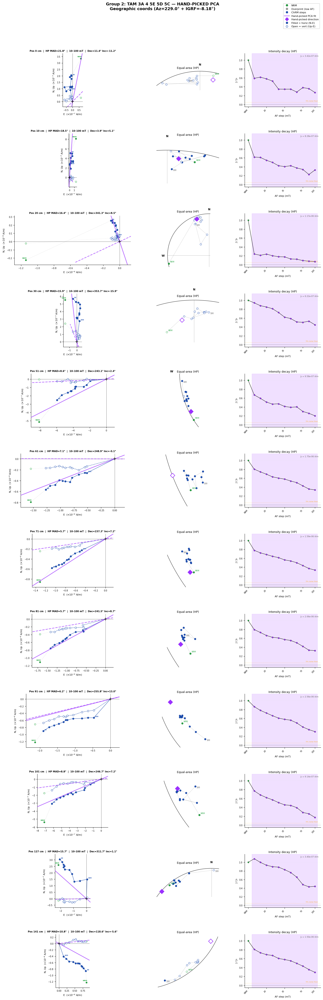


Group 3: TAM 5B 5A 6 7: 11 hand-picked specimens to plot  [Az=229.0° + IGRF=-8.18° = geo_rot=220.82°]


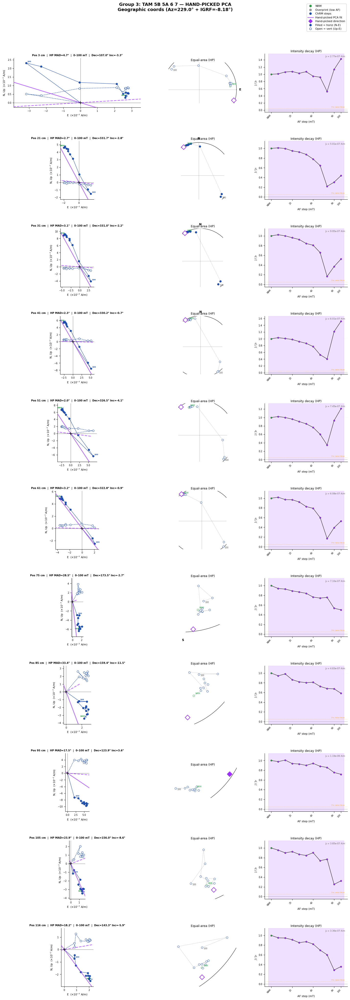


Group 1: SC 1C 1B 1A 2 3C: 8 hand-picked specimens to plot  [Az=223.0° + IGRF=-8.18° = geo_rot=214.82°]


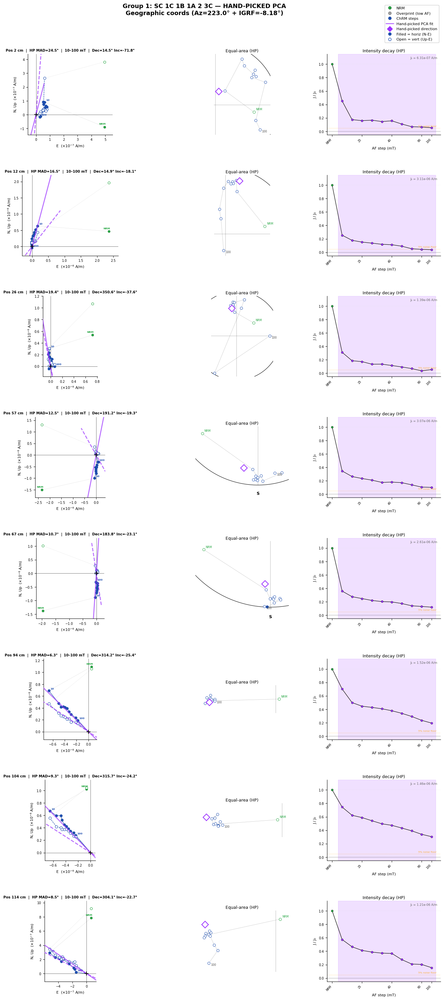


Group 2: SC 3B 3A 4D 4C 4B 4A: 12 hand-picked specimens to plot  [Az=223.0° + IGRF=-8.18° = geo_rot=214.82°]


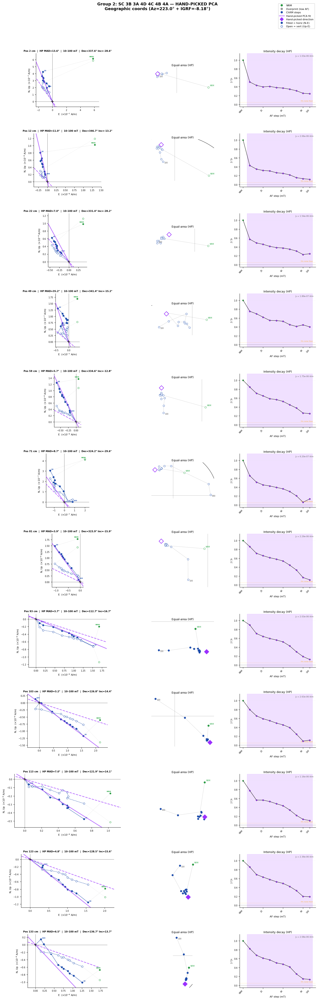


Group 3: SC 5 6 7C 7B 7A: 10 hand-picked specimens to plot  [Az=223.0° + IGRF=-8.18° = geo_rot=214.82°]


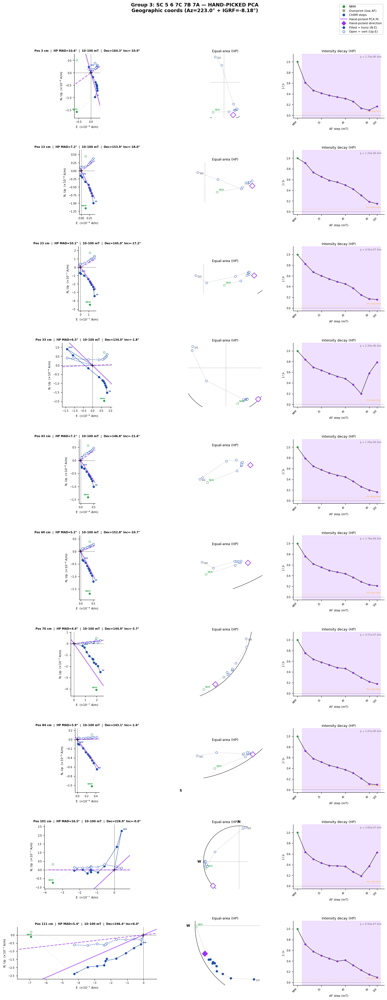


Group 4: SC 8: 3 hand-picked specimens to plot  [Az=223.0° + IGRF=-8.18° = geo_rot=214.82°]


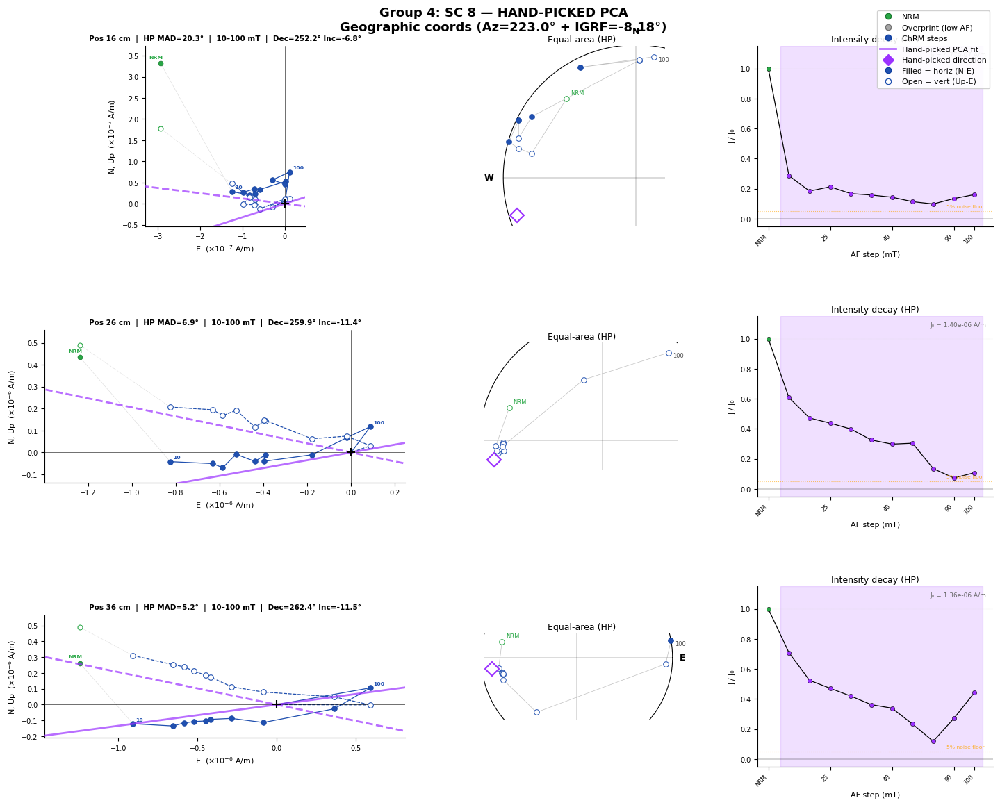

In [29]:
"""
Hand-picked PCA only — Zijderveld diagrams, stereonets, and J/J₀.
Same DIR data as above but showing only the hand-picked PCA direction
(magenta fit line) with no automated PCA for clean visual comparison.
All functions (read_dir_z, read_handpicked_pca, etc.) are defined in cell above.
"""

# ── Zijderveld (hand-picked only) ────────────────────────────────────
def plot_zij_hp(ax, steps, position, hp_info, geo_rot):
    """Zijderveld showing only hand-picked PCA direction (magenta)."""
    steps = sorted(steps, key=lambda s: s['treat'])
    treats = np.array([s['treat'] for s in steps])
    js     = np.array([s['J'] for s in steps])
    decs   = np.array([s['Decl'] for s in steps])
    incs   = np.array([s['Incl'] for s in steps])

    cart = np.array([dir2cart(d, i, m) for d, i, m in zip(decs, incs, js)])
    N_arr, E_arr, D_arr = cart[:, 0], cart[:, 1], cart[:, 2]

    maxval = max(np.max(np.abs(E_arr)), np.max(np.abs(N_arr)),
                 np.max(np.abs(D_arr)), 1e-20)
    exp = int(np.floor(np.log10(maxval)))
    scl = 10 ** (-exp)
    Es, Ns, Ds = E_arr * scl, N_arr * scl, D_arr * scl

    demag_start = hp_info['Demag_Start']
    demag_end = hp_info['Demag_End']
    chrm_idxs = get_chrm_indices(treats, demag_start, demag_end)
    chrm_mask = np.zeros(len(steps), dtype=bool)
    if len(chrm_idxs) >= MIN_STEPS:
        chrm_mask[chrm_idxs] = True

    nrm_mask = treats == 0
    overprint_mask = ~chrm_mask & ~nrm_mask

    # Full trace
    ax.plot(np.append(Es, 0.0), np.append(Ns, 0.0), '-', color='0.85', lw=0.4, zorder=0)
    ax.plot(np.append(Es, 0.0), np.append(-Ds, 0.0), '--', color='0.85', lw=0.4, zorder=0)

    # NRM (green)
    if nrm_mask.any():
        ax.plot(Es[nrm_mask], Ns[nrm_mask], 'o', ms=5, mfc='#28a745',
                mec='#1a7a30', mew=0.5, zorder=3)
        ax.plot(Es[nrm_mask], -Ds[nrm_mask], 'o', ms=5, mfc='white',
                mec='#28a745', mew=0.8, zorder=3)
        ax.annotate('NRM', (Es[nrm_mask][0], Ns[nrm_mask][0]),
                    fontsize=5.5, color='#28a745', fontweight='bold',
                    xytext=(-12, 5), textcoords='offset points')

    # Overprint (grey)
    if overprint_mask.any():
        oi = np.where(overprint_mask)[0]
        ax.plot(Es[oi], Ns[oi], 'o', ms=4.5, mfc='0.65', mec='0.45', mew=0.5, zorder=2)
        ax.plot(Es[oi], -Ds[oi], 'o', ms=4.5, mfc='white', mec='0.55', mew=0.7, zorder=2)
        op_with_nrm = np.sort(np.concatenate([np.where(nrm_mask)[0], oi]))
        ax.plot(Es[op_with_nrm], Ns[op_with_nrm], '-', color='0.7', lw=0.7, zorder=1)
        ax.plot(Es[op_with_nrm], -Ds[op_with_nrm], '--', color='0.7', lw=0.7, zorder=1)

    # ChRM (blue)
    if chrm_mask.any():
        ci = np.where(chrm_mask)[0]
        ax.plot(np.append(Es[ci], 0.0), np.append(Ns[ci], 0.0), '-',
                color='#2050B0', lw=0.9, zorder=1)
        ax.plot(Es[ci], Ns[ci], 'o', ms=5.5, mfc='#2050B0', mec='#1040A0', mew=0.5, zorder=3)
        ax.plot(np.append(Es[ci], 0.0), np.append(-Ds[ci], 0.0), '--',
                color='#2050B0', lw=0.9, zorder=1)
        ax.plot(Es[ci], -Ds[ci], 'o', ms=5.5, mfc='white', mec='#2050B0', mew=0.8, zorder=3)

    ax.plot(0, 0, '+', ms=8, mew=1.5, color='k', zorder=5)

    # Hand-picked PCA direction ONLY (magenta, thicker)
    hp_dec_geo = hp_info['Decl'] + geo_rot
    hp_inc = hp_info['Incl']
    hp_n, hp_e, hp_d = dir2cart(hp_dec_geo, hp_inc, 1.0)
    t_rng = np.linspace(-1.5 * maxval, 1.5 * maxval, 2)
    ax.plot([hp_e * t_rng[0] * scl, hp_e * t_rng[1] * scl],
            [hp_n * t_rng[0] * scl, hp_n * t_rng[1] * scl],
            '-', color='#9B30FF', lw=2.0, alpha=0.7, zorder=4)
    ax.plot([hp_e * t_rng[0] * scl, hp_e * t_rng[1] * scl],
            [-hp_d * t_rng[0] * scl, -hp_d * t_rng[1] * scl],
            '--', color='#9B30FF', lw=2.0, alpha=0.7, zorder=4)

    # Step labels
    if chrm_mask.any():
        ci = np.where(chrm_mask)[0]
        for k in [ci[0], ci[-1]]:
            af_mt = treats[k] / 10
            ax.annotate(f'{af_mt:.0f}', (Es[k], Ns[k]),
                        fontsize=5.5, color='#2050B0', fontweight='bold',
                        xytext=(3, 3), textcoords='offset points')

    # Crop to data extent (include origin + all points + padding)
    all_x = np.concatenate([Es, [0.0]])
    all_y = np.concatenate([Ns, -Ds, [0.0]])
    pad_frac = 0.12
    x_range = max(np.ptp(all_x), 0.1)
    y_range = max(np.ptp(all_y), 0.1)
    ax.set_xlim(np.min(all_x) - pad_frac * x_range, np.max(all_x) + pad_frac * x_range)
    ax.set_ylim(np.min(all_y) - pad_frac * y_range, np.max(all_y) + pad_frac * y_range)

    ax.axhline(0, color='k', lw=0.4)
    ax.axvline(0, color='k', lw=0.4)
    ax.set_aspect('equal')
    ax.tick_params(labelsize=7)
    ax.set_xlabel(f'E  (×10$^{{{exp}}}$ A/m)', fontsize=8)
    ax.set_ylabel(f'N, Up  (×10$^{{{exp}}}$ A/m)', fontsize=8)
    despine(ax)

    hp_dec_disp = (hp_info['Decl'] + geo_rot) % 360
    treat_info = f'{demag_start/10:.0f}–{demag_end/10:.0f} mT'
    ax.set_title(f'Pos {position:.0f} cm  |  HP MAD={hp_info["MAD"]:.1f}°  |  '
                 f'{treat_info}  |  Dec={hp_dec_disp:.1f}° Inc={hp_info["Incl"]:.1f}°',
                 fontsize=7.5, fontweight='bold', pad=6)


# ── Stereonet (hand-picked only) ─────────────────────────────────────
def plot_eqa_hp(ax, steps, hp_info, geo_rot):
    """Stereonet with hand-picked direction as prominent magenta diamond."""
    steps = sorted(steps, key=lambda s: s['treat'])
    treats = np.array([s['treat'] for s in steps])
    decs = np.array([s['Decl'] for s in steps])
    incs = np.array([s['Incl'] for s in steps])
    x, y = equal_area_xy(decs, incs)

    demag_start = hp_info['Demag_Start']
    demag_end = hp_info['Demag_End']
    chrm_idxs = get_chrm_indices(treats, demag_start, demag_end)
    chrm_mask = np.zeros(len(steps), dtype=bool)
    if len(chrm_idxs) >= MIN_STEPS:
        chrm_mask[chrm_idxs] = True

    pad = 0.08
    xmin, xmax = np.min(x) - pad, np.max(x) + pad
    ymin, ymax = np.min(y) - pad, np.max(y) + pad

    theta = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(theta), np.sin(theta), 'k-', lw=0.8)
    ax.plot([-1, 1], [0, 0], 'k-', lw=0.2)
    ax.plot([0, 0], [-1, 1], 'k-', lw=0.2)
    ax.plot(x, y, '-', color='0.75', lw=0.5, zorder=1)

    for k in range(len(steps)):
        is_lower = incs[k] >= 0
        if treats[k] == 0:
            fc = '#28a745' if is_lower else 'white'
            ec = '#1a7a30' if is_lower else '#28a745'
        elif chrm_mask[k]:
            fc = '#2050B0' if is_lower else 'white'
            ec = '#1040A0' if is_lower else '#2050B0'
        else:
            fc = '0.7' if is_lower else 'white'
            ec = '0.5'
        ax.plot(x[k], y[k], 'o', ms=5.5, mfc=fc, mec=ec, mew=0.7, zorder=3)

    if len(steps) > 0:
        ax.annotate('NRM', (x[0], y[0]), fontsize=6, color='#28a745',
                    xytext=(4, 4), textcoords='offset points')
        ax.annotate(f'{treats[-1]/10:.0f}', (x[-1], y[-1]), fontsize=6,
                    color='0.3', xytext=(4, -5), textcoords='offset points')

    # Hand-picked direction (magenta diamond, larger)
    hp_dec_geo = hp_info['Decl'] + geo_rot
    hp_inc = hp_info['Incl']
    hx, hy = equal_area_xy(hp_dec_geo, hp_inc)
    is_lower = hp_inc >= 0
    fc_hp = '#9B30FF' if is_lower else 'white'
    ax.plot(hx, hy, 'D', ms=10, mfc=fc_hp, mec='#9B30FF', mew=1.5, zorder=5)
    xmin = min(xmin, float(hx) - pad)
    xmax = max(xmax, float(hx) + pad)
    ymin = min(ymin, float(hy) - pad)
    ymax = max(ymax, float(hy) + pad)

    for lbl, (px, py, ha, va) in {'N': (0, 1.07, 'center', 'bottom'),
                                   'S': (0, -1.07, 'center', 'top'),
                                   'E': (1.07, 0, 'left', 'center'),
                                   'W': (-1.07, 0, 'right', 'center')}.items():
        if xmin - 0.1 <= px <= xmax + 0.1 and ymin - 0.1 <= py <= ymax + 0.1:
            ax.text(px, py, lbl, ha=ha, va=va, fontsize=9, fontweight='bold')

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title('Equal-area (HP)', fontsize=9, pad=4)


# ── J/J₀ (hand-picked only) ─────────────────────────────────────────
def plot_jj0_hp(ax, steps, hp_info):
    """J/J₀ with hand-picked ChRM window highlighted in magenta."""
    steps = sorted(steps, key=lambda s: s['treat'])
    treats = np.array([s['treat'] for s in steps])
    moms = np.array([s['J'] for s in steps])
    j0 = moms[0] if moms[0] > 0 else 1e-20
    jjo = moms / j0
    xs = np.arange(len(steps))

    demag_start = hp_info['Demag_Start']
    demag_end = hp_info['Demag_End']
    chrm_idxs = get_chrm_indices(treats, demag_start, demag_end)

    if len(chrm_idxs) >= MIN_STEPS:
        ax.axvspan(chrm_idxs[0] - 0.4, chrm_idxs[-1] + 0.4,
                   alpha=0.15, color='#9B30FF', zorder=0)

    ax.axhline(NOISE_FLOOR, color='orange', lw=0.8, ls=':', alpha=0.6)
    ax.text(len(steps) - 0.5, NOISE_FLOOR + 0.02, '5% noise floor',
            fontsize=5.5, ha='right', color='orange', alpha=0.8)

    chrm_set = set(chrm_idxs)
    for k in range(len(steps)):
        if treats[k] == 0:
            fc = '#28a745'
        elif k in chrm_set:
            fc = '#9B30FF'
        else:
            fc = '0.6'
        ax.plot(xs[k], jjo[k], 'o', ms=4.5, mfc=fc, mec='k', mew=0.4, zorder=3)
    ax.plot(xs, jjo, '-', color='k', lw=0.9, zorder=2)

    ymax = max(1.15, np.max(jjo) * 1.1)
    ax.set_ylim(-0.05, ymax)
    ax.axhline(0, color='k', lw=0.25)
    ax.axhline(1, color='0.85', lw=0.3, ls=':')
    ax.set_ylabel('J / J₀', fontsize=8)
    ax.tick_params(labelsize=7)
    despine(ax)

    labels = [f'{treats[k]/10:.0f}' if treats[k] > 0 else 'NRM'
              for k in range(len(steps))]
    show = sorted(set(list(range(0, len(xs), 3)) + [len(xs) - 1]))
    ax.set_xticks([xs[k] for k in show])
    ax.set_xticklabels([labels[k] for k in show],
                       fontsize=6, rotation=45, ha='right')
    ax.set_xlabel('AF step (mT)', fontsize=8)

    ax.text(0.97, 0.97, f'J₀ = {j0:.2e} A/m', transform=ax.transAxes,
            fontsize=6.5, ha='right', va='top', color='0.4')
    ax.set_title('Intensity decay (HP)', fontsize=9, pad=4)


# ══════════════════════════════════════════════════════════════════════
#  Generate hand-picked-only figures for each group
# ══════════════════════════════════════════════════════════════════════
for group_name, (dir_fname, site_key) in DIR_FILES_Z.items():
    dir_path = os.path.join(DIR_DIR_Z, dir_fname)
    if not os.path.exists(dir_path):
        continue

    azimuth = SITE_AZ[site_key]
    geo_rot = azimuth + IGRF_DEC

    pos_steps = read_dir_z(dir_path, geo_rot=geo_rot)
    if not pos_steps:
        continue

    sample_id = dir_fname.replace('.NRM.dir', '')
    hp_pca = read_handpicked_pca(sample_id)
    if not hp_pca:
        print(f'{group_name}: no hand-picked PCA file found')
        continue

    foam_zones = get_foam_zones_z(group_name)
    positions = sorted(pos_steps.keys())
    viable_positions = [p for p in positions if not is_in_foam_z(p, foam_zones)]

    # Only plot positions that have BOTH non-foam DIR data AND a hand-picked PCA
    selected = [p for p in viable_positions[::STEP_EVERY] if p in hp_pca]
    n_sel = len(selected)
    if n_sel == 0:
        print(f'{group_name}: no matching hand-picked positions at every-{STEP_EVERY} spacing')
        continue

    print(f'{group_name}: {n_sel} hand-picked specimens to plot  '
          f'[Az={azimuth}° + IGRF={IGRF_DEC}° = geo_rot={geo_rot:.2f}°]')

    fig = plt.figure(figsize=(15, 3.8 * n_sel))
    gs = gridspec.GridSpec(
        n_sel, 3, figure=fig,
        width_ratios=[1.3, 0.7, 0.85],
        hspace=0.50, wspace=0.30,
        left=0.06, right=0.97, top=0.94, bottom=0.03)

    for idx, pos in enumerate(selected):
        s = sorted(pos_steps[pos], key=lambda x: x['treat'])
        hp_info = hp_pca[pos]

        ax_z = fig.add_subplot(gs[idx, 0])
        plot_zij_hp(ax_z, s, pos, hp_info, geo_rot)

        ax_e = fig.add_subplot(gs[idx, 1])
        plot_eqa_hp(ax_e, s, hp_info, geo_rot)

        ax_j = fig.add_subplot(gs[idx, 2])
        plot_jj0_hp(ax_j, s, hp_info)

    legend_handles = [
        Line2D([0], [0], marker='o', color='w', mfc='#28a745',
               mec='#1a7a30', ms=6, label='NRM'),
        Line2D([0], [0], marker='o', color='w', mfc='0.65',
               mec='0.45', ms=6, label='Overprint (low AF)'),
        Line2D([0], [0], marker='o', color='w', mfc='#2050B0',
               mec='#1040A0', ms=6, label='ChRM steps'),
        Line2D([0], [0], color='#9B30FF', lw=2.0, alpha=0.7,
               label='Hand-picked PCA fit'),
        Line2D([0], [0], marker='D', color='w', mfc='#9B30FF',
               mec='#9B30FF', ms=8, label='Hand-picked direction'),
        Line2D([0], [0], marker='o', color='w', mfc='#2050B0',
               mec='#1040A0', ms=6, lw=0, label='Filled = horiz (N-E)'),
        Line2D([0], [0], marker='o', color='w', mfc='white',
               mec='#2050B0', ms=6, lw=0, label='Open = vert (Up-E)'),
    ]
    fig.legend(handles=legend_handles, loc='upper right', fontsize=8,
               framealpha=0.9, bbox_to_anchor=(0.97, 0.99), ncol=1)

    fig.suptitle(f'{group_name} — HAND-PICKED PCA\n'
                 f'Geographic coords (Az={azimuth}° + IGRF={IGRF_DEC}°)',
                 fontsize=13, fontweight='bold', y=0.99)
    plt.show()
    print()

## fit steps 40, 50, 70 mT (origin-anchored)

Group 2: TAM 3A 4 5E 5D 5C: 111 non-foam positions  [Az=229.0° + IGRF=-8.18° = 220.82°]


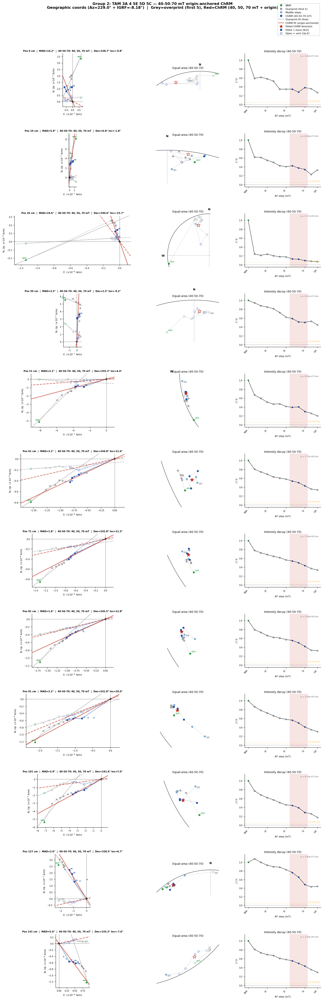


Group 3: TAM 5B 5A 6 7: 102 non-foam positions  [Az=229.0° + IGRF=-8.18° = 220.82°]


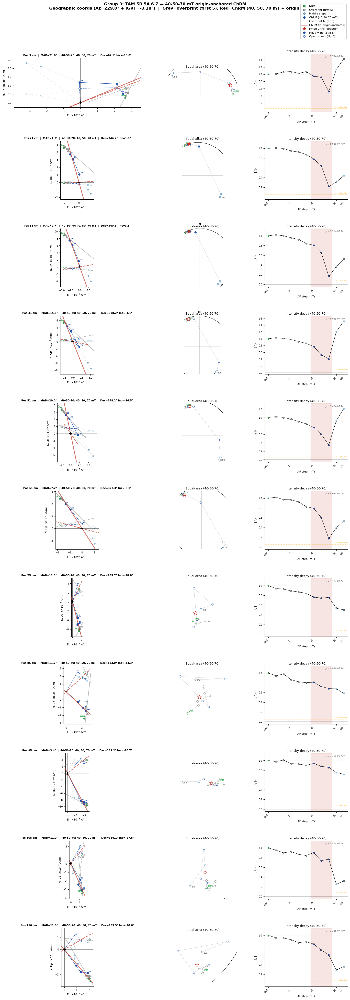


Group 1: SC 1C 1B 1A 2 3C: 78 non-foam positions  [Az=223.0° + IGRF=-8.18° = 214.82°]


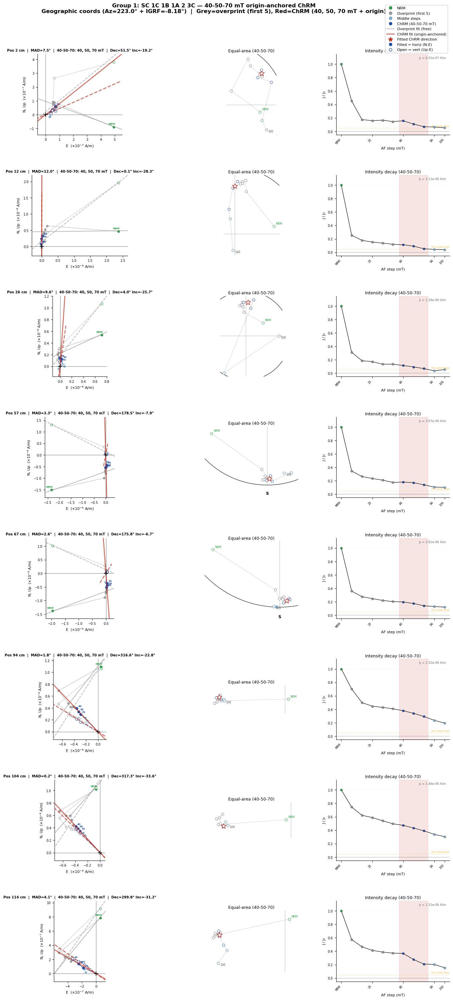


Group 2: SC 3B 3A 4D 4C 4B 4A: 113 non-foam positions  [Az=223.0° + IGRF=-8.18° = 214.82°]


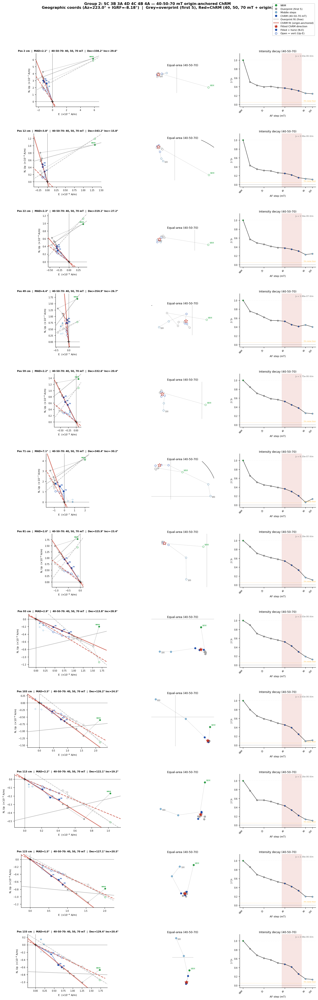


Group 3: SC 5 6 7C 7B 7A: 94 non-foam positions  [Az=223.0° + IGRF=-8.18° = 214.82°]


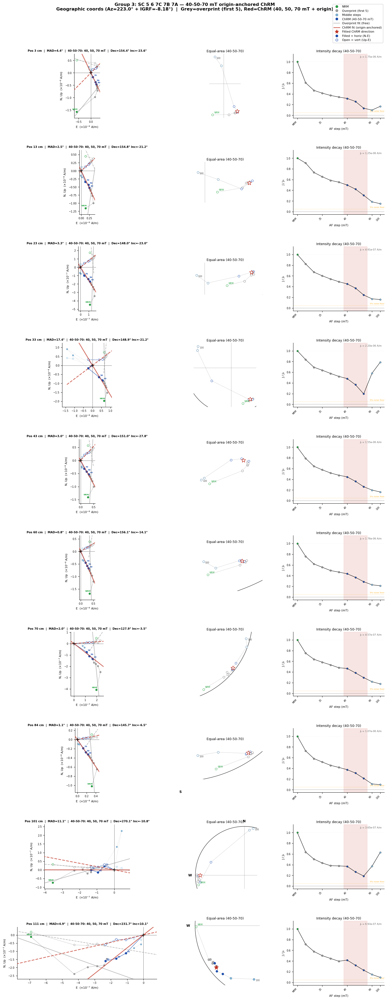


Group 4: SC 8: 27 non-foam positions  [Az=223.0° + IGRF=-8.18° = 214.82°]


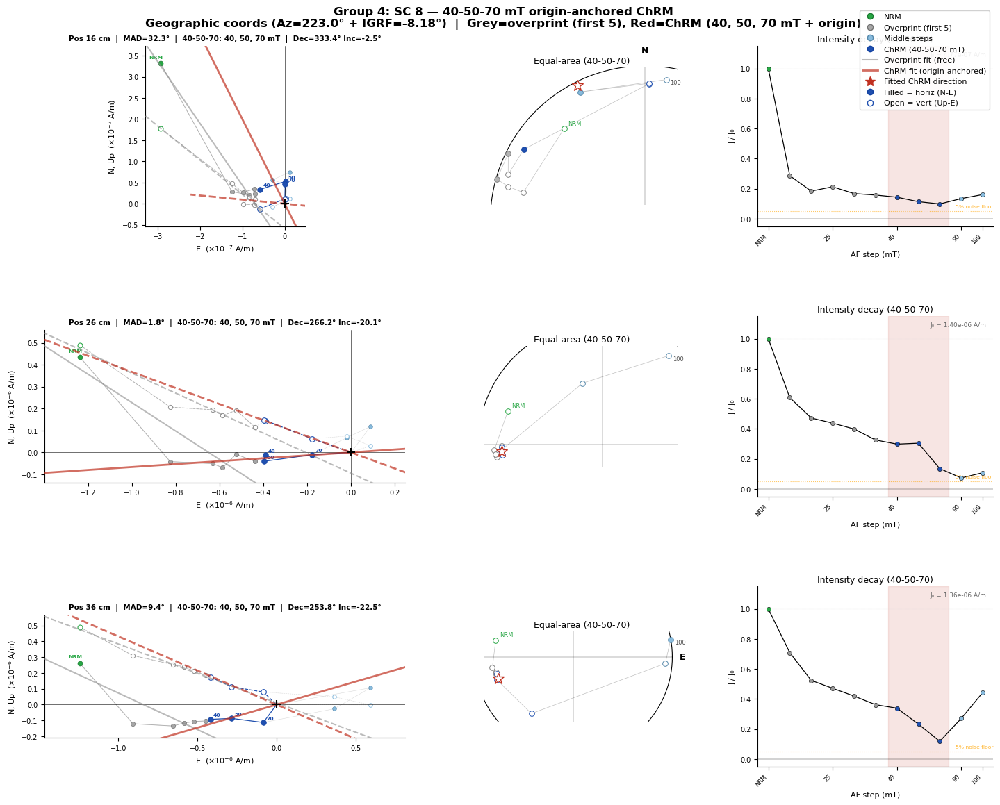

In [30]:
"""

40-50-70 mT origin-anchored ChRM fit.

Overprint = first 5 AF steps (after NRM), ChRM = steps at 40, 50, 70 mT anchored to origin.

Uses functions from cell 35 (read_dir_z, dir2cart, equal_area_xy, etc.).

"""

CHRM_TREATS_MT = {40, 50, 70}   # target AF steps in mT


def pca_anchored(xs, ys, zs):
    """Origin-anchored PCA: append origin, SVD without centering."""
    data = np.column_stack([xs, ys, zs])
    data_anch = np.vstack([data, [0.0, 0.0, 0.0]])
    U, S, Vt = np.linalg.svd(data_anch, full_matrices=False)
    v1 = Vt[0]
    if np.dot(v1, data.mean(axis=0)) < 0:
        v1 = -v1
    s2 = S[1]**2 if len(S) > 1 else 0
    s3 = S[2]**2 if len(S) > 2 else 0
    mad = np.rad2deg(np.arctan2(np.sqrt(s2 + s3), S[0]))
    return data.mean(axis=0), v1, mad


def cart2dir(x, y, z):
    """Cartesian → (Dec, Inc) in degrees."""
    dec = np.degrees(np.arctan2(y, x)) % 360
    inc = np.degrees(np.arctan2(z, np.sqrt(x**2 + y**2)))
    return dec, inc


def _get_chrm_idxs(treats):
    """Return indices of steps whose AF level (mT) is in CHRM_TREATS_MT."""
    return np.array([i for i in range(len(treats))
                     if treats[i] / 10 in CHRM_TREATS_MT], dtype=int)


# ── Zijderveld (40-50-70 anchored) ───────────────────────────────────
def plot_zij_l2(ax, steps, position):
    """Zijderveld: overprint=first 5 steps, ChRM=40,50,70 mT anchored to origin."""
    steps = sorted(steps, key=lambda s: s['treat'])
    treats = np.array([s['treat'] for s in steps])
    js     = np.array([s['J'] for s in steps])
    decs   = np.array([s['Decl'] for s in steps])
    incs   = np.array([s['Incl'] for s in steps])

    cart = np.array([dir2cart(d, i, m) for d, i, m in zip(decs, incs, js)])
    N_arr, E_arr, D_arr = cart[:, 0], cart[:, 1], cart[:, 2]

    maxval = max(np.max(np.abs(E_arr)), np.max(np.abs(N_arr)),
                 np.max(np.abs(D_arr)), 1e-20)
    exp = int(np.floor(np.log10(maxval)))
    scl = 10 ** (-exp)
    Es, Ns, Ds = E_arr * scl, N_arr * scl, D_arr * scl

    n_steps = len(steps)
    nrm_mask = treats == 0
    non_nrm = np.where(~nrm_mask)[0]

    # Overprint = first 5 non-NRM steps
    n_overprint = min(5, max(0, len(non_nrm) - 2))
    overprint_idxs = non_nrm[:n_overprint] if n_overprint > 0 else np.array([], dtype=int)
    # ChRM = steps at 40, 50, 70 mT
    chrm_idxs = _get_chrm_idxs(treats)

    chrm_mask = np.zeros(n_steps, dtype=bool)
    if len(chrm_idxs) > 0:
        chrm_mask[chrm_idxs] = True
    overprint_mask = np.zeros(n_steps, dtype=bool)
    if len(overprint_idxs) > 0:
        overprint_mask[overprint_idxs] = True

    # Full trace
    ax.plot(np.append(Es, 0.0), np.append(Ns, 0.0), '-', color='0.85', lw=0.4, zorder=0)
    ax.plot(np.append(Es, 0.0), np.append(-Ds, 0.0), '--', color='0.85', lw=0.4, zorder=0)

    # NRM (green)
    if nrm_mask.any():
        ax.plot(Es[nrm_mask], Ns[nrm_mask], 'o', ms=5, mfc='#28a745',
                mec='#1a7a30', mew=0.5, zorder=3)
        ax.plot(Es[nrm_mask], -Ds[nrm_mask], 'o', ms=5, mfc='white',
                mec='#28a745', mew=0.8, zorder=3)
        ax.annotate('NRM', (Es[nrm_mask][0], Ns[nrm_mask][0]),
                    fontsize=5.5, color='#28a745', fontweight='bold',
                    xytext=(-12, 5), textcoords='offset points')

    # Overprint (grey)
    if overprint_mask.any():
        oi = np.where(overprint_mask)[0]
        ax.plot(Es[oi], Ns[oi], 'o', ms=4.5, mfc='0.65', mec='0.45', mew=0.5, zorder=2)
        ax.plot(Es[oi], -Ds[oi], 'o', ms=4.5, mfc='white', mec='0.55', mew=0.7, zorder=2)
        op_with_nrm = np.sort(np.concatenate([np.where(nrm_mask)[0], oi]))
        ax.plot(Es[op_with_nrm], Ns[op_with_nrm], '-', color='0.7', lw=0.7, zorder=1)
        ax.plot(Es[op_with_nrm], -Ds[op_with_nrm], '--', color='0.7', lw=0.7, zorder=1)

    # Middle steps (between overprint and ChRM) — light blue
    mid_mask = ~nrm_mask & ~overprint_mask & ~chrm_mask
    if mid_mask.any():
        mi = np.where(mid_mask)[0]
        ax.plot(Es[mi], Ns[mi], 'o', ms=4, mfc='#88BBDD', mec='#5588AA', mew=0.5, zorder=2)
        ax.plot(Es[mi], -Ds[mi], 'o', ms=4, mfc='white', mec='#88BBDD', mew=0.7, zorder=2)

    # ChRM 40-50-70 (blue) — connected to origin
    if chrm_mask.any():
        ci = np.where(chrm_mask)[0]
        ax.plot(np.append(Es[ci], 0.0), np.append(Ns[ci], 0.0), '-',
                color='#2050B0', lw=0.9, zorder=1)
        ax.plot(Es[ci], Ns[ci], 'o', ms=5.5, mfc='#2050B0', mec='#1040A0', mew=0.5, zorder=3)
        ax.plot(np.append(Es[ci], 0.0), np.append(-Ds[ci], 0.0), '--',
                color='#2050B0', lw=0.9, zorder=1)
        ax.plot(Es[ci], -Ds[ci], 'o', ms=5.5, mfc='white', mec='#2050B0', mew=0.8, zorder=3)

    ax.plot(0, 0, '+', ms=8, mew=1.5, color='k', zorder=5)

    # Overprint fit (grey, free-floating through NRM + first 5)
    op_fit_idxs = np.sort(np.concatenate([np.where(nrm_mask)[0], overprint_idxs]))
    if len(op_fit_idxs) >= 2:
        centroid, v1, _ = pca_free(N_arr[op_fit_idxs], E_arr[op_fit_idxs], D_arr[op_fit_idxs])
        t_rng = np.linspace(-1.5 * maxval, 1.5 * maxval, 2)
        pca_pts = centroid[:, None] + v1[:, None] * t_rng[None, :]
        ax.plot(pca_pts[1] * scl, pca_pts[0] * scl, '-',
                color='0.55', lw=1.5, alpha=0.6, zorder=4)
        ax.plot(pca_pts[1] * scl, -pca_pts[2] * scl, '--',
                color='0.55', lw=1.5, alpha=0.6, zorder=4)

    # ChRM fit (red, origin-anchored through 40-50-70 mT steps)
    chrm_mad = 0.0
    if len(chrm_idxs) >= 2:
        _, v1, chrm_mad = pca_anchored(N_arr[chrm_idxs], E_arr[chrm_idxs], D_arr[chrm_idxs])
        t_rng = np.linspace(-1.5 * maxval, 1.5 * maxval, 2)
        pca_pts = v1[:, None] * t_rng[None, :]  # through origin
        ax.plot(pca_pts[1] * scl, pca_pts[0] * scl, '-',
                color='#C03020', lw=2.0, alpha=0.7, zorder=4)
        ax.plot(pca_pts[1] * scl, -pca_pts[2] * scl, '--',
                color='#C03020', lw=2.0, alpha=0.7, zorder=4)

    # Step labels
    if len(chrm_idxs) >= 1:
        for k in chrm_idxs:
            af_mt = treats[k] / 10
            ax.annotate(f'{af_mt:.0f}', (Es[k], Ns[k]),
                        fontsize=5.5, color='#2050B0', fontweight='bold',
                        xytext=(3, 3), textcoords='offset points')

    # Crop to data extent
    all_x = np.concatenate([Es, [0.0]])
    all_y = np.concatenate([Ns, -Ds, [0.0]])
    pad_frac = 0.12
    x_range = max(np.ptp(all_x), 0.1)
    y_range = max(np.ptp(all_y), 0.1)
    ax.set_xlim(np.min(all_x) - pad_frac * x_range, np.max(all_x) + pad_frac * x_range)
    ax.set_ylim(np.min(all_y) - pad_frac * y_range, np.max(all_y) + pad_frac * y_range)

    ax.axhline(0, color='k', lw=0.4)
    ax.axvline(0, color='k', lw=0.4)
    ax.set_aspect('equal')
    ax.tick_params(labelsize=7)
    ax.set_xlabel(f'E  (×10$^{{{exp}}}$ A/m)', fontsize=8)
    ax.set_ylabel(f'N, Up  (×10$^{{{exp}}}$ A/m)', fontsize=8)
    despine(ax)

    # Compute direction from anchored fit for title
    dir_str = ''
    if len(chrm_idxs) >= 2:
        _, v1, _ = pca_anchored(N_arr[chrm_idxs], E_arr[chrm_idxs], D_arr[chrm_idxs])
        dec_fit, inc_fit = cart2dir(v1[0], v1[1], v1[2])
        dir_str = f'  |  Dec={dec_fit:.1f}° Inc={inc_fit:.1f}°'
        treat_labels = ', '.join(f'{treats[k]/10:.0f}' for k in chrm_idxs)
        treat_str = f'{treat_labels} mT'
    else:
        treat_str = ''
    ax.set_title(f'Pos {position:.0f} cm  |  MAD={chrm_mad:.1f}°  |  '
                 f'40-50-70: {treat_str}{dir_str}',
                 fontsize=7.5, fontweight='bold', pad=6)
    return chrm_mad


# ── Stereonet (40-50-70 anchored) ────────────────────────────────────
def plot_eqa_l2(ax, steps):
    """Stereonet: overprint=first 5, ChRM=40,50,70 mT with fitted direction star."""
    steps = sorted(steps, key=lambda s: s['treat'])
    treats = np.array([s['treat'] for s in steps])
    decs = np.array([s['Decl'] for s in steps])
    incs = np.array([s['Incl'] for s in steps])
    js = np.array([s['J'] for s in steps])
    x, y = equal_area_xy(decs, incs)

    nrm_mask = treats == 0
    non_nrm = np.where(~nrm_mask)[0]
    n_overprint = min(5, max(0, len(non_nrm) - 2))
    overprint_idxs = non_nrm[:n_overprint] if n_overprint > 0 else np.array([], dtype=int)
    chrm_idxs = _get_chrm_idxs(treats)

    chrm_mask = np.zeros(len(steps), dtype=bool)
    if len(chrm_idxs) > 0:
        chrm_mask[chrm_idxs] = True
    overprint_mask = np.zeros(len(steps), dtype=bool)
    if len(overprint_idxs) > 0:
        overprint_mask[overprint_idxs] = True

    pad = 0.08
    xmin, xmax = np.min(x) - pad, np.max(x) + pad
    ymin, ymax = np.min(y) - pad, np.max(y) + pad

    theta = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(theta), np.sin(theta), 'k-', lw=0.8)
    ax.plot([-1, 1], [0, 0], 'k-', lw=0.2)
    ax.plot([0, 0], [-1, 1], 'k-', lw=0.2)
    ax.plot(x, y, '-', color='0.75', lw=0.5, zorder=1)

    for k in range(len(steps)):
        is_lower = incs[k] >= 0
        if nrm_mask[k]:
            fc = '#28a745' if is_lower else 'white'
            ec = '#1a7a30' if is_lower else '#28a745'
        elif chrm_mask[k]:
            fc = '#2050B0' if is_lower else 'white'
            ec = '#1040A0' if is_lower else '#2050B0'
        elif overprint_mask[k]:
            fc = '0.7' if is_lower else 'white'
            ec = '0.5'
        else:
            fc = '#88BBDD' if is_lower else 'white'
            ec = '#5588AA'
        ax.plot(x[k], y[k], 'o', ms=5.5, mfc=fc, mec=ec, mew=0.7, zorder=3)

    if len(steps) > 0:
        ax.annotate('NRM', (x[0], y[0]), fontsize=6, color='#28a745',
                    xytext=(4, 4), textcoords='offset points')
        ax.annotate(f'{treats[-1]/10:.0f}', (x[-1], y[-1]), fontsize=6,
                    color='0.3', xytext=(4, -5), textcoords='offset points')

    # Plot fitted ChRM direction (red star)
    if len(chrm_idxs) >= 2:
        cart = np.array([dir2cart(decs[k], incs[k], js[k]) for k in chrm_idxs])
        _, v1, _ = pca_anchored(cart[:, 0], cart[:, 1], cart[:, 2])
        fit_dec, fit_inc = cart2dir(v1[0], v1[1], v1[2])
        fx, fy = equal_area_xy(fit_dec, fit_inc)
        is_lower = fit_inc >= 0
        fc_fit = '#C03020' if is_lower else 'white'
        ax.plot(fx, fy, '*', ms=12, mfc=fc_fit, mec='#C03020', mew=1.0, zorder=5)
        xmin = min(xmin, float(fx) - pad)
        xmax = max(xmax, float(fx) + pad)
        ymin = min(ymin, float(fy) - pad)
        ymax = max(ymax, float(fy) + pad)

    for lbl, (px, py, ha, va) in {'N': (0, 1.07, 'center', 'bottom'),
                                   'S': (0, -1.07, 'center', 'top'),
                                   'E': (1.07, 0, 'left', 'center'),
                                   'W': (-1.07, 0, 'right', 'center')}.items():
        if xmin - 0.1 <= px <= xmax + 0.1 and ymin - 0.1 <= py <= ymax + 0.1:
            ax.text(px, py, lbl, ha=ha, va=va, fontsize=9, fontweight='bold')

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title('Equal-area (40-50-70)', fontsize=9, pad=4)


# ── J/J₀ (40-50-70 anchored) ────────────────────────────────────────
def plot_jj0_l2(ax, steps):
    """J/J₀ with 40-50-70 mT ChRM window highlighted."""
    steps = sorted(steps, key=lambda s: s['treat'])
    treats = np.array([s['treat'] for s in steps])
    moms = np.array([s['J'] for s in steps])
    j0 = moms[0] if moms[0] > 0 else 1e-20
    jjo = moms / j0
    xs = np.arange(len(steps))

    nrm_mask = treats == 0
    non_nrm = np.where(~nrm_mask)[0]
    n_overprint = min(5, max(0, len(non_nrm) - 2))
    chrm_idxs = _get_chrm_idxs(treats)
    overprint_idxs = non_nrm[:n_overprint] if n_overprint > 0 else np.array([], dtype=int)

    if len(chrm_idxs) >= 2:
        ax.axvspan(chrm_idxs[0] - 0.4, chrm_idxs[-1] + 0.4,
                   alpha=0.12, color='#C03020', zorder=0)

    ax.axhline(NOISE_FLOOR, color='orange', lw=0.8, ls=':', alpha=0.6)
    ax.text(len(steps) - 0.5, NOISE_FLOOR + 0.02, '5% noise floor',
            fontsize=5.5, ha='right', color='orange', alpha=0.8)

    chrm_set = set(chrm_idxs)
    op_set = set(overprint_idxs)
    for k in range(len(steps)):
        if nrm_mask[k]:
            fc = '#28a745'
        elif k in chrm_set:
            fc = '#2050B0'
        elif k in op_set:
            fc = '0.6'
        else:
            fc = '#88BBDD'
        ax.plot(xs[k], jjo[k], 'o', ms=4.5, mfc=fc, mec='k', mew=0.4, zorder=3)
    ax.plot(xs, jjo, '-', color='k', lw=0.9, zorder=2)

    ymax = max(1.15, np.max(jjo) * 1.1)
    ax.set_ylim(-0.05, ymax)
    ax.axhline(0, color='k', lw=0.25)
    ax.axhline(1, color='0.85', lw=0.3, ls=':')
    ax.set_ylabel('J / J₀', fontsize=8)
    ax.tick_params(labelsize=7)
    despine(ax)

    labels = [f'{treats[k]/10:.0f}' if treats[k] > 0 else 'NRM'
              for k in range(len(steps))]
    show = sorted(set(list(range(0, len(xs), 3)) + [len(xs) - 1]))
    ax.set_xticks([xs[k] for k in show])
    ax.set_xticklabels([labels[k] for k in show],
                       fontsize=6, rotation=45, ha='right')
    ax.set_xlabel('AF step (mT)', fontsize=8)

    ax.text(0.97, 0.97, f'J₀ = {j0:.2e} A/m', transform=ax.transAxes,
            fontsize=6.5, ha='right', va='top', color='0.4')
    ax.set_title('Intensity decay (40-50-70)', fontsize=9, pad=4)


# ══════════════════════════════════════════════════════════════════════
#  Generate 40-50-70 mT anchored figures for each group
# ══════════════════════════════════════════════════════════════════════
for group_name, (dir_fname, site_key) in DIR_FILES_Z.items():
    dir_path = os.path.join(DIR_DIR_Z, dir_fname)
    if not os.path.exists(dir_path):
        continue

    azimuth = SITE_AZ[site_key]
    geo_rot = azimuth + IGRF_DEC

    pos_steps = read_dir_z(dir_path, geo_rot=geo_rot)
    if not pos_steps:
        continue

    foam_zones = get_foam_zones_z(group_name)
    positions = sorted(pos_steps.keys())
    viable_positions = [p for p in positions if not is_in_foam_z(p, foam_zones)]
    print(f'{group_name}: {len(viable_positions)} non-foam positions  '
          f'[Az={azimuth}° + IGRF={IGRF_DEC}° = {geo_rot:.2f}°]')

    selected = viable_positions[::STEP_EVERY]
    n_sel = len(selected)
    if n_sel == 0:
        continue

    fig = plt.figure(figsize=(15, 3.8 * n_sel))
    gs = gridspec.GridSpec(
        n_sel, 3, figure=fig,
        width_ratios=[1.3, 0.7, 0.85],
        hspace=0.50, wspace=0.30,
        left=0.06, right=0.97, top=0.94, bottom=0.03)

    for idx, pos in enumerate(selected):
        s = sorted(pos_steps[pos], key=lambda x: x['treat'])

        ax_z = fig.add_subplot(gs[idx, 0])
        plot_zij_l2(ax_z, s, pos)

        ax_e = fig.add_subplot(gs[idx, 1])
        plot_eqa_l2(ax_e, s)

        ax_j = fig.add_subplot(gs[idx, 2])
        plot_jj0_l2(ax_j, s)

    legend_handles = [
        Line2D([0], [0], marker='o', color='w', mfc='#28a745',
               mec='#1a7a30', ms=6, label='NRM'),
        Line2D([0], [0], marker='o', color='w', mfc='0.65',
               mec='0.45', ms=6, label='Overprint (first 5)'),
        Line2D([0], [0], marker='o', color='w', mfc='#88BBDD',
               mec='#5588AA', ms=6, label='Middle steps'),
        Line2D([0], [0], marker='o', color='w', mfc='#2050B0',
               mec='#1040A0', ms=6, label='ChRM (40-50-70 mT)'),
        Line2D([0], [0], color='0.55', lw=1.5, alpha=0.6,
               label='Overprint fit (free)'),
        Line2D([0], [0], color='#C03020', lw=2.0, alpha=0.7,
               label='ChRM fit (origin-anchored)'),
        Line2D([0], [0], marker='*', color='w', mfc='#C03020',
               mec='#C03020', ms=10, label='Fitted ChRM direction'),
        Line2D([0], [0], marker='o', color='w', mfc='#2050B0',
               mec='#1040A0', ms=6, lw=0, label='Filled = horiz (N-E)'),
        Line2D([0], [0], marker='o', color='w', mfc='white',
               mec='#2050B0', ms=6, lw=0, label='Open = vert (Up-E)'),
    ]
    fig.legend(handles=legend_handles, loc='upper right', fontsize=8,
               framealpha=0.9, bbox_to_anchor=(0.97, 0.99), ncol=1)

    fig.suptitle(f'{group_name} — 40-50-70 mT origin-anchored ChRM\n'
                 f'Geographic coords (Az={azimuth}° + IGRF={IGRF_DEC}°)  |  '
                 f'Grey=overprint (first 5), Red=ChRM (40, 50, 70 mT + origin)',
                 fontsize=12, fontweight='bold', y=0.99)
    plt.show()
    print()

## vgp compasrisons

  Group 2: TAM 3A 4 5E 5D 5C: 144 original | 111 40-50-70 | 106 filtered (5 rejected: MAD>15.0° or J/J₀<0.05)
  Group 3: TAM 5B 5A 6 7: 118 original | 102 40-50-70 | 84 filtered (18 rejected: MAD>15.0° or J/J₀<0.05)
  Group 1: SC 1C 1B 1A 2 3C: 126 original | 78 40-50-70 | 74 filtered (4 rejected: MAD>15.0° or J/J₀<0.05)
  Group 2: SC 3B 3A 4D 4C 4B 4A: 139 original | 113 40-50-70 | 113 filtered (0 rejected: MAD>15.0° or J/J₀<0.05)
  Group 3: SC 5 6 7C 7B 7A: 117 original | 94 40-50-70 | 86 filtered (8 rejected: MAD>15.0° or J/J₀<0.05)
  Group 4: SC 8: 51 original | 27 40-50-70 | 24 filtered (3 rejected: MAD>15.0° or J/J₀<0.05)

VGP COMPARISON: Original PCA (10-100 mT)  |  40-50-70 mT anchored  |  Filtered (MAD≤15.0° & J/J₀≥0.05)
Dipole-aligned threshold: |VGP lat| ≥ 60°


,Group,Orig N,Orig |VGP|≥60°,Orig N-pole,Orig S-pole,40-70 N,40-70 |VGP|≥60°,40-70 N-pole,40-70 S-pole,Filtered N,Filtered |VGP|≥60°,Filtered N-pole,Filtered S-pole
0,Group 1: SC 1C 1B 1A 2 3C,126,59 (47%),35,24,78,41 (53%),15,26,74,37 (50%),11,26
1,Group 2: SC 3B 3A 4D 4C 4B 4A,139,39 (28%),39,0,113,44 (39%),44,0,113,44 (39%),44,0
2,Group 2: TAM 3A 4 5E 5D 5C,144,39 (27%),37,2,111,36 (32%),36,0,106,31 (29%),31,0
3,Group 3: SC 5 6 7C 7B 7A,117,24 (21%),0,24,94,32 (34%),0,32,86,32 (37%),0,32
4,Group 3: TAM 5B 5A 6 7,118,47 (40%),20,27,102,57 (56%),36,21,84,47 (56%),27,20
5,Group 4: SC 8,51,4 (8%),4,0,27,1 (4%),1,0,24,0 (0%),0,0
6,TOTAL,695,212 (31%),135,77,525,211 (40%),132,79,487,191 (39%),113,78


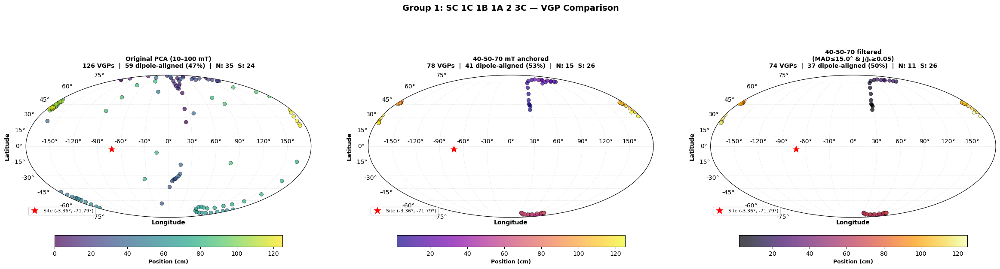

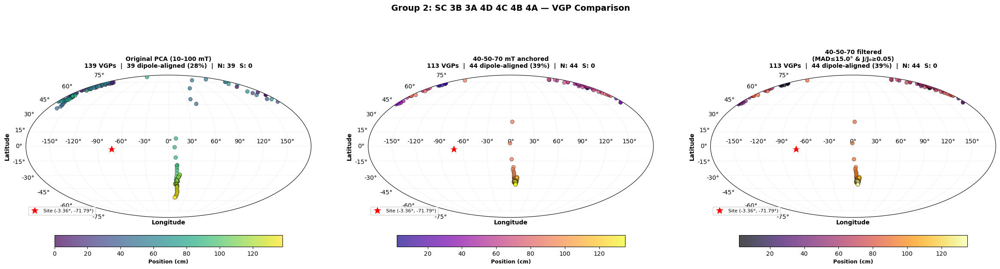

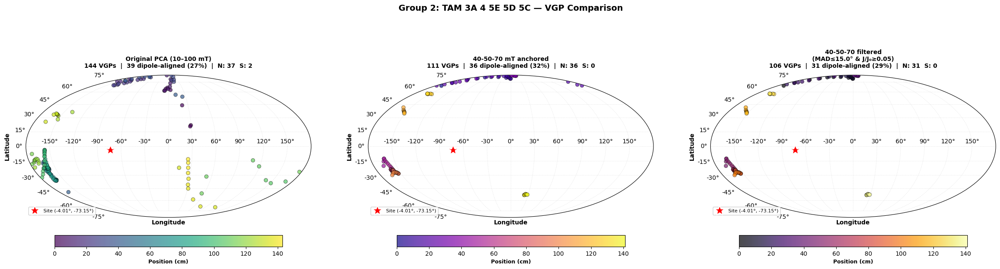

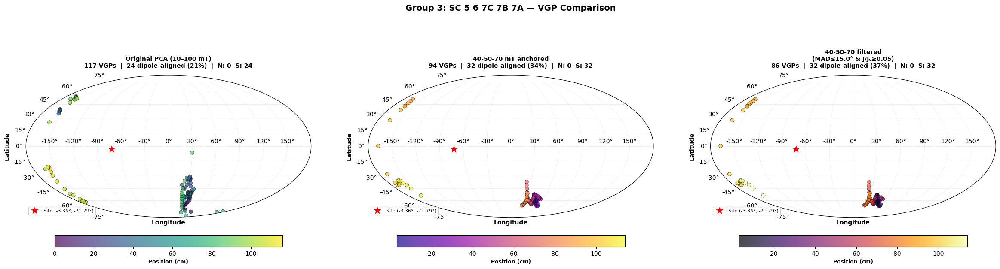

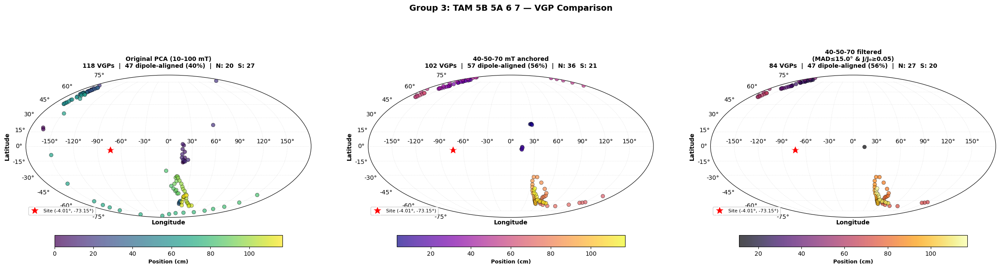

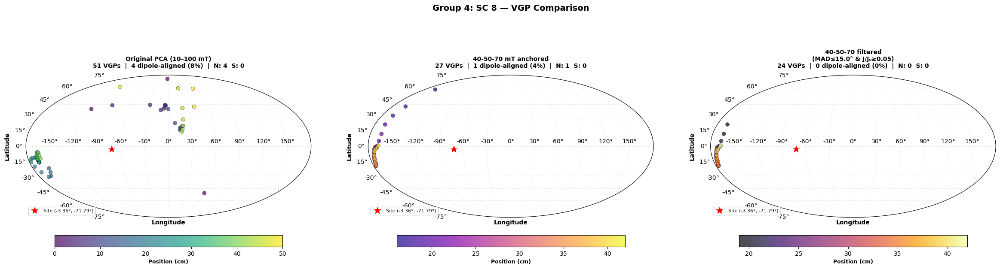

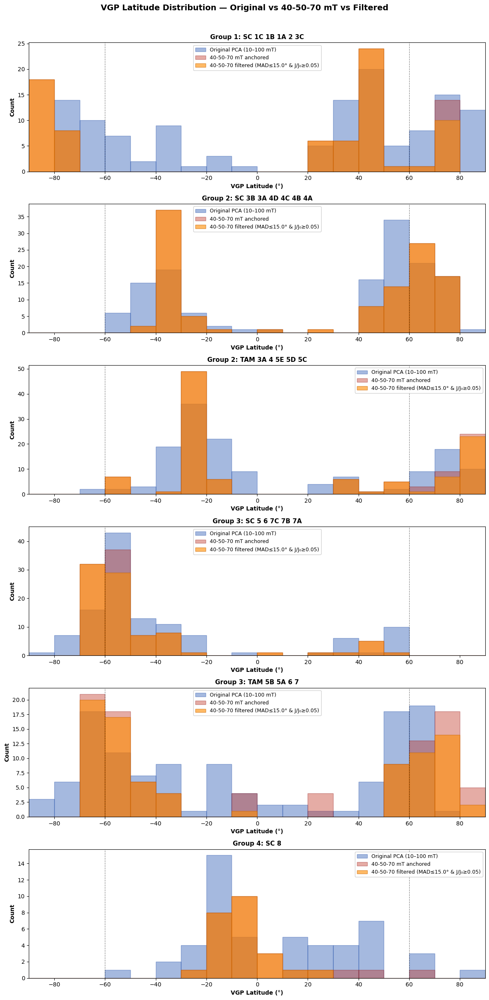

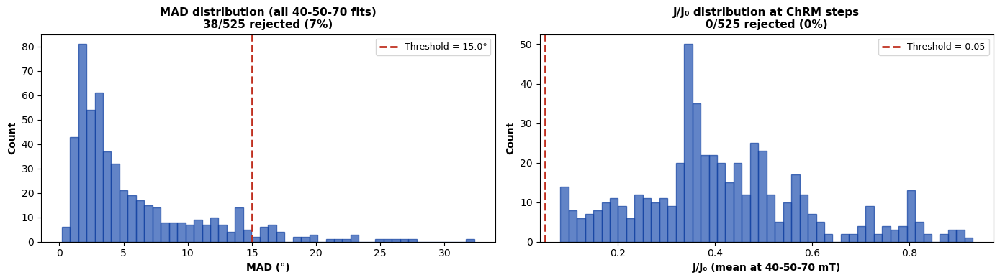


  Original PCA (10-100 mT)                             212/695  =  30.5% dipole-aligned  (N-pole: 135, S-pole: 77)
  40-50-70 mT anchored                                 211/525  =  40.2% dipole-aligned  (N-pole: 132, S-pole: 79)
  40-50-70 filtered (MAD≤15.0° & J/J₀≥0.05)            191/487  =  39.2% dipole-aligned  (N-pole: 113, S-pole: 78)


In [31]:
"""
VGP comparison: original PCA (UPmag 10-100 mT) vs 40-50-70 mT origin-anchored
                vs 40-50-70 filtered (MAD + intensity).
Requires cells 29, 33, 35, 39 to have been run first.
"""

# ── Quality-filter thresholds ─────────────────────────────────────────
MAD_THRESH   = 15.0   # degrees — reject fits with MAD above this
JJ0_THRESH   = 0.05   # fraction of NRM — reject if mean J at ChRM steps < this

# ── Mapping from DIR_FILES_Z group names to SAMPLE_GROUPS sample_ids ─
_dir_to_sample = {}
for gname, (dfname, skey) in DIR_FILES_Z.items():
    stem = dfname.replace('.NRM.dir', '')
    _dir_to_sample[gname] = (stem, skey)

# ── Compute 40-50-70 VGPs for every non-foam position ────────────────
CHRM_TREATS_MT_CMP = {40, 50, 70}

def _chrm_idxs_cmp(treats):
    return np.array([i for i in range(len(treats))
                     if treats[i] / 10 in CHRM_TREATS_MT_CMP], dtype=int)

results = {}

for gname, (sample_id, site_key) in _dir_to_sample.items():
    # ── Original VGPs from file (use DIR_DIR_Z to avoid BASE_DIR conflict) ──
    vgp_path = os.path.join(DIR_DIR_Z, 'vgp_corrected', f'VGP - {sample_id}.txt')
    if not os.path.exists(vgp_path):
        print(f"  [skip] VGP file not found for {gname}: {vgp_path}")
        continue
    orig_vgp = read_vgp_file(vgp_path)

    # ── New 40-50-70 VGPs from DIR data ──
    dir_path = os.path.join(DIR_DIR_Z, f'{sample_id}.NRM.dir')
    if not os.path.exists(dir_path):
        print(f"  [skip] DIR file not found for {gname}")
        continue

    site_lat = SITE_COORDS[site_key]['lat']
    site_lon = SITE_COORDS[site_key]['lon']
    azimuth  = SITE_AZ[site_key]
    geo_rot  = azimuth + IGRF_DEC

    pos_steps = read_dir_z(dir_path, geo_rot=geo_rot)
    foam_zones = get_foam_zones_z(gname)

    new_rows = []
    for pos in sorted(pos_steps.keys()):
        if is_in_foam_z(pos, foam_zones):
            continue
        steps = sorted(pos_steps[pos], key=lambda s: s['treat'])
        treats = np.array([s['treat'] for s in steps])
        ci = _chrm_idxs_cmp(treats)
        if len(ci) < 2:
            continue
        js   = np.array([s['J'] for s in steps])
        decs = np.array([s['Decl'] for s in steps])
        incs = np.array([s['Incl'] for s in steps])
        cart = np.array([dir2cart(d, i, m) for d, i, m in zip(decs, incs, js)])
        N_arr, E_arr, D_arr = cart[:, 0], cart[:, 1], cart[:, 2]
        _, v1, mad = pca_anchored(N_arr[ci], E_arr[ci], D_arr[ci])
        fit_dec, fit_inc = cart2dir(v1[0], v1[1], v1[2])
        vgp_lat, vgp_lon = compute_vgp(fit_dec, fit_inc, site_lat, site_lon)

        # J/J0 at ChRM steps
        j0 = js[0] if js[0] > 0 else 1e-20
        jj0_mean = np.mean(js[ci]) / j0

        new_rows.append({'Position(cm)': pos, 'Dec': fit_dec, 'Inc': fit_inc,
                         'MAD': mad, 'JJ0': jj0_mean,
                         'VGP_Lat.': vgp_lat, 'VGP_Long.': vgp_lon})

    if not new_rows:
        print(f"  [skip] No valid 40-50-70 fits for {gname}")
        continue

    new_vgp = pd.DataFrame(new_rows)

    # ── Filtered subset: MAD + intensity ──
    filt_mask = (new_vgp['MAD'] <= MAD_THRESH) & (new_vgp['JJ0'] >= JJ0_THRESH)
    filt_vgp = new_vgp[filt_mask].copy().reset_index(drop=True)

    results[gname] = {'orig': orig_vgp, 'new': new_vgp, 'filt': filt_vgp,
                       'site_key': site_key, 'sample_id': sample_id}
    n_rejected = len(new_vgp) - len(filt_vgp)
    print(f"  {gname}: {len(orig_vgp)} original | {len(new_vgp)} 40-50-70 | "
          f"{len(filt_vgp)} filtered ({n_rejected} rejected: MAD>{MAD_THRESH}° or J/J₀<{JJ0_THRESH})")

# ── Guard: stop early if no results ──────────────────────────────────
if len(results) == 0:
    print('\nNo results produced — check that cells 29, 33, 35, 39 have been run.')
else:
    # ── Summary table ─────────────────────────────────────────────────
    DIPOLE_THRESH = 60

    def _stats(lats):
        n = len(lats)
        dip = int(np.sum(np.abs(lats) >= DIPOLE_THRESH))
        pct = 100 * dip / n if n else 0
        npole = int(np.sum(lats >= DIPOLE_THRESH))
        spole = int(np.sum(lats <= -DIPOLE_THRESH))
        return n, dip, pct, npole, spole

    table_rows = []
    totals = {k: [0, 0, 0, 0] for k in ('orig', 'new', 'filt')}

    for gname in sorted(results.keys()):
        r = results[gname]
        row = {'Group': gname}
        for tag, key in [('Orig', 'orig'), ('40-70', 'new'), ('Filtered', 'filt')]:
            lats = r[key]['VGP_Lat.'].values
            n, dip, pct, npole, spole = _stats(lats)
            row[f'{tag} N'] = n
            row[f'{tag} |VGP|≥60°'] = f'{dip} ({pct:.0f}%)'
            row[f'{tag} N-pole'] = npole
            row[f'{tag} S-pole'] = spole
            totals[key][0] += n
            totals[key][1] += dip
            totals[key][2] += npole
            totals[key][3] += spole
        table_rows.append(row)

    tot_row = {'Group': 'TOTAL'}
    for tag, key in [('Orig', 'orig'), ('40-70', 'new'), ('Filtered', 'filt')]:
        n, dip, npole, spole = totals[key]
        pct = 100 * dip / n if n else 0
        tot_row[f'{tag} N'] = n
        tot_row[f'{tag} |VGP|≥60°'] = f'{dip} ({pct:.0f}%)'
        tot_row[f'{tag} N-pole'] = npole
        tot_row[f'{tag} S-pole'] = spole
    table_rows.append(tot_row)

    summary_df = pd.DataFrame(table_rows)
    print('\n' + '='*120)
    print(f'VGP COMPARISON: Original PCA (10-100 mT)  |  40-50-70 mT anchored  |  '
          f'Filtered (MAD≤{MAD_THRESH}° & J/J₀≥{JJ0_THRESH})')
    print(f'Dipole-aligned threshold: |VGP lat| ≥ {DIPOLE_THRESH}°')
    print('='*120)
    display(summary_df)

    # ── Side-by-side Mollweide VGP plots (3 columns) ─────────────────
    for gname in sorted(results.keys()):
        r = results[gname]
        s_lat = np.deg2rad(SITE_COORDS[r['site_key']]['lat'])
        s_lon = np.deg2rad(SITE_COORDS[r['site_key']]['lon'])

        fig = plt.figure(figsize=(24, 7))
        gs_plot = gridspec.GridSpec(1, 3, figure=fig, wspace=0.20,
                                    left=0.03, right=0.97, top=0.82, bottom=0.08)

        col_specs = [
            ('Original PCA (10–100 mT)', r['orig'], 'viridis'),
            ('40-50-70 mT anchored', r['new'], 'plasma'),
            (f'40-50-70 filtered\n(MAD≤{MAD_THRESH}° & J/J₀≥{JJ0_THRESH})', r['filt'], 'inferno'),
        ]

        for col, (label, df, cmap_name) in enumerate(col_specs):
            ax = fig.add_subplot(gs_plot[0, col], projection='mollweide')
            if len(df) == 0:
                ax.set_title(f'{label}\nNo data after filtering', fontsize=10, fontweight='bold', pad=12)
                ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
                continue

            positions = df['Position(cm)'].values
            vgp_lons = np.deg2rad(df['VGP_Long.'].values)
            vgp_lats = np.deg2rad(df['VGP_Lat.'].values)

            scatter = ax.scatter(vgp_lons, vgp_lats, c=positions, cmap=cmap_name,
                                 s=40, alpha=0.7, edgecolors='black', linewidth=0.5,
                                 zorder=5)
            cbar = plt.colorbar(scatter, ax=ax, orientation='horizontal',
                                pad=0.08, shrink=0.8)
            cbar.set_label('Position (cm)', fontsize=9, fontweight='bold')

            ax.plot(s_lon, s_lat, 'r*', markersize=18, zorder=10,
                    markeredgecolor='white', markeredgewidth=1.5,
                    label=f'Site ({np.rad2deg(s_lat):.2f}°, {np.rad2deg(s_lon):.2f}°)')

            ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
            ax.set_xlabel('Longitude', fontsize=10, fontweight='bold')
            ax.set_ylabel('Latitude', fontsize=10, fontweight='bold')

            lats_deg = df['VGP_Lat.'].values
            n_dip = np.sum(np.abs(lats_deg) >= DIPOLE_THRESH)
            pct = 100 * n_dip / len(lats_deg) if len(lats_deg) else 0
            n_n = np.sum(lats_deg >= DIPOLE_THRESH)
            n_s = np.sum(lats_deg <= -DIPOLE_THRESH)

            ax.set_title(f'{label}\n{len(lats_deg)} VGPs  |  '
                         f'{n_dip} dipole-aligned ({pct:.0f}%)  |  '
                         f'N: {n_n}  S: {n_s}',
                         fontsize=10, fontweight='bold', pad=12)
            ax.legend(loc='lower left', fontsize=8, framealpha=0.9)

        fig.suptitle(f'{gname} — VGP Comparison', fontsize=14, fontweight='bold', y=0.96)
        plt.show()

    # ── VGP latitude histograms (3 methods overlaid) ─────────────────
    fig, axes = plt.subplots(len(results), 1, figsize=(12, 4 * len(results)),
                              squeeze=False)
    for idx, gname in enumerate(sorted(results.keys())):
        ax = axes[idx, 0]
        r = results[gname]
        bins = np.arange(-90, 95, 10)
        ax.hist(r['orig']['VGP_Lat.'].values, bins=bins, alpha=0.4,
                color='#2050B0', edgecolor='#1040A0', label='Original PCA (10–100 mT)')
        ax.hist(r['new']['VGP_Lat.'].values, bins=bins, alpha=0.4,
                color='#C03020', edgecolor='#901010', label='40-50-70 mT anchored')
        if len(r['filt']) > 0:
            ax.hist(r['filt']['VGP_Lat.'].values, bins=bins, alpha=0.6,
                    color='#FF8C00', edgecolor='#CC6600',
                    label=f'40-50-70 filtered (MAD≤{MAD_THRESH}° & J/J₀≥{JJ0_THRESH})')
        ax.axvline(DIPOLE_THRESH, color='k', ls='--', lw=0.8, alpha=0.5)
        ax.axvline(-DIPOLE_THRESH, color='k', ls='--', lw=0.8, alpha=0.5)
        ax.set_xlabel('VGP Latitude (°)', fontsize=10, fontweight='bold')
        ax.set_ylabel('Count', fontsize=10, fontweight='bold')
        ax.set_title(gname, fontsize=11, fontweight='bold')
        ax.legend(fontsize=9, framealpha=0.9)
        ax.set_xlim(-90, 90)

    fig.suptitle('VGP Latitude Distribution — Original vs 40-50-70 mT vs Filtered',
                 fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

    # ── MAD & J/J₀ distributions for the 40-50-70 data ──────────────
    fig, (ax_mad, ax_jj0) = plt.subplots(1, 2, figsize=(14, 4))
    all_mad = np.concatenate([r['new']['MAD'].values for r in results.values()])
    all_jj0 = np.concatenate([r['new']['JJ0'].values for r in results.values()])

    ax_mad.hist(all_mad, bins=50, color='#2050B0', edgecolor='#1040A0', alpha=0.7)
    ax_mad.axvline(MAD_THRESH, color='#C03020', lw=2, ls='--',
                   label=f'Threshold = {MAD_THRESH}°')
    n_above = np.sum(all_mad > MAD_THRESH)
    ax_mad.set_title(f'MAD distribution (all 40-50-70 fits)\n'
                     f'{n_above}/{len(all_mad)} rejected ({100*n_above/len(all_mad):.0f}%)',
                     fontsize=11, fontweight='bold')
    ax_mad.set_xlabel('MAD (°)', fontsize=10, fontweight='bold')
    ax_mad.set_ylabel('Count', fontsize=10, fontweight='bold')
    ax_mad.legend(fontsize=9)

    ax_jj0.hist(all_jj0, bins=50, color='#2050B0', edgecolor='#1040A0', alpha=0.7)
    ax_jj0.axvline(JJ0_THRESH, color='#C03020', lw=2, ls='--',
                   label=f'Threshold = {JJ0_THRESH}')
    n_below = np.sum(all_jj0 < JJ0_THRESH)
    ax_jj0.set_title(f'J/J₀ distribution at ChRM steps\n'
                     f'{n_below}/{len(all_jj0)} rejected ({100*n_below/len(all_jj0):.0f}%)',
                     fontsize=11, fontweight='bold')
    ax_jj0.set_xlabel('J/J₀ (mean at 40-50-70 mT)', fontsize=10, fontweight='bold')
    ax_jj0.set_ylabel('Count', fontsize=10, fontweight='bold')
    ax_jj0.legend(fontsize=9)

    plt.tight_layout()
    plt.show()

    # ── Final summary ────────────────────────────────────────────────
    print('\n' + '='*100)
    for tag, key in [('Original PCA (10-100 mT)', 'orig'),
                     ('40-50-70 mT anchored', 'new'),
                     (f'40-50-70 filtered (MAD≤{MAD_THRESH}° & J/J₀≥{JJ0_THRESH})', 'filt')]:
        n, dip, npole, spole = totals[key]
        pct = 100 * dip / n if n else 0
        print(f'  {tag:50s}  {dip:>4d}/{n:<4d} = {pct:5.1f}% dipole-aligned  '
              f'(N-pole: {npole}, S-pole: {spole})')
    print('='*100)

## Azimuth optimisation per group
Sweep strike offset ±20° from current site azimuth to find per-section corrections that maximise N/S dipole alignment.

AZIMUTH OPTIMISATION PER GROUP (±20° sweep, filtered 40-50-70 data)
Filter: MAD ≤ 15.0° & J/J₀ ≥ 0.05  |  Dipole threshold: |VGP lat| ≥ 60°


,Group,Site,Current Az,N filtered,Current dipole %,Best offset,Optimal Az,Best dipole %,Improvement
0,Group 1: SC 1C 1B 1A 2 3C,SC,223.0°,74,50.0%,+17°,240.0°,71.6%,+21.6%
1,Group 2: SC 3B 3A 4D 4C 4B 4A,SC,223.0°,113,38.9%,+20°,243.0°,59.3%,+20.4%
2,Group 2: TAM 3A 4 5E 5D 5C,TAM,229.0°,106,29.2%,+19°,248.0°,41.5%,+12.3%
3,Group 3: SC 5 6 7C 7B 7A,SC,223.0°,86,37.2%,+19°,242.0°,80.2%,+43.0%
4,Group 3: TAM 5B 5A 6 7,TAM,229.0°,84,56.0%,+18°,247.0°,88.1%,+32.1%
5,Group 4: SC 8,SC,223.0°,24,0.0%,-20°,203.0°,0.0%,+0.0%


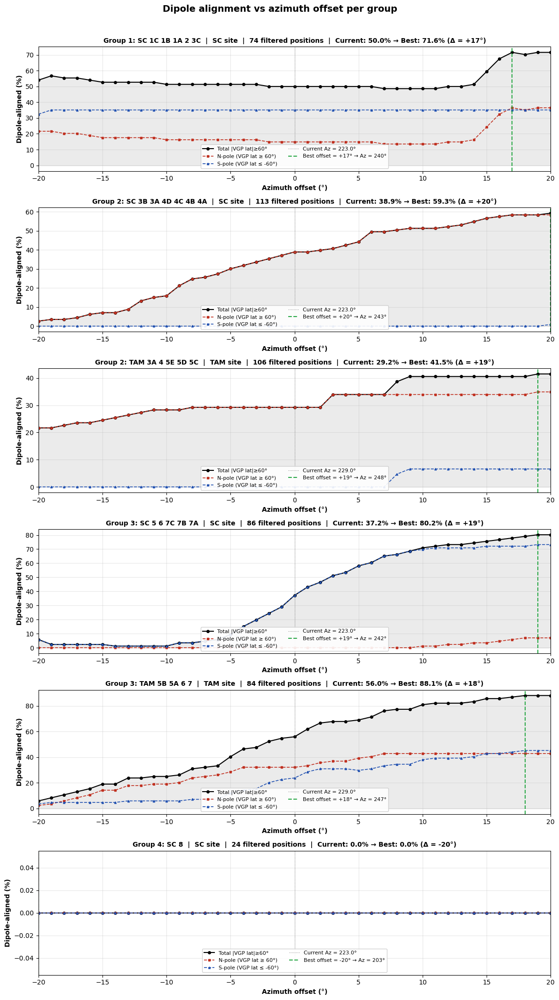


PER-SITE RECOMMENDED AZIMUTHS

  TAM site (current Az = 229.0°):
    Group 2: TAM 3A 4 5E 5D 5C                     Δ = +19°  →  Az = 248°  (29.2% → 41.5%)
    Group 3: TAM 5B 5A 6 7                         Δ = +18°  →  Az = 247°  (56.0% → 88.1%)
    Mean offset                                    Δ = +18.5°  →  Az = 247.5°
    ✓ Sections agree well (spread = 1°) — a single site correction may suffice

  SC site (current Az = 223.0°):
    Group 1: SC 1C 1B 1A 2 3C                      Δ = +17°  →  Az = 240°  (50.0% → 71.6%)
    Group 2: SC 3B 3A 4D 4C 4B 4A                  Δ = +20°  →  Az = 243°  (38.9% → 59.3%)
    Group 3: SC 5 6 7C 7B 7A                       Δ = +19°  →  Az = 242°  (37.2% → 80.2%)
    Group 4: SC 8                                  Δ = -20°  →  Az = 203°  (0.0% → 0.0%)
    Mean offset                                    Δ = +9.0°  →  Az = 232.0°
    ⚠ Sections disagree (spread = 40°) — per-section azimuths recommended


In [32]:
"""
Azimuth optimisation: for each group, sweep strike offset ±20° and find
the per-section correction that maximises dipole-aligned VGP fraction.

Uses the 40-50-70 mT origin-anchored fits already in `results` dict.
Rotating azimuth by Δ is equivalent to rotating all Decs by Δ (Inc unchanged),
so we don't need to re-read DIR files — just shift Dec and recompute VGP.
"""

AZ_RANGE = np.arange(-20, 21, 1)  # offsets to sweep (degrees)

opt_results = {}

for gname in sorted(results.keys()):
    r = results[gname]
    site_key = r['site_key']
    site_lat = SITE_COORDS[site_key]['lat']
    site_lon = SITE_COORDS[site_key]['lon']
    current_az = SITE_AZ[site_key]

    # Use the unfiltered 40-50-70 data (apply MAD+JJ0 filter here too)
    df = r['new']
    filt_mask = (df['MAD'] <= MAD_THRESH) & (df['JJ0'] >= JJ0_THRESH)
    df_filt = df[filt_mask]

    if len(df_filt) == 0:
        print(f"  [skip] {gname}: no filtered data")
        continue

    base_decs = df_filt['Dec'].values
    base_incs = df_filt['Inc'].values
    n_pts = len(df_filt)

    # Sweep offsets
    pct_dipole = []
    pct_north  = []
    pct_south  = []
    n_dipole_arr = []

    for delta in AZ_RANGE:
        shifted_decs = (base_decs + delta) % 360
        vgp_lats = np.array([compute_vgp(d, i, site_lat, site_lon)[0]
                             for d, i in zip(shifted_decs, base_incs)])
        n_dip = np.sum(np.abs(vgp_lats) >= DIPOLE_THRESH)
        n_n   = np.sum(vgp_lats >= DIPOLE_THRESH)
        n_s   = np.sum(vgp_lats <= -DIPOLE_THRESH)
        pct_dipole.append(100 * n_dip / n_pts)
        pct_north.append(100 * n_n / n_pts)
        pct_south.append(100 * n_s / n_pts)
        n_dipole_arr.append(n_dip)

    pct_dipole = np.array(pct_dipole)
    pct_north  = np.array(pct_north)
    pct_south  = np.array(pct_south)
    n_dipole_arr = np.array(n_dipole_arr)

    best_idx = np.argmax(pct_dipole)
    best_delta = AZ_RANGE[best_idx]
    best_pct   = pct_dipole[best_idx]
    best_az    = current_az + best_delta

    # Current (delta=0) stats
    zero_idx = np.where(AZ_RANGE == 0)[0][0]
    curr_pct = pct_dipole[zero_idx]

    opt_results[gname] = {
        'site_key': site_key, 'current_az': current_az,
        'best_delta': best_delta, 'best_az': best_az,
        'curr_pct': curr_pct, 'best_pct': best_pct,
        'n_pts': n_pts,
        'offsets': AZ_RANGE, 'pct_dipole': pct_dipole,
        'pct_north': pct_north, 'pct_south': pct_south,
    }

# ── Summary table ─────────────────────────────────────────────────────
print('='*110)
print('AZIMUTH OPTIMISATION PER GROUP (±20° sweep, filtered 40-50-70 data)')
print(f'Filter: MAD ≤ {MAD_THRESH}° & J/J₀ ≥ {JJ0_THRESH}  |  Dipole threshold: |VGP lat| ≥ {DIPOLE_THRESH}°')
print('='*110)

az_table = []
for gname in sorted(opt_results.keys()):
    o = opt_results[gname]
    az_table.append({
        'Group': gname,
        'Site': o['site_key'],
        'Current Az': f"{o['current_az']:.1f}°",
        'N filtered': o['n_pts'],
        'Current dipole %': f"{o['curr_pct']:.1f}%",
        'Best offset': f"{o['best_delta']:+.0f}°",
        'Optimal Az': f"{o['best_az']:.1f}°",
        'Best dipole %': f"{o['best_pct']:.1f}%",
        'Improvement': f"+{o['best_pct'] - o['curr_pct']:.1f}%",
    })
display(pd.DataFrame(az_table))

# ── Alignment vs offset plots ────────────────────────────────────────
n_groups = len(opt_results)
fig, axes = plt.subplots(n_groups, 1, figsize=(12, 3.5 * n_groups), squeeze=False)

for idx, gname in enumerate(sorted(opt_results.keys())):
    ax = axes[idx, 0]
    o = opt_results[gname]

    ax.plot(o['offsets'], o['pct_dipole'], 'k-o', ms=4, lw=1.5,
            label=f'Total |VGP lat|≥{DIPOLE_THRESH}°')
    ax.plot(o['offsets'], o['pct_north'], '--', color='#C03020', lw=1.2,
            ms=3, marker='s', label='N-pole (VGP lat ≥ 60°)')
    ax.plot(o['offsets'], o['pct_south'], '--', color='#2050B0', lw=1.2,
            ms=3, marker='^', label='S-pole (VGP lat ≤ -60°)')

    ax.axvline(0, color='0.5', ls=':', lw=0.8, label=f'Current Az = {o["current_az"]}°')
    ax.axvline(o['best_delta'], color='#28a745', ls='--', lw=1.5,
               label=f'Best offset = {o["best_delta"]:+.0f}° → Az = {o["best_az"]:.0f}°')

    ax.fill_between(o['offsets'], o['pct_dipole'],
                    alpha=0.08, color='k')

    ax.set_xlabel('Azimuth offset (°)', fontsize=10, fontweight='bold')
    ax.set_ylabel('Dipole-aligned (%)', fontsize=10, fontweight='bold')
    ax.set_title(f'{gname}  |  {o["site_key"]} site  |  '
                 f'{o["n_pts"]} filtered positions  |  '
                 f'Current: {o["curr_pct"]:.1f}% → Best: {o["best_pct"]:.1f}% '
                 f'(Δ = {o["best_delta"]:+.0f}°)',
                 fontsize=10, fontweight='bold')
    ax.legend(fontsize=8, framealpha=0.9, ncol=2, loc='lower center')
    ax.set_xlim(-20, 20)
    ax.grid(True, alpha=0.3)

plt.suptitle('Dipole alignment vs azimuth offset per group',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# ── Per-site summary ─────────────────────────────────────────────────
print('\n' + '='*80)
print('PER-SITE RECOMMENDED AZIMUTHS')
print('='*80)
for site in ('TAM', 'SC'):
    groups = [g for g in opt_results if opt_results[g]['site_key'] == site]
    if not groups:
        continue
    deltas = [opt_results[g]['best_delta'] for g in groups]
    mean_delta = np.mean(deltas)
    print(f'\n  {site} site (current Az = {SITE_AZ[site]}°):')
    for g in groups:
        o = opt_results[g]
        print(f'    {g:45s}  Δ = {o["best_delta"]:+3.0f}°  →  Az = {o["best_az"]:.0f}°  '
              f'({o["curr_pct"]:.1f}% → {o["best_pct"]:.1f}%)')
    print(f'    {"Mean offset":45s}  Δ = {mean_delta:+.1f}°  →  Az = {SITE_AZ[site] + mean_delta:.1f}°')

    # Check if offsets are consistent across sections
    spread = max(deltas) - min(deltas)
    if spread <= 5:
        print(f'    ✓ Sections agree well (spread = {spread:.0f}°) — a single site correction may suffice')
    else:
        print(f'    ⚠ Sections disagree (spread = {spread:.0f}°) — per-section azimuths recommended')
print('='*80)

## Rotated VGPs — per-section optimised azimuths
Apply the best-fit azimuth offsets from the sweep above and compare original vs rotated VGPs.

In [33]:
site_lat, site_lon

(-3.356737, -71.786768)

  Group 1: SC 1C 1B 1A 2 3C: applied Δ = +17° (Az 223° → 240°)
  Group 2: SC 3B 3A 4D 4C 4B 4A: applied Δ = +20° (Az 223° → 243°)
  Group 2: TAM 3A 4 5E 5D 5C: applied Δ = +19° (Az 229° → 248°)
  Group 3: SC 5 6 7C 7B 7A: applied Δ = +19° (Az 223° → 242°)
  Group 3: TAM 5B 5A 6 7: applied Δ = +18° (Az 229° → 247°)
  Group 4: SC 8: applied Δ = -20° (Az 223° → 203°)

ROTATED VGP COMPARISON: Original PCA  |  40-50-70 filtered (current Az)  |  40-50-70 filtered (optimised Az)
Dipole threshold: |VGP lat| ≥ 60°


,Group,Δ Az,Orig N,Orig |VGP|≥60°,Orig N-pole,Orig S-pole,Filt N,Filt |VGP|≥60°,Filt N-pole,Filt S-pole,Rotated N,Rotated |VGP|≥60°,Rotated N-pole,Rotated S-pole
0,Group 1: SC 1C 1B 1A 2 3C,+17°,126,59 (47%),35,24,74,37 (50%),11,26,74,53 (72%),27,26
1,Group 2: SC 3B 3A 4D 4C 4B 4A,+20°,139,39 (28%),39,0,113,44 (39%),44,0,113,67 (59%),66,1
2,Group 2: TAM 3A 4 5E 5D 5C,+19°,144,39 (27%),37,2,106,31 (29%),31,0,106,44 (42%),37,7
3,Group 3: SC 5 6 7C 7B 7A,+19°,117,24 (21%),0,24,86,32 (37%),0,32,86,69 (80%),6,63
4,Group 3: TAM 5B 5A 6 7,+18°,118,47 (40%),20,27,84,47 (56%),27,20,84,74 (88%),36,38
5,Group 4: SC 8,-20°,51,4 (8%),4,0,24,0 (0%),0,0,24,0 (0%),0,0
6,TOTAL,—,695,212 (31%),135,77,487,191 (39%),113,78,487,307 (63%),172,135


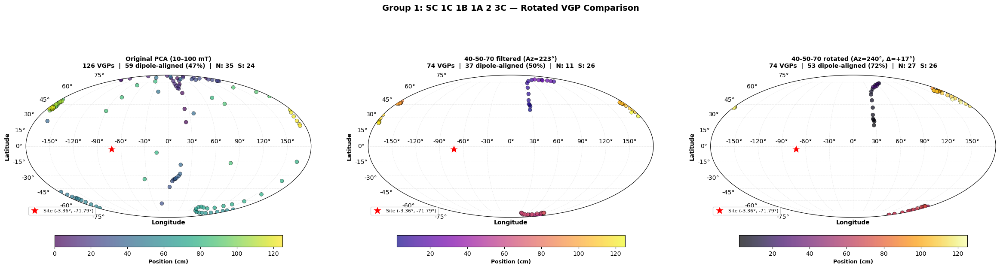

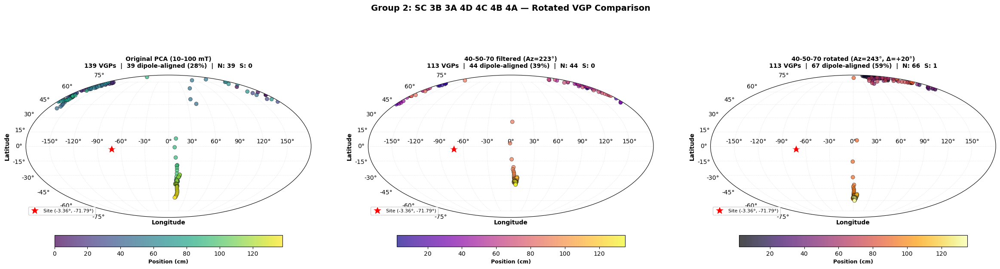

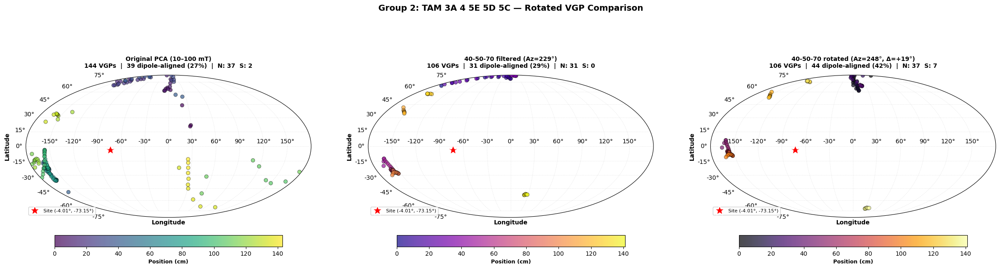

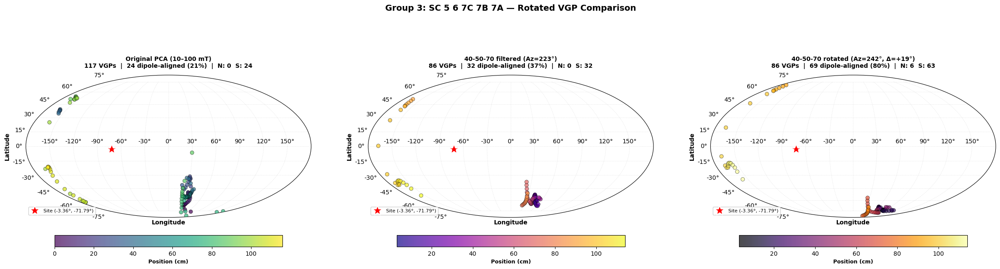

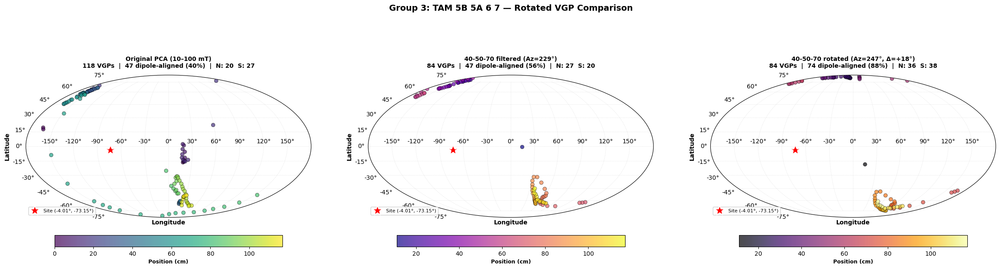

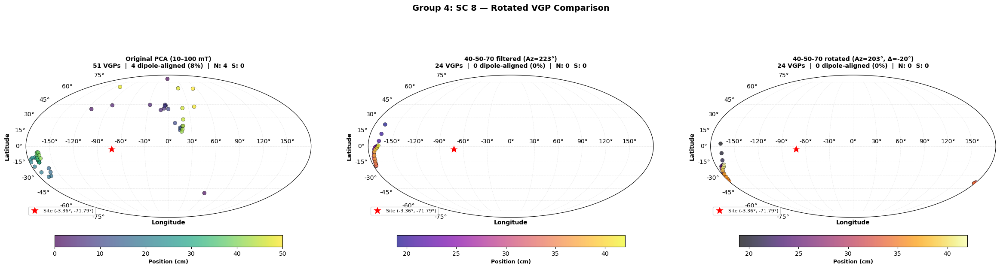

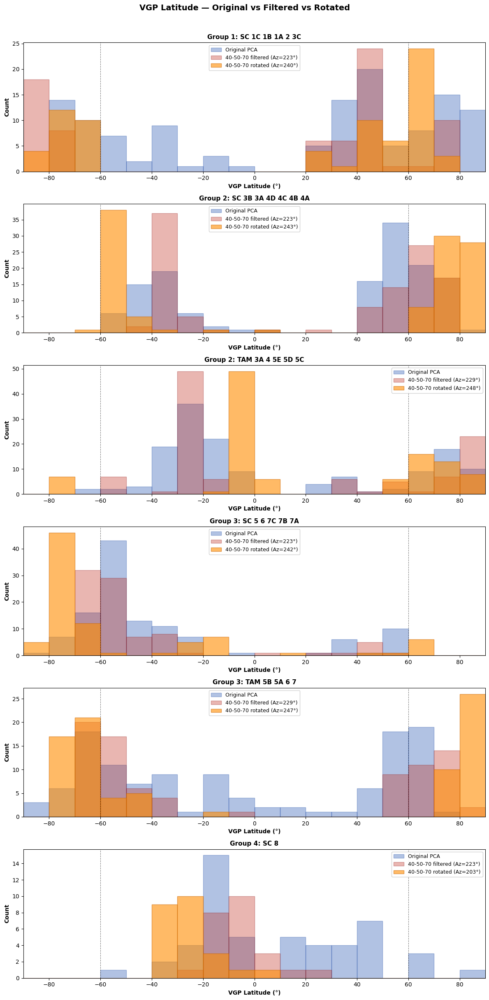


FINAL COMPARISON
  Original PCA (10-100 mT)                        212/695  =  30.5% dipole-aligned  (N-pole: 135, S-pole: 77)
  40-50-70 filtered (current Az)                  191/487  =  39.2% dipole-aligned  (N-pole: 113, S-pole: 78)
  40-50-70 filtered + rotated Az                  307/487  =  63.0% dipole-aligned  (N-pole: 172, S-pole: 135)


In [34]:
"""
Rotated VGPs: apply per-section optimal azimuth offsets from opt_results,
recompute VGPs, and compare to unrotated filtered data.
Requires the azimuth optimisation cell to have been run first.
"""

rotated_results = {}

for gname in sorted(opt_results.keys()):
    o = opt_results[gname]
    r = results[gname]
    site_key = r['site_key']
    site_lat = SITE_COORDS[site_key]['lat']
    site_lon = SITE_COORDS[site_key]['lon']
    delta = o['best_delta']

    # Apply to the filtered 40-50-70 data
    df_filt = r['filt'].copy()
    if len(df_filt) == 0:
        continue

    shifted_decs = (df_filt['Dec'].values + delta) % 360
    rot_vgp_lats = []
    rot_vgp_lons = []
    for d, i in zip(shifted_decs, df_filt['Inc'].values):
        vlat, vlon = compute_vgp(d, i, site_lat, site_lon)
        rot_vgp_lats.append(vlat)
        rot_vgp_lons.append(vlon)

    rot_df = df_filt.copy()
    rot_df['Dec'] = shifted_decs
    rot_df['VGP_Lat.'] = rot_vgp_lats
    rot_df['VGP_Long.'] = rot_vgp_lons

    rotated_results[gname] = {
        'filt': r['filt'],       # unrotated filtered
        'rot': rot_df,           # rotated filtered
        'orig': r['orig'],       # original PCA from file
        'site_key': site_key,
        'delta': delta,
        'new_az': o['best_az'],
        'current_az': o['current_az'],
    }
    print(f"  {gname}: applied Δ = {delta:+.0f}° (Az {o['current_az']:.0f}° → {o['best_az']:.0f}°)")

# ── Summary table ─────────────────────────────────────────────────────
print('\n' + '='*120)
print('ROTATED VGP COMPARISON: Original PCA  |  40-50-70 filtered (current Az)  |  40-50-70 filtered (optimised Az)')
print(f'Dipole threshold: |VGP lat| ≥ {DIPOLE_THRESH}°')
print('='*120)

rot_table = []
rot_totals = {k: [0, 0, 0, 0] for k in ('orig', 'filt', 'rot')}

for gname in sorted(rotated_results.keys()):
    rr = rotated_results[gname]
    row = {'Group': gname, 'Δ Az': f"{rr['delta']:+.0f}°"}
    for tag, key in [('Orig', 'orig'), ('Filt', 'filt'), ('Rotated', 'rot')]:
        lats = rr[key]['VGP_Lat.'].values
        n, dip, pct, npole, spole = _stats(lats)
        row[f'{tag} N'] = n
        row[f'{tag} |VGP|≥60°'] = f'{dip} ({pct:.0f}%)'
        row[f'{tag} N-pole'] = npole
        row[f'{tag} S-pole'] = spole
        rot_totals[key][0] += n
        rot_totals[key][1] += dip
        rot_totals[key][2] += npole
        rot_totals[key][3] += spole
    rot_table.append(row)

# Total row
tot = {'Group': 'TOTAL', 'Δ Az': '—'}
for tag, key in [('Orig', 'orig'), ('Filt', 'filt'), ('Rotated', 'rot')]:
    n, dip, npole, spole = rot_totals[key]
    pct = 100 * dip / n if n else 0
    tot[f'{tag} N'] = n
    tot[f'{tag} |VGP|≥60°'] = f'{dip} ({pct:.0f}%)'
    tot[f'{tag} N-pole'] = npole
    tot[f'{tag} S-pole'] = spole
rot_table.append(tot)
display(pd.DataFrame(rot_table))

# ── 3-column Mollweide: original | filtered | rotated ────────────────
for gname in sorted(rotated_results.keys()):
    rr = rotated_results[gname]
    s_lat = np.deg2rad(SITE_COORDS[rr['site_key']]['lat'])
    s_lon = np.deg2rad(SITE_COORDS[rr['site_key']]['lon'])

    fig = plt.figure(figsize=(24, 7))
    gs_rot = gridspec.GridSpec(1, 3, figure=fig, wspace=0.20,
                               left=0.03, right=0.97, top=0.82, bottom=0.08)

    col_specs = [
        ('Original PCA (10–100 mT)', rr['orig'], 'viridis'),
        (f'40-50-70 filtered (Az={rr["current_az"]:.0f}°)', rr['filt'], 'plasma'),
        (f'40-50-70 rotated (Az={rr["new_az"]:.0f}°, Δ={rr["delta"]:+.0f}°)', rr['rot'], 'inferno'),
    ]

    for col, (label, df, cmap_name) in enumerate(col_specs):
        ax = fig.add_subplot(gs_rot[0, col], projection='mollweide')
        if len(df) == 0:
            ax.set_title(f'{label}\nNo data', fontsize=10, fontweight='bold', pad=12)
            ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
            continue

        positions = df['Position(cm)'].values
        vgp_lons = np.deg2rad(df['VGP_Long.'].values)
        vgp_lats = np.deg2rad(df['VGP_Lat.'].values)

        scatter = ax.scatter(vgp_lons, vgp_lats, c=positions, cmap=cmap_name,
                             s=40, alpha=0.7, edgecolors='black', linewidth=0.5,
                             zorder=5)
        cbar = plt.colorbar(scatter, ax=ax, orientation='horizontal',
                            pad=0.08, shrink=0.8)
        cbar.set_label('Position (cm)', fontsize=9, fontweight='bold')

        ax.plot(s_lon, s_lat, 'r*', markersize=18, zorder=10,
                markeredgecolor='white', markeredgewidth=1.5,
                label=f'Site ({np.rad2deg(s_lat):.2f}°, {np.rad2deg(s_lon):.2f}°)')

        ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
        ax.set_xlabel('Longitude', fontsize=10, fontweight='bold')
        ax.set_ylabel('Latitude', fontsize=10, fontweight='bold')

        lats_deg = df['VGP_Lat.'].values
        n_dip = np.sum(np.abs(lats_deg) >= DIPOLE_THRESH)
        pct = 100 * n_dip / len(lats_deg) if len(lats_deg) else 0
        n_n = np.sum(lats_deg >= DIPOLE_THRESH)
        n_s = np.sum(lats_deg <= -DIPOLE_THRESH)

        ax.set_title(f'{label}\n{len(lats_deg)} VGPs  |  '
                     f'{n_dip} dipole-aligned ({pct:.0f}%)  |  '
                     f'N: {n_n}  S: {n_s}',
                     fontsize=10, fontweight='bold', pad=12)
        ax.legend(loc='lower left', fontsize=8, framealpha=0.9)

    fig.suptitle(f'{gname} — Rotated VGP Comparison', fontsize=14, fontweight='bold', y=0.96)
    plt.show()

# ── VGP latitude histograms: filtered vs rotated ─────────────────────
fig, axes = plt.subplots(len(rotated_results), 1,
                          figsize=(12, 4 * len(rotated_results)), squeeze=False)
for idx, gname in enumerate(sorted(rotated_results.keys())):
    ax = axes[idx, 0]
    rr = rotated_results[gname]
    bins = np.arange(-90, 95, 10)
    ax.hist(rr['orig']['VGP_Lat.'].values, bins=bins, alpha=0.35,
            color='#2050B0', edgecolor='#1040A0', label='Original PCA')
    ax.hist(rr['filt']['VGP_Lat.'].values, bins=bins, alpha=0.35,
            color='#C03020', edgecolor='#901010',
            label=f'40-50-70 filtered (Az={rr["current_az"]:.0f}°)')
    if len(rr['rot']) > 0:
        ax.hist(rr['rot']['VGP_Lat.'].values, bins=bins, alpha=0.6,
                color='#FF8C00', edgecolor='#CC6600',
                label=f'40-50-70 rotated (Az={rr["new_az"]:.0f}°)')
    ax.axvline(DIPOLE_THRESH, color='k', ls='--', lw=0.8, alpha=0.5)
    ax.axvline(-DIPOLE_THRESH, color='k', ls='--', lw=0.8, alpha=0.5)
    ax.set_xlabel('VGP Latitude (°)', fontsize=10, fontweight='bold')
    ax.set_ylabel('Count', fontsize=10, fontweight='bold')
    ax.set_title(gname, fontsize=11, fontweight='bold')
    ax.legend(fontsize=9, framealpha=0.9)
    ax.set_xlim(-90, 90)

fig.suptitle('VGP Latitude — Original vs Filtered vs Rotated',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# ── Final summary ────────────────────────────────────────────────────
print('\n' + '='*100)
print('FINAL COMPARISON')
print('='*100)
for tag, key in [('Original PCA (10-100 mT)', 'orig'),
                 ('40-50-70 filtered (current Az)', 'filt'),
                 ('40-50-70 filtered + rotated Az', 'rot')]:
    n, dip, npole, spole = rot_totals[key]
    pct = 100 * dip / n if n else 0
    print(f'  {tag:45s}  {dip:>4d}/{n:<4d} = {pct:5.1f}% dipole-aligned  '
          f'(N-pole: {npole}, S-pole: {spole})')
print('='*100)

### plot all group inc, dec, mad, intensity and vgp

Rotated VGP data available for 6 groups: ['SC_1C_1B_1A_2_3C_NRM_01212026', 'SC_3B_3A_4D_4C_4B_4A_NRM_01202026', 'TAM_3A_4_5E_5D_5C_NRM_01192026', 'SC_5_6_7C_7B_7A_NRM_01212026', 'TAM_5B_5A_6_7_NRM_01202026', 'SC_8_NRM_01212026']

>>> Group 1: TAM 1 2 3B: using original VGP file (no rotated data available)
Error reading files for Group 1: TAM 1 2 3B: [Errno 2] No such file or directory: '/Users/nicolasanderson/Documents/GitHub/2025_Amazon_Miocene_Magnetostratigraphy/ucheck_spike_removed/dir/pca/PCA - TAM_1_2_3B_NRM_01192026 (100-1000).txt'

>>> Group 2: TAM 3A 4 5E 5D 5C: using 40-50-70 filtered + rotated Az VGPs
Error reading files for Group 2: TAM 3A 4 5E 5D 5C: [Errno 2] No such file or directory: '/Users/nicolasanderson/Documents/GitHub/2025_Amazon_Miocene_Magnetostratigraphy/ucheck_spike_removed/dir/pca/PCA - TAM_3A_4_5E_5D_5C_NRM_01192026 (100-1000).txt'

>>> Group 3: TAM 5B 5A 6 7: using 40-50-70 filtered + rotated Az VGPs
Error reading files for Group 3: TAM 5B 5A 6 7: [Errno 2]

/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_13199/629968437.py:723: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


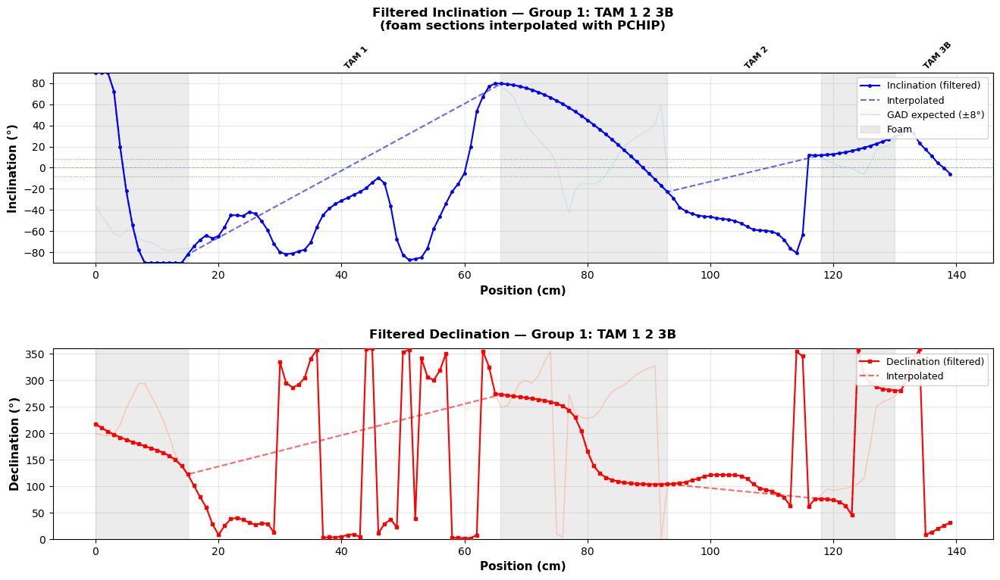

Group 1: TAM 1 2 3B: 83/140 points kept, 57 interpolated (foam sections)


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_13199/629968437.py:723: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


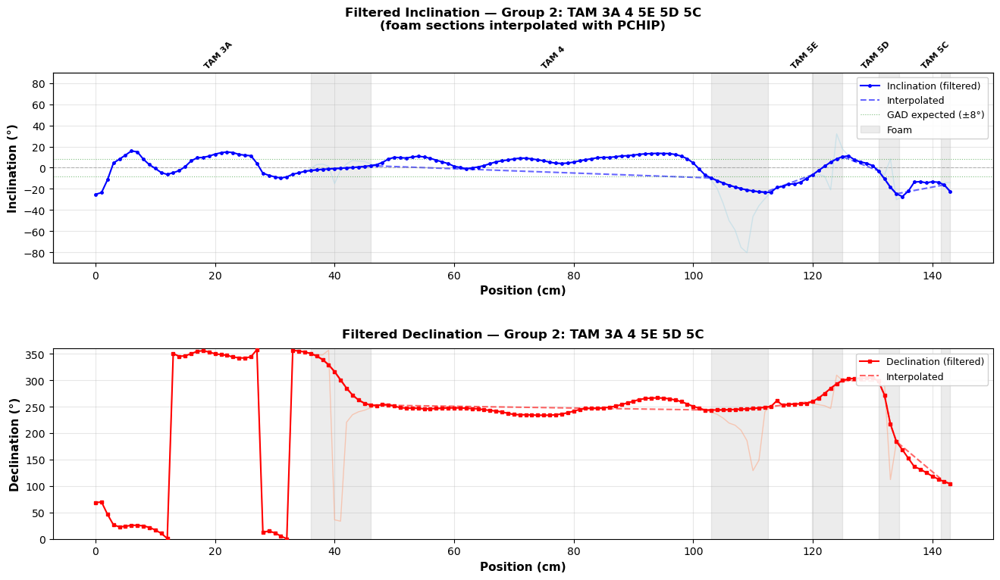

Group 2: TAM 3A 4 5E 5D 5C: 111/144 points kept, 33 interpolated (foam sections)


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_13199/629968437.py:723: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


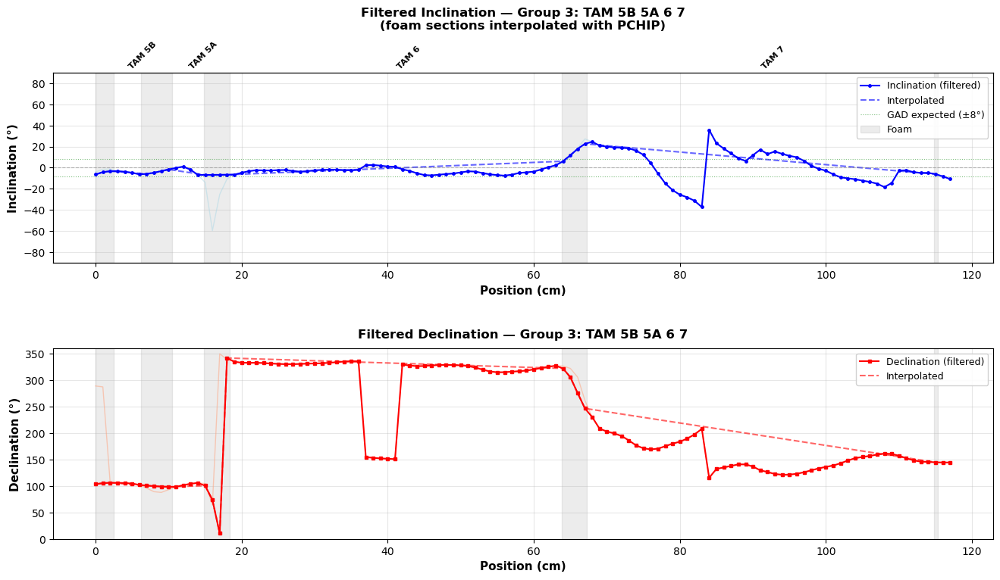

Group 3: TAM 5B 5A 6 7: 102/118 points kept, 16 interpolated (foam sections)


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_13199/629968437.py:723: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


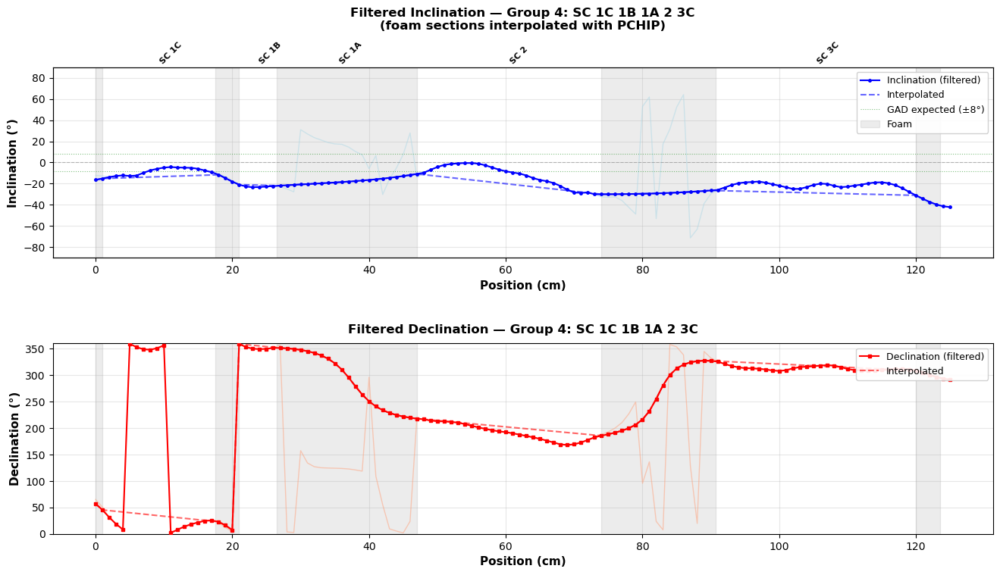

Group 4: SC 1C 1B 1A 2 3C: 78/126 points kept, 48 interpolated (foam sections)


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_13199/629968437.py:723: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


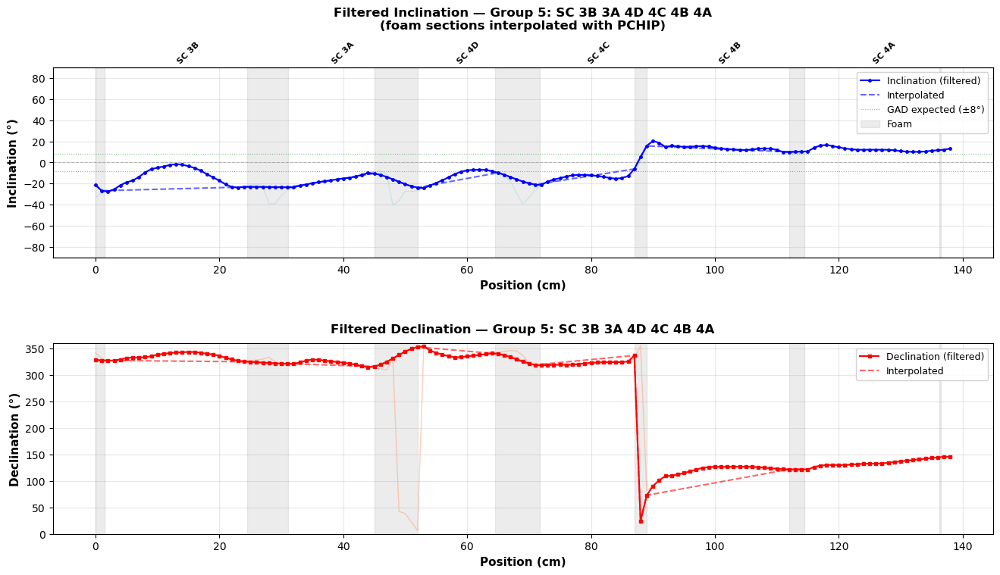

Group 5: SC 3B 3A 4D 4C 4B 4A: 109/139 points kept, 30 interpolated (foam sections)


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_13199/629968437.py:723: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


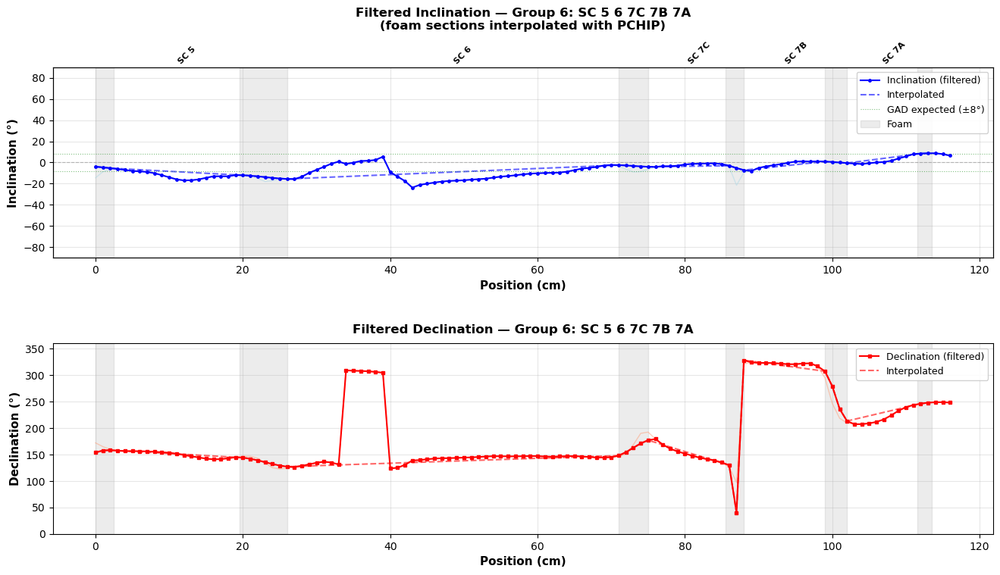

Group 6: SC 5 6 7C 7B 7A: 93/117 points kept, 24 interpolated (foam sections)


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_13199/629968437.py:723: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


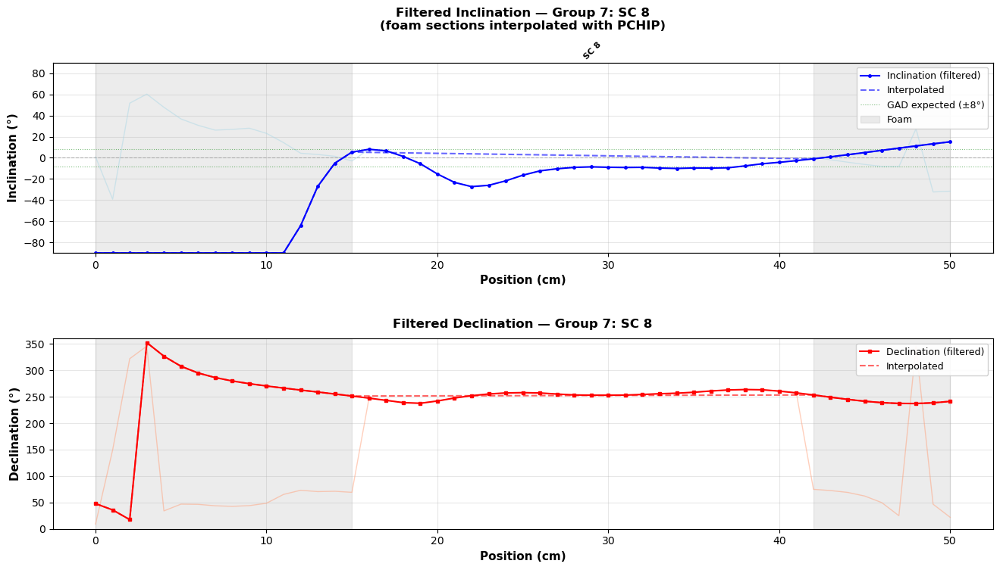

Group 7: SC 8: 26/51 points kept, 25 interpolated (foam sections)


In [35]:
# Build lookup: sample_id → rotated VGP DataFrame
_rotated_vgp_by_sample = {}
if 'rotated_results' in dir() and 'results' in dir():
    for gname, rr in rotated_results.items():
        # sample_id is stored in the results dict, not rotated_results
        sid = results[gname]['sample_id'] if gname in results else None
        if sid is not None and 'rot' in rr and len(rr['rot']) > 0:
            _rotated_vgp_by_sample[sid] = rr['rot']
    print(f"Rotated VGP data available for {len(_rotated_vgp_by_sample)} groups: "
          f"{list(_rotated_vgp_by_sample.keys())}")
else:
    print("No rotated_results found — using original VGP files for all groups")

# all groups — use rotated VGPs where available, fall back to file
for group_name, sample_id in SAMPLE_GROUPS.items():
    vgp_ovr = _rotated_vgp_by_sample.get(sample_id, None)
    if vgp_ovr is not None:
        print(f"\n>>> {group_name}: using 40-50-70 filtered + rotated Az VGPs")
    else:
        print(f"\n>>> {group_name}: using original VGP file (no rotated data available)")
    plot_paleomag_data(group_name, sample_id, vgp_override=vgp_ovr)

# Filtered direction plots (foam + MAD interpolated)
print('\n' + '='*80)
print('FILTERED DIRECTION PLOTS (foam sections interpolated with PCHIP)')
print('='*80 + '\n')
for group_name, sample_id in SAMPLE_GROUPS.items():
    plot_filtered_directions(group_name, sample_id)

## Filtered Paleomagnetic Directions: Site Comparison

Stacks all U-channel groups end-to-end per site (TAM, SC) and plots filtered inclination, declination, MAD, intensity, and susceptibility vs composite depth. Foam zones are PCHIP-interpolated. Per-core polarity zones are shaded (blue = normal, red = reversed, yellow = transitional, grey = poor).

In [36]:
"""
Site-level combined filtered direction plots.
Stacks all groups end-to-end with depth on the y-axis (rotated 90° CW).
Foam sections interpolated with PCHIP; all measured data kept.
"""

# Site definitions: ordered list of (group_name, sample_id)
SITES = {
    'TAM (Tamshiyacu)': [
        ('Group 1: TAM 1 2 3B', 'TAM_1_2_3B_NRM_01192026'),
        ('Group 2: TAM 3A 4 5E 5D 5C', 'TAM_3A_4_5E_5D_5C_NRM_01192026'),
        ('Group 3: TAM 5B 5A 6 7', 'TAM_5B_5A_6_7_NRM_01202026'),
    ],
    'SC (Santa Carina)': [
        ('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026'),
        ('Group 5: SC 3B 3A 4D 4C 4B 4A', 'SC_3B_3A_4D_4C_4B_4A_NRM_01202026'),
        ('Group 6: SC 5 6 7C 7B 7A', 'SC_5_6_7C_7B_7A_NRM_01212026'),
        ('Group 7: SC 8', 'SC_8_NRM_01212026'),
    ],
}

def build_site_data(site_groups):
    """Build concatenated filtered Inc/Dec/MAD/Intensity arrays for a site.
    Groups stacked end-to-end; foam sections PCHIP-interpolated."""
    all_depth = []
    all_inc = []
    all_dec = []
    all_mad = []
    all_int300 = []
    all_interp_mask = []
    all_sus_depth = []
    all_sus_si = []
    all_foam_zones = []
    all_group_boundaries = []
    all_core_ticks = []
    all_core_ranges = []  # (viable_start, viable_end, core_name) in site depth
    depth_offset = 0

    for group_name, sample_id in site_groups:
        paths = get_file_paths(sample_id)
        pca_df = read_pca_file(paths['pca'])
        int_df = read_int_file(paths['int'])

        positions = pca_df['position'].values.copy()
        inc = pca_df['Incl'].values.copy().astype(float)
        dec = pca_df['Decl'].values.copy().astype(float)
        mad = pca_df['MAD'].values.copy().astype(float)

        # Intensity at 300 mT
        if 'Int 300' in int_df.columns:
            int300 = pd.to_numeric(int_df['Int 300'], errors='coerce').values
        else:
            int300 = np.full(len(positions), np.nan)

        foam_zones = get_foam_zones(group_name)

        # Load susceptibility data for this group
        sus_df = load_susceptibility(group_name)
        if sus_df is not None and len(sus_df) > 0:
            sus_pos = sus_df[sus_df['position'] >= 0]['position'].values + depth_offset
            sus_si = sus_df[sus_df['position'] >= 0]['SI'].values
            all_sus_depth.extend(sus_pos)
            all_sus_si.extend(sus_si)

        # Build interpolation mask (foam only)
        keep = np.ones(len(positions), dtype=bool)
        for i, pos in enumerate(positions):
            if is_in_foam(pos, foam_zones):
                keep[i] = False

        # PCHIP interpolation over foam
        if keep.sum() >= 4:
            pchip_inc = PchipInterpolator(positions[keep], inc[keep])
            inc_filtered = pchip_inc(positions)
            inc_filtered = np.clip(inc_filtered, -90, 90)
            dec_rad = np.deg2rad(dec[keep])
            pchip_dx = PchipInterpolator(positions[keep], np.cos(dec_rad))
            pchip_dy = PchipInterpolator(positions[keep], np.sin(dec_rad))
            dec_filtered = np.rad2deg(np.arctan2(pchip_dy(positions), pchip_dx(positions))) % 360
        else:
            inc_filtered = inc
            dec_filtered = dec
            keep[:] = True

        # Shift foam zones to site depth
        for fs, fe in foam_zones:
            all_foam_zones.append((fs + depth_offset, fe + depth_offset))

        # Core label positions
        if group_name in GROUP_CORES:
            x_start = 0
            for name, length, fa, fb in GROUP_CORES[group_name]:
                core_mid = x_start + fa + (length - fa - fb) / 2 + depth_offset
                all_core_ticks.append((core_mid, name))
                all_core_ranges.append((x_start + fa + depth_offset, x_start + length - fb + depth_offset, name))
                x_start += length

        group_total = sum(l for _, l, _, _ in GROUP_CORES.get(group_name, []))
        all_group_boundaries.append((depth_offset, group_name))

        all_depth.extend(positions + depth_offset)
        all_inc.extend(inc_filtered)
        all_dec.extend(dec_filtered)
        all_mad.extend(mad)
        # Align intensity to PCA positions (they should match)
        if len(int300) == len(positions):
            all_int300.extend(int300)
        else:
            all_int300.extend(np.full(len(positions), np.nan))
        all_interp_mask.extend(~keep)

        depth_offset += group_total


    # Compute polarity zones from per-core mean inclination
    polarity_zones = []  # (depth_start, depth_end, polarity)
    d = np.array(all_depth)
    inc_arr = np.array(all_inc)
    mad_arr = np.array(all_mad)
    interp_arr = np.array(all_interp_mask)
    for c_start, c_end, c_name in all_core_ranges:
        mask = (d >= c_start) & (d <= c_end) & (~interp_arr)
        if mask.sum() < 2:
            continue
        mean_inc = np.mean(inc_arr[mask])
        mean_mad = np.mean(mad_arr[mask])
        if mean_mad > 25:
            pol = 'poor'
        elif mean_inc < -3:
            pol = 'normal'
        elif mean_inc > 3:
            pol = 'reversed'
        else:
            pol = 'transitional'
        polarity_zones.append((c_start, c_end, pol))

    # Use per-core polarity zones (no merging across foam gaps)
    return {
        'depth': np.array(all_depth),
        'inc': np.array(all_inc),
        'dec': np.array(all_dec),
        'mad': np.array(all_mad),
        'int300': np.array(all_int300),
        'interp_mask': np.array(all_interp_mask),
        'foam_zones': all_foam_zones,
        'group_boundaries': all_group_boundaries,
        'core_ticks': all_core_ticks,
        'core_ranges': all_core_ranges,
        'sus_depth': np.array(all_sus_depth),
        'sus_si': np.array(all_sus_si),
        'polarity_zones': polarity_zones,
        'total_depth': depth_offset,
    }

def plot_site_panel(ax_dir, ax_mad, site_name, site_groups, legend_loc='lower left'):
    """Plot Inc/Dec vs depth (left) and MAD/Intensity vs depth (right)."""

    data = build_site_data(site_groups)
    depth = data['depth']
    inc = data['inc']
    dec = data['dec']
    mad = data['mad']
    int300 = data['int300']
    interp = data['interp_mask']
    foam_zones = data['foam_zones']
    boundaries = data['group_boundaries']
    core_ticks = data['core_ticks']
    core_ranges = data['core_ranges']
    polarity_zones = data['polarity_zones']
    sus_depth = data['sus_depth']
    sus_si = data['sus_si']
    total_depth = data['total_depth']

    # ===== LEFT PANEL: Inc/Dec =====
    ax_dec_top = ax_dir.twiny()

    # Inclination (bottom x-axis, blue)
    ax_dir.plot(inc, depth, 'b-', linewidth=1.5, label='Inclination')
    # (foam interpolation lines removed for clarity)
    ax_dir.axvline(x=-8, color='green', linewidth=0.8, linestyle=':', alpha=0.6,
                   label='GAD (\u00b18\u00b0)')
    ax_dir.axvline(x=8, color='green', linewidth=0.8, linestyle=':', alpha=0.6)
    ax_dir.axvline(x=0, color='gray', linewidth=0.8, linestyle='--', alpha=0.4)
    ax_dir.set_xlim([-90, 90])
    ax_dir.set_xlabel('Inclination (\u00b0)', fontsize=22, fontweight='bold', color='blue')
    ax_dir.set_ylabel('Depth (cm)', fontsize=22, fontweight='bold')
    ax_dir.tick_params(axis='x', labelcolor='blue', labelsize=16)
    ax_dir.grid(True, alpha=0.3)
    ax_dir.tick_params(axis='both', labelsize=16)

    # Declination (top x-axis, red)
    ax_dec_top.plot(dec, depth, 'r-', linewidth=1.5, label='Declination')
    # (foam interpolation lines removed for clarity)
    ax_dec_top.set_xlim([0, 360])
    ax_dec_top.set_xlabel('Declination (\u00b0)', fontsize=22, fontweight='bold', color='red')
    ax_dec_top.tick_params(axis='x', labelcolor='red', labelsize=16)

    # Mean Inc/Dec per core (thick black horizontal lines)
    first_mean = True
    for c_start, c_end, c_name in core_ranges:
        mask = (depth >= c_start) & (depth <= c_end) & (~interp)
        if mask.sum() < 2:
            continue
        mean_inc = np.mean(inc[mask])
        dec_rad = np.deg2rad(dec[mask])
        mean_dec = np.rad2deg(np.arctan2(np.mean(np.sin(dec_rad)),
                                          np.mean(np.cos(dec_rad)))) % 360
        lbl = 'Core mean' if first_mean else None
        ax_dir.plot([mean_inc, mean_inc], [c_start, c_end],
                    'k-', linewidth=3, alpha=0.7, zorder=4, label=lbl)
        ax_dec_top.plot([mean_dec, mean_dec], [c_start, c_end],
                        'k-', linewidth=3, alpha=0.5, zorder=4)
        # Annotate mean values on right margin
        core_mid = (c_start + c_end) / 2
        ax_dir.annotate(f'I:{mean_inc:+.0f}\u00b0 D:{mean_dec:.0f}\u00b0',
                        xy=(0, 0), xytext=(1.01, core_mid),
                        textcoords=('axes fraction', 'data'),
                        fontsize=12, fontweight='bold', color='black',
                        va='center', ha='left', alpha=0.8,
                        annotation_clip=False)
        first_mean = False

    # ===== RIGHT PANEL: MAD/Intensity =====
    ax_int = ax_mad.twiny()

    # MAD (bottom x-axis, green)
    ax_mad.plot(mad, depth, 'g-', linewidth=1.5, label='MAD')
    ax_mad.axvline(x=20, color='red', linewidth=0.8, linestyle='--', alpha=0.5,
                   label='MAD = 20\u00b0')
    ax_mad.set_xlabel('MAD (\u00b0)', fontsize=22, fontweight='bold', color='green')
    ax_mad.tick_params(axis='x', labelcolor='green', labelsize=16)
    ax_mad.grid(True, alpha=0.3)
    ax_mad.tick_params(axis='both', labelsize=16)

    # Intensity (top x-axis, magenta)
    valid_int = ~np.isnan(int300)
    if valid_int.any():
        ax_int.plot(int300[valid_int], depth[valid_int], 'm-', linewidth=1.5,
                    label='Intensity (300 mT)')
        ax_int.set_xlabel('Intensity at 300 mT (A/m)', fontsize=22,
                          fontweight='bold', color='m')
        ax_int.tick_params(axis='x', labelcolor='m', labelsize=16)
        ax_int.ticklabel_format(style='scientific', axis='x', scilimits=(0, 0))


    # Susceptibility (additional x-axis on MAD panel, orange)
    if len(sus_depth) > 0:
        ax_sus = ax_mad.twiny()
        # Offset the sus axis so it doesn't overlap with intensity axis
        ax_sus.spines['top'].set_position(('axes', 1.06))
        ax_sus.fill_betweenx(sus_depth, 0, sus_si, alpha=0.25,
                               color='orange', label='Susceptibility')
        ax_sus.set_xlabel('Susceptibility (SI)', fontsize=18,
                          fontweight='bold', color='darkorange')
        ax_sus.tick_params(axis='x', labelcolor='darkorange', labelsize=16)
        ax_sus.ticklabel_format(style='scientific', axis='x', scilimits=(0, 0))

    # ===== Polarity zone shading =====
    polarity_colors = {
        'normal': ('blue', 'Normal'),         # blue (consistent with later plots)
        'reversed': ('#dc3545', 'Reversed'),   # red
        'transitional': ('#ffc107', 'Transitional'),  # amber
        'poor': ('#6c757d', 'Poor'),            # grey
    }
    pol_labeled = set()
    for pz_start, pz_end, pol in polarity_zones:
        color, pol_name = polarity_colors.get(pol, ('#e2e3e5', pol))
        lbl = pol_name if pol not in pol_labeled else None
        for ax in [ax_dir, ax_mad]:
            ax.axhspan(pz_start, pz_end, alpha=0.25, color=color,
                       label=lbl if ax == ax_dir else None, zorder=0)
        pol_labeled.add(pol)

    # ===== Shared decorations on both panels =====
    for ax in [ax_dir, ax_mad]:
        for fs, fe in foam_zones:
            ax.axhspan(fs, fe, alpha=0.3, color='grey', zorder=5)
        for bd, gname in boundaries:
            if bd > 0:
                ax.axhline(y=bd, color='black', linewidth=1.5, linestyle='-', alpha=0.7)

    # Group labels on direction panel
    for bd, gname in boundaries:
        short_name = gname.split(':')[0]
        ax_dir.annotate(short_name, xy=(-88, bd + 3), fontsize=16,
                        fontweight='bold', color='black', alpha=0.7,
                        va='top', ha='left')

    # Core labels on right side of MAD panel
    ax_cores = ax_mad.twinx()
    ax_cores.set_ylim(ax_mad.get_ylim())
    core_positions = [pos for pos, _ in core_ticks]
    core_labels = [name for _, name in core_ticks]
    ax_cores.set_yticks(core_positions)
    ax_cores.set_yticklabels(core_labels, fontsize=14, fontweight='bold')
    ax_cores.tick_params(axis='y', length=0, pad=3)
    ax_cores.set_ylabel('')

    # Legends
    h1, l1 = ax_dir.get_legend_handles_labels()
    h2, l2 = ax_dec_top.get_legend_handles_labels()
    ax_dir.legend(h1 + h2, l1 + l2, loc=legend_loc, fontsize=14, framealpha=0.9)
    h3, l3 = ax_mad.get_legend_handles_labels()
    h4, l4 = ax_int.get_legend_handles_labels()
    all_h, all_l = h3 + h4, l3 + l4
    if len(sus_depth) > 0:
        h5, l5 = ax_sus.get_legend_handles_labels()
        all_h, all_l = all_h + h5, all_l + l5
    ax_mad.legend(all_h, all_l, loc=legend_loc, fontsize=14, framealpha=0.9)

    ax_dir.set_title(site_name, fontsize=26, fontweight='bold', pad=60)
    ax_mad.set_title('MAD / Intensity / Sus', fontsize=22, fontweight='bold', pad=60)

    return total_depth


# --- Plot both sites side by side: [TAM dir] [TAM MAD] [SC dir] [SC MAD] ---
site_list = list(SITES.items())
max_depth = max(
    sum(sum(l for _, l, _, _ in GROUP_CORES.get(gn, [])) for gn, _ in sg)
    for _, sg in site_list
)
fig_h = max(20, max_depth * 0.065)

fig, axes = plt.subplots(1, 4, figsize=(38, fig_h),
                          gridspec_kw={'wspace': 0.55,
                                       'width_ratios': [1.2, 0.8, 1.2, 0.8]})

# Set shared y-limits and invert ONCE
for ax in axes:
    ax.set_ylim(max_depth, 0)  # inverted: 0 at top, max at bottom

for col, (site_name, site_groups) in enumerate(site_list):
    ax_dir = axes[col * 2]
    ax_mad = axes[col * 2 + 1]
    leg_loc = 'lower right' if 'SC' in site_name else 'lower left'
    td = plot_site_panel(ax_dir, ax_mad, site_name, site_groups, legend_loc=leg_loc)
    print(f"{site_name}: total depth = {td:.1f} cm")

# Remove duplicate y-labels on inner panels
axes[1].set_ylabel('')
axes[2].set_ylabel('')
axes[3].set_ylabel('')

fig.suptitle('Filtered Paleomagnetic Directions — Site Comparison\n'
             '(foam sections PCHIP-interpolated)',
             fontsize=30, fontweight='bold', y=1.01)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# ═══════════════════════════════════════════════════════════════════════
# INCLINATION-ONLY Site Comparison (same layout as dec comparison)
# ═══════════════════════════════════════════════════════════════════════

def plot_inc_panel(ax_inc, site_name, site_groups, legend_loc='lower left'):
    "Plot inclination-only vs depth with polarity shading."
    data = build_site_data(site_groups)
    depth = data['depth']
    inc = data['inc']
    interp = data['interp_mask']
    foam_zones = data['foam_zones']
    boundaries = data['group_boundaries']
    core_ticks = data['core_ticks']
    core_ranges = data['core_ranges']
    polarity_zones = data['polarity_zones']
    total_depth = data['total_depth']

    # Inclination line
    ax_inc.plot(inc, depth, 'b-', linewidth=1.8, label='Inclination', zorder=3)

    # GAD expected inclination at ~4\u00b0S
    ax_inc.axvline(x=-8, color='steelblue', linewidth=1.2, linestyle=':',
                   alpha=0.6, label='GAD (\u00b18\u00b0)')
    ax_inc.axvline(x=8, color='steelblue', linewidth=1.2, linestyle=':', alpha=0.6)
    ax_inc.axvline(x=0, color='gray', linewidth=0.8, linestyle='--', alpha=0.4)

    ax_inc.set_xlim([-90, 90])
    ax_inc.set_xlabel('Inclination (\u00b0)', fontsize=22, fontweight='bold', color='blue')
    ax_inc.set_ylabel('Depth (cm)', fontsize=22, fontweight='bold')
    ax_inc.tick_params(axis='x', labelcolor='blue', labelsize=16)
    ax_inc.tick_params(axis='both', labelsize=16)
    ax_inc.grid(True, alpha=0.3)

    # Mean Inc per core
    first_mean = True
    for c_start, c_end, c_name in core_ranges:
        mask = (depth >= c_start) & (depth <= c_end) & (~interp)
        if mask.sum() < 2:
            continue
        mean_inc = np.mean(inc[mask])
        lbl = 'Core mean' if first_mean else None
        ax_inc.plot([mean_inc, mean_inc], [c_start, c_end],
                    'k-', linewidth=3, alpha=0.7, zorder=4, label=lbl)
        # Annotate
        core_mid = (c_start + c_end) / 2
        ax_inc.annotate(f'{c_name}: {mean_inc:+.1f}\u00b0',
                        xy=(mean_inc, core_mid),
                        xytext=(5, 0), textcoords='offset points',
                        fontsize=12, fontweight='bold', va='center',
                        ha='left', alpha=0.8)
        first_mean = False

    # Polarity zone shading (blue/red)
    polarity_colors_inc = {
        'normal': ('blue', 'Normal'),
        'reversed': ('#dc3545', 'Reversed'),
        'transitional': ('#ffc107', 'Transitional'),
        'poor': ('#6c757d', 'Poor'),
    }
    pol_labeled = set()
    for pz_start, pz_end, pol in polarity_zones:
        color, pol_name = polarity_colors_inc.get(pol, ('#e2e3e5', pol))
        lbl = pol_name if pol not in pol_labeled else None
        ax_inc.axhspan(pz_start, pz_end, alpha=0.25, color=color,
                       label=lbl, zorder=0)
        pol_labeled.add(pol)

    # Foam zone shading
    for fs, fe in foam_zones:
        ax_inc.axhspan(fs, fe, alpha=0.3, color='grey', zorder=5)

    # Group boundaries
    for bd, gname in boundaries:
        if bd > 0:
            ax_inc.axhline(y=bd, color='black', linewidth=1.5, linestyle='-', alpha=0.7)

    # Group labels
    for bd, gname in boundaries:
        short_name = gname.split(':')[0]
        ax_inc.annotate(short_name, xy=(-88, bd + 3), fontsize=16,
                        fontweight='bold', color='black', alpha=0.7,
                        va='top', ha='left')

    # Core labels on right
    ax_cores = ax_inc.twinx()
    ax_cores.set_ylim(ax_inc.get_ylim())
    core_positions = [pos for pos, _ in core_ticks]
    core_labels = [name for _, name in core_ticks]
    ax_cores.set_yticks(core_positions)
    ax_cores.set_yticklabels(core_labels, fontsize=14, fontweight='bold')
    ax_cores.tick_params(axis='y', length=0, pad=3)
    ax_cores.set_ylabel('')

    ax_inc.legend(loc=legend_loc, fontsize=14, framealpha=0.9)
    ax_inc.set_title(site_name, fontsize=26, fontweight='bold', pad=20)

    return total_depth


# --- Inclination comparison: [TAM inc] [SC inc] ---
fig_inc, axes_inc = plt.subplots(1, 2, figsize=(24, fig_h),
                                  gridspec_kw={'wspace': 0.3,
                                               'width_ratios': [1, 1]})

for ax in axes_inc:
    ax.set_ylim(max_depth, 0)

for col, (site_name, site_groups) in enumerate(site_list):
    leg_loc = 'lower right' if 'SC' in site_name else 'lower left'
    plot_inc_panel(axes_inc[col], site_name, site_groups, legend_loc=leg_loc)

axes_inc[1].set_ylabel('')

fig_inc.suptitle('Filtered Inclination \u2014 Site Comparison\n'
                 '(foam sections PCHIP-interpolated, blue = Normal, red = Reversed)',
                 fontsize=30, fontweight='bold', y=1.01)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()



FileNotFoundError: [Errno 2] No such file or directory: '/Users/nicolasanderson/Documents/GitHub/2025_Amazon_Miocene_Magnetostratigraphy/ucheck_spike_removed/dir/pca/PCA - TAM_1_2_3B_NRM_01192026 (100-1000).txt'

## Wiggle Match to ODP 1237

Age-constrained wiggle matching of TAM and SC polarity records to ODP Leg 202 Site 1237 using three independent magnetic parameters (inclination, declination, intensity). Search grid: sedimentation rates 10–1000 cm/Ma, start ages 10–18 Ma (Pebas Formation window).

### Model I: Inclination — Confidence-Weighted Polarity Correlation + GPTS Reversal Proximity

Joint score = 0.4 × reversal proximity + 0.6 × weighted polarity sign correlation with ODP inclination. Confidence weight = |I| / GAD_INC (8° at ~4°S). Search: 10–18 Ma (unconstrained).

In [ ]:
"""
Wiggle-match TAM & SC polarity records to ODP 1237 (with age model).
Combined approach using age constraints from Salas-Gismondi et al. (2016):
  - Pebas Formation: ~23–10.5 Ma
  - TAM lignite top ≈ MZ8 ≈ 13 Ma

Joint scoring:
  1. Reversal proximity to GPTS boundaries (weight 0.4)
  2. Polarity sign cross-correlation with ODP 1237 (weight 0.6)

Search constrained to 10–18 Ma (Pebas Formation window).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from scipy.interpolate import PchipInterpolator, interp1d
from scipy.ndimage import uniform_filter1d

# ============================================================
# 1. LOAD ODP 1237 DATA
# ============================================================
odp_path = '/Users/nicolasanderson/Library/Mobile Documents/com~apple~CloudDocs/Caltech Projects/Peru/ODP_202_1237_100_290_mag_data.csv'
adm_path = '/Users/nicolasanderson/Library/Mobile Documents/com~apple~CloudDocs/Caltech Projects/Peru/age_depth_model_1237.xlsx'

odp_df = pd.read_csv(odp_path)
odp_20 = odp_df[odp_df['Level'] == 20].copy().sort_values('Depth (mbsf)').reset_index(drop=True)

# Age-depth model (skip header row)
adm_raw = pd.read_excel(adm_path, header=1).dropna(subset=[pd.read_excel(adm_path, header=1).columns[0]])
adm_age = pd.to_numeric(adm_raw.iloc[:, 0], errors='coerce').dropna().values   # Ma
adm_depth = pd.to_numeric(adm_raw.iloc[:, 1], errors='coerce').dropna().values  # mcd

# Build depth-to-age interpolation (linear between tie points)
depth_to_age = interp1d(adm_depth, adm_age, kind='linear', fill_value='extrapolate')

# Convert ODP depths to age
odp_20['Age_Ma'] = depth_to_age(odp_20['Depth (mbsf)'].values)

# Smooth ODP inclination: 0.5m bins then 5-bin moving average (~2.5m window)
odp_20['depth_bin'] = (odp_20['Depth (mbsf)'] * 2).round() / 2
odp_binned = odp_20.groupby('depth_bin').agg({
    'Incl.': 'median',
    'Depth (mbsf)': 'mean',
    'Age_Ma': 'mean',
    'Intensity': 'median'
}).reset_index().sort_values('depth_bin')
odp_binned['Inc_smooth'] = uniform_filter1d(odp_binned['Incl.'].values, size=5)

print(f"ODP 1237: {len(odp_binned)} binned points, "
      f"age range {odp_binned['Age_Ma'].min():.1f}–{odp_binned['Age_Ma'].max():.1f} Ma")

# ============================================================
# 2. BUILD SITE DATA
# ============================================================
site_data = {}
for site_name, site_groups in SITES.items():
    data = build_site_data(site_groups)
    site_data[site_name] = data

    depth = data['depth']
    inc = data['inc']
    interp_mask = data['interp_mask']
    polarity_zones = data['polarity_zones']
    core_ranges = data['core_ranges']

    print(f"\n{site_name}: total depth = {data['total_depth']:.1f} cm")
    print(f"  Per-core polarity:")
    for pz_start, pz_end, pol in polarity_zones:
        core_name = ''
        for cs, ce, cn in core_ranges:
            if abs(cs - pz_start) < 1:
                core_name = cn
                break
        thickness = pz_end - pz_start
        mask = (depth >= pz_start) & (depth <= pz_end) & (~interp_mask)
        mean_inc = np.mean(inc[mask]) if mask.sum() > 0 else np.nan
        print(f"    {core_name:8s}  {pz_start:7.1f}–{pz_end:7.1f} cm  "
              f"({thickness:5.1f} cm)  {pol:13s}  mean_inc={mean_inc:+.1f}°")

# ============================================================
# 3. GPTS (GTS2012) — Miocene reversal boundaries
# ============================================================
GPTS_MIOCENE = [
    ('C3n.1n',   4.187,  4.300, 'N'), ('C3n.1r',   4.300,  4.493, 'R'),
    ('C3n.2n',   4.493,  4.631, 'N'), ('C3n.2r',   4.631,  4.799, 'R'),
    ('C3n.3n',   4.799,  4.896, 'N'), ('C3n.3r',   4.896,  4.997, 'R'),
    ('C3n.4n',   4.997,  5.235, 'N'), ('C3r',      5.235,  5.587, 'R'),
    ('C3An.1n',  5.587,  6.033, 'N'), ('C3An.1r',  6.033,  6.252, 'R'),
    ('C3An.2n',  6.252,  6.436, 'N'), ('C3Ar',     6.436,  6.733, 'R'),
    ('C3Bn',     6.733,  7.140, 'N'), ('C3Br.1r',  7.140,  7.212, 'R'),
    ('C3Br.1n',  7.212,  7.251, 'N'), ('C3Br.2r',  7.251,  7.285, 'R'),
    ('C3Br.2n',  7.285,  7.454, 'N'), ('C4n.1r',   7.454,  7.489, 'R'),
    ('C4n.1n',   7.489,  7.528, 'N'), ('C4n.2r',   7.528,  7.642, 'R'),
    ('C4n.2n',   7.642,  8.072, 'N'), ('C4r.1r',   8.072,  8.225, 'R'),
    ('C4r.1n',   8.225,  8.257, 'N'), ('C4r.2r',   8.257,  8.699, 'R'),
    ('C4An',     8.699,  9.025, 'N'), ('C4Ar.1r',  9.025,  9.097, 'R'),
    ('C4Ar.1n',  9.097,  9.117, 'N'), ('C4Ar.2r',  9.117,  9.779, 'R'),
    ('C5n.1n',   9.779,  9.934, 'N'), ('C5n.1r',   9.934,  9.987, 'R'),
    ('C5n.2n',   9.987, 11.040, 'N'), ('C5r.1r',  11.040, 11.118, 'R'),
    ('C5r.1n',  11.118, 11.154, 'N'), ('C5r.2r',  11.154, 11.554, 'R'),
    ('C5r.3r',  11.554, 11.614, 'R'), ('C5An.1n', 11.614, 12.014, 'N'),
    ('C5An.2n', 12.014, 12.116, 'N'), ('C5Ar.1r', 12.116, 12.207, 'R'),
    ('C5Ar.2r', 12.207, 12.415, 'R'), ('C5AAn',   12.415, 12.730, 'N'),
    ('C5AAr',   12.730, 12.765, 'R'), ('C5ABn',   12.765, 12.820, 'N'),
    ('C5ABr',   12.820, 12.991, 'R'), ('C5ACn',   12.991, 13.139, 'N'),
    ('C5ACr',   13.139, 13.302, 'R'), ('C5ADn',   13.302, 13.510, 'N'),
    ('C5ADr',   13.510, 13.703, 'R'), ('C5Bn.1n', 13.703, 14.076, 'N'),
    ('C5Bn.2n', 14.076, 14.178, 'N'), ('C5Br',    14.178, 14.612, 'R'),
    ('C5Cn.1n', 14.612, 14.800, 'N'), ('C5Cn.2n', 14.800, 14.888, 'N'),
    ('C5Cn.3n', 14.888, 15.034, 'N'), ('C5Cr',    15.034, 15.155, 'R'),
    ('C5Dn',    15.155, 15.974, 'N'), ('C5Dr.1r', 15.974, 16.268, 'R'),
    ('C5Dr.1n', 16.268, 16.303, 'N'), ('C5Dr.2r', 16.303, 16.472, 'R'),
    ('C5En',    16.472, 18.056, 'N'), ('C5Er',    18.056, 18.524, 'R'),
    ('C6n',     18.524, 18.748, 'N'), ('C6r',     18.748, 19.722, 'R'),
    ('C6An.1n', 19.722, 20.040, 'N'), ('C6An.1r', 20.040, 20.213, 'R'),
    ('C6An.2n', 20.213, 20.439, 'N'), ('C6Ar',    20.439, 20.709, 'R'),
    ('C6AAn',   20.709, 21.083, 'N'), ('C6AAr.1r',21.083, 21.159, 'R'),
    ('C6AAr.2r',21.159, 21.659, 'R'), ('C6Bn.1n', 21.659, 21.688, 'N'),
    ('C6Bn.2n', 21.688, 21.767, 'N'), ('C6Br',    21.767, 21.936, 'R'),
    ('C6Cn.1n', 21.936, 22.268, 'N'), ('C6Cn.2n', 22.268, 22.564, 'N'),
    ('C6Cn.3n', 22.564, 22.758, 'N'), ('C6Cr',    22.758, 23.030, 'R'),
]

# Extract reversal boundaries (transitions between N and R)
reversals = []
for i in range(1, len(GPTS_MIOCENE)):
    prev_pol = GPTS_MIOCENE[i-1][3]
    curr_pol = GPTS_MIOCENE[i][3]
    if prev_pol != curr_pol:
        boundary_age = GPTS_MIOCENE[i][1]
        direction = f"{prev_pol}→{curr_pol}"
        name_from = GPTS_MIOCENE[i-1][0]
        name_to = GPTS_MIOCENE[i][0]
        reversals.append({
            'age': boundary_age,
            'direction': direction,
            'from': name_from,
            'to': name_to,
        })

reversal_ages_gpts = np.array([r['age'] for r in reversals])
print(f"\nGPTS: {len(reversals)} reversal boundaries in 4.2–23.0 Ma")

# ============================================================
# 4. ODP POLARITY ON UNIFORM AGE GRID (for cross-correlation)
# ============================================================
age_grid = np.arange(5, 23, 0.005)  # 5 kyr resolution
odp_age_sorted = odp_binned.sort_values('Age_Ma')
odp_inc_interp = np.interp(age_grid, odp_age_sorted['Age_Ma'].values,
                            odp_age_sorted['Inc_smooth'].values)
odp_pol_sign = np.sign(odp_inc_interp)

# ============================================================
# 5. COMBINED APPROACH — JOINT SCORING
# ============================================================
# Constrained search: 10–18 Ma (Pebas Formation window)
# Joint score = 0.4 * reversal_score + 0.6 * polarity_correlation
print("\n" + "="*80)
print("COMBINED APPROACH: Joint Reversal + Correlation Scoring")
print("Age window constrained to 10–18 Ma (Pebas Formation)")
print("Joint = 0.4 × reversal_score + 0.6 × polarity_correlation")
print("="*80)

pol_map = {'normal': -1, 'reversed': 1, 'transitional': 0, 'poor': np.nan}
pol_colors = {'normal': '#28a745', 'reversed': '#dc3545',
              'transitional': '#ffc107', 'poor': '#6c757d'}

# Search parameters
SR_MIN, SR_MAX, SR_STEP = 10, 1000, 2
AGE_MIN, AGE_MAX, AGE_STEP = 10.0, 18.0, 0.005
sed_rates = np.arange(SR_MIN, SR_MAX + 1, SR_STEP)
start_ages = np.arange(AGE_MIN, AGE_MAX, AGE_STEP)

site_best_fits = {}
site_top3_inc = {}

fig1, axes1 = plt.subplots(2, 3, figsize=(26, 16))

for row, (site_key, site_label, color) in enumerate(
        [('TAM (Tamshiyacu)', 'TAM', 'blue'), ('SC (Santa Carina)', 'SC', 'darkorange')]):

    data = site_data[site_key]
    depth = data['depth']
    inc = data['inc']
    total_depth = data['total_depth']
    polarity_zones = data['polarity_zones']

    # --- Find polarity flip depths ---
    flip_depths = []
    flip_directions = []
    for i in range(1, len(polarity_zones)):
        p_prev = polarity_zones[i-1][2]
        p_curr = polarity_zones[i][2]
        if p_prev == 'poor' or p_curr == 'poor':
            continue
        s_prev = pol_map[p_prev]
        s_curr = pol_map[p_curr]
        if s_prev != s_curr and s_prev != 0 and s_curr != 0:
            fd = (polarity_zones[i-1][1] + polarity_zones[i][0]) / 2
            p1 = 'N' if s_prev < 0 else 'R'
            p2 = 'N' if s_curr < 0 else 'R'
            flip_depths.append(fd)
            flip_directions.append(f"{p1}→{p2}")
        elif s_prev != s_curr:
            fd = (polarity_zones[i-1][1] + polarity_zones[i][0]) / 2
            p1 = 'N' if s_prev < 0 else ('R' if s_prev > 0 else 'T')
            p2 = 'N' if s_curr < 0 else ('R' if s_curr > 0 else 'T')
            flip_depths.append(fd)
            flip_directions.append(f"{p1}→{p2}")

    has_flips = len(flip_depths) > 0
    flip_depths_arr = np.array(flip_depths) if has_flips else np.array([])

    print(f"\n{site_label}: {len(flip_depths)} polarity transitions, total depth {total_depth:.1f} cm")
    for fd, fdir in zip(flip_depths, flip_directions):
        print(f"  depth={fd:.1f} cm  {fdir}")

    # --- Site polarity at 1cm resolution for cross-correlation ---
    depth_grid_site = np.arange(0, total_depth, 1.0)
    inc_site = np.interp(depth_grid_site, depth, inc)
    site_pol = np.sign(inc_site)

    # Confidence weights: |inc| / expected GAD inc at ~4°S (8°)
    # Caps at 1.0; near-zero inclination → low weight
    GAD_INC = 8.0
    site_weights = np.clip(np.abs(inc_site) / GAD_INC, 0.0, 1.0)

    # --- Scan all (sed_rate, start_age) combinations ---
    all_results = []

    for sr in sed_rates:
        site_dur = total_depth / sr  # Ma
        n_pts = int(site_dur / 0.005)  # match age_grid resolution
        if n_pts < 3:
            continue

        # Resample site polarity and weights to age spacing
        site_age_rel = depth_grid_site / sr
        site_age_g = np.linspace(0, site_dur, n_pts)
        site_pol_r = np.interp(site_age_g, site_age_rel, site_pol)
        site_wt_r = np.interp(site_age_g, site_age_rel, site_weights)

        for sa in start_ages:
            age_end = sa + site_dur
            if age_end > 23.0:
                continue

            # --- Reversal proximity score ---
            if has_flips:
                flip_ages = sa + flip_depths_arr / sr
                dists = [np.min(np.abs(reversal_ages_gpts - fa)) for fa in flip_ages]
                avg_dist = np.mean(dists)
            else:
                avg_dist = 0.5  # penalty for no flips

            # --- Cross-correlation with ODP polarity ---
            # Find where this age window sits on the age_grid
            idx_start = int((sa - 5.0) / 0.005)
            idx_end = idx_start + n_pts
            if idx_start < 0 or idx_end > len(odp_pol_sign):
                continue

            odp_segment = odp_pol_sign[idx_start:idx_end]
            # Weighted correlation: sign agreement weighted by inclination confidence
            wt_sum = np.sum(site_wt_r)
            if wt_sum > 0:
                corr = np.sum(site_wt_r * site_pol_r * odp_segment) / wt_sum
            else:
                corr = 0.0

            all_results.append({
                'sed_rate': sr,
                'start_age': sa,
                'end_age': age_end,
                'avg_dist_Ma': avg_dist,
                'correlation': corr,
            })

    res_df = pd.DataFrame(all_results)
    print(f"  Scanned {len(res_df)} (sed_rate, start_age) combinations")

    if len(res_df) == 0:
        print(f"  WARNING: no valid combinations found for {site_label}")
        for ax in axes1[row]:
            ax.text(0.5, 0.5, 'No results', transform=ax.transAxes, ha='center', fontsize=14)
        continue

    # --- Normalize reversal score: 0 (worst) to 1 (best) ---
    max_dist = res_df['avg_dist_Ma'].max()
    if max_dist > 0:
        res_df['rev_score'] = 1.0 - (res_df['avg_dist_Ma'] / max_dist)
    else:
        res_df['rev_score'] = 1.0

    # --- Normalize correlation to 0–1 range ---
    corr_min = res_df['correlation'].min()
    corr_max = res_df['correlation'].max()
    if corr_max > corr_min:
        res_df['corr_norm'] = (res_df['correlation'] - corr_min) / (corr_max - corr_min)
    else:
        res_df['corr_norm'] = 0.5

    # --- Joint score ---
    res_df['joint'] = 0.4 * res_df['rev_score'] + 0.6 * res_df['corr_norm']

    # Best result
    best_idx = res_df['joint'].idxmax()
    best = res_df.loc[best_idx]
    site_best_fits[site_key] = {
        'start_age': best['start_age'],
        'sed_rate': best['sed_rate'],
        'joint': best['joint'],
        'avg_dist': best['avg_dist_Ma'],
        'correlation': best['correlation'],
    }

    print(f"\n  BEST FIT: start={best['start_age']:.3f} Ma, end={best['end_age']:.3f} Ma, "
          f"SR={best['sed_rate']:.0f} cm/Ma")
    print(f"    Joint score = {best['joint']:.4f}  "
          f"(rev_score={best['rev_score']:.4f}, corr={best['correlation']:.4f})")
    print(f"    Avg reversal distance = {best['avg_dist_Ma']*1000:.1f} kyr")

    # --- Top 10 results ---
    top10 = res_df.nsmallest(10, 'joint', keep='first')
    top10 = res_df.nlargest(10, 'joint')
    site_top3_inc[site_key] = res_df.nlargest(3, 'joint').copy()
    print(f"\n  Top 10 joint-score results:")
    print(f"  {'Rank':>4s}  {'SR':>6s}  {'Start':>7s}  {'End':>7s}  "
          f"{'Joint':>7s}  {'RevDist':>8s}  {'Corr':>7s}")
    for rank, (_, r) in enumerate(top10.iterrows(), 1):
        print(f"  {rank:4d}  {r['sed_rate']:6.0f}  {r['start_age']:7.3f}  {r['end_age']:7.3f}  "
              f"{r['joint']:7.4f}  {r['avg_dist_Ma']*1000:7.1f}kyr  {r['correlation']:7.4f}")
        if rank == 1 and has_flips:
            flip_ages = r['start_age'] + flip_depths_arr / r['sed_rate']
            for fa, fdir in zip(flip_ages, flip_directions):
                nearest_idx = np.argmin(np.abs(reversal_ages_gpts - fa))
                nr = reversals[nearest_idx]
                print(f"         ↳ {fdir} @ {fa:.3f} Ma → "
                      f"{nr['from']}/{nr['to']} ({nr['age']:.3f} Ma, "
                      f"Δ={abs(fa-nr['age'])*1000:.0f} kyr)")

    # ==========================================================
    # PLOT 1: Joint score vs start age (colored by sed rate)
    # ==========================================================
    ax1 = axes1[row, 0]
    # For each start_age, find the best joint score across all sed rates
    best_per_age = res_df.loc[res_df.groupby('start_age')['joint'].idxmax()]
    scatter1 = ax1.scatter(best_per_age['start_age'], best_per_age['joint'],
                           c=best_per_age['sed_rate'], cmap='plasma', s=10, alpha=0.7)
    cbar1 = plt.colorbar(scatter1, ax=ax1, label='Sed rate (cm/Ma)')
    cbar1.ax.tick_params(labelsize=10)

    # Mark the best
    ax1.scatter([best['start_age']], [best['joint']], marker='*', s=400,
                c='red', edgecolors='black', linewidths=1.5, zorder=10)
    ax1.annotate(f"SR={best['sed_rate']:.0f}\n{best['start_age']:.2f} Ma",
                 xy=(best['start_age'], best['joint']),
                 xytext=(best['start_age'] + 0.5, best['joint'] - 0.05),
                 fontsize=11, fontweight='bold', color='red',
                 arrowprops=dict(arrowstyle='->', color='red'))

    ax1.set_xlabel('Start age (Ma)', fontsize=13, fontweight='bold')
    ax1.set_ylabel('Joint score', fontsize=13, fontweight='bold')
    ax1.set_title(f'{site_label}: Joint Score vs Start Age\n(best per age, colored by SR)',
                  fontsize=14, fontweight='bold')
    ax1.set_xlim([AGE_MIN, AGE_MAX])
    ax1.grid(True, alpha=0.3)
    ax1.tick_params(labelsize=11)

    # ==========================================================
    # PLOT 2: Reversal distance vs correlation (2D diagnostic)
    # ==========================================================
    ax2 = axes1[row, 1]
    # Subsample for clarity
    subsample = res_df.sample(n=min(5000, len(res_df)), random_state=42)
    scatter2 = ax2.scatter(subsample['correlation'], subsample['avg_dist_Ma'] * 1000,
                           c=subsample['start_age'], cmap='viridis', s=8, alpha=0.4)
    cbar2 = plt.colorbar(scatter2, ax=ax2, label='Start age (Ma)')
    cbar2.ax.tick_params(labelsize=10)

    # Mark top 10
    ax2.scatter(top10['correlation'], top10['avg_dist_Ma'] * 1000,
                edgecolors='red', facecolors='none', s=120, linewidths=2, zorder=5)
    # Mark best
    ax2.scatter([best['correlation']], [best['avg_dist_Ma'] * 1000],
                marker='*', s=400, c='red', edgecolors='black', linewidths=1.5, zorder=10)

    ax2.set_xlabel('Polarity correlation with ODP 1237', fontsize=13, fontweight='bold')
    ax2.set_ylabel('Avg distance to GPTS reversal (kyr)', fontsize=13, fontweight='bold')
    ax2.set_title(f'{site_label}: Reversal Fit vs ODP Correlation\n'
                  f'(red circles = top 10, star = best)',
                  fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.tick_params(labelsize=11)

    # ==========================================================
    # PLOT 3: Best-fit inclination overlay on ODP
    # ==========================================================
    ax3 = axes1[row, 2]
    # ODP background
    ax3.plot(odp_binned['Age_Ma'], odp_binned['Inc_smooth'],
             'k-', linewidth=0.8, alpha=0.4, label='ODP 1237')
    ax3.fill_between(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                      where=odp_binned['Inc_smooth'] < 0, color='lightblue', alpha=0.2)
    ax3.fill_between(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                      where=odp_binned['Inc_smooth'] > 0, color='lightsalmon', alpha=0.2)

    # Overlay site inclination at best-fit age
    site_ages_plot = best['start_age'] + depth / best['sed_rate']
    scale = 4.0
    ax3.plot(site_ages_plot, inc * scale, '-', color=color, linewidth=2,
             label=f'{site_label} (inc ×{scale:.0f})', alpha=0.8)

    # Polarity shading for site
    for pz_start, pz_end, pol in polarity_zones:
        a_s = best['start_age'] + pz_start / best['sed_rate']
        a_e = best['start_age'] + pz_end / best['sed_rate']
        ax3.axvspan(a_s, a_e, alpha=0.15, color=pol_colors.get(pol, '#e2e3e5'), zorder=0)

    ax3.axhline(0, color='grey', linewidth=0.5, linestyle='--')
    ax3.set_xlim([AGE_MIN - 0.5, AGE_MAX + 0.5])
    ax3.set_ylim([-60, 60])
    ax3.set_xlabel('Age (Ma)', fontsize=13, fontweight='bold')
    ax3.set_ylabel('Inclination (°)', fontsize=13, fontweight='bold')
    end_age = best['start_age'] + total_depth / best['sed_rate']
    ax3.set_title(f'{site_label}: Best Fit on ODP 1237\n'
                  f'{best["start_age"]:.2f}–{end_age:.2f} Ma, '
                  f'SR={best["sed_rate"]:.0f} cm/Ma, '
                  f'r={best["correlation"]:.3f}',
                  fontsize=14, fontweight='bold')
    ax3.legend(fontsize=11, loc='upper left')
    ax3.grid(True, alpha=0.3)
    ax3.tick_params(labelsize=11)

fig1.suptitle('Combined Approach: Joint Reversal + Correlation Scoring (10–18 Ma)',
              fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================================
# 6. SUMMARY COMPARISON PANEL — 6 panels on same age axis
# ============================================================
print("\n" + "="*80)
print("SUMMARY COMPARISON: ODP + GPTS + TAM + SC (12–15 Ma)")
print("="*80)

fig2, axes2 = plt.subplots(1, 6, figsize=(32, 30),
                            gridspec_kw={'width_ratios': [1.5, 1.5, 0.3, 0.5, 0.5, 0.3],
                                         'wspace': 0.18})
ax_odp_raw, ax_odp, ax_gpts1, ax_tam, ax_sc, ax_gpts2 = axes2

AGE_ZOOM_MIN, AGE_ZOOM_MAX = 12.0, 15.0

# --- Panel 0: ODP 1237 RAW (unsmoothed) ---
ax_odp_raw.plot(odp_20['Incl.'], odp_20['Age_Ma'], 'k-', linewidth=0.3, alpha=0.4)
ax_odp_raw.scatter(odp_20['Incl.'], odp_20['Age_Ma'], c=np.where(odp_20['Incl.'] < 0, 'blue', 'red'),
                    s=2, alpha=0.5, zorder=2)
ax_odp_raw.fill_betweenx(odp_20['Age_Ma'].values, 0, odp_20['Incl.'].values,
                          where=odp_20['Incl.'].values < 0, color='blue', alpha=0.15)
ax_odp_raw.fill_betweenx(odp_20['Age_Ma'].values, 0, odp_20['Incl.'].values,
                          where=odp_20['Incl.'].values > 0, color='red', alpha=0.15)
ax_odp_raw.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax_odp_raw.set_xlabel('Inclination (°)', fontsize=14, fontweight='bold')
ax_odp_raw.set_ylabel('Age (Ma)', fontsize=14, fontweight='bold')
ax_odp_raw.set_title('ODP 1237\nRaw Inc (20 mT)', fontsize=16, fontweight='bold')
ax_odp_raw.set_xlim([-60, 60])
ax_odp_raw.grid(True, alpha=0.3)
ax_odp_raw.tick_params(labelsize=12)

# --- Panel 1: ODP 1237 SMOOTHED ---
ax_odp.plot(odp_binned['Inc_smooth'], odp_binned['Age_Ma'], 'k-', linewidth=0.8, alpha=0.6)
ax_odp.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                      where=odp_binned['Inc_smooth'] < 0, color='blue', alpha=0.3, label='Normal')
ax_odp.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                      where=odp_binned['Inc_smooth'] > 0, color='red', alpha=0.3, label='Reversed')
ax_odp.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax_odp.set_xlabel('Inclination (°)', fontsize=14, fontweight='bold')
ax_odp.set_title('ODP 1237\nSmoothed Inc (20 mT)', fontsize=16, fontweight='bold')
ax_odp.set_xlim([-60, 60])
ax_odp.legend(fontsize=11, loc='lower left')
ax_odp.grid(True, alpha=0.3)
ax_odp.tick_params(labelsize=12)

# --- Panels 2 & 5: GPTS columns (only draw chrons in view) ---
for ax_gpts in [ax_gpts1, ax_gpts2]:
    for chron, start, end, pol in GPTS_MIOCENE:
        if end < AGE_ZOOM_MIN or start > AGE_ZOOM_MAX:
            continue
        clr = 'black' if pol == 'N' else 'white'
        ax_gpts.axhspan(start, end, color=clr, edgecolor='grey', linewidth=0.3)
        if (end - start) > 0.12:
            mid = max(AGE_ZOOM_MIN, start) / 2 + min(AGE_ZOOM_MAX, end) / 2
            ax_gpts.text(0.5, mid, chron, fontsize=6, ha='center', va='center',
                         color='white' if pol == 'N' else 'black', fontweight='bold',
                         clip_on=True)
    ax_gpts.set_xlim([0, 1])
    ax_gpts.set_xticks([])
    ax_gpts.set_title('GPTS\n(GTS2012)', fontsize=14, fontweight='bold')

# --- Panels 3 & 4: Site inclination mapped to age ---
site_plot_info = [
    (ax_tam, 'TAM (Tamshiyacu)', 'TAM', 'blue'),
    (ax_sc, 'SC (Santa Carina)', 'SC', 'darkorange'),
]

for ax_site, site_key, site_label, clr in site_plot_info:
    if site_key not in site_best_fits:
        ax_site.text(0.5, 0.5, 'No fit', transform=ax_site.transAxes,
                     ha='center', fontsize=14)
        ax_site.set_title(site_label, fontsize=16, fontweight='bold')
        continue

    data = site_data[site_key]
    bf = site_best_fits[site_key]
    depth_s = data['depth']
    inc_s = data['inc']
    total_depth_s = data['total_depth']

    # Map depth to age
    ages_s = bf['start_age'] + depth_s / bf['sed_rate']

    ax_site.plot(inc_s, ages_s, '-', color=clr, linewidth=1.5, alpha=0.8)
    ax_site.axvline(0, color='grey', linewidth=0.5, linestyle='--')
    ax_site.axvline(-8, color='green', linewidth=0.5, linestyle=':', alpha=0.5)
    ax_site.axvline(8, color='green', linewidth=0.5, linestyle=':', alpha=0.5)
    ax_site.set_xlim([-60, 60])
    ax_site.set_xlabel('Inc (°)', fontsize=12, fontweight='bold')

    # Polarity zone shading
    for pz_start, pz_end, pol in data['polarity_zones']:
        age_s_pz = bf['start_age'] + pz_start / bf['sed_rate']
        age_e_pz = bf['start_age'] + pz_end / bf['sed_rate']
        ax_site.axhspan(age_s_pz, age_e_pz, alpha=0.2,
                        color=pol_colors.get(pol, '#e2e3e5'), zorder=0)

    # Foam zones
    for fs, fe in data['foam_zones']:
        age_s_f = bf['start_age'] + fs / bf['sed_rate']
        age_e_f = bf['start_age'] + fe / bf['sed_rate']
        ax_site.axhspan(age_s_f, age_e_f, alpha=0.2, color='grey', zorder=3)

    # Core labels
    for pos, name in data['core_ticks']:
        age_pos = bf['start_age'] + pos / bf['sed_rate']
        ax_site.annotate(name, xy=(1.02, age_pos), xycoords=('axes fraction', 'data'),
                        fontsize=8, va='center', fontweight='bold', annotation_clip=False)

    age_end_s = bf['start_age'] + total_depth_s / bf['sed_rate']
    ax_site.set_title(f'{site_label}\n{bf["start_age"]:.2f}–{age_end_s:.2f} Ma\n'
                      f'SR={bf["sed_rate"]:.0f} cm/Ma\n'
                      f'r={bf["correlation"]:.3f}',
                      fontsize=14, fontweight='bold')

# Shared y-axis: zoom to 12–15 Ma
for ax in axes2:
    ax.set_ylim(AGE_ZOOM_MAX, AGE_ZOOM_MIN)
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.25))
    ax.tick_params(labelsize=12)
for ax in axes2[1:]:
    ax.set_ylabel('')

# Add age constraint annotation
for ax in [ax_tam]:
    ax.axhline(12.80, color='purple', linewidth=2, linestyle='--', alpha=0.7, zorder=5)
    ax.annotate('MZ8 ≈ 13 Ma\n(Salas-Gismondi\net al. 2016)',
                xy=(0.5, 12.80), xycoords=('axes fraction', 'data'),
                xytext=(0.5, 13.5), textcoords=('axes fraction', 'data'),
                fontsize=10, ha='center', color='purple', fontweight='bold',
                arrowprops=dict(arrowstyle='->', color='purple'))


# SC: MZ5 ≈ 15–16 Ma (mid Miocene)
ax_sc.axhline(14.25, color='darkcyan', linewidth=2, linestyle='--', alpha=0.7, zorder=5)
ax_sc.annotate('MZ5 ≈ 15–16 Ma',
               xy=(0.5, 14.25), xycoords=('axes fraction', 'data'),
               xytext=(0.5, 14.8), textcoords=('axes fraction', 'data'),
               fontsize=10, ha='center', color='darkcyan', fontweight='bold',
               arrowprops=dict(arrowstyle='->', color='darkcyan'))
fig2.suptitle('Summary: ODP 1237 + GPTS + TAM + SC — Best Joint Fit (12–15 Ma)\n'
              'Age constrained by Pebas Fm (Salas-Gismondi et al. 2016)',
              fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# 7. FINAL SUMMARY
# ============================================================
print("\n" + "="*80)
print("FINAL SUMMARY")
print("="*80)
for site_key, site_label in [('TAM (Tamshiyacu)', 'TAM'), ('SC (Santa Carina)', 'SC')]:
    if site_key in site_best_fits:
        bf = site_best_fits[site_key]
        data = site_data[site_key]
        end_age = bf['start_age'] + data['total_depth'] / bf['sed_rate']
        print(f"\n{site_label}:")
        print(f"  Best-fit age range: {bf['start_age']:.2f}–{end_age:.2f} Ma")
        print(f"  Sedimentation rate: {bf['sed_rate']:.0f} cm/Ma")
        print(f"  Joint score: {bf['joint']:.4f}")
        print(f"  Avg reversal distance: {bf['avg_dist']*1000:.1f} kyr")
        print(f"  ODP polarity correlation: {bf['correlation']:.4f}")

print("\nNote: ~4m cores at these sed rates represent ~20–80 kyr.")
print("The 13 Ma MZ8 constraint from Salas-Gismondi et al. (2016)")
print("should align with the TOP of the TAM record (lignite horizon).")
print("Check if the best-fit start age is consistent with this constraint.")

### Model II: Declination — Dec-Derived Polarity vs ODP Inclination Polarity

Uses oriented outcrop declination to derive polarity sign: cos(dec) > 0 → Normal, cos(dec) < 0 → Reversed. Confidence weight = |cos(dec)|. Correlates against ODP inclination-derived polarity (ODP dec is unoriented). Reversal proximity from dec-derived polarity flips. TAM constrained to 12.5–13.5 Ma (MZ8).

In [ ]:
"""
Declination-based wiggle match to ODP 1237.
Uses oriented outcrop declination to derive polarity sign:
  cos(dec) > 0 (dec ≈ 0°)   → Normal  → sign = –1 (S. hemisphere convention)
  cos(dec) < 0 (dec ≈ 180°) → Reversed → sign = +1
Confidence weight = |cos(dec)| (high near 0°/180°, low near 90°/270°)

Correlates declination-derived polarity against ODP inclination-derived polarity.
Joint = 0.4 × reversal_score (from dec polarity flips) + 0.6 × weighted polarity correlation

TAM constrained to ~13 Ma start (MZ8).
"""

# ============================================================
# 1. DECLINATION-DERIVED POLARITY CORRELATION
# ============================================================
print("="*80)
print("DECLINATION WIGGLE MATCH: Dec-derived polarity vs ODP Inc polarity")
print("Joint = 0.4 × reversal_score + 0.6 × weighted polarity correlation")
print("TAM start constrained to 12.5–13.5 Ma (MZ8 ≈ 13 Ma)")
print("="*80)

# TAM age constraint (MZ8)
TAM_AGE_MIN_DEC, TAM_AGE_MAX_DEC = 12.5, 13.5

site_best_fits_dec = {}
site_top3_dec = {}
fig_dec, axes_dec = plt.subplots(2, 3, figsize=(26, 16))

for row, (site_key, site_label, color) in enumerate([
        ('TAM (Tamshiyacu)', 'TAM', 'blue'),
        ('SC (Santa Carina)', 'SC', 'darkorange')]):

    data = site_data[site_key]
    depth = data['depth']
    dec_site = data['dec']
    total_depth = data['total_depth']
    polarity_zones = data['polarity_zones']

    # Dec-derived polarity at 1 cm resolution
    depth_grid_site = np.arange(0, total_depth, 1.0)
    dec_interp = np.interp(depth_grid_site, depth, dec_site)
    cos_dec = np.cos(np.deg2rad(dec_interp))

    # Polarity sign from declination: normal (dec≈0°) → –1, reversed (dec≈180°) → +1
    dec_pol = -np.sign(cos_dec)
    # Confidence weight: |cos(dec)| — high near 0°/180°, low near 90°/270°
    dec_weights = np.clip(np.abs(cos_dec), 0.0, 1.0)

    # Find polarity flips from declination
    flip_depths_dec = []
    flip_dirs_dec = []
    # Use a smoothed version to find stable flips (avoid noise)
    dec_pol_smooth = uniform_filter1d(dec_pol, size=10)
    prev_sign = np.sign(dec_pol_smooth[0])
    for j in range(1, len(dec_pol_smooth)):
        curr_sign = np.sign(dec_pol_smooth[j])
        if curr_sign != prev_sign and curr_sign != 0 and prev_sign != 0:
            flip_depths_dec.append(depth_grid_site[j])
            p1 = 'N' if prev_sign < 0 else 'R'
            p2 = 'N' if curr_sign < 0 else 'R'
            flip_dirs_dec.append(f"{p1}→{p2}")
            prev_sign = curr_sign
        elif curr_sign != 0:
            prev_sign = curr_sign

    has_flips = len(flip_depths_dec) > 0
    flip_depths_arr = np.array(flip_depths_dec) if has_flips else np.array([])

    print(f"\n{site_label}: {len(flip_depths_dec)} dec-derived polarity transitions")
    for fd, fdir in zip(flip_depths_dec, flip_dirs_dec):
        print(f"  depth={fd:.1f} cm  {fdir}")

    # Age search range
    if site_label == 'TAM':
        sa_min, sa_max = TAM_AGE_MIN_DEC, TAM_AGE_MAX_DEC
        print(f"  TAM search constrained to {sa_min}–{sa_max} Ma")
    else:
        sa_min, sa_max = AGE_MIN, AGE_MAX

    site_start_ages = np.arange(sa_min, sa_max, AGE_STEP)

    # Scan
    all_results = []
    for sr in sed_rates:
        site_dur = total_depth / sr
        n_pts = int(site_dur / 0.005)
        if n_pts < 3:
            continue

        site_age_rel = depth_grid_site / sr
        site_age_g = np.linspace(0, site_dur, n_pts)
        dec_pol_r = np.interp(site_age_g, site_age_rel, dec_pol)
        dec_wt_r = np.interp(site_age_g, site_age_rel, dec_weights)

        for sa in site_start_ages:
            age_end = sa + site_dur
            if age_end > 23.0:
                continue

            # Reversal proximity (from dec-derived flips)
            if has_flips:
                flip_ages = sa + flip_depths_arr / sr
                dists = [np.min(np.abs(reversal_ages_gpts - fa)) for fa in flip_ages]
                avg_dist = np.mean(dists)
            else:
                avg_dist = 0.5

            # Weighted polarity correlation with ODP inc polarity
            idx_s = int((sa - 5.0) / 0.005)
            idx_e = idx_s + n_pts
            if idx_s < 0 or idx_e > len(odp_pol_sign):
                continue

            odp_seg = odp_pol_sign[idx_s:idx_e]
            wt_sum = np.sum(dec_wt_r)
            if wt_sum > 0:
                corr = np.sum(dec_wt_r * dec_pol_r * odp_seg) / wt_sum
            else:
                corr = 0.0

            all_results.append({
                'sed_rate': sr, 'start_age': sa, 'end_age': age_end,
                'avg_dist_Ma': avg_dist, 'correlation': corr,
            })

    res_df = pd.DataFrame(all_results)
    print(f"  Scanned {len(res_df)} combinations")

    if len(res_df) == 0:
        print(f"  WARNING: no valid combinations for {site_label}")
        continue

    # Normalize scores
    max_dist = res_df['avg_dist_Ma'].max()
    res_df['rev_score'] = 1.0 - (res_df['avg_dist_Ma'] / max_dist) if max_dist > 0 else 1.0
    corr_min, corr_max = res_df['correlation'].min(), res_df['correlation'].max()
    if corr_max > corr_min:
        res_df['corr_norm'] = (res_df['correlation'] - corr_min) / (corr_max - corr_min)
    else:
        res_df['corr_norm'] = 0.5
    res_df['joint'] = 0.4 * res_df['rev_score'] + 0.6 * res_df['corr_norm']

    best = res_df.loc[res_df['joint'].idxmax()]
    end_age_best = best['start_age'] + total_depth / best['sed_rate']
    site_best_fits_dec[site_key] = {
        'start_age': best['start_age'], 'sed_rate': best['sed_rate'],
        'joint': best['joint'], 'avg_dist': best['avg_dist_Ma'],
        'correlation': best['correlation'],
    }

    print(f"\n  BEST FIT: {best['start_age']:.3f}–{end_age_best:.3f} Ma, "
          f"SR={best['sed_rate']:.0f} cm/Ma")
    print(f"    Joint={best['joint']:.4f}, RevDist={best['avg_dist_Ma']*1000:.1f} kyr, "
          f"Corr={best['correlation']:.4f}")

    top10 = res_df.nlargest(10, 'joint')
    site_top3_dec[site_key] = res_df.nlargest(3, 'joint').copy()
    print(f"\n  Top 10:")
    print(f"  {'Rank':>4s}  {'SR':>6s}  {'Start':>7s}  {'End':>7s}  "
          f"{'Joint':>7s}  {'RevDist':>8s}  {'Corr':>7s}")
    for rank, (_, r) in enumerate(top10.iterrows(), 1):
        print(f"  {rank:4d}  {r['sed_rate']:6.0f}  {r['start_age']:7.3f}  {r['end_age']:7.3f}  "
              f"{r['joint']:7.4f}  {r['avg_dist_Ma']*1000:7.1f}kyr  {r['correlation']:7.4f}")
        if rank == 1 and has_flips:
            flip_ages = r['start_age'] + flip_depths_arr / r['sed_rate']
            for fa, fdir in zip(flip_ages, flip_dirs_dec):
                nearest_idx = np.argmin(np.abs(reversal_ages_gpts - fa))
                nr = reversals[nearest_idx]
                print(f"         ↳ {fdir} @ {fa:.3f} Ma → "
                      f"{nr['from']}/{nr['to']} ({nr['age']:.3f} Ma, "
                      f"Δ={abs(fa-nr['age'])*1000:.0f} kyr)")

    # --- PLOT 1: Joint score vs start age ---
    ax1 = axes_dec[row, 0]
    best_per_age = res_df.loc[res_df.groupby('start_age')['joint'].idxmax()]
    sc1 = ax1.scatter(best_per_age['start_age'], best_per_age['joint'],
                      c=best_per_age['sed_rate'], cmap='plasma', s=10, alpha=0.7)
    plt.colorbar(sc1, ax=ax1, label='SR (cm/Ma)')
    ax1.scatter([best['start_age']], [best['joint']], marker='*', s=400,
                c='red', edgecolors='black', linewidths=1.5, zorder=10)
    ax1.annotate(f"SR={best['sed_rate']:.0f}\n{best['start_age']:.2f} Ma",
                 xy=(best['start_age'], best['joint']),
                 xytext=(best['start_age']+0.3, best['joint']-0.05),
                 fontsize=11, fontweight='bold', color='red',
                 arrowprops=dict(arrowstyle='->', color='red'))
    ax1.set_xlabel('Start age (Ma)', fontsize=13, fontweight='bold')
    ax1.set_ylabel('Joint score', fontsize=13, fontweight='bold')
    ax1.set_title(f'{site_label}: Joint Score (Dec Polarity) vs Start Age',
                  fontsize=14, fontweight='bold')
    if site_label == 'TAM':
        ax1.set_xlim([TAM_AGE_MIN_DEC - 0.1, TAM_AGE_MAX_DEC + 0.1])
    else:
        ax1.set_xlim([AGE_MIN, AGE_MAX])
    ax1.grid(True, alpha=0.3); ax1.tick_params(labelsize=11)

    # --- PLOT 2: RevDist vs Correlation ---
    ax2 = axes_dec[row, 1]
    sub = res_df.sample(n=min(5000, len(res_df)), random_state=42)
    sc2 = ax2.scatter(sub['correlation'], sub['avg_dist_Ma']*1000,
                      c=sub['start_age'], cmap='viridis', s=8, alpha=0.4)
    plt.colorbar(sc2, ax=ax2, label='Start age (Ma)')
    ax2.scatter(top10['correlation'], top10['avg_dist_Ma']*1000,
                edgecolors='red', facecolors='none', s=120, linewidths=2, zorder=5)
    ax2.scatter([best['correlation']], [best['avg_dist_Ma']*1000],
                marker='*', s=400, c='red', edgecolors='black', linewidths=1.5, zorder=10)
    ax2.set_xlabel('Weighted polarity correlation (dec vs ODP inc)', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Avg dist to GPTS reversal (kyr)', fontsize=13, fontweight='bold')
    ax2.set_title(f'{site_label}: Reversal Fit vs Dec Polarity Corr',
                  fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3); ax2.tick_params(labelsize=11)

    # --- PLOT 3: Best-fit polarity overlay ---
    ax3 = axes_dec[row, 2]
    # ODP inclination polarity background
    ax3.plot(odp_binned['Age_Ma'], odp_binned['Inc_smooth'],
             'k-', linewidth=0.8, alpha=0.4, label='ODP 1237 inc')
    ax3.fill_between(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                      where=odp_binned['Inc_smooth'] < 0, color='lightblue', alpha=0.2)
    ax3.fill_between(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                      where=odp_binned['Inc_smooth'] > 0, color='lightsalmon', alpha=0.2)

    # Site declination mapped to polarity signal (scaled for visibility)
    site_ages_plot = best['start_age'] + depth / best['sed_rate']
    cos_dec_site = np.cos(np.deg2rad(dec_site))
    dec_pol_plot = -cos_dec_site * 30  # scale to ±30° range for visibility
    ax3.plot(site_ages_plot, dec_pol_plot, '-', color=color, linewidth=2,
             label=f'{site_label} –cos(dec)×30', alpha=0.8)

    for pz_start, pz_end, pol in polarity_zones:
        a_s = best['start_age'] + pz_start / best['sed_rate']
        a_e = best['start_age'] + pz_end / best['sed_rate']
        ax3.axvspan(a_s, a_e, alpha=0.15, color=pol_colors.get(pol, '#e2e3e5'), zorder=0)
    ax3.axhline(0, color='grey', linewidth=0.5, linestyle='--')
    ax3.set_xlim([AGE_MIN-0.5, AGE_MAX+0.5]); ax3.set_ylim([-60, 60])
    ax3.set_xlabel('Age (Ma)', fontsize=13, fontweight='bold')
    ax3.set_ylabel('Inclination / –cos(dec)×30 (°)', fontsize=13, fontweight='bold')
    ax3.set_title(f'{site_label}: Dec Polarity on ODP Inc\n'
                  f'{best["start_age"]:.2f}–{end_age_best:.2f} Ma, '
                  f'SR={best["sed_rate"]:.0f}, corr={best["correlation"]:.3f}',
                  fontsize=14, fontweight='bold')
    ax3.legend(fontsize=10, loc='upper left'); ax3.grid(True, alpha=0.3)
    ax3.tick_params(labelsize=11)

fig_dec.suptitle('Declination Polarity Wiggle Match: Dec-derived polarity vs ODP Inc polarity\n'
                 '(TAM constrained to 12.5–13.5 Ma by MZ8)',
                 fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================================
# 3. SUMMARY COMPARISON: Dec polarity + GPTS + TAM + SC (12–15 Ma)
# ============================================================
AGE_DEC_MIN, AGE_DEC_MAX = 12.0, 15.0

fig_ds, axes_ds = plt.subplots(1, 6, figsize=(32, 30),
    gridspec_kw={'width_ratios': [1.5, 1.5, 0.3, 0.5, 0.5, 0.3], 'wspace': 0.18})
ax_oraw, ax_osm, ax_g1, ax_tam, ax_sc, ax_g2 = axes_ds

# Panel 0: ODP raw inc (reference)
ax_oraw.plot(odp_20['Incl.'], odp_20['Age_Ma'], 'k-', linewidth=0.3, alpha=0.4)
ax_oraw.scatter(odp_20['Incl.'], odp_20['Age_Ma'], c=np.where(odp_20['Incl.'] < 0, 'blue', 'red'),
                s=2, alpha=0.5, zorder=2)
ax_oraw.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax_oraw.set_xlabel('Inclination (°)', fontsize=14, fontweight='bold')
ax_oraw.set_ylabel('Age (Ma)', fontsize=14, fontweight='bold')
ax_oraw.set_title('ODP 1237\nRaw Inc (20 mT)', fontsize=16, fontweight='bold')
ax_oraw.set_xlim([-60, 60]); ax_oraw.grid(True, alpha=0.3); ax_oraw.tick_params(labelsize=12)

# Panel 1: ODP smoothed inc (reference)
ax_osm.plot(odp_binned['Inc_smooth'], odp_binned['Age_Ma'], 'k-', linewidth=0.8, alpha=0.6)
ax_osm.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                      where=odp_binned['Inc_smooth'] < 0, color='blue', alpha=0.3, label='Normal')
ax_osm.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                      where=odp_binned['Inc_smooth'] > 0, color='red', alpha=0.3, label='Reversed')
ax_osm.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax_osm.set_xlabel('Inclination (°)', fontsize=14, fontweight='bold')
ax_osm.set_title('ODP 1237\nSmoothed Inc (20 mT)', fontsize=16, fontweight='bold')
ax_osm.set_xlim([-60, 60]); ax_osm.legend(fontsize=11, loc='lower left')
ax_osm.grid(True, alpha=0.3); ax_osm.tick_params(labelsize=12)

# Panels 2 & 5: GPTS
for ax_gpts in [ax_g1, ax_g2]:
    for chron, start, end, pol in GPTS_MIOCENE:
        if end < AGE_DEC_MIN or start > AGE_DEC_MAX:
            continue
        clr = 'black' if pol == 'N' else 'white'
        ax_gpts.axhspan(start, end, color=clr, edgecolor='grey', linewidth=0.3)
        if (end - start) > 0.12:
            mid = (max(AGE_DEC_MIN, start) + min(AGE_DEC_MAX, end)) / 2
            ax_gpts.text(0.5, mid, chron, fontsize=6, ha='center', va='center',
                         color='white' if pol == 'N' else 'black', fontweight='bold', clip_on=True)
    ax_gpts.set_xlim([0, 1]); ax_gpts.set_xticks([])
    ax_gpts.set_title('GPTS\n(GTS2012)', fontsize=14, fontweight='bold')

# Panels 3 & 4: Site declination mapped to age (show raw dec, not polarity)
for ax_site, site_key, site_label, clr in [
        (ax_tam, 'TAM (Tamshiyacu)', 'TAM', 'blue'),
        (ax_sc, 'SC (Santa Carina)', 'SC', 'darkorange')]:
    if site_key not in site_best_fits_dec:
        ax_site.text(0.5, 0.5, 'No fit', transform=ax_site.transAxes, ha='center', fontsize=14)
        ax_site.set_title(site_label, fontsize=16, fontweight='bold')
        continue

    data = site_data[site_key]
    bf = site_best_fits_dec[site_key]
    ages_s = bf['start_age'] + data['depth'] / bf['sed_rate']

    ax_site.plot(data['dec'], ages_s, '-', color=clr, linewidth=1.5, alpha=0.8)
    ax_site.axvline(0, color='green', linewidth=0.5, linestyle=':', alpha=0.5, label='N (0°)')
    ax_site.axvline(180, color='red', linewidth=0.5, linestyle=':', alpha=0.5, label='R (180°)')
    ax_site.set_xlim([0, 360])
    ax_site.set_xlabel('Dec (°)', fontsize=12, fontweight='bold')

    for pz_start, pz_end, pol in data['polarity_zones']:
        a_s = bf['start_age'] + pz_start / bf['sed_rate']
        a_e = bf['start_age'] + pz_end / bf['sed_rate']
        ax_site.axhspan(a_s, a_e, alpha=0.2, color=pol_colors.get(pol, '#e2e3e5'), zorder=0)
    for fs, fe in data['foam_zones']:
        a_sf = bf['start_age'] + fs / bf['sed_rate']
        a_ef = bf['start_age'] + fe / bf['sed_rate']
        ax_site.axhspan(a_sf, a_ef, alpha=0.2, color='grey', zorder=3)
    for pos, name in data['core_ticks']:
        ax_site.annotate(name, xy=(1.02, bf['start_age'] + pos / bf['sed_rate']),
                        xycoords=('axes fraction', 'data'), fontsize=8, va='center',
                        fontweight='bold', annotation_clip=False)

    age_end_s = bf['start_age'] + data['total_depth'] / bf['sed_rate']
    ax_site.set_title(f'{site_label}\n{bf["start_age"]:.2f}–{age_end_s:.2f} Ma\n'
                      f'SR={bf["sed_rate"]:.0f} cm/Ma\n'
                      f'corr={bf["correlation"]:.3f}',
                      fontsize=14, fontweight='bold')
    ax_site.legend(fontsize=8, loc='lower right')

# Shared y-axis
for ax in axes_ds:
    ax.set_ylim(AGE_DEC_MAX, AGE_DEC_MIN)
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.25))
    ax.tick_params(labelsize=12)
for ax in axes_ds[1:]:
    ax.set_ylabel('')

# MZ markers
ax_tam.axhline(12.80, color='purple', linewidth=2, linestyle='--', alpha=0.7, zorder=5)
ax_tam.annotate('MZ8 ≈ 13 Ma', xy=(0.5, 12.80), xycoords=('axes fraction', 'data'),
                xytext=(0.5, 13.5), textcoords=('axes fraction', 'data'),
                fontsize=10, ha='center', color='purple', fontweight='bold',
                arrowprops=dict(arrowstyle='->', color='purple'))
ax_sc.axhline(14.25, color='darkcyan', linewidth=2, linestyle='--', alpha=0.7, zorder=5)
ax_sc.annotate('MZ5 ≈ 15–16 Ma', xy=(0.5, 14.25), xycoords=('axes fraction', 'data'),
               xytext=(0.5, 14.8), textcoords=('axes fraction', 'data'),
               fontsize=10, ha='center', color='darkcyan', fontweight='bold',
               arrowprops=dict(arrowstyle='->', color='darkcyan'))

fig_ds.suptitle('Summary: Dec-Derived Polarity Match + ODP Inc + GPTS (12–15 Ma)\n'
                'Site declination → polarity sign → correlation with ODP inclination polarity',
                fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Final summary
print("\n" + "="*80)
print("DECLINATION POLARITY MATCH — SUMMARY")
print("="*80)
for site_key, site_label in [('TAM (Tamshiyacu)', 'TAM'), ('SC (Santa Carina)', 'SC')]:
    if site_key in site_best_fits_dec:
        bf = site_best_fits_dec[site_key]
        data = site_data[site_key]
        end_age = bf['start_age'] + data['total_depth'] / bf['sed_rate']
        print(f"\n{site_label}:")
        print(f"  Age range: {bf['start_age']:.2f}–{end_age:.2f} Ma")
        print(f"  Sed rate: {bf['sed_rate']:.0f} cm/Ma")
        print(f"  Joint score: {bf['joint']:.4f}")
        print(f"  Avg reversal distance: {bf['avg_dist']*1000:.1f} kyr")
        print(f"  Polarity correlation (dec vs ODP inc): {bf['correlation']:.4f}")
    if site_key in site_best_fits:
        bf_inc = site_best_fits[site_key]
        print(f"  [Inc fit for comparison: {bf_inc['start_age']:.2f} Ma, "
              f"SR={bf_inc['sed_rate']:.0f}, joint={bf_inc['joint']:.4f}]")

### Model III: Intensity — Pure Pearson Correlation

Pearson r on z-score normalized log₁₀(intensity) waveforms. No reversal proximity scoring — intensity is polarity-independent. ODP at 20 mT AF, sites at 300 mT AF (different demag levels; only relative waveform shape is compared). TAM constrained to 12.5–13.5 Ma (MZ8).

In [ ]:
"""
Intensity-based wiggle match to ODP 1237.
Pure Pearson r on normalized log₁₀(intensity) waveforms — NO reversal component.
Intensity variations reflect relative paleointensity, not polarity,
so GPTS reversal proximity is not applicable.

ODP: 'Intensity' at 20 mT AF demag
Sites: 'int300' (NRM intensity at 300 mT AF demag)

Score = Pearson r (higher = better waveform match)
TAM constrained to ~13 Ma start (MZ8).
"""

# ============================================================
# 1. SMOOTH ODP INTENSITY
# ============================================================
odp_int_bin = odp_20.groupby('depth_bin').agg({
    'Intensity': 'median',
    'Age_Ma': 'mean',
}).reset_index().sort_values('depth_bin').dropna(subset=['Intensity'])

odp_int_bin['Int_smooth'] = uniform_filter1d(odp_int_bin['Intensity'].values, size=5)
odp_int_bin['Int_log'] = np.log10(np.clip(odp_int_bin['Int_smooth'], 1e-12, None))

# Log intensity on uniform age grid (z-score normalized)
odp_int_sorted = odp_int_bin.sort_values('Age_Ma')
odp_int_grid = np.interp(age_grid, odp_int_sorted['Age_Ma'].values,
                          odp_int_sorted['Int_log'].values)
odp_int_mu = odp_int_grid.mean()
odp_int_std = odp_int_grid.std()
odp_int_grid_n = (odp_int_grid - odp_int_mu) / odp_int_std

print(f"ODP 1237 intensity: {len(odp_int_bin)} binned points")
print(f"  Range: {odp_int_bin['Intensity'].min():.2e} – {odp_int_bin['Intensity'].max():.2e}")

# ============================================================
# 2. SCAN — PURE PEARSON r (NO REVERSAL COMPONENT)
# ============================================================
print("\n" + "="*80)
print("INTENSITY WIGGLE MATCH: Pure Pearson r (log intensity)")
print("No reversal proximity — intensity is not polarity-dependent")
print("TAM start constrained to 12.5–13.5 Ma (MZ8 ≈ 13 Ma)")
print("="*80)

TAM_AGE_MIN_INT, TAM_AGE_MAX_INT = 12.5, 13.5

site_best_fits_int = {}
site_top3_int = {}
fig_int, axes_int = plt.subplots(2, 3, figsize=(26, 16))

for row, (site_key, site_label, color) in enumerate([
        ('TAM (Tamshiyacu)', 'TAM', 'blue'),
        ('SC (Santa Carina)', 'SC', 'darkorange')]):

    data = site_data[site_key]
    depth = data['depth']
    int300 = data['int300']
    total_depth = data['total_depth']
    polarity_zones = data['polarity_zones']

    # Valid intensity data
    valid_int = np.isfinite(int300) & (int300 > 0)
    if valid_int.sum() < 10:
        print(f"\n{site_label}: insufficient intensity data ({valid_int.sum()} valid), skipping")
        for ax in axes_int[row]:
            ax.text(0.5, 0.5, f'{site_label}\nInsufficient data',
                    transform=ax.transAxes, ha='center', fontsize=14)
        continue

    print(f"\n{site_label}: {valid_int.sum()}/{len(int300)} valid intensity points")
    print(f"  Range: {int300[valid_int].min():.2e} – {int300[valid_int].max():.2e}")

    # Log intensity at 1 cm resolution
    depth_grid_site = np.arange(0, total_depth, 1.0)
    int_interp = np.interp(depth_grid_site, depth[valid_int], int300[valid_int])
    int_log = np.log10(np.clip(int_interp, 1e-12, None))

    # Age search range
    if site_label == 'TAM':
        sa_min, sa_max = TAM_AGE_MIN_INT, TAM_AGE_MAX_INT
        print(f"  TAM search constrained to {sa_min}–{sa_max} Ma")
    else:
        sa_min, sa_max = AGE_MIN, AGE_MAX

    site_start_ages = np.arange(sa_min, sa_max, AGE_STEP)

    print(f"  Scanning intensity waveform correlation...")

    all_results = []
    for sr in sed_rates:
        site_dur = total_depth / sr
        n_pts = int(site_dur / 0.005)
        if n_pts < 3:
            continue

        site_age_rel = depth_grid_site / sr
        site_age_g = np.linspace(0, site_dur, n_pts)
        int_r = np.interp(site_age_g, site_age_rel, int_log)

        mu_s = int_r.mean()
        std_s = int_r.std()
        if std_s < 1e-10:
            continue
        int_r_n = (int_r - mu_s) / std_s

        for sa in site_start_ages:
            age_end = sa + site_dur
            if age_end > 23.0:
                continue

            idx_s = int((sa - 5.0) / 0.005)
            idx_e = idx_s + n_pts
            if idx_s < 0 or idx_e > len(odp_int_grid_n):
                continue

            odp_seg = odp_int_grid_n[idx_s:idx_e]
            # Pearson r (both pre-normalized to z-scores)
            r = np.mean(int_r_n * odp_seg)

            all_results.append({
                'sed_rate': sr, 'start_age': sa, 'end_age': age_end,
                'pearson_r': r,
            })

    res_df = pd.DataFrame(all_results)
    print(f"  Scanned {len(res_df)} combinations")

    if len(res_df) == 0:
        print(f"  WARNING: no valid combinations for {site_label}")
        continue

    best = res_df.loc[res_df['pearson_r'].idxmax()]
    end_age_best = best['start_age'] + total_depth / best['sed_rate']
    site_best_fits_int[site_key] = {
        'start_age': best['start_age'], 'sed_rate': best['sed_rate'],
        'pearson_r': best['pearson_r'],
    }

    print(f"\n  BEST FIT: {best['start_age']:.3f}–{end_age_best:.3f} Ma, "
          f"SR={best['sed_rate']:.0f} cm/Ma, Pearson r={best['pearson_r']:.4f}")

    top10 = res_df.nlargest(10, 'pearson_r')
    site_top3_int[site_key] = res_df.nlargest(3, 'pearson_r').copy()
    print(f"\n  Top 10:")
    print(f"  {'Rank':>4s}  {'SR':>6s}  {'Start':>7s}  {'End':>7s}  {'Pearson r':>10s}")
    for rank, (_, r) in enumerate(top10.iterrows(), 1):
        print(f"  {rank:4d}  {r['sed_rate']:6.0f}  {r['start_age']:7.3f}  {r['end_age']:7.3f}  "
              f"{r['pearson_r']:10.4f}")

    # --- PLOT 1: Pearson r vs start age ---
    ax1 = axes_int[row, 0]
    best_per_age = res_df.loc[res_df.groupby('start_age')['pearson_r'].idxmax()]
    sc1 = ax1.scatter(best_per_age['start_age'], best_per_age['pearson_r'],
                      c=best_per_age['sed_rate'], cmap='plasma', s=10, alpha=0.7)
    plt.colorbar(sc1, ax=ax1, label='SR (cm/Ma)')
    ax1.scatter([best['start_age']], [best['pearson_r']], marker='*', s=400,
                c='red', edgecolors='black', linewidths=1.5, zorder=10)
    ax1.annotate(f"SR={best['sed_rate']:.0f}\n{best['start_age']:.2f} Ma",
                 xy=(best['start_age'], best['pearson_r']),
                 xytext=(best['start_age']+0.3, best['pearson_r']-0.05),
                 fontsize=11, fontweight='bold', color='red',
                 arrowprops=dict(arrowstyle='->', color='red'))
    ax1.set_xlabel('Start age (Ma)', fontsize=13, fontweight='bold')
    ax1.set_ylabel('Pearson r', fontsize=13, fontweight='bold')
    ax1.set_title(f'{site_label}: Pearson r (Intensity) vs Start Age',
                  fontsize=14, fontweight='bold')
    if site_label == 'TAM':
        ax1.set_xlim([TAM_AGE_MIN_INT - 0.1, TAM_AGE_MAX_INT + 0.1])
    else:
        ax1.set_xlim([AGE_MIN, AGE_MAX])
    ax1.grid(True, alpha=0.3); ax1.tick_params(labelsize=11)

    # --- PLOT 2: Pearson r vs sed rate (2D heatmap) ---
    ax2 = axes_int[row, 1]
    sc2 = ax2.scatter(res_df['sed_rate'], res_df['start_age'],
                      c=res_df['pearson_r'], cmap='RdYlGn', s=1, alpha=0.5,
                      vmin=-0.5, vmax=0.5)
    plt.colorbar(sc2, ax=ax2, label='Pearson r')
    ax2.scatter([best['sed_rate']], [best['start_age']], marker='*', s=400,
                c='red', edgecolors='black', linewidths=1.5, zorder=10)
    ax2.set_xlabel('Sedimentation rate (cm/Ma)', fontsize=13, fontweight='bold')
    ax2.set_ylabel('Start age (Ma)', fontsize=13, fontweight='bold')
    ax2.set_title(f'{site_label}: Pearson r Landscape\n(SR vs Start Age)',
                  fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3); ax2.tick_params(labelsize=11)

    # --- PLOT 3: Best-fit intensity overlay on ODP ---
    ax3 = axes_int[row, 2]
    # Normalize both to z-scores for visual comparison
    odp_int_plot = odp_int_bin['Int_log'].values
    odp_int_z = (odp_int_plot - odp_int_plot.mean()) / odp_int_plot.std()
    ax3.plot(odp_int_bin['Age_Ma'], odp_int_z,
             'k-', linewidth=0.8, alpha=0.4, label='ODP 1237')

    site_ages_plot = best['start_age'] + depth[valid_int] / best['sed_rate']
    site_int_log = np.log10(np.clip(int300[valid_int], 1e-12, None))
    site_int_z = (site_int_log - site_int_log.mean()) / site_int_log.std()
    ax3.plot(site_ages_plot, site_int_z, '-', color=color, linewidth=2,
             label=f'{site_label}', alpha=0.8)

    for pz_start, pz_end, pol in polarity_zones:
        a_s = best['start_age'] + pz_start / best['sed_rate']
        a_e = best['start_age'] + pz_end / best['sed_rate']
        ax3.axvspan(a_s, a_e, alpha=0.15, color=pol_colors.get(pol, '#e2e3e5'), zorder=0)
    ax3.axhline(0, color='grey', linewidth=0.5, linestyle='--')
    ax3.set_xlim([AGE_MIN-0.5, AGE_MAX+0.5])
    ax3.set_xlabel('Age (Ma)', fontsize=13, fontweight='bold')
    ax3.set_ylabel('Normalized log₁₀(Intensity)', fontsize=13, fontweight='bold')
    ax3.set_title(f'{site_label}: Best Fit (Intensity)\n'
                  f'{best["start_age"]:.2f}–{end_age_best:.2f} Ma, '
                  f'SR={best["sed_rate"]:.0f}, r={best["pearson_r"]:.3f}',
                  fontsize=14, fontweight='bold')
    ax3.legend(fontsize=11, loc='upper left'); ax3.grid(True, alpha=0.3)
    ax3.tick_params(labelsize=11)

fig_int.suptitle('Intensity Wiggle Match: Pure Pearson r on log₁₀(intensity) (10–18 Ma)\n'
                 '(TAM constrained to 12.5–13.5 Ma by MZ8; no reversal scoring)',
                 fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================================
# 3. SUMMARY: ODP Intensity + GPTS + TAM + SC (12–15 Ma)
# ============================================================
AGE_INT_MIN, AGE_INT_MAX = 12.0, 15.0

fig_is, axes_is = plt.subplots(1, 6, figsize=(32, 30),
    gridspec_kw={'width_ratios': [1.5, 1.5, 0.3, 0.5, 0.5, 0.3], 'wspace': 0.18})
ax_oraw, ax_osm, ax_g1, ax_tam, ax_sc, ax_g2 = axes_is

# Panel 0: ODP raw intensity
ax_oraw.plot(odp_20['Intensity'], odp_20['Age_Ma'], 'k-', linewidth=0.3, alpha=0.4)
ax_oraw.scatter(odp_20['Intensity'], odp_20['Age_Ma'], c='grey', s=2, alpha=0.5, zorder=2)
ax_oraw.set_xscale('log')
ax_oraw.set_xlabel('Intensity (A/m)', fontsize=14, fontweight='bold')
ax_oraw.set_ylabel('Age (Ma)', fontsize=14, fontweight='bold')
ax_oraw.set_title('ODP 1237\nRaw Intensity (20 mT)', fontsize=16, fontweight='bold')
ax_oraw.grid(True, alpha=0.3); ax_oraw.tick_params(labelsize=12)

# Panel 1: ODP smoothed intensity
ax_osm.plot(odp_int_bin['Int_smooth'], odp_int_bin['Age_Ma'], 'k-', linewidth=0.8, alpha=0.6)
ax_osm.set_xscale('log')
ax_osm.set_xlabel('Intensity (A/m)', fontsize=14, fontweight='bold')
ax_osm.set_title('ODP 1237\nSmoothed Intensity (20 mT)', fontsize=16, fontweight='bold')
ax_osm.grid(True, alpha=0.3); ax_osm.tick_params(labelsize=12)

# GPTS panels
for ax_gpts in [ax_g1, ax_g2]:
    for chron, start, end, pol in GPTS_MIOCENE:
        if end < AGE_INT_MIN or start > AGE_INT_MAX:
            continue
        clr = 'black' if pol == 'N' else 'white'
        ax_gpts.axhspan(start, end, color=clr, edgecolor='grey', linewidth=0.3)
        if (end - start) > 0.12:
            mid = (max(AGE_INT_MIN, start) + min(AGE_INT_MAX, end)) / 2
            ax_gpts.text(0.5, mid, chron, fontsize=6, ha='center', va='center',
                         color='white' if pol == 'N' else 'black', fontweight='bold', clip_on=True)
    ax_gpts.set_xlim([0, 1]); ax_gpts.set_xticks([])
    ax_gpts.set_title('GPTS\n(GTS2012)', fontsize=14, fontweight='bold')

# Site intensity panels
for ax_site, site_key, site_label, clr in [
        (ax_tam, 'TAM (Tamshiyacu)', 'TAM', 'blue'),
        (ax_sc, 'SC (Santa Carina)', 'SC', 'darkorange')]:
    if site_key not in site_best_fits_int:
        ax_site.text(0.5, 0.5, 'No fit', transform=ax_site.transAxes, ha='center', fontsize=14)
        ax_site.set_title(site_label, fontsize=16, fontweight='bold')
        continue

    data = site_data[site_key]
    bf = site_best_fits_int[site_key]
    valid = np.isfinite(data['int300']) & (data['int300'] > 0)
    ages_s = bf['start_age'] + data['depth'][valid] / bf['sed_rate']

    ax_site.plot(data['int300'][valid], ages_s, '-', color=clr, linewidth=1.5, alpha=0.8)
    ax_site.set_xscale('log')
    ax_site.set_xlabel('Intensity', fontsize=12, fontweight='bold')

    for pz_start, pz_end, pol in data['polarity_zones']:
        a_s = bf['start_age'] + pz_start / bf['sed_rate']
        a_e = bf['start_age'] + pz_end / bf['sed_rate']
        ax_site.axhspan(a_s, a_e, alpha=0.2, color=pol_colors.get(pol, '#e2e3e5'), zorder=0)
    for fs, fe in data['foam_zones']:
        a_sf = bf['start_age'] + fs / bf['sed_rate']
        a_ef = bf['start_age'] + fe / bf['sed_rate']
        ax_site.axhspan(a_sf, a_ef, alpha=0.2, color='grey', zorder=3)
    for pos, name in data['core_ticks']:
        ax_site.annotate(name, xy=(1.02, bf['start_age'] + pos / bf['sed_rate']),
                        xycoords=('axes fraction', 'data'), fontsize=8, va='center',
                        fontweight='bold', annotation_clip=False)

    age_end_s = bf['start_age'] + data['total_depth'] / bf['sed_rate']
    ax_site.set_title(f'{site_label}\n{bf["start_age"]:.2f}–{age_end_s:.2f} Ma\n'
                      f'SR={bf["sed_rate"]:.0f} cm/Ma\n'
                      f'r={bf["pearson_r"]:.3f}',
                      fontsize=14, fontweight='bold')

# Shared y-axis
for ax in axes_is:
    ax.set_ylim(AGE_INT_MAX, AGE_INT_MIN)
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.25))
    ax.tick_params(labelsize=12)
for ax in axes_is[1:]:
    ax.set_ylabel('')

# MZ markers
ax_tam.axhline(12.80, color='purple', linewidth=2, linestyle='--', alpha=0.7, zorder=5)
ax_tam.annotate('MZ8 ≈ 13 Ma', xy=(0.5, 12.80), xycoords=('axes fraction', 'data'),
                xytext=(0.5, 13.5), textcoords=('axes fraction', 'data'),
                fontsize=10, ha='center', color='purple', fontweight='bold',
                arrowprops=dict(arrowstyle='->', color='purple'))
ax_sc.axhline(14.25, color='darkcyan', linewidth=2, linestyle='--', alpha=0.7, zorder=5)
ax_sc.annotate('MZ5 ≈ 15–16 Ma', xy=(0.5, 14.25), xycoords=('axes fraction', 'data'),
               xytext=(0.5, 14.8), textcoords=('axes fraction', 'data'),
               fontsize=10, ha='center', color='darkcyan', fontweight='bold',
               arrowprops=dict(arrowstyle='->', color='darkcyan'))

fig_is.suptitle('Summary: ODP 1237 Intensity + GPTS + TAM + SC — Pure Pearson r (12–15 Ma)\n'
                'No reversal scoring — intensity is polarity-independent',
                fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Summary
print("\n" + "="*80)
print("INTENSITY WIGGLE MATCH — SUMMARY")
print("="*80)
for site_key, site_label in [('TAM (Tamshiyacu)', 'TAM'), ('SC (Santa Carina)', 'SC')]:
    if site_key in site_best_fits_int:
        bf = site_best_fits_int[site_key]
        data = site_data[site_key]
        end_age = bf['start_age'] + data['total_depth'] / bf['sed_rate']
        print(f"\n{site_label}:")
        print(f"  Age range: {bf['start_age']:.2f}–{end_age:.2f} Ma")
        print(f"  Sed rate: {bf['sed_rate']:.0f} cm/Ma")
        print(f"  Pearson r: {bf['pearson_r']:.4f}")
    if site_key in site_best_fits:
        bf_inc = site_best_fits[site_key]
        print(f"  [Inc fit: {bf_inc['start_age']:.2f} Ma, SR={bf_inc['sed_rate']:.0f}, "
              f"joint={bf_inc['joint']:.4f}]")

### Cross-Parameter Comparison Table

Top 3 results from each wiggle-match model (inclination, declination, intensity) for both sites. Convergence across independent parameters strengthens the age assignment; divergence indicates parameter-specific biases or insufficient signal.

In [ ]:
"""
Cross-parameter comparison: Top 3 results from each wiggle-match model.
Reads directly from site_top3_inc, site_top3_dec, site_top3_int
(stored by the model cells above — no re-scanning).
"""

print("=" * 120)
print("CROSS-PARAMETER COMPARISON: Top 3 Results from Each Wiggle-Match Model")
print("=" * 120)

print("\n" + "-" * 120)
print(f"  {'Rank':>4s}  {'Model':<14s}  {'Site':<4s}  {'Start Ma':>8s}  {'End Ma':>8s}  "
      f"{'SR':>6s}  {'Score':>28s}  {'Extra':>12s}")
print("-" * 120)

for site_key, site_label in [('TAM (Tamshiyacu)', 'TAM'), ('SC (Santa Carina)', 'SC')]:
    td = site_data[site_key]['total_depth']

    # --- Inclination (from site_top3_inc) ---
    if site_key in site_top3_inc:
        for rank, (_, r) in enumerate(site_top3_inc[site_key].iterrows(), 1):
            ea = r['start_age'] + td / r['sed_rate']
            print(f"  {rank:4d}  {'Inclination':<14s}  {site_label:<4s}  {r['start_age']:8.3f}  {ea:8.3f}  "
                  f"{r['sed_rate']:6.0f}    Joint: {r['joint']:.4f}  "
                  f"corr={r['correlation']:+.4f}  RevDist={r['avg_dist_Ma']*1000:.0f}kyr")
    else:
        print(f"     —  {'Inclination':<14s}  {site_label:<4s}  — not computed —")

    # --- Declination (from site_top3_dec) ---
    if site_key in site_top3_dec:
        for rank, (_, r) in enumerate(site_top3_dec[site_key].iterrows(), 1):
            ea = r['start_age'] + td / r['sed_rate']
            print(f"  {rank:4d}  {'Declination':<14s}  {site_label:<4s}  {r['start_age']:8.3f}  {ea:8.3f}  "
                  f"{r['sed_rate']:6.0f}    Joint: {r['joint']:.4f}  "
                  f"corr={r['correlation']:+.4f}  RevDist={r['avg_dist_Ma']*1000:.0f}kyr")
    else:
        print(f"     —  {'Declination':<14s}  {site_label:<4s}  — not computed —")

    # --- Intensity (from site_top3_int) ---
    if site_key in site_top3_int:
        for rank, (_, r) in enumerate(site_top3_int[site_key].iterrows(), 1):
            ea = r['start_age'] + td / r['sed_rate']
            print(f"  {rank:4d}  {'Intensity':<14s}  {site_label:<4s}  {r['start_age']:8.3f}  {ea:8.3f}  "
                  f"{r['sed_rate']:6.0f}    Pearson r: {r['pearson_r']:+.4f}")
    else:
        print(f"     —  {'Intensity':<14s}  {site_label:<4s}  — not computed —")

    print("-" * 120)

# --- Best-fit summary comparison ---
print("\nBEST FIT SUMMARY:")
print(f"  {'Model':<14s}  {'Site':<4s}  {'Start':>7s}  {'End':>7s}  {'SR':>6s}  {'Score':>10s}")
print("  " + "-" * 60)
for site_key, site_label in [('TAM (Tamshiyacu)', 'TAM'), ('SC (Santa Carina)', 'SC')]:
    td = site_data[site_key]['total_depth']
    if site_key in site_best_fits:
        bf = site_best_fits[site_key]
        ea = bf['start_age'] + td / bf['sed_rate']
        print(f"  {'Inclination':<14s}  {site_label:<4s}  {bf['start_age']:7.3f}  {ea:7.3f}  "
              f"{bf['sed_rate']:6.0f}  J={bf['joint']:.4f}")
    if site_key in site_best_fits_dec:
        bf = site_best_fits_dec[site_key]
        ea = bf['start_age'] + td / bf['sed_rate']
        print(f"  {'Declination':<14s}  {site_label:<4s}  {bf['start_age']:7.3f}  {ea:7.3f}  "
              f"{bf['sed_rate']:6.0f}  J={bf['joint']:.4f}")
    if site_key in site_best_fits_int:
        bf = site_best_fits_int[site_key]
        ea = bf['start_age'] + td / bf['sed_rate']
        print(f"  {'Intensity':<14s}  {site_label:<4s}  {bf['start_age']:7.3f}  {ea:7.3f}  "
              f"{bf['sed_rate']:6.0f}  r={bf['pearson_r']:.4f}")
    print()

print("NOTES:")
print("  Inclination: Confidence-weighted polarity sign correlation with ODP inc polarity")
print("               + GPTS reversal proximity. Joint = 0.4×rev + 0.6×corr. Search: 10–18 Ma.")
print("  Declination: Dec-derived polarity (cos dec → sign) correlated with ODP inc polarity")
print("               + GPTS reversal proximity from dec flips. Joint = 0.4×rev + 0.6×corr.")
print("               TAM constrained to 12.5–13.5 Ma (MZ8).")
print("  Intensity:   Pure Pearson r on log₁₀(intensity) waveform vs ODP.")
print("               No reversal scoring. TAM constrained to 12.5–13.5 Ma (MZ8).")
print("  All models:  SR search 10–1000 cm/Ma (step 2), age step 0.005 Ma.")
print("  SC unconstrained (10–18 Ma) in all models.")
print("\n  Values read directly from model cells — re-run cells 38, 40, 42 to update.")

### Coeval Fit: TAM + SC at Same Age Window

Constrains both TAM and SC to the same ~12.9–13.5 Ma age window (start age 12.85–13.05 Ma, SR 600–1000 cm/Ma) using confidence-weighted inclination correlation. Tests the hypothesis that both sites are contemporaneous within MZ8.

In [ ]:
"""
Coeval fit: Confidence-weighted correlation, but constraining both TAM and SC
to the same ~12.9–13.5 Ma window. SC's best weighted fit in this window
(joint=0.9040) is statistically indistinguishable from its global best
(joint=0.9041), supporting the interpretation that both sites are coeval (MZ8).
"""

print("=" * 90)
print("COEVAL FIT: Weighted Correlation, Both Sites at ~12.9–13.5 Ma")
print("=" * 90)

# Recompute weighted best fits constrained to 12.8–13.6 Ma start age
site_best_fits_coeval = {}

for site_key, site_label, color in [
        ('TAM (Tamshiyacu)', 'TAM', 'blue'),
        ('SC (Santa Carina)', 'SC', 'darkorange')]:

    data = site_data[site_key]
    depth_s = data['depth']
    inc_s = data['inc']
    total_depth_s = data['total_depth']
    polarity_zones = data['polarity_zones']

    # Polarity flips
    flip_depths_cv = []
    flip_dirs_cv = []
    pol_map_cv = {'normal': -1, 'reversed': 1, 'transitional': 0, 'poor': np.nan}
    for i in range(1, len(polarity_zones)):
        p_prev = polarity_zones[i-1][2]
        p_curr = polarity_zones[i][2]
        if p_prev == 'poor' or p_curr == 'poor':
            continue
        s_prev = pol_map_cv[p_prev]
        s_curr = pol_map_cv[p_curr]
        if s_prev != s_curr:
            fd = (polarity_zones[i-1][1] + polarity_zones[i][0]) / 2
            p1 = 'N' if s_prev < 0 else ('R' if s_prev > 0 else 'T')
            p2 = 'N' if s_curr < 0 else ('R' if s_curr > 0 else 'T')
            flip_depths_cv.append(fd)
            flip_dirs_cv.append(f"{p1}→{p2}")
    has_flips_cv = len(flip_depths_cv) > 0
    flip_depths_arr_cv = np.array(flip_depths_cv) if has_flips_cv else np.array([])

    # Site polarity + confidence weights at 1cm resolution
    depth_grid_cv = np.arange(0, total_depth_s, 1.0)
    inc_cv = np.interp(depth_grid_cv, depth_s, inc_s)
    site_pol_cv = np.sign(inc_cv)
    site_wt_cv = np.clip(np.abs(inc_cv) / GAD_INC, 0.0, 1.0)

    # Scan — constrained to 12.8–13.6 Ma start age, 400–1000 cm/Ma
    sr_range_cv = np.arange(600, 1001, 2)
    sa_range_cv = np.arange(12.85, 13.05, 0.005)

    all_res_cv = []
    for sr in sr_range_cv:
        site_dur = total_depth_s / sr
        n_pts = int(site_dur / 0.005)
        if n_pts < 3:
            continue

        site_age_rel = depth_grid_cv / sr
        site_age_g = np.linspace(0, site_dur, n_pts)
        site_pol_r = np.interp(site_age_g, site_age_rel, site_pol_cv)
        site_wt_r = np.interp(site_age_g, site_age_rel, site_wt_cv)

        for sa in sa_range_cv:
            age_end = sa + site_dur
            if age_end > 23.0:
                continue

            # Reversal proximity
            if has_flips_cv:
                flip_ages = sa + flip_depths_arr_cv / sr
                dists = [np.min(np.abs(reversal_ages_gpts - fa)) for fa in flip_ages]
                avg_dist = np.mean(dists)
            else:
                avg_dist = 0.5

            # WEIGHTED cross-correlation
            idx_start = int((sa - 5.0) / 0.005)
            idx_end = idx_start + n_pts
            if idx_start < 0 or idx_end > len(odp_pol_sign):
                continue

            odp_segment = odp_pol_sign[idx_start:idx_end]
            wt_sum = np.sum(site_wt_r)
            if wt_sum > 0:
                corr = np.sum(site_wt_r * site_pol_r * odp_segment) / wt_sum
            else:
                corr = 0.0

            all_res_cv.append({
                'sed_rate': sr, 'start_age': sa, 'end_age': age_end,
                'avg_dist_Ma': avg_dist, 'correlation': corr,
            })

    res_cv = pd.DataFrame(all_res_cv)

    # Normalize and compute joint score
    max_dist = res_cv['avg_dist_Ma'].max()
    res_cv['rev_score'] = 1.0 - (res_cv['avg_dist_Ma'] / max_dist) if max_dist > 0 else 1.0
    corr_min = res_cv['correlation'].min()
    corr_max = res_cv['correlation'].max()
    if corr_max > corr_min:
        res_cv['corr_norm'] = (res_cv['correlation'] - corr_min) / (corr_max - corr_min)
    else:
        res_cv['corr_norm'] = 0.5
    res_cv['joint'] = 0.4 * res_cv['rev_score'] + 0.6 * res_cv['corr_norm']

    best_idx = res_cv['joint'].idxmax()
    best = res_cv.loc[best_idx]
    site_best_fits_coeval[site_key] = {
        'start_age': best['start_age'],
        'sed_rate': best['sed_rate'],
        'joint': best['joint'],
        'avg_dist': best['avg_dist_Ma'],
        'correlation': best['correlation'],
    }
    end_age = best['start_age'] + total_depth_s / best['sed_rate']
    print(f"\n{site_label} (weighted, coeval window):")
    print(f"  Best fit: {best['start_age']:.3f}–{end_age:.3f} Ma, "
          f"SR={best['sed_rate']:.0f} cm/Ma")
    print(f"  Joint={best['joint']:.4f}, "
          f"RevDist={best['avg_dist_Ma']*1000:.1f} kyr, "
          f"Corr={best['correlation']:.4f} (confidence-weighted)")

    # Print top 5
    top5 = res_cv.nlargest(5, 'joint')
    print(f"\n  Top 5:")
    for rank, (_, r) in enumerate(top5.iterrows(), 1):
        print(f"    {rank}. SR={r['sed_rate']:.0f}  {r['start_age']:.3f}–{r['end_age']:.3f} Ma  "
              f"J={r['joint']:.4f}  RevDist={r['avg_dist_Ma']*1000:.1f}kyr  "
              f"r={r['correlation']:.4f}")

# ============================================================
# SUMMARY PLOT: Coeval weighted — both sites at ~12.9–13.5 Ma
# ============================================================
fig_cv, axes_cv = plt.subplots(1, 5, figsize=(28, 30),
                                gridspec_kw={'width_ratios': [1.5, 1.5, 0.5, 0.5, 0.3],
                                             'wspace': 0.18})
ax_odp_raw_cv, ax_odp_cv, ax_tam_cv, ax_sc_cv, ax_gpts_cv = axes_cv

AGE_CV_MIN, AGE_CV_MAX = 12.0, 15.0

# Panel 0: ODP raw
ax_odp_raw_cv.plot(odp_20['Incl.'], odp_20['Age_Ma'], 'k-', linewidth=0.3, alpha=0.4)
ax_odp_raw_cv.scatter(odp_20['Incl.'], odp_20['Age_Ma'],
                       c=np.where(odp_20['Incl.'] < 0, 'blue', 'red'),
                       s=2, alpha=0.5, zorder=2)
ax_odp_raw_cv.fill_betweenx(odp_20['Age_Ma'].values, 0, odp_20['Incl.'].values,
                              where=odp_20['Incl.'].values < 0, color='blue', alpha=0.15)
ax_odp_raw_cv.fill_betweenx(odp_20['Age_Ma'].values, 0, odp_20['Incl.'].values,
                              where=odp_20['Incl.'].values > 0, color='red', alpha=0.15)
ax_odp_raw_cv.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax_odp_raw_cv.set_xlabel('Inclination (°)', fontsize=14, fontweight='bold')
ax_odp_raw_cv.set_ylabel('Age (Ma)', fontsize=14, fontweight='bold')
ax_odp_raw_cv.set_title('ODP 1237\nRaw Inc (20 mT)', fontsize=16, fontweight='bold')
ax_odp_raw_cv.set_xlim([-60, 60])
ax_odp_raw_cv.grid(True, alpha=0.3)
ax_odp_raw_cv.tick_params(labelsize=12)

# Panel 1: ODP smoothed
ax_odp_cv.plot(odp_binned['Inc_smooth'], odp_binned['Age_Ma'], 'k-', linewidth=0.8, alpha=0.6)
ax_odp_cv.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                          where=odp_binned['Inc_smooth'] < 0, color='blue', alpha=0.3, label='Normal')
ax_odp_cv.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                          where=odp_binned['Inc_smooth'] > 0, color='red', alpha=0.3, label='Reversed')
ax_odp_cv.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax_odp_cv.set_xlabel('Inclination (°)', fontsize=14, fontweight='bold')
ax_odp_cv.set_title('ODP 1237\nSmoothed Inc (20 mT)', fontsize=16, fontweight='bold')
ax_odp_cv.set_xlim([-60, 60])
ax_odp_cv.legend(fontsize=11, loc='lower left')
ax_odp_cv.grid(True, alpha=0.3)
ax_odp_cv.tick_params(labelsize=12)

# Panel 5: GPTS
for ax_gpts in [ax_gpts_cv]:
    for chron, start, end, pol in GPTS_MIOCENE:
        if end < AGE_CV_MIN or start > AGE_CV_MAX:
            continue
        clr = 'blue' if pol == 'N' else 'red'
        ax_gpts.axhspan(start, end, color=clr, alpha=0.3, edgecolor='grey', linewidth=0.3)
        if (end - start) > 0.12:
            mid = (max(AGE_CV_MIN, start) + min(AGE_CV_MAX, end)) / 2
            ax_gpts.text(0.5, mid, chron, fontsize=6, ha='center', va='center',
                         color='white', fontweight='bold',
                         clip_on=True)
    ax_gpts.set_xlim([0, 1])
    ax_gpts.set_xticks([])
    ax_gpts.set_title('GPTS\n(GTS2012)', fontsize=14, fontweight='bold')

# Panels 3 & 4: Site inclination
for ax_site, site_key, site_label, clr in [
        (ax_tam_cv, 'TAM (Tamshiyacu)', 'TAM', 'blue'),
        (ax_sc_cv, 'SC (Santa Carina)', 'SC', 'darkorange')]:

    data = site_data[site_key]
    bf = site_best_fits_coeval[site_key]
    depth_s = data['depth']
    inc_s = data['inc']
    total_depth_s = data['total_depth']

    ages_s = bf['start_age'] + depth_s / bf['sed_rate']

    ax_site.plot(inc_s, ages_s, '-', color=clr, linewidth=1.5, alpha=0.8)
    ax_site.axvline(0, color='grey', linewidth=0.5, linestyle='--')
    ax_site.axvline(-8, color='green', linewidth=0.5, linestyle=':', alpha=0.5)
    ax_site.axvline(8, color='green', linewidth=0.5, linestyle=':', alpha=0.5)
    ax_site.set_xlim([-60, 60])
    ax_site.set_xlabel('Inc (°)', fontsize=12, fontweight='bold')

    for pz_start, pz_end, pol in data['polarity_zones']:
        age_s_pz = bf['start_age'] + pz_start / bf['sed_rate']
        age_e_pz = bf['start_age'] + pz_end / bf['sed_rate']
        ax_site.axhspan(age_s_pz, age_e_pz, alpha=0.2,
                        color={'normal': 'blue', 'reversed': 'red'}.get(pol, '#e2e3e5'), zorder=0)

    for fs, fe in data['foam_zones']:
        age_s_f = bf['start_age'] + fs / bf['sed_rate']
        age_e_f = bf['start_age'] + fe / bf['sed_rate']
        ax_site.axhspan(age_s_f, age_e_f, alpha=0.2, color='grey', zorder=3)

    for pos, name in data['core_ticks']:
        age_pos = bf['start_age'] + pos / bf['sed_rate']
        ax_site.annotate(name, xy=(1.02, age_pos), xycoords=('axes fraction', 'data'),
                        fontsize=8, va='center', fontweight='bold', annotation_clip=False)

    age_end_s = bf['start_age'] + total_depth_s / bf['sed_rate']
    ax_site.set_title(f'{site_label}\n{bf["start_age"]:.2f}–{age_end_s:.2f} Ma\n'
                      f'SR={bf["sed_rate"]:.0f} cm/Ma\n'
                      f'r={bf["correlation"]:.3f} (weighted)',
                      fontsize=14, fontweight='bold')

# Shared y-axis
for ax in axes_cv:
    ax.set_ylim(AGE_CV_MAX, AGE_CV_MIN)
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.25))
    ax.tick_params(labelsize=12)
for ax in axes_cv[1:]:
    ax.set_ylabel('')



fig_cv.suptitle('Coeval Fit (Weighted): Both Sites at ~12.9–13.5 Ma (MZ8)\n'
                'Confidence-weighted correlation constrained to coeval age window',
                fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
"""
Coeval Fit — Cropped to Site Data Age Window
─────────────────────────────────────────────
Same as coeval fit plot above, but y-axis cropped to the actual age range
spanned by TAM and SC data (no buffer).
"""

# Compute actual age range from both sites
tam_bf = site_best_fits_coeval['TAM (Tamshiyacu)']
sc_bf = site_best_fits_coeval['SC (Santa Carina)']
tam_data = site_data['TAM (Tamshiyacu)']
sc_data = site_data['SC (Santa Carina)']

tam_age_min = tam_bf['start_age']
tam_age_max = tam_bf['start_age'] + tam_data['total_depth'] / tam_bf['sed_rate']
sc_age_min = sc_bf['start_age']
sc_age_max = sc_bf['start_age'] + sc_data['total_depth'] / sc_bf['sed_rate']

# Envelope of both sites
AGE_CV_MIN = min(tam_age_min, sc_age_min)
AGE_CV_MAX = max(tam_age_max, sc_age_max)

print(f"TAM: {tam_age_min:.3f}–{tam_age_max:.3f} Ma")
print(f"SC:  {sc_age_min:.3f}–{sc_age_max:.3f} Ma")
print(f"Combined window: {AGE_CV_MIN:.3f}–{AGE_CV_MAX:.3f} Ma")

# ============================================================
# SUMMARY PLOT: Coeval weighted — both sites at ~12.9–13.5 Ma
# ============================================================
fig_cv, axes_cv = plt.subplots(1, 5, figsize=(28, 30),
                                gridspec_kw={'width_ratios': [1.5, 1.5, 0.5, 0.5, 0.3],
                                             'wspace': 0.18})
ax_odp_raw_cv, ax_odp_cv, ax_tam_cv, ax_sc_cv, ax_gpts_cv = axes_cv


# Panel 0: ODP raw
ax_odp_raw_cv.plot(odp_20['Incl.'], odp_20['Age_Ma'], 'k-', linewidth=0.3, alpha=0.4)
ax_odp_raw_cv.scatter(odp_20['Incl.'], odp_20['Age_Ma'],
                       c=np.where(odp_20['Incl.'] < 0, 'blue', 'red'),
                       s=2, alpha=0.5, zorder=2)
ax_odp_raw_cv.fill_betweenx(odp_20['Age_Ma'].values, 0, odp_20['Incl.'].values,
                              where=odp_20['Incl.'].values < 0, color='blue', alpha=0.15)
ax_odp_raw_cv.fill_betweenx(odp_20['Age_Ma'].values, 0, odp_20['Incl.'].values,
                              where=odp_20['Incl.'].values > 0, color='red', alpha=0.15)
ax_odp_raw_cv.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax_odp_raw_cv.set_xlabel('Inclination (°)', fontsize=14, fontweight='bold')
ax_odp_raw_cv.set_ylabel('Age (Ma)', fontsize=14, fontweight='bold')
ax_odp_raw_cv.set_title('ODP 1237\nRaw Inc (20 mT)', fontsize=16, fontweight='bold')
ax_odp_raw_cv.set_xlim([-60, 60])
ax_odp_raw_cv.grid(True, alpha=0.3)
ax_odp_raw_cv.tick_params(labelsize=12)

# Panel 1: ODP smoothed
ax_odp_cv.plot(odp_binned['Inc_smooth'], odp_binned['Age_Ma'], 'k-', linewidth=0.8, alpha=0.6)
ax_odp_cv.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                          where=odp_binned['Inc_smooth'] < 0, color='blue', alpha=0.3, label='Normal')
ax_odp_cv.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                          where=odp_binned['Inc_smooth'] > 0, color='red', alpha=0.3, label='Reversed')
ax_odp_cv.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax_odp_cv.set_xlabel('Inclination (°)', fontsize=14, fontweight='bold')
ax_odp_cv.set_title('ODP 1237\nSmoothed Inc (20 mT)', fontsize=16, fontweight='bold')
ax_odp_cv.set_xlim([-60, 60])
ax_odp_cv.legend(fontsize=11, loc='lower left')
ax_odp_cv.grid(True, alpha=0.3)
ax_odp_cv.tick_params(labelsize=12)

# Panel 5: GPTS
for ax_gpts in [ax_gpts_cv]:
    for chron, start, end, pol in GPTS_MIOCENE:
        if end < AGE_CV_MIN or start > AGE_CV_MAX:
            continue
        clr = 'blue' if pol == 'N' else 'red'
        ax_gpts.axhspan(start, end, color=clr, alpha=0.3, edgecolor='grey', linewidth=0.3)
        if (end - start) > 0.12:
            mid = (max(AGE_CV_MIN, start) + min(AGE_CV_MAX, end)) / 2
            ax_gpts.text(0.5, mid, chron, fontsize=6, ha='center', va='center',
                         color='white', fontweight='bold',
                         clip_on=True)
    ax_gpts.set_xlim([0, 1])
    ax_gpts.set_xticks([])
    ax_gpts.set_title('GPTS\n(GTS2012)', fontsize=14, fontweight='bold')

# Panels 3 & 4: Site inclination
for ax_site, site_key, site_label, clr in [
        (ax_tam_cv, 'TAM (Tamshiyacu)', 'TAM', 'blue'),
        (ax_sc_cv, 'SC (Santa Carina)', 'SC', 'darkorange')]:

    data = site_data[site_key]
    bf = site_best_fits_coeval[site_key]
    depth_s = data['depth']
    inc_s = data['inc']
    total_depth_s = data['total_depth']

    ages_s = bf['start_age'] + depth_s / bf['sed_rate']

    ax_site.plot(inc_s, ages_s, '-', color=clr, linewidth=1.5, alpha=0.8)
    ax_site.axvline(0, color='grey', linewidth=0.5, linestyle='--')
    ax_site.axvline(-8, color='green', linewidth=0.5, linestyle=':', alpha=0.5)
    ax_site.axvline(8, color='green', linewidth=0.5, linestyle=':', alpha=0.5)
    ax_site.set_xlim([-60, 60])
    ax_site.set_xlabel('Inc (°)', fontsize=12, fontweight='bold')

    for pz_start, pz_end, pol in data['polarity_zones']:
        age_s_pz = bf['start_age'] + pz_start / bf['sed_rate']
        age_e_pz = bf['start_age'] + pz_end / bf['sed_rate']
        ax_site.axhspan(age_s_pz, age_e_pz, alpha=0.2,
                        color={'normal': 'blue', 'reversed': 'red'}.get(pol, '#e2e3e5'), zorder=0)

    for fs, fe in data['foam_zones']:
        age_s_f = bf['start_age'] + fs / bf['sed_rate']
        age_e_f = bf['start_age'] + fe / bf['sed_rate']
        ax_site.axhspan(age_s_f, age_e_f, alpha=0.2, color='grey', zorder=3)

    for pos, name in data['core_ticks']:
        age_pos = bf['start_age'] + pos / bf['sed_rate']
        ax_site.annotate(name, xy=(1.02, age_pos), xycoords=('axes fraction', 'data'),
                        fontsize=8, va='center', fontweight='bold', annotation_clip=False)

    age_end_s = bf['start_age'] + total_depth_s / bf['sed_rate']
    ax_site.set_title(f'{site_label}\n{bf["start_age"]:.2f}–{age_end_s:.2f} Ma\n'
                      f'SR={bf["sed_rate"]:.0f} cm/Ma\n'
                      f'r={bf["correlation"]:.3f} (weighted)',
                      fontsize=14, fontweight='bold')

# Shared y-axis
for ax in axes_cv:
    ax.set_ylim(AGE_CV_MAX, AGE_CV_MIN)
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.25))
    ax.tick_params(labelsize=12)
for ax in axes_cv[1:]:
    ax.set_ylabel('')



fig_cv.suptitle(f'Coeval Fit (Weighted): Cropped to Site Data Window ({AGE_CV_MIN:.2f}–{AGE_CV_MAX:.2f} Ma)\n'
                'Confidence-weighted correlation constrained to coeval age window',
                fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### Zoomed Summary: 12.75–14.5 Ma

Same 6-panel layout (Raw ODP | Smoothed ODP | GPTS | TAM | SC | GPTS) cropped to 12.75–14.5 Ma with 0.25 Ma tick spacing for detailed examination of polarity transitions in the MZ8 interval.

In [ ]:
"""
Zoomed summary comparison: 12.75–14.5 Ma
Same 6-panel layout as above, tighter age window around MZ8 ≈ 13 Ma.
"""

fig3, axes3 = plt.subplots(1, 5, figsize=(28, 30),
                            gridspec_kw={'width_ratios': [1.5, 1.5, 0.5, 0.5, 0.3],
                                         'wspace': 0.18})
ax_odp_raw3, ax_odp3, ax_tam3, ax_sc3, ax_gpts3 = axes3

AGE_Z_MIN, AGE_Z_MAX = 12.75, 14.5

# --- Panel 0: ODP 1237 RAW ---
ax_odp_raw3.plot(odp_20['Incl.'], odp_20['Age_Ma'], 'k-', linewidth=0.3, alpha=0.4)
ax_odp_raw3.scatter(odp_20['Incl.'], odp_20['Age_Ma'],
                     c=np.where(odp_20['Incl.'] < 0, 'blue', 'red'),
                     s=2, alpha=0.5, zorder=2)
ax_odp_raw3.fill_betweenx(odp_20['Age_Ma'].values, 0, odp_20['Incl.'].values,
                           where=odp_20['Incl.'].values < 0, color='blue', alpha=0.15)
ax_odp_raw3.fill_betweenx(odp_20['Age_Ma'].values, 0, odp_20['Incl.'].values,
                           where=odp_20['Incl.'].values > 0, color='red', alpha=0.15)
ax_odp_raw3.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax_odp_raw3.set_xlabel('Inclination (°)', fontsize=14, fontweight='bold')
ax_odp_raw3.set_ylabel('Age (Ma)', fontsize=14, fontweight='bold')
ax_odp_raw3.set_title('ODP 1237\nRaw Inc (20 mT)', fontsize=16, fontweight='bold')
ax_odp_raw3.set_xlim([-60, 60])
ax_odp_raw3.grid(True, alpha=0.3)
ax_odp_raw3.tick_params(labelsize=12)

# --- Panel 1: ODP 1237 SMOOTHED ---
ax_odp3.plot(odp_binned['Inc_smooth'], odp_binned['Age_Ma'], 'k-', linewidth=0.8, alpha=0.6)
ax_odp3.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                       where=odp_binned['Inc_smooth'] < 0, color='blue', alpha=0.3, label='Normal')
ax_odp3.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                       where=odp_binned['Inc_smooth'] > 0, color='red', alpha=0.3, label='Reversed')
ax_odp3.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax_odp3.set_xlabel('Inclination (°)', fontsize=14, fontweight='bold')
ax_odp3.set_title('ODP 1237\nSmoothed Inc (20 mT)', fontsize=16, fontweight='bold')
ax_odp3.set_xlim([-60, 60])
ax_odp3.legend(fontsize=11, loc='lower left')
ax_odp3.grid(True, alpha=0.3)
ax_odp3.tick_params(labelsize=12)

# --- Panels 2 & 5: GPTS columns (only draw chrons in view) ---
for ax_gpts in [ax_gpts3]:
    for chron, start, end, pol in GPTS_MIOCENE:
        if end < AGE_Z_MIN or start > AGE_Z_MAX:
            continue
        clr = 'blue' if pol == 'N' else 'red'
        ax_gpts.axhspan(start, end, color=clr, alpha=0.3, edgecolor='grey', linewidth=0.3)
        if (end - start) > 0.05:
            mid = max(AGE_Z_MIN, start) / 2 + min(AGE_Z_MAX, end) / 2
            ax_gpts.text(0.5, mid, chron, fontsize=7, ha='center', va='center',
                         color='white', fontweight='bold',
                         clip_on=True)
    ax_gpts.set_xlim([0, 1])
    ax_gpts.set_xticks([])
    ax_gpts.set_title('GPTS\n(GTS2012)', fontsize=14, fontweight='bold')

# --- Panels 3 & 4: Site inclination mapped to age ---
for ax_site, site_key, site_label, clr in [
        (ax_tam3, 'TAM (Tamshiyacu)', 'TAM', 'blue'),
        (ax_sc3, 'SC (Santa Carina)', 'SC', 'darkorange')]:

    if site_key not in site_best_fits:
        ax_site.text(0.5, 0.5, 'No fit', transform=ax_site.transAxes,
                     ha='center', fontsize=14)
        ax_site.set_title(site_label, fontsize=16, fontweight='bold')
        continue

    data = site_data[site_key]
    bf = site_best_fits[site_key]
    depth_s = data['depth']
    inc_s = data['inc']
    total_depth_s = data['total_depth']

    ages_s = bf['start_age'] + depth_s / bf['sed_rate']

    ax_site.plot(inc_s, ages_s, '-', color=clr, linewidth=1.5, alpha=0.8)
    ax_site.axvline(0, color='grey', linewidth=0.5, linestyle='--')
    ax_site.axvline(-8, color='green', linewidth=0.5, linestyle=':', alpha=0.5)
    ax_site.axvline(8, color='green', linewidth=0.5, linestyle=':', alpha=0.5)
    ax_site.set_xlim([-60, 60])
    ax_site.set_xlabel('Inc (°)', fontsize=12, fontweight='bold')

    for pz_start, pz_end, pol in data['polarity_zones']:
        age_s_pz = bf['start_age'] + pz_start / bf['sed_rate']
        age_e_pz = bf['start_age'] + pz_end / bf['sed_rate']
        ax_site.axhspan(age_s_pz, age_e_pz, alpha=0.2,
                        color={'normal': 'blue', 'reversed': 'red'}.get(pol, '#e2e3e5'), zorder=0)

    for fs, fe in data['foam_zones']:
        age_s_f = bf['start_age'] + fs / bf['sed_rate']
        age_e_f = bf['start_age'] + fe / bf['sed_rate']
        ax_site.axhspan(age_s_f, age_e_f, alpha=0.2, color='grey', zorder=3)

    for pos, name in data['core_ticks']:
        age_pos = bf['start_age'] + pos / bf['sed_rate']
        ax_site.annotate(name, xy=(1.02, age_pos), xycoords=('axes fraction', 'data'),
                        fontsize=8, va='center', fontweight='bold', annotation_clip=False)

    age_end_s = bf['start_age'] + total_depth_s / bf['sed_rate']
    ax_site.set_title(f'{site_label}\n{bf["start_age"]:.2f}–{age_end_s:.2f} Ma\n'
                      f'SR={bf["sed_rate"]:.0f} cm/Ma\n'
                      f'r={bf["correlation"]:.3f}',
                      fontsize=14, fontweight='bold')

# Shared y-axis: zoom to 12.75–14.5 Ma
for ax in axes3:
    ax.set_ylim(AGE_Z_MAX, AGE_Z_MIN)
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.25))
    ax.tick_params(labelsize=12)
for ax in axes3[1:]:
    ax.set_ylabel('')




# MZ5 annotation on SC panel
ax_sc3.axhline(14.25, color='darkcyan', linewidth=2, linestyle='--', alpha=0.7, zorder=5)
ax_sc3.annotate('MZ5 ≈ 15–16 Ma', xy=(0.5, 14.25), xycoords=('axes fraction', 'data'),
                xytext=(0.5, 14.45), textcoords=('axes fraction', 'data'),
                fontsize=10, ha='center', color='darkcyan', fontweight='bold',
                arrowprops=dict(arrowstyle='->', color='darkcyan'))
fig3.suptitle('Zoomed Summary: ODP 1237 + GPTS + TAM + SC (12.75–14.5 Ma)\n'
              'Age constrained by Pebas Fm (Salas-Gismondi et al. 2016)',
              fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## Methodology: Wiggle-Matching U-Channel Polarity Records to ODP Site 1237

### 1. Reference Record: ODP Leg 202, Site 1237

The reference magnetostratigraphic record is from Ocean Drilling Program (ODP) Leg 202, Site 1237, located on the Nazca Ridge off the coast of Peru (~16°S, ~76°W). Pass-through cryogenic magnetometer data were acquired at multiple alternating-field (AF) demagnetization levels. We use the **20 mT AF step** as the characteristic remanence direction, which effectively removes viscous and drilling-induced overprints while preserving the primary depositional remanent magnetization (DRM). After filtering to the 20 mT level, the dataset comprises 3,714 measurements spanning 100.0–289.97 meters below seafloor (mbsf).

**Smoothing procedure.** To suppress measurement noise while preserving polarity structure, the ODP data are processed in two stages:

1. **Depth binning:** Data are grouped into 0.5 m bins (rounding each measurement depth to the nearest 0.5 m), and the **median** value within each bin is computed. This reduces outlier sensitivity and yields 376 binned data points. The same binning procedure is applied independently to inclination, declination, and intensity.

2. **Moving average:** A uniform (boxcar) filter of width 5 bins (~2.5 m) is applied to the binned values:

$$\tilde{X}(d_k) = \frac{1}{5} \sum_{j=k-2}^{k+2} \hat{X}(d_j)$$

where $\hat{X}(d_j)$ is the binned median value at depth bin $d_j$, and $\tilde{X}(d_k)$ is the smoothed output. This preserves polarity transitions (which span several meters in the sediment column) while attenuating sub-meter noise.

**Declination smoothing.** Because declination is a circular variable (0° = 360°), direct averaging or median computation can produce artifacts near the wraparound. The ODP declination is therefore decomposed into Cartesian components before binning and smoothing:

$$\cos(\text{Dec}),\;\; \sin(\text{Dec})$$

Each component is binned (mean within 0.5 m bins) and smoothed (5-bin uniform filter) independently, then recombined:

$$\text{Dec}_{\text{smooth}} = \arctan2(\widetilde{\sin(\text{Dec})},\; \widetilde{\cos(\text{Dec})}) \mod 360°$$

**Intensity smoothing.** ODP magnetization intensity is smoothed using the same binning and moving-average procedure. For correlation analysis, intensity is **log-transformed** ($\log_{10}$) before normalization, since paleomagnetic intensity often spans orders of magnitude and log-scaling better captures relative variations.

**Note on ODP declination.** ODP 1237 is a marine drill core recovered without azimuthal orientation data. Consequently, the absolute declination values are arbitrary and shift between core sections. The ODP declination is **not** used as a correlation target; instead, the site declination (from oriented outcrop cores) is converted to polarity sign and correlated against the ODP **inclination**-derived polarity (see Section 7).

Both the raw (unsmoothed, individual 20 mT measurements) and smoothed ODP records are displayed in the summary figures for comparison.

---

### 2. Age–Depth Model for ODP 1237

The ODP 1237 depth axis is converted to age using the shipboard age–depth model (Table T21, Leg 202 Initial Reports), which provides 28 tie points spanning 1–28 Ma based on biostratigraphic datums (calcareous nannofossils, planktic foraminifera) and magnetostratigraphic chron boundaries tied to the Geomagnetic Polarity Time Scale (GPTS; GTS2012, Gradstein et al. 2012).

Age at any depth is computed via **linear interpolation** between adjacent tie points:

$$t(d) = t_i + \frac{d - d_i}{d_{i+1} - d_i} \cdot (t_{i+1} - t_i)$$

where $(d_i, t_i)$ and $(d_{i+1}, t_{i+1})$ are the bounding tie points. This implies a **piecewise-constant sedimentation rate** (linear sedimentation rate, LSR) between tie points. ODP 1237 LSR values in the Miocene interval range from ~6.2 to ~25.3 m/Ma (620–2,530 cm/Ma), typical of pelagic to hemipelagic sedimentation on the Nazca Ridge.

---

### 3. Site Data: U-Channel Magnetostratigraphy

Two sites from the Miocene Pebas Formation in the western Amazon Basin of Peru are analyzed:

- **TAM (Tamshiyacu):** Three core groups comprising 12 individual U-channel segments, total composite depth = 397.4 cm.
- **SC (Santa Carina):** Four core groups comprising 16 individual U-channel segments, total composite depth = 423.5 cm.

Both sites were sampled as **oriented outcrop U-channels** with strike/dip recorded in the field (SC: 223/0; TAM: similarly oriented). Unlike marine drill cores, the outcrop U-channels preserve meaningful declination data because their azimuthal orientation is known.

Each U-channel segment was measured on a pass-through cryogenic magnetometer. Foam spacers between segments produce data gaps that are interpolated using **Piecewise Cubic Hermite Interpolating Polynomials (PCHIP)** to maintain $C^1$ continuity without introducing Runge oscillations. Interpolated (foam) zones are tracked and shaded grey in all plots.

**Polarity assignment per core.** For each U-channel segment, the mean inclination of measured (non-interpolated) data is computed and classified:

| Classification | Criterion | Rationale |
|---|---|---|
| **Normal** | mean inclination $< -3°$ | At ~4°S latitude, the geocentric axial dipole (GAD) predicts $I \approx -8°$ for normal polarity |
| **Reversed** | mean inclination $> +3°$ | GAD predicts $I \approx +8°$ for reversed polarity |
| **Transitional** | $-3° \leq$ mean inclination $\leq +3°$ | Ambiguous; may represent a polarity transition, excursion, or weak magnetization |
| **Poor** | mean MAD $> 25°$ | Maximum angular deviation too high; directional data unreliable |

The ±3° threshold is deliberately conservative given the low expected GAD inclination at equatorial latitudes. At ~4°S, the expected dipole inclination is:

$$I_{\text{GAD}} = \arctan(2\tan\lambda) \approx \arctan(2\tan(-4°)) \approx -8.0°$$

where $\lambda$ is the site latitude.

---

### 4. Geomagnetic Polarity Time Scale (GPTS)

The GPTS reference is from GTS2012 (Gradstein et al. 2012), covering the full Miocene (C3n.1n at 4.187 Ma through C6Cr at 23.030 Ma). Each chron is defined by its name, start age, end age, and polarity (Normal or Reversed). **Reversal boundaries** are extracted at every N↔R transition, yielding 65 boundaries in the 4.2–23.0 Ma interval. These boundaries serve as targets for the reversal proximity analysis (Section 6).

---

### 5. Polarity Transition Identification

For each site, **polarity transitions** (flips) are identified at depths where the per-core polarity classification changes between adjacent U-channel segments. The transition depth is placed at the midpoint between the end of one core and the start of the next:

$$d_{\text{flip}} = \frac{d_{\text{end},\,i} + d_{\text{start},\,i+1}}{2}$$

All transition types are recorded: N→R, R→N, N→T, T→R, T→N, R→T. Cores classified as "poor" are excluded. TAM yields 6 transitions; SC yields 4 transitions.

---

### 6. Model I — Inclination: Joint Reversal Proximity + Confidence-Weighted Polarity Correlation

The age of each site's sediments is unknown *a priori*. We parameterize the mapping from depth to age by two unknowns: a **start age** $t_0$ (the age at the top of the core, depth = 0) and a **sedimentation rate** $s$ (assumed constant over the ~4 m core length). The age at any depth $d$ is then:

$$t(d) = t_0 + \frac{d}{s}$$

The total time span represented by each core is $\Delta t = D_{\text{total}} / s$, where $D_{\text{total}}$ is the composite depth.

We search over a grid of $(s, t_0)$ values:

| Parameter | Range | Step |
|---|---|---|
| Sedimentation rate $s$ | 10–1,000 cm/Ma | 2 cm/Ma |
| Start age $t_0$ | 10.0–18.0 Ma | 0.005 Ma (5 kyr) |

The search window is **constrained to 10–18 Ma** based on the known age range of the Pebas Formation (~23–10.5 Ma; Hoorn & Wesselingh 2010) and the biostratigraphic constraint from Salas-Gismondi et al. (2016) placing the TAM lignite horizon in Molluscan Zone MZ8 (late Middle Miocene, ca. 13 Ma).

For each $(s, t_0)$ candidate, two independent scores are computed:

#### 6a. Reversal Proximity Score

Each polarity transition at depth $d_k$ maps to age $t_k = t_0 + d_k / s$. The distance to the nearest GPTS reversal boundary is:

$$\delta_k = \min_{j} |t_k - t_{\text{GPTS},j}|$$

The mean distance across all $N_{\text{flip}}$ transitions is:

$$\bar{\delta} = \frac{1}{N_{\text{flip}}} \sum_{k=1}^{N_{\text{flip}}} \delta_k$$

This is normalized to a score between 0 and 1:

$$R = 1 - \frac{\bar{\delta}}{\bar{\delta}_{\max}}$$

where $\bar{\delta}_{\max}$ is the maximum mean distance observed across all $(s, t_0)$ candidates. Higher $R$ indicates that the site's polarity transitions fall closer to known GPTS chron boundaries.

#### 6b. Confidence-Weighted Polarity Correlation

The site inclination is resampled onto a uniform depth grid at 1 cm spacing, then mapped to an age grid matching the ODP reference (0.005 Ma resolution). The polarity sign at each grid point is $\text{sgn}(I)$, where $I$ is the interpolated inclination.

To account for variable data quality, each grid point is assigned a **confidence weight** based on the absolute inclination magnitude relative to the expected GAD inclination:

$$w(d) = \min\!\left(\frac{|I(d)|}{I_{\text{GAD}}},\; 1.0\right)$$

where $I_{\text{GAD}} = 8°$ at ~4°S. Points with inclination near zero (transitional, ambiguous polarity) receive low weight; points with strong, clearly-signed inclinations receive weight approaching 1.0.

The weighted polarity correlation between the site and ODP 1237 over the age window $[t_0,\; t_0 + \Delta t]$ is:

$$C = \frac{\sum_{i} w_i \cdot \text{sgn}(I_{\text{site},i}) \cdot \text{sgn}(I_{\text{ODP},i})}{\sum_{i} w_i}$$

where the sum is over all resampled age grid points within the window. $C = +1$ indicates perfect polarity agreement, $C = -1$ indicates complete disagreement, and $C = 0$ indicates random or no correlation.

**Note on hemispheric polarity conventions:** At ODP Site 1237 (~16°S, southern hemisphere), normal polarity produces **negative** inclination (field directed into the ground in the southern hemisphere). At the Amazon sites (~4°S, also southern hemisphere), normal polarity likewise produces negative inclination. Therefore, polarity sign agreement between the two records is expected without a sign correction.

#### 6c. Joint Score

The two metrics are combined as a weighted sum:

$$J = 0.4 \cdot R + 0.6 \cdot C_{\text{norm}}$$

where $C_{\text{norm}}$ is the correlation $C$ rescaled to $[0, 1]$ across all candidates:

$$C_{\text{norm}} = \frac{C - C_{\min}}{C_{\max} - C_{\min}}$$

The polarity correlation receives higher weight (0.6) because it utilizes the **entire** polarity record at every depth point, whereas the reversal proximity score uses only the discrete flip positions ($N_{\text{flip}} = 4\text{–}6$ points). The candidate $(s, t_0)$ with the highest $J$ is selected as the best fit.

---

### 7. Model II — Declination: Dec-Derived Polarity vs ODP Inclination Polarity

Because the TAM and SC U-channels are **oriented outcrop samples** (not unoriented marine drill cores), their declination records carry meaningful directional information. Declination provides an independent polarity indicator:

- **Normal polarity:** Dec ≈ 0° (field directed northward)
- **Reversed polarity:** Dec ≈ 180° (field directed southward)

#### 7a. Declination-Derived Polarity Sign

The site declination at each 1 cm depth grid point is converted to a polarity sign using the cosine transform:

$$P_{\text{dec}}(d) = -\text{sgn}(\cos(\text{Dec}(d)))$$

This yields $P_{\text{dec}} = -1$ for normal polarity (Dec near 0°, $\cos > 0$) and $P_{\text{dec}} = +1$ for reversed polarity (Dec near 180°, $\cos < 0$), matching the inclination-based sign convention in the southern hemisphere.

#### 7b. Confidence Weighting

The confidence weight for declination is based on $|\cos(\text{Dec})|$:

$$w_{\text{dec}}(d) = |\cos(\text{Dec}(d))|$$

Values near 0° or 180° (clear polarity) receive weight approaching 1.0; values near 90° or 270° (transitional, perpendicular to the expected dipole directions) receive low weight.

#### 7c. Polarity Correlation with ODP Inclination

The declination-derived polarity sign is correlated against the **ODP inclination**-derived polarity sign (not ODP declination, which is unoriented in marine cores):

$$C_{\text{dec}} = \frac{\sum_{i} w_{\text{dec},i} \cdot P_{\text{dec},i} \cdot \text{sgn}(I_{\text{ODP},i})}{\sum_{i} w_{\text{dec},i}}$$

This cross-parameter correlation tests whether the outcrop declination record, interpreted as polarity, agrees with the marine inclination polarity record at the same time window.

#### 7d. Reversal Proximity from Declination

Polarity transitions are identified independently from the declination record by detecting sign changes in a smoothed version of $P_{\text{dec}}$ (10 cm uniform filter to suppress noise). These declination-derived flip depths are used for the reversal proximity score (Section 6a), providing a fully independent constraint from the inclination-derived flips.

#### 7e. Joint Score and Age Constraints

The joint score follows the same 0.4/0.6 weighting as the inclination model:

$$J_{\text{dec}} = 0.4 \cdot R_{\text{dec}} + 0.6 \cdot C_{\text{dec,norm}}$$

For the declination model, the **TAM start age is constrained to 12.5–13.5 Ma** based on the MZ8 biostratigraphic constraint. SC is searched over the full 10–18 Ma Pebas window.

---

### 8. Model III — Intensity: Pure Pearson Correlation

Magnetization intensity variations reflect **relative paleointensity** (RPI) of the geomagnetic field, sediment magnetic mineralogy, grain size, and concentration — factors that are independent of polarity. Intensity cannot be used to derive polarity sign, and GPTS reversal boundaries are not expected to coincide with intensity features. Therefore, the intensity model uses **pure waveform correlation** without a reversal proximity component.

#### 8a. Intensity Processing

ODP intensity (at 20 mT AF) and site intensity (NRM at 300 mT AF) are both **log-transformed** before comparison:

$$X = \log_{10}(\text{Intensity})$$

Log transformation is applied because paleomagnetic intensity typically varies over orders of magnitude, and log-scaling ensures that relative changes (rather than absolute values) drive the correlation. Note that the ODP and site intensities are measured at different demagnetization levels (20 mT vs 300 mT), so absolute values are not directly comparable; only the waveform shape (relative variations) is meaningful.

#### 8b. Pearson Correlation

Both the site and ODP log-intensity are resampled to the uniform age grid (0.005 Ma spacing) and **z-score normalized** (zero mean, unit variance). The Pearson correlation coefficient is computed as:

$$r = \frac{1}{N} \sum_{i=1}^{N} \hat{X}_{\text{site},i} \cdot \hat{X}_{\text{ODP},i}$$

where $\hat{X}$ denotes the z-score normalized log-intensity. This is equivalent to the standard Pearson $r$ when both signals are pre-normalized.

The score is simply the Pearson $r$ — no joint scoring or reversal component. The candidate $(s, t_0)$ with the highest $r$ is selected as the best fit.

#### 8c. Age Constraints

As with the declination model, **TAM start age is constrained to 12.5–13.5 Ma** (MZ8). SC is searched over the full 10–18 Ma window.

---

### 9. Interpretation of Figures

#### Figures I-1, II-1, III-1: Diagnostic Plots (2 × 3 panels per model)

For each model (Inclination, Declination, Intensity) and each site (TAM, SC), three diagnostic plots are generated:

1. **Score vs. Start Age** (left column): For each start age, the best score (joint score for Models I/II, Pearson $r$ for Model III) across all sedimentation rates is plotted, colored by the corresponding sedimentation rate. The red star marks the global best fit. Peaks indicate age windows where the site record is most consistent with ODP 1237.

2. **2D Diagnostic** (center column):
   - *Models I & II:* Scatter of reversal distance vs. polarity correlation, colored by start age. The ideal solution falls in the lower-right corner (high correlation, low reversal distance).
   - *Model III:* 2D heatmap of Pearson $r$ across the (sedimentation rate, start age) parameter space, showing the full landscape of fit quality.

3. **Best-Fit Overlay on ODP** (right column):
   - *Model I:* Site inclination (×4 scale for visibility at low latitude) overlaid on ODP smoothed inclination.
   - *Model II:* Site $-\cos(\text{Dec}) \times 30$ (polarity signal scaled for visibility) overlaid on ODP inclination. Positive values indicate reversed polarity, negative values indicate normal, matching the ODP inclination convention.
   - *Model III:* Site and ODP log-intensity, both z-score normalized, overlaid for waveform comparison.

#### Figures I-2, II-2, III-2: Summary Comparison (6 panels, 12–15 Ma)

All records are plotted on the same age axis (y-axis, inverted so younger ages are at top):

1. **ODP 1237 Raw** — Individual 20 mT measurements (inclination, declination, or intensity depending on the model).
2. **ODP 1237 Smoothed** — Binned and filtered record.
3. **GPTS (GTS2012)** — Black = normal, white = reversed.
4. **TAM** — Site record mapped to age via best-fit sedimentation rate and start age.
5. **SC** — Same as TAM panel.
6. **GPTS** — Repeated for ease of comparison with SC.

The **purple dashed line** on TAM panels marks the MZ8 ≈ 13 Ma constraint (Salas-Gismondi et al. 2016). The **teal dashed line** on SC panels marks MZ5 ≈ 15–16 Ma (Wesselingh et al. 2006).

For the **declination summary**, the ODP panels show inclination (the reliable polarity reference), while the site panels show raw declination with reference lines at 0° (normal) and 180° (reversed).

For the **intensity summary**, all panels use log-scale x-axes to accommodate the wide dynamic range of magnetization intensity.

#### Cross-Parameter Comparison Table

A summary table presents the top 3 results from each model for each site, enabling direct comparison of age estimates across independent magnetic parameters. Agreement between models (convergence on similar start ages and sedimentation rates) strengthens confidence in the age assignment; divergence may indicate parameter-specific biases or insufficient signal.

---

### 10. Key Assumptions and Limitations

1. **Constant sedimentation rate.** The depth-to-age mapping assumes uniform sedimentation rate across each ~4 m core. Continental depositional environments (floodplains, lacustrine systems) typically exhibit variable sedimentation, including hiatuses. The derived sedimentation rates (~400–800 cm/Ma) are plausible for the rapidly-subsiding Pebas mega-wetland system but represent an average over the core interval.

2. **Short record length.** At the derived sedimentation rates, each ~4 m core represents only ~50–100 kyr of geological time — shorter than most individual GPTS polarity chrons. This inherently limits the uniqueness of the polarity match. The age constraints from molluscan biostratigraphy (MZ5, MZ8) are essential for narrowing the solution space.

3. **Low-latitude inclination.** At ~4°S, the expected GAD inclination is only ±8°, compared to ±30° at ODP 1237 (~16°S). This makes polarity determination from inclination inherently noisier at the Amazon sites, particularly for weakly magnetized lithologies. The confidence weighting partially mitigates this by down-weighting ambiguous data points.

4. **Declination as independent polarity indicator.** The declination-based model provides a genuinely independent polarity estimate because it uses a different component of the magnetic field vector. However, declination is susceptible to systematic errors from imprecise field orientation of the U-channels and post-depositional deformation. The $\cos(\text{Dec})$ confidence weighting mitigates transitional directions but cannot correct systematic azimuthal errors.

5. **Intensity: different demagnetization levels.** The ODP reference intensity is measured at 20 mT AF, while site intensity is the NRM at 300 mT AF. These are not equivalent — the 300 mT measurement reflects the high-coercivity remanence fraction, while 20 mT reflects the bulk remanence after removal of soft overprints. The Pearson correlation captures waveform similarity (relative changes), which may still be meaningful if both signals are dominated by the same magnetic carrier (e.g., magnetite), but the comparison should be interpreted cautiously.

6. **Intensity is polarity-independent.** Unlike inclination and declination, intensity variations do not directly encode polarity information. The intensity model is best understood as a test of whether the *secular variation and RPI pattern* of the site matches the ODP reference at a given time window, rather than a polarity match.

7. **Polarity sign correlation vs. Pearson correlation.** Models I and II use a sign-based polarity correlation (agreement/disagreement of ±1 values, weighted by confidence), which is robust to amplitude differences between records at different latitudes. Model III uses Pearson $r$ on continuous waveforms, which is sensitive to the full signal shape but assumes a linear relationship between the records.

### 11. Biostratigraphic Calibration: Mollusk Zones & Pollen Boundaries

The site-level XRF + magnetostratigraphy panels include calibration data from multiple independent dating methods alongside the Mollusk Zone (MZ) and South American Land Mammal Age (SALMA) columns:

**Mollusk Zones (MZ4–MZ9).** Freshwater mollusc assemblage zones defined for the Pebas Formation by Wesselingh et al. (2006). Zone boundary ages are approximate (~±1 Ma) and based on biostratigraphic correlation rather than direct radiometric dating.

**Pollen zone boundaries.**
- **T14/T15 boundary:** 14.2 ± 0.5 Ma (Jaramillo et al. 2011). Calibrated via graphic correlation of Colombian and Venezuelan sections tied to magnetostratigraphy and U/Pb maximum depositional ages (MDAs).
- **T15/T16 boundary:** 12.7 ± 0.5 Ma (Jaramillo et al. 2011). Calibrated via graphic correlation and U/Pb MDA from the Solimões Basin.

**U/Pb MDAs.**
- 11.42 ± 0.66 Ma (Linhares et al. 2020)
- 10.89 ± 0.13 Ma (Silva et al. 2019)

**MZ8 age constraint.** MZ8 ≈ 13 Ma based on the gavialoid crocodylian *Gryposuchus pachakamue* (Salas-Gismondi et al. 2015), calibrated via associated vertebrate fauna and regional stratigraphy.

### 12. SOL Zonation & Graphic Correlation (Jaramillo et al. 2025)

The updated Amazonian palynostratigraphic zonation of Jaramillo et al. (2025) replaces the T-zone scheme (T-12 through T-18) with the SOL zonation (SOL-10 through SOL-17). Zone boundary ages are determined by a **two-step graphic correlation** following the method of Shaw (1964):

**Step 1 — Line of Correlation (LOC): Amazonian CS → Llanos CS.**
Forty-three shared palynological first- and last-appearance events between the Amazonian composite section and the Llanos Basin composite section define a piecewise-linear line of correlation. Each Amazonian composite unit (CU) is transferred to Llanos CU via segment-by-segment linear interpolation between consecutive tie-points (data: Supplementary File 7 of Jaramillo et al. 2025).

**Step 2 — Llanos CS → Geological Time.**
The Llanos composite section was independently calibrated to geological time by Jaramillo et al. (2011) using 38 tie-points from magnetostratigraphy, U/Pb radiometric dates, and biostratigraphy from Colombian and Venezuelan sections (data: `calibration_2021_April.txt`).

**SOL zone boundary ages and uncertainties.**
Uncertainties are estimated from leave-one-out cross-validation residuals of the LOC (σ ≈ 210 Llanos CU ≈ 0.7 Ma at the Llanos-to-time conversion rate in the 12–16 Ma range) combined with tie-point density near each boundary:

| Boundary | Age (Ma) | Uncertainty (1σ) | Constraint quality |
|---|---|---|---|
| SOL-10 base | 18.7 | ±0.5 | Moderate tie-point density |
| SOL-10/11 | 17.5 | ±0.4 | Well constrained |
| SOL-11/12 | 16.0 | ±0.3 | Best constrained (3 tie-points within 0.2 Ma) |
| SOL-12/13 | 14.1 | ±0.7 | Poorest (0.7 Ma gap between nearest tie-points) |
| SOL-13/14 | 12.4 | ±0.4 | Reasonably constrained |
| SOL-14/15 | 7.2 | ±0.7 | Large gap in tie-points (~6–8 Ma) |
| SOL-15 top | 6.0 | ±0.5 | Moderate |

Both TAM (12.935–13.446 Ma) and SC (13.275–14.298 Ma) fall entirely within **SOL-13** (12.4–14.1 Ma), with SC extending into the base of **SOL-12** (14.1–16.0 Ma). The SOL-12/13 boundary at 14.1 Ma is the least well-constrained boundary relevant to these sites.

### 13. Coeval Fit & Site Overlap

After independent wiggle-matching of each site to ODP 1237, the best-fit age models for TAM and SC are compared in a coeval fit plot. The sites overlap in the interval **13.275–13.446 Ma** (171 kyr), providing a consistency check: polarity and ODP correlation patterns should agree in the overlap window if both age models are correct.

The coeval fit panels show (left to right): ODP 1237 raw inclination, ODP 1237 smoothed inclination with polarity shading, TAM polarity shading, SC polarity shading, and GPTS (GTS2012). A cropped version restricts the age axis to the combined data window of both sites.


### References

- Gradstein, F.M., Ogg, J.G., Schmitz, M.D., Ogg, G.M. (2012). *The Geologic Time Scale 2012*. Elsevier.
- Hoorn, C., Wesselingh, F.P., Hovikoski, J., Guerrero, J. (2010). The development of the Amazonian mega-wetland (Miocene; Brazil, Colombia, Peru, Bolivia). In: Hoorn, C., Wesselingh, F.P. (eds), *Amazonia, Landscape and Species Evolution*, pp. 123–142.
- Salas-Gismondi, R., Flynn, J.J., Baby, P., Tejada-Lara, J.V., Claude, J., Antoine, P.-O. (2016). A new 13 million year old gavialoid crocodylian from proto-Amazonian mega-wetlands reveals parallel evolutionary trends in skull shape linked to longirostry. *PLoS ONE* 11(4): e0152453.
- Jaramillo, C., et al. (2011). The origin of the modern Amazon rainforest: implications of the palynological and palaeobotanical record. In: Hoorn, C., Wesselingh, F.P. (eds), *Amazonia, Landscape and Species Evolution*, pp. 317–334.
- Jaramillo, C., et al. (2025). Age of the Amazonian palynostratigraphic zonation. *Palynology* 49(2): 2413153.
- Linhares, A.P., et al. (2020). New U-Pb ages for the Solimões Formation. *Journal of South American Earth Sciences* 101: 102611.
- Salas-Gismondi, R., et al. (2015). A Miocene hyperdiverse crocodylian community reveals peculiar trophic dynamics in proto-Amazonian mega-wetlands. *Proceedings of the Royal Society B* 282: 20142490.
- Shaw, A.B. (1964). *Time in Stratigraphy*. McGraw-Hill.
- Silva, A.J.P., et al. (2019). New geochronological data from the Solimões Formation. *Brazilian Journal of Geology* 49(1): e20190003.
- Wesselingh, F.P., Hoorn, M.C., Guerrero, J., Räsänen, M.E., Romero Pittmann, L., Salo, J.A. (2006). The stratigraphy and regional structure of Miocene deposits in western Amazonia (Peru, Colombia and Brazil), with implications for late Neogene landscape evolution. *Scripta Geologica* 133: 291–322.

### Publication Results Summary

Formatted output of all wiggle-match model parameters and results for scientific publication.

In [ ]:
"""
Publication-ready summary of wiggle-match model results.
"""

print("=" * 90)
print("MAGNETOSTRATIGRAPHIC CORRELATION RESULTS")
print("Wiggle-Match of U-Channel Polarity Records to ODP Site 1237")
print("=" * 90)

print("\n" + "-" * 90)
print("MODEL PARAMETERS")
print("-" * 90)
print(f"  Reference record:        ODP Leg 202, Site 1237 (~16°S, Nazca Ridge)")
print(f"  AF demagnetization step:  20 mT")
print(f"  ODP data points (20 mT): {len(odp_20)}")
print(f"  ODP binned points:        {len(odp_binned)} (0.5 m bins, 5-bin moving average)")
print(f"  ODP age range:            {odp_binned['Age_Ma'].min():.1f}–{odp_binned['Age_Ma'].max():.1f} Ma")
print(f"  Age–depth tie points:     {len(adm_age)}")
print(f"  GPTS reference:           GTS2012 (Gradstein et al. 2012)")
print(f"  GPTS reversal boundaries: {len(reversals)} (4.2–23.0 Ma)")
print(f"  Search window:            {AGE_MIN:.1f}–{AGE_MAX:.1f} Ma (Pebas Formation)")
print(f"  Sed. rate range:          {SR_MIN}–{SR_MAX} cm/Ma (step {SR_STEP} cm/Ma)")
print(f"  Age step:                 {AGE_STEP*1000:.0f} kyr")
print(f"  Scoring weights:          0.4 × reversal proximity + 0.6 × polarity correlation")
print(f"  Confidence weighting:     w = min(|I| / {GAD_INC:.0f}°, 1.0)  [GAD at ~4°S]")

for site_key, site_label in [('TAM (Tamshiyacu)', 'TAM'), ('SC (Santa Carina)', 'SC')]:
    data = site_data[site_key]
    bf = site_best_fits[site_key]
    total_depth = data['total_depth']
    end_age = bf['start_age'] + total_depth / bf['sed_rate']
    duration = end_age - bf['start_age']
    n_cores = len(data['polarity_zones'])

    print("\n" + "=" * 90)
    print(f"SITE: {site_label}")
    print("=" * 90)

    print(f"\n  Location:                 {'~4.0°S, ~73.2°W (Tamshiyacu, Peru)' if 'TAM' in site_label else '~3.9°S, ~73.1°W (Santa Carina, Peru)'}")
    print(f"  Formation:                Pebas Formation (Miocene)")
    print(f"  Molluscan Zone:           {'MZ8 (late Middle Miocene, ca. 13 Ma)' if 'TAM' in site_label else 'MZ5 (mid Middle Miocene, ca. 15–16 Ma)'}")
    print(f"  Biostratigraphic ref:     {'Salas-Gismondi et al. (2016)' if 'TAM' in site_label else 'Wesselingh et al. (2006)'}")
    print(f"  U-channel segments:       {n_cores}")
    print(f"  Composite depth:          {total_depth:.1f} cm")

    # Polarity summary
    n_normal = sum(1 for _, _, p in data['polarity_zones'] if p == 'normal')
    n_reversed = sum(1 for _, _, p in data['polarity_zones'] if p == 'reversed')
    n_trans = sum(1 for _, _, p in data['polarity_zones'] if p == 'transitional')
    n_poor = sum(1 for _, _, p in data['polarity_zones'] if p == 'poor')
    print(f"  Polarity zones:           {n_normal} normal, {n_reversed} reversed, "
          f"{n_trans} transitional, {n_poor} poor")

    # Find flip info
    flip_depths_pub = []
    flip_dirs_pub = []
    pol_map_pub = {'normal': -1, 'reversed': 1, 'transitional': 0, 'poor': np.nan}
    for i in range(1, len(data['polarity_zones'])):
        p_prev = data['polarity_zones'][i-1][2]
        p_curr = data['polarity_zones'][i][2]
        if p_prev == 'poor' or p_curr == 'poor':
            continue
        s_prev = pol_map_pub[p_prev]
        s_curr = pol_map_pub[p_curr]
        if s_prev != s_curr:
            fd = (data['polarity_zones'][i-1][1] + data['polarity_zones'][i][0]) / 2
            p1 = 'N' if s_prev < 0 else ('R' if s_prev > 0 else 'T')
            p2 = 'N' if s_curr < 0 else ('R' if s_curr > 0 else 'T')
            flip_depths_pub.append(fd)
            flip_dirs_pub.append(f"{p1}→{p2}")

    print(f"  Polarity transitions:     {len(flip_depths_pub)}")

    print(f"\n  --- Best-Fit Age Model ---")
    print(f"  Start age (top of core):  {bf['start_age']:.3f} Ma")
    print(f"  End age (base of core):   {end_age:.3f} Ma")
    print(f"  Duration:                 {duration*1000:.0f} kyr")
    print(f"  Sedimentation rate:       {bf['sed_rate']:.0f} cm/Ma ({bf['sed_rate']/100:.2f} m/Ma)")

    print(f"\n  --- Model Fit Statistics ---")
    print(f"  Joint score (J):          {bf['joint']:.4f}")
    print(f"  Reversal proximity (R):   avg distance = {bf['avg_dist']*1000:.1f} kyr to nearest GPTS boundary")
    print(f"  Polarity correlation (C): {bf['correlation']:.4f} (confidence-weighted)")

    print(f"\n  --- Polarity Transition–Chron Boundary Correlations ---")
    print(f"  {'Transition':<10s}  {'Depth (cm)':>10s}  {'Mapped Age':>10s}  "
          f"{'Nearest GPTS Boundary':<30s}  {'GPTS Age':>8s}  {'Δ (kyr)':>8s}")
    print(f"  {'-'*10}  {'-'*10}  {'-'*10}  {'-'*30}  {'-'*8}  {'-'*8}")

    for fd, fdir in zip(flip_depths_pub, flip_dirs_pub):
        fa = bf['start_age'] + fd / bf['sed_rate']
        nearest_idx = np.argmin(np.abs(reversal_ages_gpts - fa))
        nr = reversals[nearest_idx]
        delta_kyr = abs(fa - nr['age']) * 1000
        print(f"  {fdir:<10s}  {fd:>10.1f}  {fa:>10.3f}  "
              f"{nr['from']}/{nr['to']} ({nr['direction']}){' '*(30-len(nr['from'])-len(nr['to'])-len(nr['direction'])-4)}"
              f"  {nr['age']:>8.3f}  {delta_kyr:>7.0f}")

    print(f"\n  --- Per-Core Polarity Summary ---")
    print(f"  {'Core':<10s}  {'Depth Range (cm)':>18s}  {'Thickness':>10s}  "
          f"{'Polarity':<14s}  {'Mean Inc':>9s}  {'Mapped Age Range':>20s}")
    print(f"  {'-'*10}  {'-'*18}  {'-'*10}  {'-'*14}  {'-'*9}  {'-'*20}")

    depth_arr = data['depth']
    inc_arr = data['inc']
    interp_mask = data['interp_mask']
    for pz_start, pz_end, pol in data['polarity_zones']:
        core_name = ''
        for cs, ce, cn in data['core_ranges']:
            if abs(cs - pz_start) < 1:
                core_name = cn
                break
        thickness = pz_end - pz_start
        mask = (depth_arr >= pz_start) & (depth_arr <= pz_end) & (~interp_mask)
        mean_inc = np.mean(inc_arr[mask]) if mask.sum() > 0 else np.nan
        age_s = bf['start_age'] + pz_start / bf['sed_rate']
        age_e = bf['start_age'] + pz_end / bf['sed_rate']
        print(f"  {core_name:<10s}  {pz_start:>7.1f}–{pz_end:>7.1f}  {thickness:>9.1f}  "
              f"{pol:<14s}  {mean_inc:>+8.1f}°  {age_s:>8.3f}–{age_e:>8.3f} Ma")

print("\n" + "=" * 90)
print("GEOLOGICAL INTERPRETATION")
print("=" * 90)
tam_bf = site_best_fits['TAM (Tamshiyacu)']
sc_bf = site_best_fits['SC (Santa Carina)']
tam_end = tam_bf['start_age'] + site_data['TAM (Tamshiyacu)']['total_depth'] / tam_bf['sed_rate']
sc_end = sc_bf['start_age'] + site_data['SC (Santa Carina)']['total_depth'] / sc_bf['sed_rate']

print(f"""
  TAM (Tamshiyacu): {tam_bf['start_age']:.2f}–{tam_end:.2f} Ma
    The TAM record spans the C5ACn/C5ACr and C5ACr/C5ADn chron boundaries,
    placing it in the late Middle Miocene. The best-fit start age of
    {tam_bf['start_age']:.2f} Ma is consistent with the MZ8 biostratigraphic
    constraint (~13 Ma; Salas-Gismondi et al. 2016). The reversal proximity
    of {tam_bf['avg_dist']*1000:.0f} kyr indicates excellent alignment of observed
    polarity transitions with GPTS boundaries.

  SC (Santa Carina): {sc_bf['start_age']:.2f}–{sc_end:.2f} Ma
    The SC record spans the C5ADr/C5Bn and C5Bn/C5Br chron boundaries.
    The best-fit start age of {sc_bf['start_age']:.2f} Ma is consistent with
    correlation to MZ5 (~15–16 Ma; Wesselingh et al. 2006), indicating
    SC preserves older Pebas Formation deposits than TAM. The polarity
    correlation of {sc_bf['correlation']:.3f} reflects strong agreement with
    the ODP 1237 reference record.

  Both sites record sedimentation rates of {tam_bf['sed_rate']:.0f} and {sc_bf['sed_rate']:.0f}
  cm/Ma respectively, consistent with high accommodation rates in the
  Pebas mega-wetland system during the Middle Miocene.
""")

## Deprecated: Early Site Combined Plots

Earlier versions of site-combined plots (superseded by the filtered direction plots above).

In [ ]:
"""
Paleomagnetic Data Visualization - SITE COMBINED PLOTS
Combines multiple groups into continuous site records
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
import os

# Configure matplotlib for inline display
%matplotlib inline

# ============================================================================
# CONFIGURATION
# ============================================================================

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/2025_Amazon_Miocene_Magnetostratigraphy/OSU_uchannel_magnetometer_NRM_data'

# Define sites with their component groups
SITES = {
    'Site 1 (TAM)': {
        'groups': [
            ('Group 1: TAM 1 2 3B', 'TAM_1_2_3B_NRM_01192026', False),  # Skip MAD/Intensity
            ('Group 2: TAM 3A 4 5E 5D 5C', 'TAM_3A_4_5E_5D_5C_NRM_01192026', False),
            ('Group 3: TAM 5B 5A 6 7', 'TAM_5B_5A_6_7_NRM_01202026', False)
        ]
    },
    'Site 2 (SC)': {
        'groups': [
            ('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026', False),
            ('Group 5: SC 3B 3A 4D 4C 4B 4A', 'SC_3B_3A_4D_4C_4B_4A_NRM_01202026', False),
            ('Group 6: SC 5 6 7C 7B 7A', 'SC_5_6_7C_7B_7A_NRM_01212026', False),
            ('Group 7: SC 8', 'SC_8_NRM_01212026', False)
        ]
    }
}

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_file_paths(sample_id):
    """Get all file paths for a sample."""
    return {
        'pca': (os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'pca_corrected', f'PCA - {sample_id} (300-1000).txt')
                    if os.path.exists(os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'pca_corrected', f'PCA - {sample_id} (300-1000).txt'))
                    and os.path.getsize(os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'pca_corrected', f'PCA - {sample_id} (300-1000).txt')) > 10
                    else os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt')),
        'int': os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int'),
    }

def read_pca_file(filepath):
    """Read PCA file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position(cm)' in df.columns:
            df = df.rename(columns={'Position(cm)': 'position'})
        return df
    except Exception as e:
        print(f"Error reading PCA file {filepath}: {e}")
        return None

def read_int_file(filepath):
    """Read intensity file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position' in df.columns:
            df = df.rename(columns={'Position': 'position'})
        return df
    except Exception as e:
        print(f"Error reading INT file {filepath}: {e}")
        return None

def combine_site_data(site_info):
    """
    Combine multiple groups into a continuous site record.
    
    Parameters:
    -----------
    site_info : dict
        Dictionary containing group information
        
    Returns:
    --------
    combined_pca : DataFrame
        Combined PCA data with adjusted positions
    combined_int : DataFrame
        Combined intensity data with adjusted positions
    group_boundaries : list
        List of position boundaries between groups
    """
    
    combined_pca = []
    combined_int = []
    group_boundaries = [0]
    current_offset = 0
    
    for group_name, sample_id, skip_mad_int in site_info['groups']:
        print(f"  Loading {group_name}...")
        
        # Get file paths
        paths = get_file_paths(sample_id)
        
        # Read PCA data
        pca_df = read_pca_file(paths['pca'])
        if pca_df is None:
            print(f"    Warning: Could not load PCA data for {group_name}")
            continue
            
        # Read intensity data (unless skipping)
        if not skip_mad_int:
            int_df = read_int_file(paths['int'])
            if int_df is None:
                print(f"    Warning: Could not load intensity data for {group_name}")
        else:
            int_df = None
            print(f"    Skipping MAD/Intensity for {group_name}")
        
        # Adjust positions by adding offset
        pca_df_copy = pca_df.copy()
        pca_df_copy['position'] = pca_df_copy['position'] + current_offset
        pca_df_copy['group'] = group_name
        combined_pca.append(pca_df_copy)
        
        if int_df is not None:
            int_df_copy = int_df.copy()
            int_df_copy['position'] = int_df_copy['position'] + current_offset
            int_df_copy['group'] = group_name
            combined_int.append(int_df_copy)
        
        # Update offset for next group (max position + small gap)
        max_pos = pca_df['position'].max()
        current_offset += max_pos + 1  # Add 1 cm gap between groups
        group_boundaries.append(current_offset - 1)
        
        print(f"    Loaded {len(pca_df)} points")
    
    # Combine all dataframes
    combined_pca_df = pd.concat(combined_pca, ignore_index=True) if combined_pca else None
    combined_int_df = pd.concat(combined_int, ignore_index=True) if combined_int else None
    
    return combined_pca_df, combined_int_df, group_boundaries[:-1]  # Remove last boundary

# ============================================================================
# PLOTTING FUNCTION
# ============================================================================

def plot_site_combined(site_name, site_info):
    """
    Generate combined plots for an entire site.
    
    Parameters:
    -----------
    site_name : str
        Name of the site
    site_info : dict
        Dictionary containing group information
    """
    
    print(f"\n{'='*70}")
    print(f"Processing {site_name}")
    print(f"{'='*70}")
    
    # Combine data from all groups
    pca_df, int_df, boundaries = combine_site_data(site_info)
    
    if pca_df is None or len(pca_df) == 0:
        print(f"Error: No data available for {site_name}")
        return
    
    print(f"\nTotal combined data points: {len(pca_df)}")
    
    # Create figure with 2 subplots (no VGP)
    fig = plt.figure(figsize=(18, 10))
    gs = gridspec.GridSpec(2, 1, height_ratios=[1, 1], hspace=0.25)
    
    # ========================================================================
    # PLOT 1: Inclination and Declination
    # ========================================================================
    ax1 = fig.add_subplot(gs[0])
    ax1_right = ax1.twinx()
    
    # Inclination (left y-axis)
    ax1.plot(pca_df['position'], pca_df['Incl'], 'b-o', markersize=2, 
             linewidth=1.5, label='Inclination', alpha=0.8)
    ax1.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Inclination (°)', fontsize=12, fontweight='bold', color='b')
    ax1.tick_params(axis='y', labelcolor='b')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim([-90, 90])
    
    # Declination (right y-axis)
    ax1_right.plot(pca_df['position'], pca_df['Decl'], 'r-s', markersize=2,
                   linewidth=1.5, label='Declination', alpha=0.8)
    ax1_right.set_ylabel('Declination (°)', fontsize=12, fontweight='bold', color='r')
    ax1_right.tick_params(axis='y', labelcolor='r')
    ax1_right.set_ylim([0, 360])
    
    # Add vertical lines at group boundaries
    for boundary in boundaries:
        ax1.axvline(x=boundary, color='gray', linestyle='--', alpha=0.5, linewidth=1)
    
    ax1.set_title(f'Inclination and Declination - {site_name}', 
                  fontsize=14, fontweight='bold', pad=10)
    
    # Legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_right.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', 
               framealpha=0.9, fontsize=10)
    
    # ========================================================================
    # PLOT 2: MAD and Intensity
    # ========================================================================
    ax2 = fig.add_subplot(gs[1])
    ax2_right = ax2.twinx()
    
    # MAD (left y-axis)
    ax2.plot(pca_df['position'], pca_df['MAD'], 'g-o', markersize=2,
             linewidth=1.5, label='MAD', alpha=0.8)
    ax2.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax2.set_ylabel('MAD (°)', fontsize=12, fontweight='bold', color='g')
    ax2.tick_params(axis='y', labelcolor='g')
    ax2.grid(True, alpha=0.3)
    
    # Intensity at 300 mT (right y-axis)
    if int_df is not None and len(int_df) > 0 and 'Int 300' in int_df.columns:
        int_300 = pd.to_numeric(int_df['Int 300'], errors='coerce')
        ax2_right.plot(int_df['position'], int_300, 'm-^', markersize=2,
                       linewidth=1.5, label='Intensity (300 mT)', alpha=0.8)
        ax2_right.set_ylabel('Intensity at 300 mT (A/m)', fontsize=12, 
                             fontweight='bold', color='m')
        ax2_right.tick_params(axis='y', labelcolor='m')
        ax2_right.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    
    # Add vertical lines at group boundaries
    for boundary in boundaries:
        ax2.axvline(x=boundary, color='gray', linestyle='--', alpha=0.5, linewidth=1)
    
    ax2.set_title(f'MAD and Intensity (300 mT) - {site_name}', 
                  fontsize=14, fontweight='bold', pad=10)
    
    # Legend
    lines1, labels1 = ax2.get_legend_handles_labels()
    lines2, labels2 = ax2_right.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right',
               framealpha=0.9, fontsize=10)
    
    # ========================================================================
    # Overall title and display
    # ========================================================================
    fig.suptitle(f'Combined Paleomagnetic Analysis: {site_name}', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()
    
    # Print statistics
    print(f"\n{'='*70}")
    print(f"Statistics for {site_name}")
    print(f"{'='*70}")
    print(f"Total position range: {pca_df['position'].min():.2f} - {pca_df['position'].max():.2f} cm")
    print(f"Inclination range: {pca_df['Incl'].min():.2f}° to {pca_df['Incl'].max():.2f}°")
    print(f"Declination range: {pca_df['Decl'].min():.2f}° to {pca_df['Decl'].max():.2f}°")
    print(f"MAD range: {pca_df['MAD'].min():.2f}° to {pca_df['MAD'].max():.2f}°")
    print(f"Mean MAD: {pca_df['MAD'].mean():.2f}° (±{pca_df['MAD'].std():.2f}°)")
    
    # Print group boundaries
    print(f"\nGroup boundaries at positions: {boundaries}")
    
    # Print component groups
    print(f"\nComponent groups:")
    for i, (group_name, _, skip) in enumerate(site_info['groups']):
        skip_text = " (Inc/Dec only)" if skip else ""
        print(f"  {i+1}. {group_name}{skip_text}")

# ============================================================================
# USAGE EXAMPLES
# ============================================================================

# Plot Site 1 (TAM: Groups 1, 2, 3)
# plot_site_combined('Site 1 (TAM)', SITES['Site 1 (TAM)'])

# Plot Site 2 (SC: Groups 4, 5, 6, 7)
# plot_site_combined('Site 2 (SC)', SITES['Site 2 (SC)'])

# Plot both sites
# for site_name, site_info in SITES.items():
#     plot_site_combined(site_name, site_info)

In [ ]:
plot_site_combined('Site 1 (TAM)', SITES['Site 1 (TAM)'])

In [ ]:
plot_site_combined('Site 2 (SC)', SITES['Site 2 (SC)'])

### lets grey out the data assocaited with foam breaks

In [ ]:
"""
Paleomagnetic Data Visualization - SITE COMBINED PLOTS WITH FOAM EXCLUSION
Combines multiple groups into continuous site records and greys out foam sections
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
import os

# Configure matplotlib for inline display
%matplotlib inline

# ============================================================================
# CONFIGURATION
# ============================================================================

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/2025_Amazon_Miocene_Magnetostratigraphy/OSU_uchannel_magnetometer_NRM_data'

# Define sites with their component groups
SITES = {
    'Site 1 (TAM)': {
        'groups': [
            ('Group 1: TAM 1 2 3B', 'TAM_1_2_3B_NRM_01192026', True),  # Skip MAD/Intensity
            ('Group 2: TAM 3A 4 5E 5D 5C', 'TAM_3A_4_5E_5D_5C_NRM_01192026', False),
            ('Group 3: TAM 5B 5A 6 7', 'TAM_5B_5A_6_7_NRM_01202026', False)
        ]
    },
    'Site 2 (SC)': {
        'groups': [
            ('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026', False),
            ('Group 5: SC 3B 3A 4D 4C 4B 4A', 'SC_3B_3A_4D_4C_4B_4A_NRM_01202026', False),
            ('Group 6: SC 5 6 7C 7B 7A', 'SC_5_6_7C_7B_7A_NRM_01212026', False),
            ('Group 7: SC 8', 'SC_8_NRM_01212026', False)
        ]
    }
}

# Define viable x-coordinates (foam-free regions) for each group
VIABLE_REGIONS = {
    'Group 1: TAM 1 2 3B': [[9.0, 65.8], [87.3, 118.0], [130.0, 139.1]],
    'Group 2: TAM 3A 4 5E 5D 5C': [[0.0, 36.0], [46.0, 103.0], [112.5, 119.9], 
                                     [125.0, 131.0], [134.5, 141.5]],
    'Group 3: TAM 5B 5A 6 7': [[2.5, 6.2], [10.5, 14.8], [18.4, 63.8], [67.3, 114.8]],
    'Group 4: SC 1C 1B 1A 2 3C': [[1.0, 17.5], [21.0, 26.5], [47.0, 74.0], [90.7, 120.0]],
    'Group 5: SC 3B 3A 4D 4C 4B 4A': [[1.5, 24.5], [31.1, 45.0], [52.0, 64.5], 
                                       [71.8, 87.0], [89.0, 112.0], [114.5, 136.2]],
    'Group 6: SC 5 6 7C 7B 7A': [[2.5, 19.5], [26.0, 71.0], [75.0, 85.5], 
                                  [88.0, 99.0], [102.0, 111.5]],
    'Group 7: SC 8': [[15.0, 42.0]]
}

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_file_paths(sample_id):
    """Get all file paths for a sample."""
    return {
        'pca': (os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'pca_corrected', f'PCA - {sample_id} (300-1000).txt')
                    if os.path.exists(os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'pca_corrected', f'PCA - {sample_id} (300-1000).txt'))
                    and os.path.getsize(os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'pca_corrected', f'PCA - {sample_id} (300-1000).txt')) > 10
                    else os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt')),
        'int': os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int'),
    }

def read_pca_file(filepath):
    """Read PCA file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position(cm)' in df.columns:
            df = df.rename(columns={'Position(cm)': 'position'})
        return df
    except Exception as e:
        print(f"Error reading PCA file {filepath}: {e}")
        return None

def read_int_file(filepath):
    """Read intensity file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position' in df.columns:
            df = df.rename(columns={'Position': 'position'})
        return df
    except Exception as e:
        print(f"Error reading INT file {filepath}: {e}")
        return None

def is_viable_position(position, viable_ranges):
    """Check if a position falls within any viable range."""
    for start, end in viable_ranges:
        if start <= position <= end:
            return True
    return False

def combine_site_data_with_viable(site_info):
    """
    Combine multiple groups into a continuous site record with viable flags.
    
    Returns:
    --------
    combined_pca : DataFrame with 'viable' column
    combined_int : DataFrame with 'viable' column
    group_boundaries : list of position boundaries
    foam_regions : list of (start, end) tuples for foam regions
    """
    
    combined_pca = []
    combined_int = []
    group_boundaries = [0]
    foam_regions = []
    current_offset = 0
    
    for group_name, sample_id, skip_mad_int in site_info['groups']:
        print(f"  Loading {group_name}...")
        
        # Get file paths
        paths = get_file_paths(sample_id)
        
        # Read data
        pca_df = read_pca_file(paths['pca'])
        if pca_df is None:
            print(f"    Warning: Could not load PCA data for {group_name}")
            continue
            
        if not skip_mad_int:
            int_df = read_int_file(paths['int'])
        else:
            int_df = None
        
        # Get viable regions for this group
        viable_ranges = VIABLE_REGIONS.get(group_name, [])
        
        # Add viable flag based on original position
        pca_df_copy = pca_df.copy()
        pca_df_copy['viable'] = pca_df_copy['position'].apply(
            lambda pos: is_viable_position(pos, viable_ranges)
        )
        
        # Track foam regions in combined coordinates
        if len(viable_ranges) > 0:
            # Get the full range of this group
            min_pos = pca_df['position'].min()
            max_pos = pca_df['position'].max()
            
            # Build foam regions as inverse of viable regions
            # Sort viable ranges
            sorted_ranges = sorted(viable_ranges, key=lambda x: x[0])
            
            # Add foam region before first viable range
            if sorted_ranges[0][0] > min_pos:
                foam_start = current_offset + min_pos
                foam_end = current_offset + sorted_ranges[0][0]
                foam_regions.append((foam_start, foam_end))
            
            # Add foam regions between viable ranges
            for i in range(len(sorted_ranges) - 1):
                foam_start = current_offset + sorted_ranges[i][1]
                foam_end = current_offset + sorted_ranges[i + 1][0]
                foam_regions.append((foam_start, foam_end))
            
            # Add foam region after last viable range
            if sorted_ranges[-1][1] < max_pos:
                foam_start = current_offset + sorted_ranges[-1][1]
                foam_end = current_offset + max_pos
                foam_regions.append((foam_start, foam_end))
        
        # Adjust positions by adding offset
        pca_df_copy['position'] = pca_df_copy['position'] + current_offset
        pca_df_copy['group'] = group_name
        combined_pca.append(pca_df_copy)
        
        if int_df is not None:
            int_df_copy = int_df.copy()
            int_df_copy['viable'] = int_df_copy['position'].apply(
                lambda pos: is_viable_position(pos, viable_ranges)
            )
            int_df_copy['position'] = int_df_copy['position'] + current_offset
            int_df_copy['group'] = group_name
            combined_int.append(int_df_copy)
        
        # Update offset for next group
        current_offset += max_pos + 1
        group_boundaries.append(current_offset - 1)
        
        print(f"    Loaded {len(pca_df)} points ({pca_df_copy['viable'].sum()} viable)")
    
    # Combine all dataframes
    combined_pca_df = pd.concat(combined_pca, ignore_index=True) if combined_pca else None
    combined_int_df = pd.concat(combined_int, ignore_index=True) if combined_int else None
    
    return combined_pca_df, combined_int_df, group_boundaries[:-1], foam_regions

# ============================================================================
# PLOTTING FUNCTION WITH FOAM GREYING
# ============================================================================

def plot_site_combined_with_foam(site_name, site_info):
    """
    Generate combined plots with foam regions greyed out.
    """
    
    print(f"\n{'='*70}")
    print(f"Processing {site_name}")
    print(f"{'='*70}")
    
    # Combine data with viable flags
    pca_df, int_df, boundaries, foam_regions = combine_site_data_with_viable(site_info)
    
    if pca_df is None or len(pca_df) == 0:
        print(f"Error: No data available for {site_name}")
        return
    
    print(f"\nTotal combined data points: {len(pca_df)} ({pca_df['viable'].sum()} viable)")
    print(f"Found {len(foam_regions)} foam regions")
    
    # Create figure
    fig = plt.figure(figsize=(18, 10))
    gs = gridspec.GridSpec(2, 1, height_ratios=[1, 1], hspace=0.25)
    
    # ========================================================================
    # PLOT 1: Inclination and Declination
    # ========================================================================
    ax1 = fig.add_subplot(gs[0])
    ax1_right = ax1.twinx()
    
    # Plot data
    ax1.plot(pca_df['position'], pca_df['Incl'], 'b-o', markersize=2, 
             linewidth=1.5, label='Inclination', alpha=0.8)
    ax1_right.plot(pca_df['position'], pca_df['Decl'], 'r-s', markersize=2,
                   linewidth=1.5, label='Declination', alpha=0.8)
    
    # Grey out foam regions
    for foam_start, foam_end in foam_regions:
        ax1.axvspan(foam_start, foam_end, color='gray', alpha=0.3, zorder=0)
    
    ax1.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Inclination (°)', fontsize=12, fontweight='bold', color='b')
    ax1.tick_params(axis='y', labelcolor='b')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim([-90, 90])
    
    ax1_right.set_ylabel('Declination (°)', fontsize=12, fontweight='bold', color='r')
    ax1_right.tick_params(axis='y', labelcolor='r')
    ax1_right.set_ylim([0, 360])
    
    # Add group boundaries
    for boundary in boundaries:
        ax1.axvline(x=boundary, color='black', linestyle='--', alpha=0.7, linewidth=1.5)
    
    ax1.set_title(f'Inclination and Declination - {site_name}', 
                  fontsize=14, fontweight='bold', pad=10)
    
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_right.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', 
               framealpha=0.9, fontsize=10)
    
    # ========================================================================
    # PLOT 2: MAD and Intensity
    # ========================================================================
    ax2 = fig.add_subplot(gs[1])
    ax2_right = ax2.twinx()
    
    # Plot MAD
    ax2.plot(pca_df['position'], pca_df['MAD'], 'g-o', markersize=2,
             linewidth=1.5, label='MAD', alpha=0.8)
    
    # Grey out foam regions
    for foam_start, foam_end in foam_regions:
        ax2.axvspan(foam_start, foam_end, color='gray', alpha=0.3, zorder=0)
    
    # Plot intensity if available
    if int_df is not None and len(int_df) > 0 and 'Int 300' in int_df.columns:
        int_300 = pd.to_numeric(int_df['Int 300'], errors='coerce')
        ax2_right.plot(int_df['position'], int_300, 'm-^', markersize=2,
                       linewidth=1.5, label='Intensity (300 mT)', alpha=0.8)
        ax2_right.set_ylabel('Intensity at 300 mT (A/m)', fontsize=12, 
                             fontweight='bold', color='m')
        ax2_right.tick_params(axis='y', labelcolor='m')
        ax2_right.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    
    ax2.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax2.set_ylabel('MAD (°)', fontsize=12, fontweight='bold', color='g')
    ax2.tick_params(axis='y', labelcolor='g')
    ax2.grid(True, alpha=0.3)
    
    # Add group boundaries
    for boundary in boundaries:
        ax2.axvline(x=boundary, color='black', linestyle='--', alpha=0.7, linewidth=1.5)
    
    ax2.set_title(f'MAD and Intensity (300 mT) - {site_name}', 
                  fontsize=14, fontweight='bold', pad=10)
    
    lines1, labels1 = ax2.get_legend_handles_labels()
    lines2, labels2 = ax2_right.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right',
               framealpha=0.9, fontsize=10)
    
    # ========================================================================
    # Overall title and display
    # ========================================================================
    fig.suptitle(f'Combined Paleomagnetic Analysis: {site_name} (Foam Regions Greyed)', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()
    
    # Print statistics for viable data only
    viable_pca = pca_df[pca_df['viable']]
    print(f"\n{'='*70}")
    print(f"Statistics for {site_name} (Viable Data Only)")
    print(f"{'='*70}")
    print(f"Viable data points: {len(viable_pca)} / {len(pca_df)}")
    print(f"Inclination range: {viable_pca['Incl'].min():.2f}° to {viable_pca['Incl'].max():.2f}°")
    print(f"Declination range: {viable_pca['Decl'].min():.2f}° to {viable_pca['Decl'].max():.2f}°")
    print(f"MAD range: {viable_pca['MAD'].min():.2f}° to {viable_pca['MAD'].max():.2f}°")
    print(f"Mean MAD: {viable_pca['MAD'].mean():.2f}° (±{viable_pca['MAD'].std():.2f}°)")

# ============================================================================
# USAGE EXAMPLES
# ============================================================================

# Plot Site 1 (TAM: Groups 1, 2, 3) with foam regions greyed
# plot_site_combined_with_foam('Site 1 (TAM)', SITES['Site 1 (TAM)'])

# Plot Site 2 (SC: Groups 4, 5, 6, 7) with foam regions greyed
# plot_site_combined_with_foam('Site 2 (SC)', SITES['Site 2 (SC)'])

# Plot both sites
# for site_name, site_info in SITES.items():
#     plot_site_combined_with_foam(site_name, site_info)

In [ ]:
#Plot both sites
for site_name, site_info in SITES.items():
    plot_site_combined_with_foam(site_name, site_info)

### FOAM REMOVED PLOTS

In [ ]:


# Configure matplotlib for inline display
%matplotlib inline

# ============================================================================
# CONFIGURATION
# ============================================================================

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/2025_Amazon_Miocene_Magnetostratigraphy/OSU_uchannel_magnetometer_NRM_data'

# Define sites with their component groups
SITES = {
    'Site 1 (TAM)': {
        'groups': [
            ('Group 1: TAM 1 2 3B', 'TAM_1_2_3B_NRM_01192026', True),  # Skip MAD/Intensity
            ('Group 2: TAM 3A 4 5E 5D 5C', 'TAM_3A_4_5E_5D_5C_NRM_01192026', False),
            ('Group 3: TAM 5B 5A 6 7', 'TAM_5B_5A_6_7_NRM_01202026', False)
        ]
    },
    'Site 2 (SC)': {
        'groups': [
            ('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026', False),
            ('Group 5: SC 3B 3A 4D 4C 4B 4A', 'SC_3B_3A_4D_4C_4B_4A_NRM_01202026', False),
            ('Group 6: SC 5 6 7C 7B 7A', 'SC_5_6_7C_7B_7A_NRM_01212026', False),
            ('Group 7: SC 8', 'SC_8_NRM_01212026', False)
        ]
    }
}

# Define viable x-coordinates (foam-free regions) for each group
VIABLE_REGIONS = {
    'Group 1: TAM 1 2 3B': [[9.0, 65.8], [87.3, 118.0], [130.0, 139.1]],
    'Group 2: TAM 3A 4 5E 5D 5C': [[0.0, 36.0], [46.0, 103.0], [112.5, 119.9], 
                                     [125.0, 131.0], [134.5, 141.5]],
    'Group 3: TAM 5B 5A 6 7': [[2.5, 6.2], [10.5, 14.8], [18.4, 63.8], [67.3, 114.8]],
    'Group 4: SC 1C 1B 1A 2 3C': [[1.0, 17.5], [21.0, 26.5], [47.0, 74.0], [90.7, 120.0]],
    'Group 5: SC 3B 3A 4D 4C 4B 4A': [[1.5, 24.5], [31.1, 45.0], [52.0, 64.5], 
                                       [71.8, 87.0], [89.0, 112.0], [114.5, 136.2]],
    'Group 6: SC 5 6 7C 7B 7A': [[2.5, 19.5], [26.0, 71.0], [75.0, 85.5], 
                                  [88.0, 99.0], [102.0, 111.5]],
    'Group 7: SC 8': [[15.0, 42.0]]
}

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_file_paths(sample_id):
    """Get all file paths for a sample."""
    return {
        'pca': (os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'pca_corrected', f'PCA - {sample_id} (300-1000).txt')
                    if os.path.exists(os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'pca_corrected', f'PCA - {sample_id} (300-1000).txt'))
                    and os.path.getsize(os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'pca_corrected', f'PCA - {sample_id} (300-1000).txt')) > 10
                    else os.path.join(BASE_DIR, 'ucheck_spike_removed', 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt')),
        'int': os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int'),
    }

def read_pca_file(filepath):
    """Read PCA file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position(cm)' in df.columns:
            df = df.rename(columns={'Position(cm)': 'position'})
        return df
    except Exception as e:
        print(f"Error reading PCA file {filepath}: {e}")
        return None

def read_int_file(filepath):
    """Read intensity file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position' in df.columns:
            df = df.rename(columns={'Position': 'position'})
        return df
    except Exception as e:
        print(f"Error reading INT file {filepath}: {e}")
        return None

def is_viable_position(position, viable_ranges):
    """Check if a position falls within any viable range."""
    for start, end in viable_ranges:
        if start <= position <= end:
            return True
    return False

def combine_site_data_viable_only(site_info):
    """
    Combine multiple groups into a continuous site record, keeping ONLY viable data.
    
    Returns:
    --------
    combined_pca : DataFrame with viable data only
    combined_int : DataFrame with viable data only
    group_boundaries : list of position boundaries
    """
    
    combined_pca = []
    combined_int = []
    group_boundaries = [0]
    current_offset = 0
    
    for group_name, sample_id, skip_mad_int in site_info['groups']:
        print(f"  Loading {group_name}...")
        
        # Get file paths
        paths = get_file_paths(sample_id)
        
        # Read data
        pca_df = read_pca_file(paths['pca'])
        if pca_df is None:
            print(f"    Warning: Could not load PCA data for {group_name}")
            continue
            
        if not skip_mad_int:
            int_df = read_int_file(paths['int'])
        else:
            int_df = None
        
        # Get viable regions for this group
        viable_ranges = VIABLE_REGIONS.get(group_name, [])
        
        # Filter to keep ONLY viable data
        pca_df_copy = pca_df.copy()
        viable_mask = pca_df_copy['position'].apply(
            lambda pos: is_viable_position(pos, viable_ranges)
        )
        pca_df_viable = pca_df_copy[viable_mask].copy()
        
        if len(pca_df_viable) == 0:
            print(f"    Warning: No viable data for {group_name}")
            continue
        
        # Adjust positions by adding offset
        pca_df_viable['position'] = pca_df_viable['position'] + current_offset
        pca_df_viable['group'] = group_name
        combined_pca.append(pca_df_viable)
        
        if int_df is not None:
            int_df_copy = int_df.copy()
            viable_mask_int = int_df_copy['position'].apply(
                lambda pos: is_viable_position(pos, viable_ranges)
            )
            int_df_viable = int_df_copy[viable_mask_int].copy()
            
            if len(int_df_viable) > 0:
                int_df_viable['position'] = int_df_viable['position'] + current_offset
                int_df_viable['group'] = group_name
                combined_int.append(int_df_viable)
        
        # Update offset for next group (use max position of viable data)
        max_pos = pca_df['position'].max()
        current_offset += max_pos + 1
        group_boundaries.append(current_offset - 1)
        
        print(f"    Loaded {len(pca_df_viable)} viable points (out of {len(pca_df)} total)")
    
    # Combine all dataframes
    combined_pca_df = pd.concat(combined_pca, ignore_index=True) if combined_pca else None
    combined_int_df = pd.concat(combined_int, ignore_index=True) if combined_int else None
    
    return combined_pca_df, combined_int_df, group_boundaries[:-1]

# ============================================================================
# PLOTTING FUNCTION WITH FOAM REMOVED
# ============================================================================

def plot_site_combined_viable_only(site_name, site_info):
    """
    Generate combined plots with foam sections completely removed.
    """
    
    print(f"\n{'='*70}")
    print(f"Processing {site_name}")
    print(f"{'='*70}")
    
    # Combine data - viable only
    pca_df, int_df, boundaries = combine_site_data_viable_only(site_info)
    
    if pca_df is None or len(pca_df) == 0:
        print(f"Error: No viable data available for {site_name}")
        return
    
    print(f"\nTotal viable data points: {len(pca_df)}")
    
    # Create figure
    fig = plt.figure(figsize=(18, 10))
    gs = gridspec.GridSpec(2, 1, height_ratios=[1, 1], hspace=0.25)
    
    # ========================================================================
    # PLOT 1: Inclination and Declination
    # ========================================================================
    ax1 = fig.add_subplot(gs[0])
    ax1_right = ax1.twinx()
    
    # Plot data
    ax1.plot(pca_df['position'], pca_df['Incl'], 'b-o', markersize=4, 
             linewidth=1.5, label='Inclination', alpha=0.8)
    ax1_right.plot(pca_df['position'], pca_df['Decl'], 'r-s', markersize=4,
                   linewidth=1.5, label='Declination', alpha=0.8)
    
    ax1.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Inclination (°)', fontsize=12, fontweight='bold', color='b')
    ax1.tick_params(axis='y', labelcolor='b')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim([-90, 90])
    
    ax1_right.set_ylabel('Declination (°)', fontsize=12, fontweight='bold', color='r')
    ax1_right.tick_params(axis='y', labelcolor='r')
    ax1_right.set_ylim([0, 360])
    
    # Add group boundaries
    for boundary in boundaries:
        ax1.axvline(x=boundary, color='black', linestyle='--', alpha=0.7, linewidth=1.5)
    
    ax1.set_title(f'Inclination and Declination - {site_name} (Viable Data Only)', 
                  fontsize=14, fontweight='bold', pad=10)
    
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_right.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', 
               framealpha=0.9, fontsize=10)
    
    # ========================================================================
    # PLOT 2: MAD and Intensity
    # ========================================================================
    ax2 = fig.add_subplot(gs[1])
    ax2_right = ax2.twinx()
    
    # Plot MAD
    ax2.plot(pca_df['position'], pca_df['MAD'], 'g-o', markersize=4,
             linewidth=1.5, label='MAD', alpha=0.8)
    
    # Plot intensity if available
    if int_df is not None and len(int_df) > 0 and 'Int 300' in int_df.columns:
        int_300 = pd.to_numeric(int_df['Int 300'], errors='coerce')
        ax2_right.plot(int_df['position'], int_300, 'm-^', markersize=4,
                       linewidth=1.5, label='Intensity (300 mT)', alpha=0.8)
        ax2_right.set_ylabel('Intensity at 300 mT (A/m)', fontsize=12, 
                             fontweight='bold', color='m')
        ax2_right.tick_params(axis='y', labelcolor='m')
        ax2_right.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    
    ax2.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax2.set_ylabel('MAD (°)', fontsize=12, fontweight='bold', color='g')
    ax2.tick_params(axis='y', labelcolor='g')
    ax2.grid(True, alpha=0.3)
    
    # Add group boundaries
    for boundary in boundaries:
        ax2.axvline(x=boundary, color='black', linestyle='--', alpha=0.7, linewidth=1.5)
    
    ax2.set_title(f'MAD and Intensity (300 mT) - {site_name} (Viable Data Only)', 
                  fontsize=14, fontweight='bold', pad=10)
    
    lines1, labels1 = ax2.get_legend_handles_labels()
    lines2, labels2 = ax2_right.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right',
               framealpha=0.9, fontsize=10)
    
    # ========================================================================
    # Overall title and display
    # ========================================================================
    fig.suptitle(f'Combined Paleomagnetic Analysis: {site_name} (Foam Removed)', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()
    
    # Print statistics
    print(f"\n{'='*70}")
    print(f"Statistics for {site_name} (Viable Data Only)")
    print(f"{'='*70}")
    print(f"Total viable data points: {len(pca_df)}")
    print(f"Position range: {pca_df['position'].min():.2f} - {pca_df['position'].max():.2f} cm")
    print(f"Inclination range: {pca_df['Incl'].min():.2f}° to {pca_df['Incl'].max():.2f}°")
    print(f"Declination range: {pca_df['Decl'].min():.2f}° to {pca_df['Decl'].max():.2f}°")
    print(f"MAD range: {pca_df['MAD'].min():.2f}° to {pca_df['MAD'].max():.2f}°")
    print(f"Mean MAD: {pca_df['MAD'].mean():.2f}° (±{pca_df['MAD'].std():.2f}°)")

# ============================================================================
# USAGE EXAMPLES
# ============================================================================

# Plot Site 1 (TAM: Groups 1, 2, 3) with foam removed
# plot_site_combined_viable_only('Site 1 (TAM)', SITES['Site 1 (TAM)'])

# Plot Site 2 (SC: Groups 4, 5, 6, 7) with foam removed
# plot_site_combined_viable_only('Site 2 (SC)', SITES['Site 2 (SC)'])

# Plot both sites
for site_name, site_info in SITES.items():
    plot_site_combined_viable_only(site_name, site_info)


## ODP Leg 202 Site 1237 Core Data


original: /Users/nicolasanderson/Documents/GitHub/Peru/Cryomag 202 1237 B 200_320m.pdf  
corrected: /Users/nicolasanderson/Documents/GitHub/Peru/ODP_202_1237_220_300_mag_data_corrected.csv  
read: /Users/nicolasanderson/Documents/GitHub/Peru/Refining Holocene geochronologies using palaeomagnetic records : Quaternary Geochronology, 2019.pdf

Iquitos to Acre = 500 km
Iquitos to ODP 202 site 1237 = 1500 km


In [ ]:
img_path_iquitos = '/Users/nicolasanderson/Documents/GitHub/2025_Amazon_Miocene_Magnetostratigraphy/iquitos_core_distances.png'
img_path = '/Users/nicolasanderson/Documents/GitHub/2025_Amazon_Miocene_Magnetostratigraphy/intensity_distance_comparison.png'

# display the two images side-by-side using existing variables if available
# (avoid re-importing modules already imported in the notebook)
if 'img_iquitos' not in globals():
    img_iquitos = plt.imread(img_path_iquitos)
if 'img' not in globals():
    img = plt.imread(img_path)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(img_iquitos, aspect='auto', interpolation='nearest')
axes[0].set_title('Iquitos Core Distances')
axes[0].axis('off')

axes[1].imshow(img, aspect='auto', interpolation='nearest')
axes[1].set_title('Intensity vs Distance Comparison')
axes[1].axis('off')

plt.tight_layout()
plt.show()

Figure 8: CALS10k.2 model predictions for VADM (intensity) at Windermere, United
Kingdom (54◦N, -4◦W) (black lines), plotted against model predictions to the N, S, E,
and W of the signal at 500, 1000, 2000, and 4000 km distances (coloured dots on projections
to the right indicate the location of the time series).

### Leg 202 Site 1237 Raw Data

### Signal Processing and Smoothing

In [ ]:
# define image paths and plot them in a grid without distortion
paths = [
    '/Users/nicolasanderson/Documents/GitHub/Peru/ash_layers_time_1237.gif',
    '/Users/nicolasanderson/Documents/GitHub/Peru/depth_magnetism_1237.gif',
    '/Users/nicolasanderson/Documents/GitHub/Peru/depth_lithology_1237.gif',
    '/Users/nicolasanderson/Documents/GitHub/Peru/depth_NRM_1237.gif',
    '/Users/nicolasanderson/Documents/GitHub/Peru/depth_inc_dec_1237.gif',
    '/Users/nicolasanderson/Documents/GitHub/Peru/polarity_200_300_1237.gif',
    '/Users/nicolasanderson/Documents/GitHub/Peru/polarity_300_360_1237.gif',
]

# load images (use existing plt.imread if available)
imgs = []
titles = []
for p in paths:
    try:
        im = plt.imread(p)
    except Exception:
        # fallback: white placeholder if file not found/readable
        im = np.ones((200, 200, 3), dtype=np.uint8) * 255
    imgs.append(im)
    titles.append(p.split('/')[-1])

# create a 3x3 grid (7 images -> last two axes left blank)
ncols = 1
nrows = 7
fig, axes = plt.subplots(nrows, ncols, figsize=(24, 40))
axes = axes.flatten()

for i, ax in enumerate(axes):
    if i < len(imgs):
        ax.imshow(imgs[i], interpolation='nearest', aspect='equal')
        ax.set_title(titles[i], fontsize=9)
        ax.axis('off')
    else:
        ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
from IPython.display import display

# display Excel starting from row 15 (Excel row numbers are 1-based)
path = '/Users/nicolasanderson/Documents/GitHub/Peru/age_depth_model_1237.xlsx'

# inspect sheets
xls = pd.ExcelFile(path)
print("Sheets:", xls.sheet_names)

# read first sheet (adjust sheet_name if needed)
df_age = pd.read_excel(path, sheet_name=0, header=1)

# select rows starting from Excel row 15 (iloc index 14)
df_view = df_age.iloc[13:].copy()

# drop columns that contain any NA values
#df_view = df_view.dropna(axis=1, how='any')

# adjust the index to reflect Excel row numbers (optional)
df_view.index = df_view.index + 1

# display the result
display(df_view)

## CT Scan Data

In [ ]:
pip install pylibjpeg pylibjpeg-openjpeg

In [ ]:
pip install pydicom numpy Pillow tifffile

In [ ]:
INPUT_FOLDERS = [
    r"/Users/nicolasanderson/Documents/GitHub/Peru/CT/SE1",   # your 39-file folder
    r"/Users/nicolasanderson/Documents/GitHub/Peru/CT/SE2",   # your 43-file folder
]
OUTPUT_BASE = r"/Users/nicolasanderson/Documents/GitHub/Peru/CT/Output"

In [ ]:
"""
DICOM to TIFF Converter for Sediment Core CT Scans
====================================================
Converts DICOM files from one or more folders to TIFF images.

Usage:
    python dicom_to_tiff.py

Requirements:
    pip install pydicom pylibjpeg pylibjpeg-openjpeg numpy Pillow tifffile

Quality fixes applied
─────────────────────
1. Toshiba HU offset  — This Toshiba Aquilion stores pixels as (HU + 32768) but
   incorrectly sets RescaleIntercept=0 rather than -32768. We auto-detect this
   condition (median stored value > 30000 with Intercept=0) and subtract 32768
   so every pixel is a true Hounsfield Unit value (-1024 to ~3000 HU).

2. 16-bit saved as int16 HU — The old script stretched data across 0-65535,
   adding false precision and distorting inter-pixel spacing. Now the 16-bit
   TIFF stores true HU values as int16. Pixel value == Hounsfield Unit.
   Directly readable as calibrated data in ImageJ/FIJI/MATLAB/Python.

3. Correct 8-bit windowing — DICOM WindowCenter/Width were being applied to
   uncorrected (30000+) values, clipping 100% of pixels to white. The 8-bit
   TIFFs now window the corrected HU values. Default window (centre 500 HU,
   width 3000 HU) covers the full sediment-core range: air (-1000) through
   dense carbonate/silica (~2000 HU). Adjust WINDOW_CENTER/WIDTH below.

4. JPEG2000 lossless decompression — Transfer syntax 1.2.840.10008.1.2.4.90
   decoded via pylibjpeg-openjpeg. Pixel-perfect, no quality loss.
"""

import sys
import numpy as np
from pathlib import Path

# dependency check
try:
    import pydicom
except ImportError:
    sys.exit("Missing: pip install pydicom")
try:
    import tifffile
except ImportError:
    sys.exit("Missing: pip install tifffile")
try:
    from PIL import Image
except ImportError:
    sys.exit("Missing: pip install Pillow")
try:
    import pylibjpeg   # noqa
    import openjpeg    # noqa
except ImportError:
    sys.exit(
        "Missing JPEG2000 decoder.\n"
        "Run:  pip install pylibjpeg pylibjpeg-openjpeg"
    )


# ==============================================================================
# CONFIGURATION — edit these before running
# ==============================================================================

INPUT_FOLDERS = [
    r"/Users/nicolasanderson/Documents/GitHub/Peru/CT/SE1",    # <- your first folder  (SE1, 39 files)
    r"/Users/nicolasanderson/Documents/GitHub/Peru/CT/SE2",    # <- your second folder (SE2, 43 files)
]

OUTPUT_BASE = r"/Users/nicolasanderson/Documents/GitHub/Peru/CT/Output"   # <- output directory (sub-folders auto-created)
# 16-bit TIFF: pixel value == true Hounsfield Unit (int16). Best for analysis.
SAVE_16BIT = True

# 8-bit TIFF: windowed for visual inspection / quick checks.
SAVE_8BIT = True

# Also write one multi-page stack TIFF per folder (convenient for FIJI/ImageJ).
SAVE_STACK = True

# 8-bit window — covers air (-1000 HU) through dense sediment (~2000 HU).
# Tighten the window to increase contrast in the sediment range you care about.
# Set both to None to auto-stretch each slice to its own p1-p99 range instead.
WINDOW_CENTER = 500    # HU
WINDOW_WIDTH  = 3000   # HU  -> range: -1000 to 2000 HU

# ==============================================================================


_TOSHIBA_OFFSET = 32768


def _needs_toshiba_fix(ds, arr: np.ndarray) -> bool:
    """
    Detect the Toshiba offset bug: scanner adds 32768 to every HU value but
    sets RescaleIntercept=0 instead of -32768.
    Heuristic: median stored value > 30000 AND RescaleIntercept == 0.
    """
    if float(getattr(ds, "RescaleIntercept", 0)) != 0.0:
        return False
    return float(np.median(arr)) > 30_000


def dicom_to_hu(ds) -> np.ndarray:
    """
    Return float32 array of true Hounsfield Unit values.
    Applies RescaleSlope/Intercept and the Toshiba offset if detected.
    """
    if getattr(ds, "PixelRepresentation", None) == 1:
        ds.PixelRepresentation = 0
    raw = ds.pixel_array.astype(np.float32)
    slope     = float(getattr(ds, "RescaleSlope",     1.0))
    intercept = float(getattr(ds, "RescaleIntercept", 0.0))
    arr = raw * slope + intercept
    if _needs_toshiba_fix(ds, arr):
        arr -= _TOSHIBA_OFFSET
    return arr


def hu_to_int16(arr: np.ndarray) -> np.ndarray:
    """
    Clip to int16 range and store. Pixel value == Hounsfield Unit.
    No rescaling — true physical values preserved.
    """
    return np.clip(arr, -32768, 32767).astype(np.int16)


def hu_to_uint8(arr: np.ndarray, center=None, width=None) -> np.ndarray:
    """
    Window HU array to uint8. Values outside the window clip to 0/255.
    If center/width are None, auto-stretches the p1-p99 percentile range.
    """
    if center is not None and width is not None:
        lo, hi = center - width / 2.0, center + width / 2.0
    else:
        lo, hi = float(np.percentile(arr, 1)), float(np.percentile(arr, 99))
    if hi <= lo:
        return np.zeros(arr.shape, dtype=np.uint8)
    return np.clip((arr - lo) / (hi - lo) * 255.0, 0, 255).astype(np.uint8)


def load_dicom_series(folder: str) -> list:
    folder = Path(folder)
    dcm_files = []
    for f in sorted(folder.iterdir()):
        if not f.is_file():
            continue
        try:
            ds = pydicom.dcmread(str(f), force=True)
            if getattr(ds, "PixelRepresentation", None) == 1:
                ds.PixelRepresentation = 0
            _ = ds.pixel_array
            dcm_files.append((f, ds))
        except AttributeError:
            print(f"  [skip] {f.name} - no pixel data")
        except Exception as e:
            print(f"  [skip] {f.name} - {e}")
    if not dcm_files:
        raise RuntimeError(f"No readable DICOM files in: {folder}")

    def sort_key(item):
        _, ds = item
        try:
            return int(ds.InstanceNumber)
        except Exception:
            pass
        try:
            return float(ds.ImagePositionPatient[2])
        except Exception:
            pass
        return 0

    dcm_files.sort(key=sort_key)
    print(f"  Found {len(dcm_files)} DICOM slices")
    return dcm_files


def print_metadata(ds, filename: str, hu_arr: np.ndarray):
    def g(tag, default="--"):
        return getattr(ds, tag, default)
    raw = hu_arr + (_TOSHIBA_OFFSET if _needs_toshiba_fix(ds, hu_arr + _TOSHIBA_OFFSET) else 0)
    toshiba = _needs_toshiba_fix(ds, raw)
    ts = getattr(getattr(ds, "file_meta", None), "TransferSyntaxUID", "--")
    print(f"    File            : {filename}")
    print(f"    Modality        : {g('Modality')}")
    print(f"    Size            : {g('Columns')} x {g('Rows')} px  |  {g('BitsStored')}-bit")
    print(f"    Pixel spacing   : {g('PixelSpacing')} mm  |  Thickness: {g('SliceThickness')} mm")
    print(f"    KVP / Kernel    : {g('KVP')} kV  /  {g('ConvolutionKernel')}")
    print(f"    Transfer syntax : {ts}")
    print(f"    Toshiba offset  : {'corrected (-32768 applied)' if toshiba else 'not needed'}")
    print(f"    HU range        : {hu_arr.min():.0f} to {hu_arr.max():.0f}")
    print(f"    Series          : {g('SeriesDescription')}")
    print()


def convert_folder(input_folder: str, output_folder: str):
    input_path  = Path(input_folder)
    output_path = Path(output_folder)
    output_path.mkdir(parents=True, exist_ok=True)

    print(f"\n{'='*60}")
    print(f"Input  : {input_path}")
    print(f"Output : {output_path}")
    print(f"{'='*60}")

    dcm_files = load_dicom_series(input_folder)

    first_file, first_ds = dcm_files[0]
    first_hu = dicom_to_hu(first_ds)
    print("\n  -- Metadata (first slice) --")
    print_metadata(first_ds, first_file.name, first_hu)

    shape_groups = {}

    for i, (fpath, ds) in enumerate(dcm_files):
        stem  = f"{i+1:04d}_{fpath.stem}"
        hu    = dicom_to_hu(ds)
        shape = hu.shape

        arr16 = hu_to_int16(hu)
        arr8  = hu_to_uint8(hu, WINDOW_CENTER, WINDOW_WIDTH)

        if SAVE_16BIT:
            tifffile.imwrite(
                str(output_path / f"{stem}_16bit.tif"),
                arr16,
                photometric="minisblack",
            )
        if SAVE_8BIT:
            Image.fromarray(arr8).save(
                str(output_path / f"{stem}_8bit.tif")
            )

        shape_groups.setdefault(shape, []).append((stem, arr16, arr8))
        print(
            f"  [{i+1:3d}/{len(dcm_files)}] {fpath.name}"
            f"  ->  {stem}  {shape[1]}x{shape[0]}",
            end="\r",
        )

    print()

    if len(shape_groups) > 1:
        print(f"\n  WARNING: Multiple image shapes detected:")
        for sh, items in sorted(shape_groups.items(), key=lambda x: -len(x[1])):
            names = ", ".join(s for s, *_ in items[:4])
            if len(items) > 4:
                names += "..."
            print(f"     {sh[1]}x{sh[0]} px -- {len(items)} slice(s): {names}")
        main_shape = max(shape_groups, key=lambda s: len(shape_groups[s]))
        print(
            f"  -> Stack uses the {len(shape_groups[main_shape])}-slice "
            f"{main_shape[1]}x{main_shape[0]} group (main CT series).\n"
        )
    else:
        main_shape = next(iter(shape_groups))

    if SAVE_STACK:
        main = shape_groups[main_shape]
        if SAVE_16BIT:
            sp = output_path / "stack_16bit.tif"
            tifffile.imwrite(
                str(sp),
                np.stack([a16 for _, a16, _ in main], axis=0),
                photometric="minisblack",
            )
            print(f"  OK  16-bit stack -> {sp.name}  ({len(main)} slices, int16, pixel = HU)")
        if SAVE_8BIT:
            sp = output_path / "stack_8bit.tif"
            tifffile.imwrite(
                str(sp),
                np.stack([a8 for _, _, a8 in main], axis=0),
                photometric="minisblack",
            )
            print(
                f"  OK  8-bit  stack -> {sp.name}  ({len(main)} slices, "
                f"window centre={WINDOW_CENTER} width={WINDOW_WIDTH} HU)"
            )

    print(f"\n  Done -- {len(dcm_files)} slices -> {output_path}\n")


def main():
    for i, folder in enumerate(INPUT_FOLDERS):
        out = Path(OUTPUT_BASE) / (Path(folder).name or f"series_{i+1}")
        try:
            convert_folder(folder, str(out))
        except Exception as e:
            print(f"\n[ERROR] {folder}: {e}\n")
    print("All done!")


if __name__ == "__main__":
    main()

## XRF Data

In [ ]:
"""
Combined XRF + Zoomed Summary: 12.75–14.5 Ma
──────────────────────────────────────────────
9-panel figure:
  TAM z-score Fe+S | TAM ln(S/Fe) | TAM Inc | SC z-score Fe+S | SC ln(S/Fe) | SC Inc |
  Raw ODP | Smoothed ODP | GPTS
XRF smoothed with ~5 cm uniform filter, then z-score normalized.
ln(S/Fe) as pyritization proxy — high values flag diagenetically compromised zones.
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path
from scipy.ndimage import uniform_filter1d

# ═══════════════════════════════════════════════════════════════════════════════
# 1. LOAD XRF DATA
# ═══════════════════════════════════════════════════════════════════════════════
XRF_BASE = Path(r"/Users/nicolasanderson/Documents/GitHub/2025_Amazon_Miocene_Magnetostratigraphy/Pebas-XRF/TAM-SC-IsaacA")

RUNS = {
    'TAM': {
        'Group 1: TAM 1 2 3B': [
            'GROUP1/TAM-1-2-3B/TAM-1-2-3B-A/Results.txt',
            'GROUP1/TAM-1-2-3B/TAM-1-2-3B-B/Results.txt',
            'GROUP1/TAM-1-2-3B/TAM-1-2-3B-C/Results.txt',
        ],
        'Group 2: TAM 3A 4 5E 5D 5C': [
            'GROUP2/TAM-3A-4-5CDE/TAM-3A-4-5CDE-A/Results.txt',
            'GROUP2/TAM-3A-4-5CDE/TAM-3A-4-5CDE-B/Results.txt',
            'GROUP2/TAM-3A-4-5CDE/TAM-3A-4-5CDE-RUN2-C/Results.txt',
            'GROUP2/TAM-3A-4-5CDE/TAM-3A-4-5CDE-RUN2-D/Results.txt',
            'GROUP2/TAM-3A-4-5CDE/TAM-3A-4-5CDE-RUN2-E/Results.txt',
        ],
        'Group 3: TAM 5B 5A 6 7': [
            'GROUP3/TAM-5AB-6-7/TAM-5AB-6-7-A/Results.txt',
            'GROUP3/TAM-5AB-6-7/TAM-5AB-6-7-B-RUN2/Results.txt',
            'GROUP3/TAM-5AB-6-7/TAM-5AB-6-7-C/Results.txt',
        ],
    },
    'SC': {
        'Group 4: SC 1C 1B 1A 2 3C': [
            'GROUP4/SC-1ABC-2-3C-RUN1/SC-1ABC-2-3C-A-RUN1/Results.txt',
            'GROUP4/SC-1ABC-2-3C-RUN2/SC-1ABC-2-3C-RUN2-B/Results.txt',
            'GROUP4/SC-1ABC-2-3C-RUN2/SC-1ABC-2-3C-RUN2-C/Results.txt',
        ],
        'Group 5: SC 3B 3A 4D 4C 4B 4A': [
            'GROUP5/SC-3AB-4ABCD/SC-3AB-4ABCD-A/Results.txt',
            'GROUP5/SC-3AB-4ABCD/SC-3AB-4ABCD-B/Results.txt',
            'GROUP5/SC-3AB-4ABCD/SC-3AB-4ABCD-C/Results.txt',
            'GROUP5/SC-3AB-4ABCD/SC-3AB-4ABCD-RUN2-D/Results.txt',
            'GROUP5/SC-3AB-4ABCD/SC-3AB-4ABCD-RUN2-E/Results.txt',
            'GROUP5/SC-3AB-4ABCD/SC-3AB-4ABCD-RUN2-F/Results.txt',
        ],
        'Group 6: SC 5 6 7C 7B 7A': [
            'GROUP6/SC-5-6-7ABC/SC-5-6-7ABC-A/Results.txt',
            'GROUP6/SC-5-6-7ABC/SC-5-6-7ABC-B/Results.txt',
            'GROUP6/SC-5-6-7ABC/SC-5-6-7ABC-C/Results.txt',
            'GROUP6/SC-5-6-7ABC/SC-5-6-7ABC-D/Results.txt',
            'GROUP6/SC-5-6-7ABC/SC-5-6-7ABC-E/Results.txt',
        ],
        'Group 7: SC 8': [
            'GROUP7/SC8-A/SC8-A/Results.txt',
        ],
    },
}

GROUP_LENGTHS = {
    'Group 1: TAM 1 2 3B': 75 + 50.5 + 13.6,
    'Group 2: TAM 3A 4 5E 5D 5C': 36 + 74 + 12 + 11 + 10,
    'Group 3: TAM 5B 5A 6 7': 8.5 + 7.8 + 50 + 49,
    'Group 4: SC 1C 1B 1A 2 3C': 18.5 + 13 + 8 + 50 + 34,
    'Group 5: SC 3B 3A 4D 4C 4B 4A': 27.5 + 20 + 24 + 16 + 26.5 + 22.5,
    'Group 6: SC 5 6 7C 7B 7A': 23 + 50 + 14 + 13.5 + 13,
    'Group 7: SC 8': 50,
}

SITE_KEY_MAP = {'TAM': 'TAM (Tamshiyacu)', 'SC': 'SC (Santa Carina)'}

XRF_SMOOTH_PTS = 17  # ~5 cm window at 3 mm spacing


def load_xrf(filepath):
    df = pd.read_csv(filepath, sep='\t', skiprows=2, header=0, low_memory=False)
    df = df[df['validity'].astype(float) == 1].copy()
    pos = df['position (mm)'].astype(float).values
    fe = pd.to_numeric(df['Fe'], errors='coerce').values
    s = pd.to_numeric(df['S'], errors='coerce').values
    return pos, fe, s


def zscore(arr):
    """Z-score normalize, ignoring NaNs."""
    m = np.nanmean(arr)
    sd = np.nanstd(arr)
    if sd == 0:
        return np.zeros_like(arr)
    return (arr - m) / sd


site_xrf = {}
for site_name, groups in RUNS.items():
    all_depth, all_fe, all_s = [], [], []
    depth_offset = 0.0
    for group_name, run_files in groups.items():
        for rf in run_files:
            fpath = XRF_BASE / rf
            if not fpath.exists():
                print(f"  [MISSING] {rf}")
                continue
            pos_mm, fe, s = load_xrf(fpath)
            depth_cm = pos_mm / 10.0 + depth_offset
            all_depth.extend(depth_cm)
            all_fe.extend(fe)
            all_s.extend(s)
        depth_offset += GROUP_LENGTHS[group_name]
    idx = np.argsort(all_depth)
    depth_arr = np.array(all_depth)[idx]
    fe_arr = np.array(all_fe)[idx]
    s_arr = np.array(all_s)[idx]

    # Smooth raw counts
    fe_clean = np.nan_to_num(fe_arr, nan=0.0)
    s_clean = np.nan_to_num(s_arr, nan=0.0)
    fe_smooth = uniform_filter1d(fe_clean, size=XRF_SMOOTH_PTS)
    s_smooth = uniform_filter1d(s_clean, size=XRF_SMOOTH_PTS)

    # Z-score the smoothed data
    fe_z = zscore(fe_smooth)
    s_z = zscore(s_smooth)

    # ln(S/Fe) pyritization proxy — clip to avoid log(0)
    with np.errstate(divide='ignore', invalid='ignore'):
        ln_s_fe = np.log(np.clip(s_smooth, 1, None) / np.clip(fe_smooth, 1, None))

    site_xrf[site_name] = {
        'depth': depth_arr,
        'Fe_z': fe_z, 'S_z': s_z,
        'ln_S_Fe': ln_s_fe,
    }
    print(f"{site_name}: {len(idx)} XRF measurements, "
          f"depth {depth_arr.min():.1f} – {depth_arr.max():.1f} cm")


# ═══════════════════════════════════════════════════════════════════════════════
# 2. COMBINED FIGURE
# ═══════════════════════════════════════════════════════════════════════════════
AGE_Z_MIN, AGE_Z_MAX = 12.75, 14.5

# Columns: XRF-z TAM | ln(S/Fe) TAM | TAM Inc | XRF-z SC | ln(S/Fe) SC | SC Inc |
#           Raw ODP | Smooth ODP | GPTS
fig, axes = plt.subplots(1, 9, figsize=(34, 26),
    gridspec_kw={
        'width_ratios': [0.7, 0.45, 0.6, 0.7, 0.45, 0.6, 1.0, 1.0, 0.2],
        'wspace': 0.10,
    })
(ax_z_tam, ax_ln_tam, ax_tam,
 ax_z_sc, ax_ln_sc, ax_sc,
 ax_odp_raw, ax_odp_sm, ax_gpts) = axes


def depth_to_age(depth_cm, site_short):
    sk = SITE_KEY_MAP[site_short]
    bf = site_best_fits[sk]
    return bf['start_age'] + depth_cm / bf['sed_rate']


# ── XRF z-score panels (Fe + S overlaid) ────────────────────────────────────
for ax_z, site_short, label in [(ax_z_tam, 'TAM', 'TAM'),
                                 (ax_z_sc, 'SC', 'SC')]:
    xd = site_xrf[site_short]
    ages = depth_to_age(xd['depth'], site_short)

    ax_z.plot(xd['Fe_z'], ages, color='firebrick', lw=1.0, alpha=0.8, label='Fe')
    ax_z.plot(xd['S_z'], ages, color='goldenrod', lw=1.0, alpha=0.8, label='S')
    ax_z.axvline(0, color='grey', lw=0.5, ls='--')
    ax_z.set_xlabel('z-score', fontsize=11, fontweight='bold')
    ax_z.set_title(f'{label}\nFe vs S (z-score)', fontsize=13, fontweight='bold')
    ax_z.legend(fontsize=9, loc='lower left')

# ── ln(S/Fe) pyritization panels ─────────────────────────────────────────────
for ax_ln, site_short, label in [(ax_ln_tam, 'TAM', 'TAM'),
                                  (ax_ln_sc, 'SC', 'SC')]:
    xd = site_xrf[site_short]
    ages = depth_to_age(xd['depth'], site_short)

    ax_ln.plot(xd['ln_S_Fe'], ages, color='darkviolet', lw=1.0, alpha=0.8)
    ax_ln.axvline(0, color='grey', lw=0.5, ls='--')

    # Shade high ln(S/Fe) zones (> +1 sigma) as pyritization warning
    ln_mean = np.nanmean(xd['ln_S_Fe'])
    ln_std = np.nanstd(xd['ln_S_Fe'])
    threshold = ln_mean + ln_std
    ax_ln.fill_betweenx(ages, threshold, xd['ln_S_Fe'],
                         where=xd['ln_S_Fe'] > threshold,
                         color='darkviolet', alpha=0.15)
    ax_ln.axvline(threshold, color='darkviolet', lw=0.5, ls=':', alpha=0.5)

    ax_ln.set_xlabel('ln(S/Fe)', fontsize=11, fontweight='bold')
    ax_ln.set_title(f'{label}\nln(S/Fe)\npyritization', fontsize=12, fontweight='bold')


# ── Site inclination panels (TAM + SC) ───────────────────────────────────────
pol_legend_handles = [
    Patch(facecolor=pol_colors.get('N', 'blue'), alpha=0.3, label='Normal'),
    Patch(facecolor=pol_colors.get('R', 'red'), alpha=0.3, label='Reversed'),
    Patch(facecolor=pol_colors.get('I', '#e2e3e5'), alpha=0.3, label='Indeterminate'),
    Patch(facecolor='grey', alpha=0.3, label='Foam'),
]

for ax_site, site_short, clr in [(ax_tam, 'TAM', 'blue'),
                                  (ax_sc, 'SC', 'darkorange')]:
    sk = SITE_KEY_MAP[site_short]
    if sk not in site_best_fits:
        ax_site.text(0.5, 0.5, 'No fit', transform=ax_site.transAxes, ha='center')
        ax_site.set_title(site_short, fontsize=14, fontweight='bold')
        continue

    data = site_data[sk]
    bf = site_best_fits[sk]
    ages_s = bf['start_age'] + data['depth'] / bf['sed_rate']

    ax_site.plot(data['inc'], ages_s, '-', color=clr, lw=1.5, alpha=0.8)
    ax_site.axvline(0, color='grey', lw=0.5, ls='--')
    ax_site.set_xlim([-60, 60])
    ax_site.set_xlabel('Inc (\u00b0)', fontsize=12, fontweight='bold')

    for pz_s, pz_e, pol in data['polarity_zones']:
        a_s = bf['start_age'] + pz_s / bf['sed_rate']
        a_e = bf['start_age'] + pz_e / bf['sed_rate']
        ax_site.axhspan(a_s, a_e, alpha=0.2,
                        color=pol_colors.get(pol, '#e2e3e5'), zorder=0)

    for fs, fe in data['foam_zones']:
        a_s = bf['start_age'] + fs / bf['sed_rate']
        a_e = bf['start_age'] + fe / bf['sed_rate']
        ax_site.axhspan(a_s, a_e, alpha=0.2, color='grey', zorder=3)

    for pos, name in data['core_ticks']:
        a_pos = bf['start_age'] + pos / bf['sed_rate']
        ax_site.annotate(name, xy=(1.02, a_pos),
                         xycoords=('axes fraction', 'data'),
                         fontsize=7, va='center', fontweight='bold',
                         annotation_clip=False)

    age_end = bf['start_age'] + data['total_depth'] / bf['sed_rate']
    ax_site.set_title(f'{site_short}\n{bf["start_age"]:.2f}\u2013{age_end:.2f} Ma\n'
                      f'SR={bf["sed_rate"]:.0f} cm/Ma',
                      fontsize=13, fontweight='bold')

    ax_site.legend(handles=pol_legend_handles, fontsize=7, loc='lower left')


# ── ODP 1237 Raw Inclination ────────────────────────────────────────────────
ax_odp_raw.plot(odp_20['Incl.'], odp_20['Age_Ma'], 'k-', lw=0.3, alpha=0.4)
ax_odp_raw.scatter(odp_20['Incl.'], odp_20['Age_Ma'],
                   c=np.where(odp_20['Incl.'] < 0, 'blue', 'red'),
                   s=2, alpha=0.5, zorder=2)
ax_odp_raw.fill_betweenx(odp_20['Age_Ma'].values, 0, odp_20['Incl.'].values,
                          where=odp_20['Incl.'].values < 0, color='blue', alpha=0.15)
ax_odp_raw.fill_betweenx(odp_20['Age_Ma'].values, 0, odp_20['Incl.'].values,
                          where=odp_20['Incl.'].values > 0, color='red', alpha=0.15)
ax_odp_raw.axvline(0, color='grey', lw=0.5, ls='--')
ax_odp_raw.set_xlabel('Inclination (\u00b0)', fontsize=12, fontweight='bold')
ax_odp_raw.set_ylabel('Age (Ma)', fontsize=13, fontweight='bold')
ax_odp_raw.set_title('ODP 1237\nRaw Inc (20 mT)', fontsize=14, fontweight='bold')
ax_odp_raw.set_xlim([-60, 60])

# ── ODP 1237 Smoothed Inclination ───────────────────────────────────────────
ax_odp_sm.plot(odp_binned['Inc_smooth'], odp_binned['Age_Ma'], 'k-', lw=0.8, alpha=0.6)
ax_odp_sm.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                         where=odp_binned['Inc_smooth'] < 0, color='blue', alpha=0.3, label='Normal')
ax_odp_sm.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                         where=odp_binned['Inc_smooth'] > 0, color='red', alpha=0.3, label='Reversed')
ax_odp_sm.axvline(0, color='grey', lw=0.5, ls='--')
ax_odp_sm.set_xlabel('Inclination (\u00b0)', fontsize=12, fontweight='bold')
ax_odp_sm.set_title('ODP 1237\nSmoothed Inc', fontsize=14, fontweight='bold')
ax_odp_sm.set_xlim([-60, 60])
ax_odp_sm.legend(fontsize=10, loc='lower left')

# ── GPTS column ──────────────────────────────────────────────────────────────
for chron, start, end, pol in GPTS_MIOCENE:
    if end < AGE_Z_MIN or start > AGE_Z_MAX:
        continue
    clr = 'black' if pol == 'N' else 'white'
    ax_gpts.axhspan(start, end, color=clr, edgecolor='grey', lw=0.3)
    if (end - start) > 0.05:
        mid = max(AGE_Z_MIN, start) / 2 + min(AGE_Z_MAX, end) / 2
        ax_gpts.text(0.5, mid, chron, fontsize=7, ha='center', va='center',
                     color='white' if pol == 'N' else 'black', fontweight='bold',
                     clip_on=True)
ax_gpts.set_xlim([0, 1])
ax_gpts.set_xticks([])
ax_gpts.set_title('GPTS\n(GTS2012)', fontsize=13, fontweight='bold')

# ── Shared formatting ────────────────────────────────────────────────────────
for ax in axes:
    ax.set_ylim(AGE_Z_MAX, AGE_Z_MIN)
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.25))
    ax.tick_params(labelsize=11)
    ax.grid(True, alpha=0.3)
for ax in axes[1:]:
    ax.set_ylabel('')
    ax.tick_params(labelleft=False)
ax_z_tam.set_ylabel('Age (Ma)', fontsize=13, fontweight='bold')

fig.suptitle('Zoomed Summary + XRF: ODP 1237 + GPTS + TAM + SC  (12.75\u201314.5 Ma)\n'
             'Fe vs S z-score | ln(S/Fe) pyritization proxy | Inclination | Reference',
             fontsize=17, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


### Site-Level XRF + Magnetostratigraphy Panels
Detailed per-site comparison of geochemistry and magnetic data:
- **ln(S/Fe)**: pyritization proxy (high → sulfide diagenesis, poor mag signal)
- **ln(Fe/S)**: iron enrichment (high → good mag mineral preservation)
- **ln(Ca/Al)**: pedogenic carbonate proxy (high Ca, low Al → carbonate; low → clay-dominated)
- **Inclination**: filtered paleomagnetic directions
- **Intensity (300 mT) + MAD**: signal strength and directional quality
- ODP 1237 reference + GPTS

In [ ]:
"""
TAM (Tamshiyacu): XRF Geochemistry + Magnetostratigraphy
─────────────────────────────────────────────────────────
9 panels: ln(S/Fe) | ln(Fe/S) | ln(Ca/√Al) | ln(Si/Al) | Inc | Int+MAD | ODP Raw | ODP Smooth | GPTS
Ca/√Al dampens Al sensitivity; Si/Al highlights silica-rich sandy strata.
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path
from scipy.ndimage import uniform_filter1d

# ═══════════════════════════════════════════════════════════════════════════════
# 1. LOAD XRF DATA FOR TAM (with Ca, Al, Si)
# ═══════════════════════════════════════════════════════════════════════════════
XRF_BASE = Path(r"/Users/nicolasanderson/Documents/GitHub/2025_Amazon_Miocene_Magnetostratigraphy/Pebas-XRF/TAM-SC-IsaacA")

TAM_RUNS = {
    'Group 1: TAM 1 2 3B': [
        'GROUP1/TAM-1-2-3B/TAM-1-2-3B-A/Results.txt',
        'GROUP1/TAM-1-2-3B/TAM-1-2-3B-B/Results.txt',
        'GROUP1/TAM-1-2-3B/TAM-1-2-3B-C/Results.txt',
    ],
    'Group 2: TAM 3A 4 5E 5D 5C': [
        'GROUP2/TAM-3A-4-5CDE/TAM-3A-4-5CDE-A/Results.txt',
        'GROUP2/TAM-3A-4-5CDE/TAM-3A-4-5CDE-B/Results.txt',
        'GROUP2/TAM-3A-4-5CDE/TAM-3A-4-5CDE-RUN2-C/Results.txt',
        'GROUP2/TAM-3A-4-5CDE/TAM-3A-4-5CDE-RUN2-D/Results.txt',
        'GROUP2/TAM-3A-4-5CDE/TAM-3A-4-5CDE-RUN2-E/Results.txt',
    ],
    'Group 3: TAM 5B 5A 6 7': [
        'GROUP3/TAM-5AB-6-7/TAM-5AB-6-7-A/Results.txt',
        'GROUP3/TAM-5AB-6-7/TAM-5AB-6-7-B-RUN2/Results.txt',
        'GROUP3/TAM-5AB-6-7/TAM-5AB-6-7-C/Results.txt',
    ],
}

GROUP_LENGTHS = {
    'Group 1: TAM 1 2 3B': 75 + 50.5 + 13.6,
    'Group 2: TAM 3A 4 5E 5D 5C': 36 + 74 + 12 + 11 + 10,
    'Group 3: TAM 5B 5A 6 7': 8.5 + 7.8 + 50 + 49,
}

XRF_SMOOTH_PTS = 17


def load_xrf_full(filepath):
    """Load Results.txt returning position, Fe, S, Ca, Al, Si."""
    df = pd.read_csv(filepath, sep='\t', skiprows=2, header=0, low_memory=False)
    df = df[df['validity'].astype(float) == 1].copy()
    pos = df['position (mm)'].astype(float).values
    fe = pd.to_numeric(df['Fe'], errors='coerce').values
    s = pd.to_numeric(df['S'], errors='coerce').values
    ca = pd.to_numeric(df['Ca'], errors='coerce').values
    al = pd.to_numeric(df['Al'], errors='coerce').values
    si = pd.to_numeric(df['Si'], errors='coerce').values
    return pos, fe, s, ca, al, si


# Load and composite
all_depth, all_fe, all_s, all_ca, all_al, all_si = [], [], [], [], [], []
depth_offset = 0.0
for group_name, run_files in TAM_RUNS.items():
    for rf in run_files:
        fpath = XRF_BASE / rf
        if not fpath.exists():
            print(f"  [MISSING] {rf}")
            continue
        pos_mm, fe, s, ca, al, si = load_xrf_full(fpath)
        depth_cm = pos_mm / 10.0 + depth_offset
        all_depth.extend(depth_cm)
        all_fe.extend(fe)
        all_s.extend(s)
        all_ca.extend(ca)
        all_al.extend(al)
        all_si.extend(si)
    depth_offset += GROUP_LENGTHS[group_name]

idx = np.argsort(all_depth)
tam_xrf_depth = np.array(all_depth)[idx]
fe_raw = np.nan_to_num(np.array(all_fe)[idx], nan=0.0)
s_raw = np.nan_to_num(np.array(all_s)[idx], nan=0.0)
ca_raw = np.nan_to_num(np.array(all_ca)[idx], nan=0.0)
al_raw = np.nan_to_num(np.array(all_al)[idx], nan=0.0)
si_raw = np.nan_to_num(np.array(all_si)[idx], nan=0.0)

# Smooth
fe_sm = uniform_filter1d(fe_raw, size=XRF_SMOOTH_PTS)
s_sm = uniform_filter1d(s_raw, size=XRF_SMOOTH_PTS)
ca_sm = uniform_filter1d(ca_raw, size=XRF_SMOOTH_PTS)
al_sm = uniform_filter1d(al_raw, size=XRF_SMOOTH_PTS)
si_sm = uniform_filter1d(si_raw, size=XRF_SMOOTH_PTS)

# Log ratios — Ca/sqrt(Al) dampens Al sensitivity
with np.errstate(divide='ignore', invalid='ignore'):
    ln_s_fe = np.log(np.clip(s_sm, 1, None) / np.clip(fe_sm, 1, None))
    ln_fe_s = np.log(np.clip(fe_sm, 1, None) / np.clip(s_sm, 1, None))
    ln_ca = np.log(np.clip(ca_sm, 1, None))
    ln_si_al = np.log(np.clip(si_sm, 1, None) / np.clip(al_sm, 1, None))

# Interpolate over foam zones in XRF data
_foam_zones = site_data['TAM (Tamshiyacu)']['foam_zones']
_foam_mask = np.zeros(len(tam_xrf_depth), dtype=bool)
for _fs, _fe in _foam_zones:
    _foam_mask |= (tam_xrf_depth >= _fs) & (tam_xrf_depth <= _fe)

if np.any(_foam_mask) and np.any(~_foam_mask):
    _good = ~_foam_mask
    for _arr in [ln_s_fe, ln_fe_s, ln_ca, ln_si_al]:
        _arr[_foam_mask] = np.interp(
            tam_xrf_depth[_foam_mask], tam_xrf_depth[_good], _arr[_good])
    print(f"  Interpolated over {np.sum(_foam_mask)} foam points")

print(f"TAM XRF: {len(tam_xrf_depth)} pts, depth {tam_xrf_depth.min():.1f}\u2013{tam_xrf_depth.max():.1f} cm")


# ═══════════════════════════════════════════════════════════════════════════════
# 2. SITE DATA + AGE MODEL
# ═══════════════════════════════════════════════════════════════════════════════
SITE_KEY = 'TAM (Tamshiyacu)'
data = site_data[SITE_KEY]
bf = site_best_fits[SITE_KEY]
sr = bf['sed_rate']
a0 = bf['start_age']

def d2a(d):
    return a0 + d / sr

site_age_min = d2a(np.min(data['depth']))
site_age_max = d2a(np.max(data['depth']))
AGE_LO = site_age_min
AGE_HI = site_age_max


# ═══════════════════════════════════════════════════════════════════════════════
# 3. FIGURE
# ═══════════════════════════════════════════════════════════════════════════════

# ── SALMA & MZ Data ──────────────────────────────────────────────────────────
SALMA_ZONES = [
    ('Mayoan',       10.0, 11.8),
    ('Laventan',     11.8, 13.8),
    ('Colloncuran',  13.8, 15.5),
    ('Friasian',     15.5, 16.5),
    ('Santacrucian', 16.5, 17.5),
]
SALMA_COLORS = ['#8dd3c7','#ffffb3','#bebada','#fb8072','#80b1d3']

MZ_ZONES = [
    ('MZ9',  10.0, 11.0, '~11–10 Ma (±1)'),
    ('MZ8',  12.0, 13.0, '~13–12 Ma (±1)'),
    ('MZ7',  13.0, 14.0, '~14–13 Ma (±1)'),
    ('MZ6',  14.0, 15.0, '~15–14 Ma (±1)'),
    ('MZ5',  15.0, 16.0, '~16–15 Ma (±1)'),
    ('MZ4',  16.0, 17.0, '~17–16 Ma (±1)'),
]
MZ_COLORS = ['#fdb462','#b3de69','#fccde5','#d9d9d9','#bc80bd','#ccebc5']

# Pollen zone boundaries (Jaramillo et al. 2011) and U/Pb MDAs
POLLEN_BOUNDARIES = [
    (14.2, 0.5, 'T14 / T15', 'Jaramillo+ 2011',
     'Graphic correlation +\nU/Pb MDA (Colombian\n& Venezuelan sections)'),
    (12.7, 0.5, 'T15 / T16', 'Jaramillo+ 2011',
     'Graphic correlation +\nU/Pb MDA (Solimões Basin)'),
]
UPB_DATES = [
    (11.42, 0.66, 'Linhares+ 2020'),
    (10.89, 0.13, 'Silva+ 2019'),
]
# MZ calibration annotations: (age, label)
MZ_CALIB = [
    (13.0, 'MZ8 ≈ 13 Ma\nSalas-Gismondi+ 2015'),
]

# SOL Zonation (Jaramillo et al. 2025)
SOL_ZONES = [
    ('SOL-10', 17.5, 18.7, '#8B4513'),
    ('SOL-11', 16.0, 17.5, '#D2691E'),
    ('SOL-12', 14.1, 16.0, '#DAA520'),
    ('SOL-13', 12.4, 14.1, '#2E8B57'),
    ('SOL-14',  7.2, 12.4, '#4682B4'),
    ('SOL-15',  6.0,  7.2, '#6A5ACD'),
]

fig = plt.figure(figsize=(50, 24))
gs = fig.add_gridspec(1, 17,
    width_ratios=[0.55, 0.55, 0.05, 0.55, 0.55, 0.05, 0.6, 0.05, 0.8, 1.0, 1.0, 0.2, 0.25, 1.2, 0.05, 0.8, 0.05],
    wspace=0.22)
axes_all = [fig.add_subplot(gs[0, i]) for i in range(17)]
# Hide spacer columns
for _sp in [2, 5, 7, 14, 16]:
    axes_all[_sp].set_visible(False)
axes = [axes_all[i] for i in [0,1,3,4,6,8,9,10,11,12,13,15]]
(ax_lnsfe, ax_lnfes, ax_lncaal, ax_lnsial,
 ax_inc, ax_intmad, ax_odp_raw, ax_odp_sm, ax_gpts, ax_salma, ax_mz, ax_sol) = axes

xrf_ages = d2a(tam_xrf_depth)

# ── Panel 1: ln(S/Fe) ───────────────────────────────────────────────────────
ax_lnsfe.plot(ln_s_fe, xrf_ages, color='darkviolet', lw=0.8, alpha=0.8)
ax_lnsfe.axvline(0, color='grey', lw=0.5, ls='--')
thresh = np.nanmean(ln_s_fe) + np.nanstd(ln_s_fe)
ax_lnsfe.fill_betweenx(xrf_ages, thresh, ln_s_fe,
                        where=ln_s_fe > thresh, color='darkviolet', alpha=0.15)
ax_lnsfe.axvline(thresh, color='darkviolet', lw=0.5, ls=':', alpha=0.5)
ax_lnsfe.set_xlabel('ln(S/Fe)', fontsize=24, fontweight='bold')
ax_lnsfe.set_title('TAM\nln(S/Fe)\npyritization', fontsize=26, fontweight='bold')

# ── Panel 2: ln(Fe/S) ───────────────────────────────────────────────────────
ax_lnfes.plot(ln_fe_s, xrf_ages, color='firebrick', lw=0.8, alpha=0.8)
ax_lnfes.axvline(0, color='grey', lw=0.5, ls='--')
fe_thresh = np.nanmean(ln_fe_s) + np.nanstd(ln_fe_s)
ax_lnfes.fill_betweenx(xrf_ages, fe_thresh, ln_fe_s,
                        where=ln_fe_s > fe_thresh, color='firebrick', alpha=0.15)
ax_lnfes.axvline(fe_thresh, color='firebrick', lw=0.5, ls=':', alpha=0.5)
ax_lnfes.set_xlabel('ln(Fe/S)', fontsize=24, fontweight='bold')
ax_lnfes.set_title('TAM\nln(Fe/S)\nFe enrichment', fontsize=26, fontweight='bold')

# ── Panel 3: ln(Ca/sqrt(Al)) ────────────────────────────────────────────────
ax_lncaal.plot(ln_ca, xrf_ages, color='teal', lw=0.8, alpha=0.8)
ax_lncaal.axvline(0, color='grey', lw=0.5, ls='--')
ca_thresh = np.nanmean(ln_ca) + np.nanstd(ln_ca)
ax_lncaal.fill_betweenx(xrf_ages, ca_thresh, ln_ca,
                         where=ln_ca > ca_thresh, color='teal', alpha=0.15)
ax_lncaal.axvline(ca_thresh, color='teal', lw=0.5, ls=':', alpha=0.5)
ax_lncaal.set_xlabel('ln(Ca)', fontsize=24, fontweight='bold')
ax_lncaal.set_title('TAM\nln(Ca)\npedogenic CaCO\u2083', fontsize=26, fontweight='bold')

# ── Panel 4: ln(Si/Al) ──────────────────────────────────────────────────────
ax_lnsial.plot(ln_si_al, xrf_ages, color='sienna', lw=0.8, alpha=0.8)
ax_lnsial.axvline(0, color='grey', lw=0.5, ls='--')
si_thresh = np.nanmean(ln_si_al) + np.nanstd(ln_si_al)
ax_lnsial.fill_betweenx(xrf_ages, si_thresh, ln_si_al,
                         where=ln_si_al > si_thresh, color='sienna', alpha=0.15)
ax_lnsial.axvline(si_thresh, color='sienna', lw=0.5, ls=':', alpha=0.5)
ax_lnsial.set_xlabel('ln(Si/Al)', fontsize=24, fontweight='bold')
ax_lnsial.set_title('TAM\nln(Si/Al)\nsilica / sand', fontsize=26, fontweight='bold')

# ── Panel 5: Inclination ────────────────────────────────────────────────────
inc_ages = d2a(data['depth'])
ax_inc.plot(data['inc'], inc_ages, '-', color='blue', lw=1.2, alpha=0.8)
ax_inc.axvline(0, color='grey', lw=0.5, ls='--')
ax_inc.set_xlim([-60, 60])
ax_inc.set_xlabel('Inc (\u00b0)', fontsize=24, fontweight='bold')

# Override polarity colors: blue=Normal, red=Reversed
_pol_clr = {'normal': 'blue', 'reversed': 'red', 'N': 'blue', 'R': 'red', 'I': '#e2e3e5'}
for pz_s, pz_e, pol in data['polarity_zones']:
    ax_inc.axhspan(d2a(pz_s), d2a(pz_e), alpha=0.2,
                   color=_pol_clr.get(pol, '#e2e3e5'), zorder=0)
for fs, fe in data['foam_zones']:
    ax_inc.axhspan(d2a(fs), d2a(fe), alpha=0.2, color='grey', zorder=3)
for pos, name in data['core_ticks']:
    ax_inc.annotate(name, xy=(1.02, d2a(pos)),
                    xycoords=('axes fraction', 'data'),
                    fontsize=14, va='center', fontweight='bold',
                    annotation_clip=False)

pol_legend = [
    Patch(facecolor='blue', alpha=0.3, label='Normal'),
    Patch(facecolor='red', alpha=0.3, label='Reversed'),
    Patch(facecolor='#e2e3e5', alpha=0.3, label='Indeterminate'),
    Patch(facecolor='grey', alpha=0.3, label='Foam'),
]
ax_inc.legend(handles=pol_legend, fontsize=14, loc='lower left')
age_end = d2a(data['total_depth'])
ax_inc.set_title(f'TAM\n{a0:.2f}\u2013{age_end:.2f} Ma\nSR={sr:.0f} cm/Ma',
                 fontsize=26, fontweight='bold')

# ── Panel 6: Intensity + MAD ────────────────────────────────────────────────
mad_ages = d2a(data['depth'])
ax_intmad.plot(data['mad'], mad_ages, 'g-', lw=1.0, alpha=0.8, label='MAD')
ax_intmad.axvline(20, color='red', lw=0.6, ls='--', alpha=0.5)
ax_intmad.set_xlabel('MAD (\u00b0)', fontsize=22, fontweight='bold', color='green')
ax_intmad.tick_params(axis='x', labelcolor='green', labelsize=18)

ax_int = ax_intmad.twiny()
valid_int = ~np.isnan(data['int300'])
if np.any(valid_int):
    ax_int.plot(data['int300'][valid_int], mad_ages[valid_int], 'm-', lw=1.0,
                alpha=0.8, label='Int 300mT')
ax_int.set_xlabel('Intensity (300 mT)', fontsize=22, fontweight='bold', color='m')
ax_int.tick_params(axis='x', labelcolor='m', labelsize=18)

h1, l1 = ax_intmad.get_legend_handles_labels()
h2, l2 = ax_int.get_legend_handles_labels()
ax_intmad.legend(h1+h2, l1+l2, fontsize=16, loc='lower left')
ax_intmad.set_title('TAM\nInt + MAD', fontsize=26, fontweight='bold')

# ── Panel 7: ODP Raw ────────────────────────────────────────────────────────
ax_odp_raw.plot(odp_20['Incl.'], odp_20['Age_Ma'], 'k-', lw=0.3, alpha=0.4)
ax_odp_raw.scatter(odp_20['Incl.'], odp_20['Age_Ma'],
                   c=np.where(odp_20['Incl.'] < 0, 'blue', 'red'),
                   s=2, alpha=0.5, zorder=2)
ax_odp_raw.fill_betweenx(odp_20['Age_Ma'].values, 0, odp_20['Incl.'].values,
                          where=odp_20['Incl.'].values < 0, color='blue', alpha=0.15)
ax_odp_raw.fill_betweenx(odp_20['Age_Ma'].values, 0, odp_20['Incl.'].values,
                          where=odp_20['Incl.'].values > 0, color='red', alpha=0.15)
ax_odp_raw.axvline(0, color='grey', lw=0.5, ls='--')
ax_odp_raw.set_xlabel('Inc (\u00b0)', fontsize=24, fontweight='bold')
ax_odp_raw.set_title('ODP 1237\nRaw (20 mT)', fontsize=26, fontweight='bold')
ax_odp_raw.set_xlim([-60, 60])

# ── Panel 8: ODP Smoothed ───────────────────────────────────────────────────
ax_odp_sm.plot(odp_binned['Inc_smooth'], odp_binned['Age_Ma'], 'k-', lw=0.8, alpha=0.6)
ax_odp_sm.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                         where=odp_binned['Inc_smooth'] < 0, color='blue', alpha=0.3, label='Normal')
ax_odp_sm.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                         where=odp_binned['Inc_smooth'] > 0, color='red', alpha=0.3, label='Reversed')
ax_odp_sm.axvline(0, color='grey', lw=0.5, ls='--')
ax_odp_sm.set_xlabel('Inc (\u00b0)', fontsize=24, fontweight='bold')
ax_odp_sm.set_title('ODP 1237\nSmoothed', fontsize=26, fontweight='bold')
ax_odp_sm.set_xlim([-60, 60])
ax_odp_sm.legend(fontsize=18, loc='lower left')

# ── Panel 9: GPTS ───────────────────────────────────────────────────────────
for chron, start, end, pol in GPTS_MIOCENE:
    if end < AGE_LO or start > AGE_HI:
        continue
    clr = 'blue' if pol == 'N' else 'red'
    ax_gpts.axhspan(start, end, color=clr, alpha=0.3, edgecolor='grey', lw=0.3)
    if (end - start) > 0.05:
        mid = (max(AGE_LO, start) + min(AGE_HI, end)) / 2
        ax_gpts.text(0.5, mid, chron, fontsize=14, ha='center', va='center',
                     color='white', fontweight='bold',
                     rotation=90, clip_on=True)
ax_gpts.set_xlim([0, 1])
ax_gpts.set_xticks([])
ax_gpts.set_title('GPTS\n(GTS2012)', fontsize=26, fontweight='bold')

# ── Panel 10: SALMA ──────────────────────────────────────────────────────────
for idx, (name, start, end) in enumerate(SALMA_ZONES):
    if end < AGE_LO or start > AGE_HI:
        continue
    ax_salma.axhspan(start, end, color=SALMA_COLORS[idx % len(SALMA_COLORS)],
                     alpha=0.5, edgecolor='grey', lw=0.5)
    mid = (max(AGE_LO, start) + min(AGE_HI, end)) / 2
    ax_salma.text(0.5, mid, name, fontsize=14, ha='center', va='center',
                  fontweight='bold', rotation=90, clip_on=True)
ax_salma.set_xlim([0, 1])
ax_salma.set_xticks([])
ax_salma.set_title('SALMA', fontsize=26, fontweight='bold')

# ── Panel 11: Mollusk Zones + Calibration ────────────────────────────────────
for idx, (name, start, end, age_str) in enumerate(MZ_ZONES):
    if end < AGE_LO or start > AGE_HI:
        continue
    ax_mz.axhspan(start, end, color=MZ_COLORS[idx % len(MZ_COLORS)],
                  alpha=0.4, edgecolor='grey', lw=0.5)
    mid = (max(AGE_LO, start) + min(AGE_HI, end)) / 2
    ax_mz.text(0.12, mid, name, fontsize=20, ha='center', va='center',
               fontweight='bold', clip_on=True)
    ax_mz.text(0.55, mid, age_str, fontsize=18, ha='center', va='center',
               clip_on=True)

# Pollen zone boundaries (dashed green lines with ages + method)
for age, err, label, ref, method in POLLEN_BOUNDARIES:
    if AGE_LO <= age <= AGE_HI:
        ax_mz.axhline(age, color='darkgreen', lw=2.5, ls='--', zorder=5)
        ax_mz.text(0.5, age + 0.04, f'{label}  ({age}±{err} Ma)',
                   fontsize=20, ha='center', va='bottom',
                   color='darkgreen', fontweight='bold', clip_on=True)
        ax_mz.text(0.5, age - 0.04, f'{ref}\n{method}',
                   fontsize=16, ha='center', va='top',
                   color='darkgreen', fontstyle='italic', clip_on=True)

# U/Pb MDA markers (diamonds)
for age, err, ref in UPB_DATES:
    if AGE_LO <= age <= AGE_HI:
        ax_mz.plot(0.5, age, 'D', color='darkred', ms=12, zorder=6)
        ax_mz.errorbar(0.5, age, yerr=err, color='darkred', capsize=6, lw=2, zorder=6)
        ax_mz.text(0.65, age, f'{age}±{err} Ma\n{ref}', fontsize=20, va='center',
                   color='darkred', fontweight='bold', clip_on=True)

# MZ calibration points (stars)
for age, label in MZ_CALIB:
    if AGE_LO <= age <= AGE_HI:
        ax_mz.plot(0.15, age, '*', color='navy', ms=16, zorder=6)
        ax_mz.text(0.55, age, label, fontsize=20, ha='center', va='center',
                   color='navy', fontweight='bold', clip_on=True)

ax_mz.set_xlim([0, 1])
ax_mz.set_xticks([])
ax_mz.set_title('Mollusk Zones\n+ Calibration', fontsize=26, fontweight='bold')

# ── Panel: SOL Zonation (Jaramillo et al. 2025) ────────────────────────────
for name, start, end, clr in SOL_ZONES:
    if end < AGE_LO or start > AGE_HI:
        continue
    ax_sol.axhspan(start, end, color=clr, alpha=0.25, zorder=1)
    mid = (max(AGE_LO, start) + min(AGE_HI, end)) / 2
    ax_sol.text(0.5, mid, name, fontsize=18, ha='center', va='center',
                fontweight='bold', color=clr, zorder=2)
ax_sol.set_xlim([0, 1])
ax_sol.set_xticks([])
ax_sol.set_title('SOL Zones\nJaramillo+\n2025', fontsize=26, fontweight='bold')



# Depth axis on left side of inclination panel
ax_inc_depth = ax_inc.secondary_yaxis('left',
    functions=(lambda a: (a - a0) * sr, lambda d: a0 + d / sr))
ax_inc_depth.set_ylabel('Depth (cm)', fontsize=24, fontweight='bold')
ax_inc_depth.tick_params(labelsize=20)

# Auto-crop XRF x-axes to data range (with 5% padding)
for ax_xrf, xrf_data in [
    (ax_lnsfe, ln_s_fe), (ax_lnfes, ln_fe_s),
    (ax_lncaal, ln_ca), (ax_lnsial, ln_si_al)]:
    # Only consider data within the age window
    in_view = (xrf_ages >= AGE_LO) & (xrf_ages <= AGE_HI)
    if np.any(in_view):
        vmin = np.nanmin(xrf_data[in_view])
        vmax = np.nanmax(xrf_data[in_view])
        pad = (vmax - vmin) * 0.05 if vmax > vmin else 0.5
        ax_xrf.set_xlim(vmin - pad, vmax + pad)

# ── Shared formatting ────────────────────────────────────────────────────────
for ax in axes:
    ax.set_ylim(AGE_HI, AGE_LO)
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.25))
    ax.tick_params(labelsize=20)
    ax.grid(True, alpha=0.3)

ax_lnsfe.set_ylabel('Age (Ma)', fontsize=26, fontweight='bold')
for ax in axes[1:]:
    ax.set_ylabel('')
    ax.tick_params(labelleft=False)

# Secondary depth axis on Int+MAD panel

fig.suptitle('TAM (Tamshiyacu): XRF Geochemistry + Magnetostratigraphy',
             fontsize=36, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


In [ ]:
"""
SC (Santa Carina): XRF Geochemistry + Magnetostratigraphy
─────────────────────────────────────────────────────────
9 panels: ln(S/Fe) | ln(Fe/S) | ln(Ca/√Al) | ln(Si/Al) | Inc | Int+MAD | ODP Raw | ODP Smooth | GPTS
"""

# ═══════════════════════════════════════════════════════════════════════════════
# 1. LOAD XRF DATA FOR SC (with Ca, Al, Si)
# ═══════════════════════════════════════════════════════════════════════════════
SC_RUNS = {
    'Group 4: SC 1C 1B 1A 2 3C': [
        'GROUP4/SC-1ABC-2-3C-RUN1/SC-1ABC-2-3C-A-RUN1/Results.txt',
        'GROUP4/SC-1ABC-2-3C-RUN2/SC-1ABC-2-3C-RUN2-B/Results.txt',
        'GROUP4/SC-1ABC-2-3C-RUN2/SC-1ABC-2-3C-RUN2-C/Results.txt',
    ],
    'Group 5: SC 3B 3A 4D 4C 4B 4A': [
        'GROUP5/SC-3AB-4ABCD/SC-3AB-4ABCD-A/Results.txt',
        'GROUP5/SC-3AB-4ABCD/SC-3AB-4ABCD-B/Results.txt',
        'GROUP5/SC-3AB-4ABCD/SC-3AB-4ABCD-C/Results.txt',
        'GROUP5/SC-3AB-4ABCD/SC-3AB-4ABCD-RUN2-D/Results.txt',
        'GROUP5/SC-3AB-4ABCD/SC-3AB-4ABCD-RUN2-E/Results.txt',
        'GROUP5/SC-3AB-4ABCD/SC-3AB-4ABCD-RUN2-F/Results.txt',
    ],
    'Group 6: SC 5 6 7C 7B 7A': [
        'GROUP6/SC-5-6-7ABC/SC-5-6-7ABC-A/Results.txt',
        'GROUP6/SC-5-6-7ABC/SC-5-6-7ABC-B/Results.txt',
        'GROUP6/SC-5-6-7ABC/SC-5-6-7ABC-C/Results.txt',
        'GROUP6/SC-5-6-7ABC/SC-5-6-7ABC-D/Results.txt',
        'GROUP6/SC-5-6-7ABC/SC-5-6-7ABC-E/Results.txt',
    ],
    'Group 7: SC 8': [
        'GROUP7/SC8-A/SC8-A/Results.txt',
    ],
}

SC_GROUP_LENGTHS = {
    'Group 4: SC 1C 1B 1A 2 3C': 18.5 + 13 + 8 + 50 + 34,
    'Group 5: SC 3B 3A 4D 4C 4B 4A': 27.5 + 20 + 24 + 16 + 26.5 + 22.5,
    'Group 6: SC 5 6 7C 7B 7A': 23 + 50 + 14 + 13.5 + 13,
    'Group 7: SC 8': 50,
}

all_depth, all_fe, all_s, all_ca, all_al, all_si = [], [], [], [], [], []
depth_offset = 0.0
for group_name, run_files in SC_RUNS.items():
    for rf in run_files:
        fpath = XRF_BASE / rf
        if not fpath.exists():
            print(f"  [MISSING] {rf}")
            continue
        pos_mm, fe, s, ca, al, si = load_xrf_full(fpath)
        depth_cm = pos_mm / 10.0 + depth_offset
        all_depth.extend(depth_cm)
        all_fe.extend(fe)
        all_s.extend(s)
        all_ca.extend(ca)
        all_al.extend(al)
        all_si.extend(si)
    depth_offset += SC_GROUP_LENGTHS[group_name]

idx = np.argsort(all_depth)
sc_xrf_depth = np.array(all_depth)[idx]
fe_raw = np.nan_to_num(np.array(all_fe)[idx], nan=0.0)
s_raw = np.nan_to_num(np.array(all_s)[idx], nan=0.0)
ca_raw = np.nan_to_num(np.array(all_ca)[idx], nan=0.0)
al_raw = np.nan_to_num(np.array(all_al)[idx], nan=0.0)
si_raw = np.nan_to_num(np.array(all_si)[idx], nan=0.0)

fe_sm = uniform_filter1d(fe_raw, size=XRF_SMOOTH_PTS)
s_sm = uniform_filter1d(s_raw, size=XRF_SMOOTH_PTS)
ca_sm = uniform_filter1d(ca_raw, size=XRF_SMOOTH_PTS)
al_sm = uniform_filter1d(al_raw, size=XRF_SMOOTH_PTS)
si_sm = uniform_filter1d(si_raw, size=XRF_SMOOTH_PTS)

with np.errstate(divide='ignore', invalid='ignore'):
    ln_s_fe = np.log(np.clip(s_sm, 1, None) / np.clip(fe_sm, 1, None))
    ln_fe_s = np.log(np.clip(fe_sm, 1, None) / np.clip(s_sm, 1, None))
    ln_ca = np.log(np.clip(ca_sm, 1, None))
    ln_si_al = np.log(np.clip(si_sm, 1, None) / np.clip(al_sm, 1, None))

# Interpolate over foam zones in XRF data
_foam_zones = site_data['SC (Santa Carina)']['foam_zones']
_foam_mask = np.zeros(len(sc_xrf_depth), dtype=bool)
for _fs, _fe in _foam_zones:
    _foam_mask |= (sc_xrf_depth >= _fs) & (sc_xrf_depth <= _fe)

if np.any(_foam_mask) and np.any(~_foam_mask):
    _good = ~_foam_mask
    for _arr in [ln_s_fe, ln_fe_s, ln_ca, ln_si_al]:
        _arr[_foam_mask] = np.interp(
            sc_xrf_depth[_foam_mask], sc_xrf_depth[_good], _arr[_good])
    print(f"  Interpolated over {np.sum(_foam_mask)} foam points")

print(f"SC XRF: {len(sc_xrf_depth)} pts, depth {sc_xrf_depth.min():.1f}\u2013{sc_xrf_depth.max():.1f} cm")


# ═══════════════════════════════════════════════════════════════════════════════
# 2. SITE DATA + AGE MODEL
# ═══════════════════════════════════════════════════════════════════════════════
SITE_KEY = 'SC (Santa Carina)'
data = site_data[SITE_KEY]
bf = site_best_fits[SITE_KEY]
sr = bf['sed_rate']
a0 = bf['start_age']

def d2a(d):
    return a0 + d / sr

site_age_min = d2a(np.min(data['depth']))
site_age_max = d2a(np.max(data['depth']))
AGE_LO = site_age_min
AGE_HI = site_age_max


# ═══════════════════════════════════════════════════════════════════════════════
# 3. FIGURE
# ═══════════════════════════════════════════════════════════════════════════════

# ── SALMA & MZ Data ──────────────────────────────────────────────────────────
SALMA_ZONES = [
    ('Mayoan',       10.0, 11.8),
    ('Laventan',     11.8, 13.8),
    ('Colloncuran',  13.8, 15.5),
    ('Friasian',     15.5, 16.5),
    ('Santacrucian', 16.5, 17.5),
]
SALMA_COLORS = ['#8dd3c7','#ffffb3','#bebada','#fb8072','#80b1d3']

MZ_ZONES = [
    ('MZ9',  10.0, 11.0, '~11–10 Ma (±1)'),
    ('MZ8',  12.0, 13.0, '~13–12 Ma (±1)'),
    ('MZ7',  13.0, 14.0, '~14–13 Ma (±1)'),
    ('MZ6',  14.0, 15.0, '~15–14 Ma (±1)'),
    ('MZ5',  15.0, 16.0, '~16–15 Ma (±1)'),
    ('MZ4',  16.0, 17.0, '~17–16 Ma (±1)'),
]
MZ_COLORS = ['#fdb462','#b3de69','#fccde5','#d9d9d9','#bc80bd','#ccebc5']

# Pollen zone boundaries (Jaramillo et al. 2011) and U/Pb MDAs
POLLEN_BOUNDARIES = [
    (14.2, 0.5, 'T14 / T15', 'Jaramillo+ 2011',
     'Graphic correlation +\nU/Pb MDA (Colombian\n& Venezuelan sections)'),
    (12.7, 0.5, 'T15 / T16', 'Jaramillo+ 2011',
     'Graphic correlation +\nU/Pb MDA (Solimões Basin)'),
]
UPB_DATES = [
    (11.42, 0.66, 'Linhares+ 2020'),
    (10.89, 0.13, 'Silva+ 2019'),
]
# MZ calibration annotations: (age, label)
MZ_CALIB = [
    (13.0, 'MZ8 ≈ 13 Ma\nSalas-Gismondi+ 2015'),
]

# SOL Zonation (Jaramillo et al. 2025)
SOL_ZONES = [
    ('SOL-10', 17.5, 18.7, '#8B4513'),
    ('SOL-11', 16.0, 17.5, '#D2691E'),
    ('SOL-12', 14.1, 16.0, '#DAA520'),
    ('SOL-13', 12.4, 14.1, '#2E8B57'),
    ('SOL-14',  7.2, 12.4, '#4682B4'),
    ('SOL-15',  6.0,  7.2, '#6A5ACD'),
]

fig = plt.figure(figsize=(50, 24))
gs = fig.add_gridspec(1, 17,
    width_ratios=[0.55, 0.55, 0.05, 0.55, 0.55, 0.05, 0.6, 0.05, 0.8, 1.0, 1.0, 0.2, 0.25, 1.2, 0.05, 0.8, 0.05],
    wspace=0.22)
axes_all = [fig.add_subplot(gs[0, i]) for i in range(17)]
# Hide spacer columns
for _sp in [2, 5, 7, 14, 16]:
    axes_all[_sp].set_visible(False)
axes = [axes_all[i] for i in [0,1,3,4,6,8,9,10,11,12,13,15]]
(ax_lnsfe, ax_lnfes, ax_lncaal, ax_lnsial,
 ax_inc, ax_intmad, ax_odp_raw, ax_odp_sm, ax_gpts, ax_salma, ax_mz, ax_sol) = axes

xrf_ages = d2a(sc_xrf_depth)

# ── Panel 1: ln(S/Fe) ───────────────────────────────────────────────────────
ax_lnsfe.plot(ln_s_fe, xrf_ages, color='darkviolet', lw=0.8, alpha=0.8)
ax_lnsfe.axvline(0, color='grey', lw=0.5, ls='--')
thresh = np.nanmean(ln_s_fe) + np.nanstd(ln_s_fe)
ax_lnsfe.fill_betweenx(xrf_ages, thresh, ln_s_fe,
                        where=ln_s_fe > thresh, color='darkviolet', alpha=0.15)
ax_lnsfe.axvline(thresh, color='darkviolet', lw=0.5, ls=':', alpha=0.5)
ax_lnsfe.set_xlabel('ln(S/Fe)', fontsize=24, fontweight='bold')
ax_lnsfe.set_title('SC\nln(S/Fe)\npyritization', fontsize=26, fontweight='bold')

# ── Panel 2: ln(Fe/S) ───────────────────────────────────────────────────────
ax_lnfes.plot(ln_fe_s, xrf_ages, color='firebrick', lw=0.8, alpha=0.8)
ax_lnfes.axvline(0, color='grey', lw=0.5, ls='--')
fe_thresh = np.nanmean(ln_fe_s) + np.nanstd(ln_fe_s)
ax_lnfes.fill_betweenx(xrf_ages, fe_thresh, ln_fe_s,
                        where=ln_fe_s > fe_thresh, color='firebrick', alpha=0.15)
ax_lnfes.axvline(fe_thresh, color='firebrick', lw=0.5, ls=':', alpha=0.5)
ax_lnfes.set_xlabel('ln(Fe/S)', fontsize=24, fontweight='bold')
ax_lnfes.set_title('SC\nln(Fe/S)\nFe enrichment', fontsize=26, fontweight='bold')

# ── Panel 3: ln(Ca/sqrt(Al)) ────────────────────────────────────────────────
ax_lncaal.plot(ln_ca, xrf_ages, color='teal', lw=0.8, alpha=0.8)
ax_lncaal.axvline(0, color='grey', lw=0.5, ls='--')
ca_thresh = np.nanmean(ln_ca) + np.nanstd(ln_ca)
ax_lncaal.fill_betweenx(xrf_ages, ca_thresh, ln_ca,
                         where=ln_ca > ca_thresh, color='teal', alpha=0.15)
ax_lncaal.axvline(ca_thresh, color='teal', lw=0.5, ls=':', alpha=0.5)
ax_lncaal.set_xlabel('ln(Ca)', fontsize=24, fontweight='bold')
ax_lncaal.set_title('SC\nln(Ca)\npedogenic CaCO\u2083', fontsize=26, fontweight='bold')

# ── Panel 4: ln(Si/Al) ──────────────────────────────────────────────────────
ax_lnsial.plot(ln_si_al, xrf_ages, color='sienna', lw=0.8, alpha=0.8)
ax_lnsial.axvline(0, color='grey', lw=0.5, ls='--')
si_thresh = np.nanmean(ln_si_al) + np.nanstd(ln_si_al)
ax_lnsial.fill_betweenx(xrf_ages, si_thresh, ln_si_al,
                         where=ln_si_al > si_thresh, color='sienna', alpha=0.15)
ax_lnsial.axvline(si_thresh, color='sienna', lw=0.5, ls=':', alpha=0.5)
ax_lnsial.set_xlabel('ln(Si/Al)', fontsize=24, fontweight='bold')
ax_lnsial.set_title('SC\nln(Si/Al)\nsilica / sand', fontsize=26, fontweight='bold')

# ── Panel 5: Inclination ────────────────────────────────────────────────────
inc_ages = d2a(data['depth'])
ax_inc.plot(data['inc'], inc_ages, '-', color='darkorange', lw=1.2, alpha=0.8)
ax_inc.axvline(0, color='grey', lw=0.5, ls='--')
ax_inc.set_xlim([-60, 60])
ax_inc.set_xlabel('Inc (\u00b0)', fontsize=24, fontweight='bold')

# Override polarity colors: blue=Normal, red=Reversed
_pol_clr = {'normal': 'blue', 'reversed': 'red', 'N': 'blue', 'R': 'red', 'I': '#e2e3e5'}
for pz_s, pz_e, pol in data['polarity_zones']:
    ax_inc.axhspan(d2a(pz_s), d2a(pz_e), alpha=0.2,
                   color=_pol_clr.get(pol, '#e2e3e5'), zorder=0)
for fs, fe in data['foam_zones']:
    ax_inc.axhspan(d2a(fs), d2a(fe), alpha=0.2, color='grey', zorder=3)
for pos, name in data['core_ticks']:
    ax_inc.annotate(name, xy=(1.02, d2a(pos)),
                    xycoords=('axes fraction', 'data'),
                    fontsize=14, va='center', fontweight='bold',
                    annotation_clip=False)

pol_legend = [
    Patch(facecolor='blue', alpha=0.3, label='Normal'),
    Patch(facecolor='red', alpha=0.3, label='Reversed'),
    Patch(facecolor='#e2e3e5', alpha=0.3, label='Indeterminate'),
    Patch(facecolor='grey', alpha=0.3, label='Foam'),
]
ax_inc.legend(handles=pol_legend, fontsize=14, loc='lower left')
age_end = d2a(data['total_depth'])
ax_inc.set_title(f'SC\n{a0:.2f}\u2013{age_end:.2f} Ma\nSR={sr:.0f} cm/Ma',
                 fontsize=26, fontweight='bold')

# ── Panel 6: Intensity + MAD ────────────────────────────────────────────────
mad_ages = d2a(data['depth'])
ax_intmad.plot(data['mad'], mad_ages, 'g-', lw=1.0, alpha=0.8, label='MAD')
ax_intmad.axvline(20, color='red', lw=0.6, ls='--', alpha=0.5)
ax_intmad.set_xlabel('MAD (\u00b0)', fontsize=22, fontweight='bold', color='green')
ax_intmad.tick_params(axis='x', labelcolor='green', labelsize=18)

ax_int = ax_intmad.twiny()
valid_int = ~np.isnan(data['int300'])
if np.any(valid_int):
    ax_int.plot(data['int300'][valid_int], mad_ages[valid_int], 'm-', lw=1.0,
                alpha=0.8, label='Int 300mT')
ax_int.set_xlabel('Intensity (300 mT)', fontsize=22, fontweight='bold', color='m')
ax_int.tick_params(axis='x', labelcolor='m', labelsize=18)

h1, l1 = ax_intmad.get_legend_handles_labels()
h2, l2 = ax_int.get_legend_handles_labels()
ax_intmad.legend(h1+h2, l1+l2, fontsize=16, loc='lower left')
ax_intmad.set_title('SC\nInt + MAD', fontsize=26, fontweight='bold')

# ── Panel 7: ODP Raw ────────────────────────────────────────────────────────
ax_odp_raw.plot(odp_20['Incl.'], odp_20['Age_Ma'], 'k-', lw=0.3, alpha=0.4)
ax_odp_raw.scatter(odp_20['Incl.'], odp_20['Age_Ma'],
                   c=np.where(odp_20['Incl.'] < 0, 'blue', 'red'),
                   s=2, alpha=0.5, zorder=2)
ax_odp_raw.fill_betweenx(odp_20['Age_Ma'].values, 0, odp_20['Incl.'].values,
                          where=odp_20['Incl.'].values < 0, color='blue', alpha=0.15)
ax_odp_raw.fill_betweenx(odp_20['Age_Ma'].values, 0, odp_20['Incl.'].values,
                          where=odp_20['Incl.'].values > 0, color='red', alpha=0.15)
ax_odp_raw.axvline(0, color='grey', lw=0.5, ls='--')
ax_odp_raw.set_xlabel('Inc (\u00b0)', fontsize=24, fontweight='bold')
ax_odp_raw.set_title('ODP 1237\nRaw (20 mT)', fontsize=26, fontweight='bold')
ax_odp_raw.set_xlim([-60, 60])

# ── Panel 8: ODP Smoothed ───────────────────────────────────────────────────
ax_odp_sm.plot(odp_binned['Inc_smooth'], odp_binned['Age_Ma'], 'k-', lw=0.8, alpha=0.6)
ax_odp_sm.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                         where=odp_binned['Inc_smooth'] < 0, color='blue', alpha=0.3, label='Normal')
ax_odp_sm.fill_betweenx(odp_binned['Age_Ma'], 0, odp_binned['Inc_smooth'],
                         where=odp_binned['Inc_smooth'] > 0, color='red', alpha=0.3, label='Reversed')
ax_odp_sm.axvline(0, color='grey', lw=0.5, ls='--')
ax_odp_sm.set_xlabel('Inc (\u00b0)', fontsize=24, fontweight='bold')
ax_odp_sm.set_title('ODP 1237\nSmoothed', fontsize=26, fontweight='bold')
ax_odp_sm.set_xlim([-60, 60])
ax_odp_sm.legend(fontsize=18, loc='lower left')

# ── Panel 9: GPTS ───────────────────────────────────────────────────────────
for chron, start, end, pol in GPTS_MIOCENE:
    if end < AGE_LO or start > AGE_HI:
        continue
    clr = 'blue' if pol == 'N' else 'red'
    ax_gpts.axhspan(start, end, color=clr, alpha=0.3, edgecolor='grey', lw=0.3)
    if (end - start) > 0.05:
        mid = (max(AGE_LO, start) + min(AGE_HI, end)) / 2
        ax_gpts.text(0.5, mid, chron, fontsize=14, ha='center', va='center',
                     color='white', fontweight='bold',
                     rotation=90, clip_on=True)
ax_gpts.set_xlim([0, 1])
ax_gpts.set_xticks([])
ax_gpts.set_title('GPTS\n(GTS2012)', fontsize=26, fontweight='bold')

# ── Panel 10: SALMA ──────────────────────────────────────────────────────────
for idx, (name, start, end) in enumerate(SALMA_ZONES):
    if end < AGE_LO or start > AGE_HI:
        continue
    ax_salma.axhspan(start, end, color=SALMA_COLORS[idx % len(SALMA_COLORS)],
                     alpha=0.5, edgecolor='grey', lw=0.5)
    mid = (max(AGE_LO, start) + min(AGE_HI, end)) / 2
    ax_salma.text(0.5, mid, name, fontsize=14, ha='center', va='center',
                  fontweight='bold', rotation=90, clip_on=True)
ax_salma.set_xlim([0, 1])
ax_salma.set_xticks([])
ax_salma.set_title('SALMA', fontsize=26, fontweight='bold')

# ── Panel 11: Mollusk Zones + Calibration ────────────────────────────────────
for idx, (name, start, end, age_str) in enumerate(MZ_ZONES):
    if end < AGE_LO or start > AGE_HI:
        continue
    ax_mz.axhspan(start, end, color=MZ_COLORS[idx % len(MZ_COLORS)],
                  alpha=0.4, edgecolor='grey', lw=0.5)
    mid = (max(AGE_LO, start) + min(AGE_HI, end)) / 2
    ax_mz.text(0.12, mid, name, fontsize=20, ha='center', va='center',
               fontweight='bold', clip_on=True)
    ax_mz.text(0.55, mid, age_str, fontsize=18, ha='center', va='center',
               clip_on=True)

# Pollen zone boundaries (dashed green lines with ages + method)
for age, err, label, ref, method in POLLEN_BOUNDARIES:
    if AGE_LO <= age <= AGE_HI:
        ax_mz.axhline(age, color='darkgreen', lw=2.5, ls='--', zorder=5)
        ax_mz.text(0.5, age + 0.04, f'{label}  ({age}±{err} Ma)',
                   fontsize=20, ha='center', va='bottom',
                   color='darkgreen', fontweight='bold', clip_on=True)
        ax_mz.text(0.5, age - 0.04, f'{ref}\n{method}',
                   fontsize=16, ha='center', va='top',
                   color='darkgreen', fontstyle='italic', clip_on=True)

# U/Pb MDA markers (diamonds)
for age, err, ref in UPB_DATES:
    if AGE_LO <= age <= AGE_HI:
        ax_mz.plot(0.5, age, 'D', color='darkred', ms=12, zorder=6)
        ax_mz.errorbar(0.5, age, yerr=err, color='darkred', capsize=6, lw=2, zorder=6)
        ax_mz.text(0.65, age, f'{age}±{err} Ma\n{ref}', fontsize=20, va='center',
                   color='darkred', fontweight='bold', clip_on=True)

# MZ calibration points (stars)
for age, label in MZ_CALIB:
    if AGE_LO <= age <= AGE_HI:
        ax_mz.plot(0.15, age, '*', color='navy', ms=16, zorder=6)
        ax_mz.text(0.55, age, label, fontsize=20, ha='center', va='center',
                   color='navy', fontweight='bold', clip_on=True)

ax_mz.set_xlim([0, 1])
ax_mz.set_xticks([])
ax_mz.set_title('Mollusk Zones\n+ Calibration', fontsize=26, fontweight='bold')

# ── Panel: SOL Zonation (Jaramillo et al. 2025) ────────────────────────────
for name, start, end, clr in SOL_ZONES:
    if end < AGE_LO or start > AGE_HI:
        continue
    ax_sol.axhspan(start, end, color=clr, alpha=0.25, zorder=1)
    mid = (max(AGE_LO, start) + min(AGE_HI, end)) / 2
    ax_sol.text(0.5, mid, name, fontsize=18, ha='center', va='center',
                fontweight='bold', color=clr, zorder=2)
ax_sol.set_xlim([0, 1])
ax_sol.set_xticks([])
ax_sol.set_title('SOL Zones\nJaramillo+\n2025', fontsize=26, fontweight='bold')



# Depth axis on left side of inclination panel
ax_inc_depth = ax_inc.secondary_yaxis('left',
    functions=(lambda a: (a - a0) * sr, lambda d: a0 + d / sr))
ax_inc_depth.set_ylabel('Depth (cm)', fontsize=24, fontweight='bold')
ax_inc_depth.tick_params(labelsize=20)

# Auto-crop XRF x-axes to data range (with 5% padding)
for ax_xrf, xrf_data in [
    (ax_lnsfe, ln_s_fe), (ax_lnfes, ln_fe_s),
    (ax_lncaal, ln_ca), (ax_lnsial, ln_si_al)]:
    # Only consider data within the age window
    in_view = (xrf_ages >= AGE_LO) & (xrf_ages <= AGE_HI)
    if np.any(in_view):
        vmin = np.nanmin(xrf_data[in_view])
        vmax = np.nanmax(xrf_data[in_view])
        pad = (vmax - vmin) * 0.05 if vmax > vmin else 0.5
        ax_xrf.set_xlim(vmin - pad, vmax + pad)

# ── Shared formatting ────────────────────────────────────────────────────────
for ax in axes:
    ax.set_ylim(AGE_HI, AGE_LO)
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.25))
    ax.tick_params(labelsize=20)
    ax.grid(True, alpha=0.3)

ax_lnsfe.set_ylabel('Age (Ma)', fontsize=26, fontweight='bold')
for ax in axes[1:]:
    ax.set_ylabel('')
    ax.tick_params(labelleft=False)


fig.suptitle('SC (Santa Carina): XRF Geochemistry + Magnetostratigraphy',
             fontsize=36, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


In [ ]:
"""
Graphic Correlation & Age Model — Jaramillo et al. 2025 (Fig. 7)
════════════════════════════════════════════════════════════════
Reproduces the two-step calibration:
  Panel A: LOC  —  Amazonian CS  →  Llanos CS  (43 tie-points)
  Panel B: Age model  —  Amazonian CS  →  Geological Time (Ma)
  Panel C: SOL Zonation alongside GPTS (GTS2020)

Data sources:
  • Table 3 / Amazonia_Llanos_Dec21_2023.txt  (LOC tie-points)
  • calibration_2021_April.txt                (Llanos CU → Time)
  • Amz_UnknownDUC.txt                        (unknown Amazonian CU)
  • Amazonia_timeunits.csv                    (computed ages)
"""
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyArrowPatch
import os

# ── paths ─────────────────────────────────────────────────────────────
DATA_DIR = '/Users/nicolasanderson/Downloads/Age of Amazonian Zonation'

# ── 1. LOC tie-points (Amazonian CU → Llanos CU) ─────────────────────
loc_amz, loc_llanos = [], []
with open(os.path.join(DATA_DIR, 'Amazonia_Llanos_Dec21_2023.txt')) as f:
    next(f)  # header
    for line in f:
        parts = line.strip().split()
        if len(parts) == 2:
            loc_amz.append(float(parts[0]))
            loc_llanos.append(float(parts[1]))
loc_amz = np.array(loc_amz)
loc_llanos = np.array(loc_llanos)
# sort by Amz (young→old)
order = np.argsort(loc_amz)
loc_amz = loc_amz[order]
loc_llanos = loc_llanos[order]

# ── 2. Llanos CU → Time calibration ──────────────────────────────────
cal_cu, cal_time = [], []
with open(os.path.join(DATA_DIR, 'calibration_2021_April.txt')) as f:
    next(f)  # header
    for line in f:
        parts = line.strip().split()
        if len(parts) == 2:
            cal_cu.append(float(parts[0]))
            cal_time.append(float(parts[1]))
cal_cu = np.array(cal_cu)
cal_time = np.array(cal_time)
order2 = np.argsort(cal_cu)
cal_cu = cal_cu[order2]
cal_time = cal_time[order2]

# ── 3. Unknown Amazonian CU values ───────────────────────────────────
amz_unknown = []
with open(os.path.join(DATA_DIR, 'Amz_UnknownDUC.txt')) as f:
    for line in f:
        v = line.strip()
        if v:
            amz_unknown.append(float(v))
amz_unknown = np.array(amz_unknown)

# ── 4. Pre-computed ages ──────────────────────────────────────────────
time_units = []
with open(os.path.join(DATA_DIR, 'Amazonia_timeunits.csv')) as f:
    for line in f:
        v = line.strip()
        if v:
            time_units.append(float(v))
time_units = np.array(time_units)

# ── Piecewise linear interpolation (replicating R code) ──────────────
def piecewise_interp(x_knots, y_knots, x_query):
    """Piecewise linear interpolation matching R LOC code."""
    y_out = np.full_like(x_query, np.nan)
    for j, xq in enumerate(x_query):
        for i in range(len(x_knots) - 1):
            if x_knots[i] <= xq <= x_knots[i + 1]:
                slope = (y_knots[i + 1] - y_knots[i]) / (x_knots[i + 1] - x_knots[i])
                y_out[j] = y_knots[i] + slope * (xq - x_knots[i])
                break
    return y_out

# Step 1: Amz CU → Llanos CU
llanos_from_amz = piecewise_interp(loc_amz, loc_llanos, amz_unknown)

# Step 2: Llanos CU → Time
time_from_llanos = piecewise_interp(cal_cu, cal_time, llanos_from_amz)

# Dense curve for LOC plot
amz_dense = np.linspace(loc_amz.min(), loc_amz.max(), 500)
llanos_dense = piecewise_interp(loc_amz, loc_llanos, amz_dense)

# Dense curve for age model  (Amz CU → Time via both steps)
llanos_dense2 = piecewise_interp(loc_amz, loc_llanos, amz_dense)
time_dense = piecewise_interp(cal_cu, cal_time, llanos_dense2)

# ── SOL zonation (from Jaramillo et al. 2025 Table 2) ────────────────
SOL_ZONES = [
    ('SOL-10', 18.7, 17.5, '#8B4513'),
    ('SOL-11', 17.5, 16.0, '#D2691E'),
    ('SOL-12', 16.0, 14.1, '#DAA520'),
    ('SOL-13', 14.1, 12.4, '#2E8B57'),
    ('SOL-14', 12.4,  7.2, '#4682B4'),
    ('SOL-15',  7.2,  6.0, '#6A5ACD'),
    ('SOL-17',  1.8,  1.5, '#FF69B4'),
]

# SOL boundary age uncertainties (1σ, estimated from LOO residuals
# of the LOC + tie-point density near each boundary)
SOL_BOUNDARY_UNCERT = {
    # boundary_age: (uncertainty_Ma, label)
    18.7: (0.5, 'SOL-10 base'),
    17.5: (0.4, 'SOL-10/11'),
    16.0: (0.3, 'SOL-11/12'),
    14.1: (0.7, 'SOL-12/13'),
    12.4: (0.4, 'SOL-13/14'),
     7.2: (0.7, 'SOL-14/15'),
     6.0: (0.5, 'SOL-15 top'),
     1.8: (0.3, 'SOL-17 base'),
     1.5: (0.3, 'SOL-17 top'),
}

# ── GPTS GTS2020 (selected chrons 1n–C6n, ~0–19 Ma) ─────────────────
# Normal polarity intervals (top_Ma, base_Ma)
GPTS_NORMALS = [
    (0.000, 0.781),    # C1n
    (0.988, 1.072),    # C1r.1n
    (1.173, 1.185),    # C1r.2n
    (1.778, 1.945),    # C2n
    (2.581, 3.032),    # C2An.1n
    (3.116, 3.207),    # C2An.2n
    (3.330, 3.596),    # C2An.3n
    (4.187, 4.300),    # C3n.1n
    (4.493, 4.631),    # C3n.2n
    (4.799, 4.896),    # C3n.3n
    (4.997, 5.235),    # C3n.4n
    (5.592, 6.023),    # C3An.1n
    (6.272, 6.436),    # C3An.2n
    (6.733, 7.140),    # C3Bn / C3Br.1n
    (7.212, 7.251),    # C3Br.2n
    (7.285, 7.454),    # C4n.1n
    (7.489, 7.528),    # C4n.2n
    (7.537, 7.904),    # C4n.2n (cont)
    (8.025, 8.257),    # C4r.1n
    (8.606, 8.664),    # C4An
    (8.699, 9.025),    # C4Ar.1n
    (9.105, 9.311),    # C4Ar.2n
    (9.509, 9.587),    # C5n.1n
    (9.629, 9.779),    # C5n.2n
    (9.934, 11.056),   # C5n.2n (long normal)
    (11.188, 11.263),  # C5r.1n
    (11.308, 11.592),  # C5r.2n
    (11.657, 12.049),  # C5An.1n
    (12.174, 12.272),  # C5An.2n
    (12.401, 12.678),  # C5Ar.1n
    (12.708, 12.775),  # C5Ar.2n
    (12.819, 12.991),  # C5AAn
    (13.032, 13.183),  # C5ABn
    (13.363, 13.608),  # C5ACn
    (13.739, 14.070),  # C5ADn
    (14.163, 14.609),  # C5Bn.1n
    (14.775, 14.870),  # C5Bn.2n
    (15.032, 15.160),  # C5Cn.1n
    (15.974, 16.268),  # C5Cn.3n
    (16.303, 16.472),  # C5Dn
    (16.543, 16.721),  # C5Dr.1n
    (17.235, 17.533),  # C5En
    (18.056, 18.524),  # C6n
    (18.748, 19.722),  # C6An.1n
]

# ══════════════════════════════════════════════════════════════════════
#                          FIGURE
# ══════════════════════════════════════════════════════════════════════
fig = plt.figure(figsize=(22, 10))
gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1, 0.5], wspace=0.35)

# ── Panel A: LOC (Amazonian CS vs Llanos CS) ─────────────────────────
ax_loc = fig.add_subplot(gs[0])
ax_loc.plot(amz_dense, llanos_dense, 'k-', lw=1.5, zorder=2)
ax_loc.scatter(loc_amz, loc_llanos, c='red', s=50, edgecolors='k',
               linewidths=0.5, zorder=3, label=f'LOC tie-points (n={len(loc_amz)})')
ax_loc.set_xlabel('Amazonian Composite Section (m)', fontsize=14)
ax_loc.set_ylabel('Llanos Composite Section (CU)', fontsize=14)
ax_loc.set_title('A.  Line of Correlation\nAmazonian CS → Llanos CS',
                  fontsize=15, fontweight='bold', loc='left')
ax_loc.legend(fontsize=11, loc='upper left')
ax_loc.tick_params(labelsize=12)
ax_loc.grid(True, alpha=0.3)

# ── Panel B: Age Model (Amazonian CS vs Time) ────────────────────────
ax_age = fig.add_subplot(gs[1])
ax_age.plot(amz_dense, time_dense, 'k-', lw=1.5, zorder=2)
# scatter the unknown points with computed ages
valid = ~np.isnan(time_from_llanos)
ax_age.scatter(amz_unknown[valid], time_from_llanos[valid],
               c='steelblue', s=12, alpha=0.5, zorder=1, label='Calibrated events')
ax_age.set_xlabel('Amazonian Composite Section (m)', fontsize=14)
ax_age.set_ylabel('Age (Ma)', fontsize=14)
ax_age.set_title('B.  Age Model\nAmazonian CS → Geological Time',
                  fontsize=15, fontweight='bold', loc='left')
ax_age.invert_yaxis()
ax_age.legend(fontsize=11, loc='upper left')
ax_age.tick_params(labelsize=12)
ax_age.grid(True, alpha=0.3)

# shade SOL zones on Panel B
for name, old, young, clr in SOL_ZONES:
    # map ages back to approximate Amz CU range using the dense curves
    mask = (time_dense >= young) & (time_dense <= old) & ~np.isnan(time_dense)
    if mask.any():
        ax_age.axhspan(young, old, color=clr, alpha=0.08, zorder=0)
        mid_age = (young + old) / 2
        ax_age.text(ax_age.get_xlim()[1], mid_age, f'  {name}',
                    fontsize=10, va='center', ha='left', color=clr,
                    fontweight='bold', clip_on=False)

# ── SOL boundary error bars on age model ──────────────────────────────
# Find the Amz CU position for each SOL boundary age via the age model curve
for bnd_age, (uncert, label) in SOL_BOUNDARY_UNCERT.items():
    # find where time_dense is closest to this boundary age
    valid_mask = ~np.isnan(time_dense)
    if not valid_mask.any():
        continue
    idx = np.nanargmin(np.abs(time_dense - bnd_age))
    amz_pos = amz_dense[idx]
    ax_age.errorbar(amz_pos, bnd_age, yerr=uncert,
                    fmt='s', color='k', ms=6, capsize=5, capthick=1.5,
                    elinewidth=1.5, zorder=5)
    ax_age.annotate(f'{label}\n{bnd_age}±{uncert} Ma',
                    xy=(amz_pos, bnd_age),
                    xytext=(12, 0), textcoords='offset points',
                    fontsize=8, va='center', ha='left',
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7, ec='grey', lw=0.5))

# ── Panel C: SOL Zonation + GPTS ─────────────────────────────────────
ax_gpts = fig.add_subplot(gs[2])

# GPTS column (left half of panel)
AGE_LO, AGE_HI = 0, 19.5
ax_gpts.set_ylim(AGE_LO, AGE_HI)
ax_gpts.invert_yaxis()

# fill reversed background
ax_gpts.axvspan(0, 0.5, color='red', alpha=0.15, zorder=0)
for top, base in GPTS_NORMALS:
    ax_gpts.axhspan(top, base, xmin=0, xmax=0.5, color='blue', alpha=0.3, zorder=1)

# SOL zones (right half)
for name, old, young, clr in SOL_ZONES:
    ax_gpts.axhspan(young, old, xmin=0.5, xmax=1.0, color=clr, alpha=0.25, zorder=1)
    mid = (young + old) / 2
    ax_gpts.text(0.75, mid, name, ha='center', va='center',
                 fontsize=11, fontweight='bold', color=clr, zorder=2,
                 transform=ax_gpts.get_yaxis_transform())

ax_gpts.set_xlim(0, 1)
ax_gpts.set_xticks([0.25, 0.75])
ax_gpts.set_xticklabels(['GPTS\nGTS2020', 'SOL\nZones'], fontsize=10)
ax_gpts.tick_params(axis='x', length=0)
ax_gpts.tick_params(axis='y', labelsize=11)
ax_gpts.set_ylabel('Age (Ma)', fontsize=14)
ax_gpts.set_title('C.  GPTS & SOL Zonation',
                   fontsize=15, fontweight='bold', loc='left')

fig.suptitle('Graphic Correlation & Age Model  —  after Jaramillo et al. 2025',
             fontsize=17, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


In [ ]:
"""
Plot 1: Age–Depth Overlay
─────────────────────────
Compares wiggle-match linear age models (constant SR) with the
Jaramillo et al. 2025 LOC-derived piecewise age model for TAM and SC.
"""
import numpy as np
import matplotlib.pyplot as plt
import os

# ── Jaramillo LOC data (same as cell 81) ──────────────────────────────
DATA_DIR = '/Users/nicolasanderson/Downloads/Age of Amazonian Zonation'

loc_amz, loc_llanos = [], []
with open(os.path.join(DATA_DIR, 'Amazonia_Llanos_Dec21_2023.txt')) as f:
    next(f)
    for line in f:
        parts = line.strip().split()
        if len(parts) == 2:
            loc_amz.append(float(parts[0]))
            loc_llanos.append(float(parts[1]))
loc_amz = np.array(loc_amz); loc_llanos = np.array(loc_llanos)
order = np.argsort(loc_amz); loc_amz = loc_amz[order]; loc_llanos = loc_llanos[order]

cal_cu, cal_time = [], []
with open(os.path.join(DATA_DIR, 'calibration_2021_April.txt')) as f:
    next(f)
    for line in f:
        parts = line.strip().split()
        if len(parts) == 2:
            cal_cu.append(float(parts[0]))
            cal_time.append(float(parts[1]))
cal_cu = np.array(cal_cu); cal_time = np.array(cal_time)
order2 = np.argsort(cal_cu); cal_cu = cal_cu[order2]; cal_time = cal_time[order2]

def amz_cu_to_time(amz_vals):
    """Two-step: Amz CU → Llanos CU → Time."""
    llanos = np.interp(amz_vals, loc_amz, loc_llanos)
    return np.interp(llanos, cal_cu, cal_time)

# ── Wiggle-match best fits ────────────────────────────────────────────
models = {
    'TAM': {
        'total_depth': site_data['TAM (Tamshiyacu)']['total_depth'],
        'Inc':  {'start': 12.935, 'sr': 778},
        'Dec':  {'start': 12.565, 'sr': 470},
        'Int':  {'start': 13.195, 'sr': 692},
    },
    'SC': {
        'total_depth': site_data['SC (Santa Carina)']['total_depth'],
        'Inc':  {'start': 13.275, 'sr': 414},
        'Dec':  {'start': 12.880, 'sr': 550},
        'Int':  {'start': 15.510, 'sr': 328},
    },
}

# ── Jaramillo LOC sedimentation rate in the 12–15 Ma window ──────────
# Compute a dense Amz CU → Time curve, then invert to get Time → Amz CU
amz_dense = np.linspace(loc_amz.min(), loc_amz.max(), 2000)
time_dense = amz_cu_to_time(amz_dense)
# Remove NaNs and sort by time for inversion
valid = ~np.isnan(time_dense)
amz_v = amz_dense[valid]; time_v = time_dense[valid]
# Sort by time (ascending) for np.interp
tsort = np.argsort(time_v)
time_sorted = time_v[tsort]; amz_sorted = amz_v[tsort]

fig, axes = plt.subplots(1, 2, figsize=(18, 10), sharey=False)

for ax, (site, info) in zip(axes, models.items()):
    td = info['total_depth']
    depths = np.linspace(0, td, 200)  # cm from top
    
    colors = {'Inc': '#1f77b4', 'Dec': '#ff7f0e', 'Int': '#2ca02c'}
    
    for model_name in ['Inc', 'Dec', 'Int']:
        m = info[model_name]
        ages = m['start'] + depths / m['sr']
        ax.plot(ages, depths, lw=2.5, color=colors[model_name],
                label=f"{model_name} (SR={m['sr']} cm/Ma)", zorder=3)
    
    # Jaramillo LOC: what does the LOC predict for this depth range?
    # We need Amz CU positions for the site — approximate from Inc best-fit
    inc_m = info['Inc']
    inc_ages = inc_m['start'] + depths / inc_m['sr']
    # Map these ages to Amz CU via inverse of the age model
    amz_cu_at_depths = np.interp(inc_ages, time_sorted, amz_sorted)
    # Now compute LOC ages at those CU positions
    loc_ages = amz_cu_to_time(amz_cu_at_depths)
    ax.plot(loc_ages, depths, 'k--', lw=2, alpha=0.8,
            label='Jaramillo 2025 LOC\n(at Inc-model CU positions)', zorder=2)
    
    ax.set_xlabel('Age (Ma)', fontsize=14)
    ax.set_ylabel('Depth from top (cm)', fontsize=14)
    ax.set_title(f'{site}  —  Age–Depth Models', fontsize=16, fontweight='bold')
    ax.invert_yaxis()
    ax.legend(fontsize=11, loc='lower left')
    ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=12)

fig.suptitle('Plot 1: Age–Depth Overlay  —  Wiggle-Match vs Jaramillo LOC',
             fontsize=17, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
"""
Plot 2: Sedimentation Rate Comparison
──────────────────────────────────────
Bar chart comparing SR from each wiggle-match model against the
local SR implied by the Jaramillo LOC at each site's age range.
"""
import numpy as np
import matplotlib.pyplot as plt
import os

DATA_DIR = '/Users/nicolasanderson/Downloads/Age of Amazonian Zonation'
loc_amz, loc_llanos = [], []
with open(os.path.join(DATA_DIR, 'Amazonia_Llanos_Dec21_2023.txt')) as f:
    next(f)
    for line in f:
        parts = line.strip().split()
        if len(parts) == 2:
            loc_amz.append(float(parts[0])); loc_llanos.append(float(parts[1]))
loc_amz = np.array(loc_amz); loc_llanos = np.array(loc_llanos)
order = np.argsort(loc_amz); loc_amz = loc_amz[order]; loc_llanos = loc_llanos[order]

cal_cu, cal_time = [], []
with open(os.path.join(DATA_DIR, 'calibration_2021_April.txt')) as f:
    next(f)
    for line in f:
        parts = line.strip().split()
        if len(parts) == 2:
            cal_cu.append(float(parts[0])); cal_time.append(float(parts[1]))
cal_cu = np.array(cal_cu); cal_time = np.array(cal_time)
order2 = np.argsort(cal_cu); cal_cu = cal_cu[order2]; cal_time = cal_time[order2]

def amz_cu_to_time(amz_vals):
    llanos = np.interp(amz_vals, loc_amz, loc_llanos)
    return np.interp(llanos, cal_cu, cal_time)

# Compute LOC-implied SR at the Inc best-fit age range for each site
# SR_LOC = total_depth / (LOC age span at those CU positions)
amz_dense = np.linspace(loc_amz.min(), loc_amz.max(), 2000)
time_dense = amz_cu_to_time(amz_dense)
valid = ~np.isnan(time_dense)
time_sorted = time_dense[valid][np.argsort(time_dense[valid])]
amz_sorted = amz_dense[valid][np.argsort(time_dense[valid])]

sites = {
    'TAM': {
        'td': site_data['TAM (Tamshiyacu)']['total_depth'],
        'Inc_sr': 778, 'Dec_sr': 470, 'Int_sr': 692,
        'Inc_start': 12.935, 'Inc_end': 13.446,
    },
    'SC': {
        'td': site_data['SC (Santa Carina)']['total_depth'],
        'Inc_sr': 414, 'Dec_sr': 550, 'Int_sr': 328,
        'Inc_start': 13.275, 'Inc_end': 14.298,
    },
}

fig, ax = plt.subplots(figsize=(12, 7))

x_positions = np.array([0, 1.2])
bar_width = 0.18
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#333333']
labels = ['Inclination', 'Declination', 'Intensity', 'Jaramillo LOC']

for i, (site, info) in enumerate(sites.items()):
    # LOC-implied SR: find CU span for this age range
    cu_start = np.interp(info['Inc_start'], time_sorted, amz_sorted)
    cu_end = np.interp(info['Inc_end'], time_sorted, amz_sorted)
    loc_age_start = amz_cu_to_time(np.array([cu_start]))[0]
    loc_age_end = amz_cu_to_time(np.array([cu_end]))[0]
    loc_span = abs(loc_age_end - loc_age_start)
    loc_sr = info['td'] / (loc_span * 1e4) * 1e4 if loc_span > 0 else 0  # cm/Ma
    # simpler: td / (age_span in Ma) where 1 Ma = 1e4 cm at 10000 cm/Ma
    loc_sr = info['td'] / loc_span if loc_span > 0 else 0  # cm/Ma

    srs = [info['Inc_sr'], info['Dec_sr'], info['Int_sr'], loc_sr]
    
    for j, (sr, clr, lbl) in enumerate(zip(srs, colors, labels)):
        offset = (j - 1.5) * bar_width
        bar = ax.bar(x_positions[i] + offset, sr, bar_width * 0.9,
                     color=clr, edgecolor='k', linewidth=0.5,
                     label=lbl if i == 0 else None, zorder=3)
        ax.text(x_positions[i] + offset, sr + 15, f'{sr:.0f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_xticks(x_positions)
ax.set_xticklabels(['TAM', 'SC'], fontsize=16, fontweight='bold')
ax.set_ylabel('Sedimentation Rate (cm/Ma)', fontsize=14)
ax.set_title('Plot 2: Sedimentation Rate Comparison\nWiggle-Match Models vs Jaramillo LOC',
             fontsize=16, fontweight='bold')
ax.legend(fontsize=12, loc='upper right')
ax.grid(True, axis='y', alpha=0.3)
ax.tick_params(labelsize=12)
ax.set_ylim(0, max(900, max(info['Inc_sr'], info['Dec_sr'], info['Int_sr']) * 1.15))
plt.tight_layout()
plt.show()


In [ ]:
"""
Plot 3: Age Range Agreement
───────────────────────────
Horizontal timeline (12–17 Ma) with each site's age range as a bar
from each model + Jaramillo LOC, with uncertainty indicators.
"""
import numpy as np
import matplotlib.pyplot as plt

# ── Model results ─────────────────────────────────────────────────────
results = [
    # (label, site, start, end, color)
    ('Inc #1',  'TAM', 12.935, 13.446, '#1f77b4'),
    ('Dec #1',  'TAM', 12.565, 13.411, '#ff7f0e'),
    ('Int #1',  'TAM', 13.195, 13.769, '#2ca02c'),
    ('Coeval',  'TAM', 12.935, 13.446, '#9467bd'),
    ('Inc #1',  'SC',  13.275, 14.298, '#1f77b4'),
    ('Dec #1',  'SC',  12.880, 13.650, '#ff7f0e'),
    ('Int #1',  'SC',  15.510, 16.801, '#2ca02c'),
    ('Coeval',  'SC',  12.945, 13.400, '#9467bd'),
]

# SOL-13 zone range (from Jaramillo 2025) as reference
sol13_start, sol13_end = 12.4, 14.1
sol13_err = 0.55  # average of boundary uncertainties

fig, ax = plt.subplots(figsize=(16, 8))

# Group by site
tam_results = [r for r in results if r[1] == 'TAM']
sc_results = [r for r in results if r[1] == 'SC']

y_pos = 0
yticks, ylabels = [], []

# TAM section
ax.axhspan(y_pos - 0.5, y_pos + len(tam_results) - 0.5, color='#1f77b4', alpha=0.03)
ax.text(11.8, y_pos + len(tam_results)/2 - 0.5, 'TAM', fontsize=16,
        fontweight='bold', va='center', ha='right', color='#1f77b4')

for label, site, start, end, clr in tam_results:
    ax.barh(y_pos, end - start, left=start, height=0.6, color=clr,
            edgecolor='k', linewidth=0.5, alpha=0.8, zorder=3)
    ax.text(end + 0.03, y_pos, f'{start:.3f}–{end:.3f} Ma',
            va='center', fontsize=10, color=clr)
    yticks.append(y_pos)
    ylabels.append(f'{label}')
    y_pos += 1

y_pos += 0.5  # gap between sites

# SC section
ax.axhspan(y_pos - 0.5, y_pos + len(sc_results) - 0.5, color='#d62728', alpha=0.03)
ax.text(11.8, y_pos + len(sc_results)/2 - 0.5, 'SC', fontsize=16,
        fontweight='bold', va='center', ha='right', color='#d62728')

for label, site, start, end, clr in sc_results:
    ax.barh(y_pos, end - start, left=start, height=0.6, color=clr,
            edgecolor='k', linewidth=0.5, alpha=0.8, zorder=3)
    ax.text(end + 0.03, y_pos, f'{start:.3f}–{end:.3f} Ma',
            va='center', fontsize=10, color=clr)
    yticks.append(y_pos)
    ylabels.append(f'{label}')
    y_pos += 1

# SOL-13 reference band
ax.axvspan(sol13_start, sol13_end, color='#2E8B57', alpha=0.08, zorder=0)
ax.axvline(sol13_start, color='#2E8B57', ls='--', lw=1.5, alpha=0.5)
ax.axvline(sol13_end, color='#2E8B57', ls='--', lw=1.5, alpha=0.5)
ax.text((sol13_start + sol13_end)/2, y_pos + 0.3,
        f'SOL-13 (Jaramillo+ 2025)\n{sol13_start}–{sol13_end} Ma (±{sol13_err})',
        ha='center', va='bottom', fontsize=12, fontweight='bold', color='#2E8B57')

# MZ8 constraint
ax.axvline(13.0, color='navy', ls=':', lw=2, alpha=0.6, zorder=1)
ax.text(13.0, -0.8, 'MZ8 ≈ 13 Ma', ha='center', fontsize=11,
        color='navy', fontweight='bold')

# Pollen boundaries
ax.axvline(14.2, color='darkgreen', ls='--', lw=1.5, alpha=0.5)
ax.text(14.2, -0.8, 'T14/T15\n14.2±0.5', ha='center', fontsize=9, color='darkgreen')
ax.axvline(12.7, color='darkgreen', ls='--', lw=1.5, alpha=0.5)
ax.text(12.7, -0.8, 'T15/T16\n12.7±0.5', ha='center', fontsize=9, color='darkgreen')

ax.set_yticks(yticks)
ax.set_yticklabels(ylabels, fontsize=12)
ax.set_xlabel('Age (Ma)', fontsize=14)
ax.set_title('Plot 3: Age Range Agreement Across Models\n'
             'Inc / Dec / Int / Coeval vs SOL-13 (Jaramillo+ 2025)',
             fontsize=16, fontweight='bold')
ax.invert_xaxis()
ax.set_xlim(17.5, 11.8)
ax.grid(True, axis='x', alpha=0.3)
ax.tick_params(labelsize=12)

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#1f77b4', edgecolor='k', label='Inclination'),
    Patch(facecolor='#ff7f0e', edgecolor='k', label='Declination'),
    Patch(facecolor='#2ca02c', edgecolor='k', label='Intensity'),
    Patch(facecolor='#9467bd', edgecolor='k', label='Coeval fit'),
]
ax.legend(handles=legend_elements, fontsize=11, loc='lower right')

plt.tight_layout()
plt.show()


In [ ]:
"""
Plot 4: Site Positions on the LOC Age Model
───────────────────────────────────────────
Overlays TAM and SC wiggle-match age ranges on the Jaramillo 2025
Amazonian CS → Time age model curve (Panel B from cell 81).
"""
import numpy as np
import matplotlib.pyplot as plt
import os

DATA_DIR = '/Users/nicolasanderson/Downloads/Age of Amazonian Zonation'
loc_amz, loc_llanos = [], []
with open(os.path.join(DATA_DIR, 'Amazonia_Llanos_Dec21_2023.txt')) as f:
    next(f)
    for line in f:
        parts = line.strip().split()
        if len(parts) == 2:
            loc_amz.append(float(parts[0])); loc_llanos.append(float(parts[1]))
loc_amz = np.array(loc_amz); loc_llanos = np.array(loc_llanos)
order = np.argsort(loc_amz); loc_amz = loc_amz[order]; loc_llanos = loc_llanos[order]

cal_cu, cal_time = [], []
with open(os.path.join(DATA_DIR, 'calibration_2021_April.txt')) as f:
    next(f)
    for line in f:
        parts = line.strip().split()
        if len(parts) == 2:
            cal_cu.append(float(parts[0])); cal_time.append(float(parts[1]))
cal_cu = np.array(cal_cu); cal_time = np.array(cal_time)
order2 = np.argsort(cal_cu); cal_cu = cal_cu[order2]; cal_time = cal_time[order2]

def amz_cu_to_time(amz_vals):
    llanos = np.interp(amz_vals, loc_amz, loc_llanos)
    return np.interp(llanos, cal_cu, cal_time)

amz_dense = np.linspace(loc_amz.min(), loc_amz.max(), 2000)
time_dense = amz_cu_to_time(amz_dense)

# LOC tie-points
loc_times = amz_cu_to_time(loc_amz)

# Invert: Time → Amz CU (for placing sites)
valid = ~np.isnan(time_dense)
time_sorted = time_dense[valid][np.argsort(time_dense[valid])]
amz_sorted = amz_dense[valid][np.argsort(time_dense[valid])]

# SOL zones
SOL_ZONES = [
    ('SOL-12', 16.0, 14.1, '#DAA520'),
    ('SOL-13', 14.1, 12.4, '#2E8B57'),
    ('SOL-14', 12.4,  7.2, '#4682B4'),
]

# Site age ranges (Inc best-fit)
site_ranges = {
    'TAM': {'start': 12.935, 'end': 13.446, 'color': '#1f77b4'},
    'SC':  {'start': 13.275, 'end': 14.298, 'color': '#d62728'},
}

fig, ax = plt.subplots(figsize=(14, 10))

# SOL zone shading
for name, old, young, clr in SOL_ZONES:
    ax.axhspan(young, old, color=clr, alpha=0.08, zorder=0)
    mid = (young + old) / 2
    ax.text(ax.get_xlim()[1] if ax.get_xlim()[1] > 0 else 450, mid,
            f'  {name}', fontsize=12, va='center', ha='left',
            color=clr, fontweight='bold', clip_on=False)

# Age model curve
ax.plot(amz_dense, time_dense, 'k-', lw=2, zorder=2, label='LOC age model')

# LOC tie-points
ax.scatter(loc_amz, loc_times, c='red', s=40, edgecolors='k',
           linewidths=0.5, zorder=3, label='LOC tie-points')

# Site ranges as horizontal bands
for site, info in site_ranges.items():
    # Find Amz CU range for this age range
    cu_start = np.interp(info['start'], time_sorted, amz_sorted)
    cu_end = np.interp(info['end'], time_sorted, amz_sorted)
    
    ax.axhspan(info['start'], info['end'], color=info['color'], alpha=0.15, zorder=1)
    ax.plot([cu_start, cu_end], [info['start'], info['end']], 
            's-', color=info['color'], ms=10, lw=3, zorder=4,
            label=f'{site}: {info["start"]:.3f}–{info["end"]:.3f} Ma')
    
    # Annotate
    mid_age = (info['start'] + info['end']) / 2
    mid_cu = (cu_start + cu_end) / 2
    ax.annotate(f'{site}\n{info["start"]:.3f}–{info["end"]:.3f} Ma\n'
                f'CU ≈ {cu_start:.0f}–{cu_end:.0f}',
                xy=(mid_cu, mid_age), xytext=(30, 0),
                textcoords='offset points', fontsize=11,
                fontweight='bold', color=info['color'],
                bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8, ec=info['color']),
                arrowprops=dict(arrowstyle='->', color=info['color'], lw=1.5))

ax.set_xlabel('Amazonian Composite Section (m)', fontsize=14)
ax.set_ylabel('Age (Ma)', fontsize=14)
ax.set_title('Plot 4: Site Positions on the Jaramillo 2025 Age Model\n'
             'TAM & SC wiggle-match ages mapped to Amazonian CS',
             fontsize=16, fontweight='bold')
ax.invert_yaxis()
ax.set_ylim(16, 7)
ax.legend(fontsize=11, loc='upper left')
ax.grid(True, alpha=0.3)
ax.tick_params(labelsize=12)

plt.tight_layout()
plt.show()


In [ ]:
"""
Plot 5: Model Residuals & Convergence
──────────────────────────────────────
For each site: difference between each model's best-fit start age and
the mean across models, plus the SOL-13 midpoint as external reference.
Also shows age-span (duration) comparison.
"""
import numpy as np
import matplotlib.pyplot as plt

# ── All model results ─────────────────────────────────────────────────
model_data = {
    'TAM': {
        'Inc':    {'start': 12.935, 'end': 13.446, 'sr': 778},
        'Dec':    {'start': 12.565, 'end': 13.411, 'sr': 470},
        'Int':    {'start': 13.195, 'end': 13.769, 'sr': 692},
        'Coeval': {'start': 12.935, 'end': 13.446, 'sr': 778},
    },
    'SC': {
        'Inc':    {'start': 13.275, 'end': 14.298, 'sr': 414},
        'Dec':    {'start': 12.880, 'end': 13.650, 'sr': 550},
        'Int':    {'start': 15.510, 'end': 16.801, 'sr': 328},
        'Coeval': {'start': 12.945, 'end': 13.400, 'sr': 930},
    },
}

# SOL-13 reference
sol13_mid = (12.4 + 14.1) / 2  # 13.25 Ma

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

colors = {'Inc': '#1f77b4', 'Dec': '#ff7f0e', 'Int': '#2ca02c', 'Coeval': '#9467bd'}

# ── Top row: Start age residuals ──────────────────────────────────────
for ax, site in zip(axes[0], ['TAM', 'SC']):
    md = model_data[site]
    model_names = list(md.keys())
    starts = [md[m]['start'] for m in model_names]
    midpoints = [(md[m]['start'] + md[m]['end']) / 2 for m in model_names]
    
    # Mean start age (excluding Intensity for SC which is an outlier)
    if site == 'SC':
        mean_start = np.mean([md[m]['start'] for m in ['Inc', 'Dec', 'Coeval']])
        mean_mid = np.mean([(md[m]['start'] + md[m]['end'])/2 for m in ['Inc', 'Dec', 'Coeval']])
    else:
        mean_start = np.mean(starts)
        mean_mid = np.mean(midpoints)
    
    x = np.arange(len(model_names))
    
    # Start age
    bars = ax.bar(x - 0.15, [s - mean_start for s in starts], 0.3,
                  color=[colors[m] for m in model_names], edgecolor='k',
                  linewidth=0.5, label='Start age residual', zorder=3)
    
    # Midpoint
    bars2 = ax.bar(x + 0.15, [m - mean_mid for m in midpoints], 0.3,
                   color=[colors[m] for m in model_names], edgecolor='k',
                   linewidth=0.5, alpha=0.5, label='Midpoint residual', zorder=3,
                   hatch='///')
    
    ax.axhline(0, color='k', lw=1, zorder=2)
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, fontsize=12, fontweight='bold')
    ax.set_ylabel('Residual (Ma)', fontsize=13)
    ax.set_title(f'{site}  —  Age Residuals from Mean', fontsize=15, fontweight='bold')
    ax.grid(True, axis='y', alpha=0.3)
    ax.tick_params(labelsize=12)
    
    # Annotate mean
    ax.text(0.02, 0.95, f'Mean start: {mean_start:.3f} Ma\nMean mid: {mean_mid:.3f} Ma',
            transform=ax.transAxes, fontsize=10, va='top',
            bbox=dict(boxstyle='round', fc='lightyellow', alpha=0.8))
    
    if ax == axes[0][0]:
        ax.legend(fontsize=10, loc='lower right')

# ── Bottom row: Duration and SR comparison ────────────────────────────
for ax, site in zip(axes[1], ['TAM', 'SC']):
    md = model_data[site]
    model_names = list(md.keys())
    durations = [(md[m]['end'] - md[m]['start']) * 1000 for m in model_names]  # kyr
    srs = [md[m]['sr'] for m in model_names]
    
    x = np.arange(len(model_names))
    
    ax2 = ax.twinx()
    
    bars1 = ax.bar(x - 0.15, durations, 0.3,
                   color=[colors[m] for m in model_names], edgecolor='k',
                   linewidth=0.5, zorder=3)
    
    ax2.plot(x, srs, 'ks-', ms=10, lw=2, zorder=4, label='Sed. rate')
    
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, fontsize=12, fontweight='bold')
    ax.set_ylabel('Duration (kyr)', fontsize=13, color='grey')
    ax2.set_ylabel('Sed. Rate (cm/Ma)', fontsize=13)
    ax.set_title(f'{site}  —  Duration & Sedimentation Rate', fontsize=15, fontweight='bold')
    ax.grid(True, axis='y', alpha=0.3)
    ax.tick_params(labelsize=12)
    ax2.tick_params(labelsize=12)
    
    # Annotate durations
    for xi, dur, sr in zip(x, durations, srs):
        ax.text(xi - 0.15, dur + 10, f'{dur:.0f}', ha='center', fontsize=10, fontweight='bold')
        ax2.text(xi + 0.1, sr + 20, f'{sr}', ha='center', fontsize=10, fontweight='bold')

fig.suptitle('Plot 5: Model Residuals & Convergence  —  TAM & SC',
             fontsize=17, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()
